# RSNA Knee Abnormality Detection — a complete, explained inference pipeline

**Task.** For every knee MRI study, score 12 possible findings (ACL, MCL, medial/lateral meniscus, three kinds of osteoarthritis, effusion, synovitis, Baker's cyst, contusion, fracture). The competition metric is the **macro ROC-AUC**: for each finding, how well the scores *order* the studies from "least likely" to "most likely" abnormal, averaged over the 12 findings. Only the ordering matters, not the absolute value. That is why this pipeline works with percentile **ranks** almost everywhere.

**What this notebook is.** An *inference* notebook: it loads networks that were already trained elsewhere, runs them on the test studies and blends their answers. No training happens here.

**What makes the task hard.** About 4,400 training studies exist, but only 58 carry official labels. The rest come with a free-text radiology report in roughly a dozen languages. Usable training labels therefore had to be *derived* from the reports by a language model ("pseudo-labels"), and they are noisy.

---

## Pipeline at a glance

| # | Stage | Model | What it looks at | How it enters the blend |
|---|---|---|---|---|
| — | Preprocessing | — | DICOM headers → pick one series per "slot" (plane × contrast), sort slices, crop, normalise | feeds every stage |
| 1 | **DINOv2 ×20** | ViT-S/14 vision transformer, 5 folds × 4 members | 6 slots, 12 slices each, 3 neighbouring slices per forward pass | rank-average of the 20 members → blend **S1** |
| 2 | **A5 ×5** | timm encoder + per-finding attention pooling, 5 folds | 6 slots, 16 slices each (slices as channels) | S2 = 0.48·rank(S1) + 0.52·rank(A5) |
| 3 | **RadImageNet heads** | frozen ResNet-50 (pre-trained on radiology images) + small attention heads, 2 × 5 folds | 3–4 slots, 8 slices each | 55 % into S2, a second view at 20 %, then a small linear calibrator on 7 findings → **S3** |
| 4 | **Raptor ×4 views** | CoAtNet (convolution + attention hybrid) with attention pooling over slices | up to 96 slices per study as 3-slice windows | probability-weighted mean of 4 views → rank **R** |
| 5 | **CoAtNet family ×4** | four further CoAtNet readers (external scripts, hash-pinned) | similar dense slice stacks | mean probability → rank; H = 0.6·R + 0.4·family |
| — | Final blend | — | — | rank((1−w)·rank(S3) + w·H), w = 0.60 by default and 0.75–1.00 for ACL, menisci, lateral OA, fracture |

Stages 1–3 are the "transformer branch", stages 4–5 the "CoAtNet branch". Each stage's section below explains the architecture, why it is there and how it changes the predictions.

## How to run

| `RUN_MODE` (Part A) | What happens | Use it for |
|---|---|---|
| `"submit"` (default) | Predicts the competition test set and writes `submission.csv`. No accuracy is computed, because the test labels are hidden. | Submitting |
| `"validate"` | Runs the *same* pipeline on the officially labelled training studies and scores every stage (Part F). Writes no `submission.csv`. | Measuring; never submit a version saved in this mode |

Requirements are unchanged from the original: Kaggle, **GPU T4 ×2**, internet off, and the same attached datasets, models and notebooks.

## What changed compared with the original notebook

1. **Bug fix — the A5 stage was silently switched off.** A plotting cell re-used the variable name `studies`. The A5 stage then looked up folder paths instead of study IDs, found no metadata for any study, marked all of them "not applicable" and the blend quietly continued with DINOv2 only. The saved output of the original run shows it: `"absent": 3, "applicable": 0`. Fixed, and two gates now stop the run if it ever happens again (Stage 2).
2. **Bug fix — Parts A, B and the official-label check never ran.** They looked for the competition data at an outdated path and printed "skipped". Fixed (Part A.1).
3. **Protection against this class of bug.** Every teaching/plotting cell now runs inside `AX_cell`, which restores any pipeline variable such a cell re-binds and cannot stop the pipeline with an error.
4. **Validation mode, per-stage snapshots, a blend replay** (with / without A5), a **run health table** and an independent **submission check**.
5. **Explanations and figures** for every stage.

All model code, checkpoints, hash checks, blend weights and the calibrator are untouched. A cell-by-cell list is in the appendix.

## What this notebook does *not* claim

- It reports **no test accuracy**. In submit mode there is nothing to compute it from.
- Restoring A5 re-instates the pipeline its authors tuned (A5 supplies 52 % of the stage-2 blend, and the later stages were fitted on top of that blend), so an improvement is the reasonable expectation, but **it is unmeasured until you run validate mode or submit**. The original statement "the score is unchanged" no longer holds: predictions will differ from the original notebook.
- Agreement with LLM pseudo-labels is never presented as accuracy. Pseudo-labels are audited as *data* in Part C; models are scored only against official labels in Part F.

---
**Notes for reviewers** (carried over from the original notebook)
- **Post-processing:** no manual or hand-tuned edits are applied to predictions.
- **Data handling:** competition report text is processed in memory only and is not written to outputs. The report examples shown in Part B are invented sentences.
- **Attribution / external inputs (all must be public on Kaggle):** DINOv2 (Meta, Apache-2.0); RadImageNet ResNet-50 weights via `marwanmath` (check the RadImageNet licence); pipeline weights and heads from datasets by `dreaddevelopment` (Raptor), `mattiaangeli` (CoAtNet, fold weights), `antoinegg1`, `prvsiyan`, `sofiaanjenje`, `pilkwang` (weights and LLM labels). Credit and thanks to these authors.

# Part A — Setup and a first look at the data

## A.1 Configuration, paths and shared helpers

**What.** Sets the run mode, finds the competition folder and the LLM-label dataset, and defines a few helpers used by all analysis cells.

**Why.** Two things in this cell exist because of real failures in the original notebook:

- *Path resolution.* The original looked for the data in `/kaggle/input/rsna-knee-abnormality-detection`. Kaggle mounts it at `/kaggle/input/competitions/rsna-knee-abnormality-detection`. Nothing crashed: three analysis sections simply printed "skipped". The cell now tries both locations and says clearly what it found.
- *`AX_cell`.* In a notebook all cells share one namespace. A plotting cell that writes `studies = ...` overwrites the `studies` the model code relies on. `AX_cell` takes a snapshot of all variables before a teaching block runs and puts back any that were re-bound, so explanation code can never change what the models compute.

**Effect on predictions.** None by itself. Everything named `AX_...` is analysis code; the pipeline never reads it (except `AX_RUN_MODE`, which decides *which studies* are predicted).

In [1]:
# ======================= Part A.1 - configuration, paths, shared helpers =======================
# Everything defined in the teaching/analysis parts of this notebook is prefixed with AX_ so it
# cannot collide with a name the model pipeline (Part D) uses.
import os, re, glob, json, shutil, unicodedata, warnings, contextlib
from pathlib import Path as AX_Path
import numpy as AX_np, pandas as AX_pd
import matplotlib.pyplot as AX_plt
from matplotlib.colors import LinearSegmentedColormap as AX_LSC
warnings.filterwarnings("ignore")   # kept from the original notebook (silences library deprecation noise)

# ------------------------------------------------------------------------------------------------
# RUN MODE  <- the one setting you may want to change
#   "submit"   : predict the competition test set and write submission.csv            (default)
#   "validate" : run the SAME pipeline on the officially labelled training studies and score it.
#                Never submit a notebook version saved in this mode.
# ------------------------------------------------------------------------------------------------
RUN_MODE = "submit"

AX_IS_RERUN = bool(os.environ.get("KAGGLE_IS_COMPETITION_RERUN"))   # set by Kaggle while scoring a submission
AX_RUN_MODE = os.environ.get("RSNA_RUN_MODE", RUN_MODE).strip().lower()
if AX_RUN_MODE not in ("submit", "validate"):
    raise ValueError(f"RUN_MODE must be 'submit' or 'validate', got {AX_RUN_MODE!r}")
if AX_IS_RERUN and AX_RUN_MODE != "submit":
    print("Kaggle scoring rerun detected: forcing RUN_MODE='submit' so a valid submission.csv is written.")
    AX_RUN_MODE = "submit"

AX_UID = "StudyInstanceUID"
AX_LAB = ["ACL", "MCL", "Medial Meniscus", "Lateral Meniscus", "Medial OA", "Lateral OA",
          "PF OA", "Effusion", "Synovitis", "Baker's", "Contusion", "Fracture"]   # the 12 targets, in submission order
AX_norm = lambda s: re.sub(r"[^a-z0-9]", "", str(s).lower())
AX_NLAB = {AX_norm(l): l for l in AX_LAB}


def AX_first_dir(candidates, required=()):
    """First existing directory that contains every `required` entry; else the first candidate (for messages)."""
    candidates = [AX_Path(c) for c in candidates if c]
    for c in candidates:
        if c.is_dir() and all((c / r).exists() for r in required):
            return c
    return candidates[0]


# FIX (was a silent failure): Kaggle now mounts competitions under /kaggle/input/competitions/<slug>.
# The original cell only looked at /kaggle/input/<slug>, found nothing, and Parts A, B and the
# official-label check in Part C printed "skipped" without anyone noticing.
AX_COMP = AX_first_dir([os.environ.get("COMP_DIR"),
                        "/kaggle/input/competitions/rsna-knee-abnormality-detection",
                        "/kaggle/input/rsna-knee-abnormality-detection"], required=("test.csv",))
AX_LLM = AX_first_dir([os.environ.get("LLM_DIR"),
                       "/kaggle/input/datasets/pilkwang/rsna-knee-llm-labels",
                       "/kaggle/input/rsna-knee-llm-labels"])
AX_OUT = AX_Path(os.environ.get("OUT_DIR", "/kaggle/working"))
AX_STAGE_DIR = AX_OUT / "diagnostics" / "stages"      # per-stage copies of the running blend
AX_LLM_FILE = os.environ.get("LLM_LABEL_FILE", "")     # manual overrides if auto-detection picks the wrong file
AX_GOLD_FILE = os.environ.get("GOLD_LABEL_FILE", "")
AX_REPORT_FILE = os.environ.get("REPORT_FILE", "")
AX_SHOW_REPORT_TEXT = False   # keep False: competition report text must not be published in notebook output
AX_OUT.mkdir(parents=True, exist_ok=True)

# ---- plotting style: one blue for magnitude, blue<->red around a neutral grey for signed values ----
AX_C = {"blue": "#2a78d6", "orange": "#eb6834", "aqua": "#1baf7a", "grey": "#8a8984",
        "ink": "#0b0b0b", "muted": "#52514e", "grid": "#e6e5e0"}
AX_SEQ = AX_LSC.from_list("ax_seq", ["#f4f8fe", "#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])
AX_DIV = AX_LSC.from_list("ax_div", ["#1c5cab", "#86b6ef", "#f0efec", "#f0a3a2", "#c23130"])


def AX_style(ax, grid="x"):
    """Recessive axes: hairline grid on one axis, no top/right frame."""
    ax.spines[["top", "right"]].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color(AX_C["grid"])
    ax.tick_params(colors=AX_C["muted"], labelsize=8, length=0)
    if grid:
        ax.grid(axis=grid, color=AX_C["grid"], linewidth=0.6)
        ax.set_axisbelow(True)
    else:
        ax.grid(False)
    return ax


def AX_is_text(series):
    """True for a text column on every pandas version (object dtype before 3.0, 'str' dtype from 3.0)."""
    return series.dtype == object or AX_pd.api.types.is_string_dtype(series.dtype)


def AX_show(frame, caption=None, max_rows=30):
    """Display a small table (never a whole dataset)."""
    frame = frame.head(max_rows)
    try:
        from IPython.display import display
        styler = frame.style.set_caption(caption or "").format(precision=3)
        if isinstance(frame.index, AX_pd.RangeIndex):
            styler = styler.hide(axis="index")            # a 0..n row counter carries no information
        display(styler)
    except Exception:
        if caption:
            print(caption)
        print(frame.to_string())


# ---- the guard every teaching cell runs under -----------------------------------------------------
_AX_MISSING = object()
_AX_IPY_NAMES = re.compile(r"^(_|__|___|_i|_ii|_iii|In|Out|_ih|_oh|_dh|_i\d+|_\d+)$")


@contextlib.contextmanager
def AX_cell(name):
    """Run a teaching / analysis block so that it can never damage the model pipeline.

    1. An exception inside the block is printed, not raised -> the pipeline still runs.
    2. Afterwards every pre-existing global that the block re-bound is put back and reported.
       (The original notebook lost a whole model stage because a plotting cell re-used the
       variable name `studies`. See the A5 section.)  Names starting with AX_ belong to the
       analysis code and are exempt.
    """
    g = globals()
    before = dict(g)
    try:
        yield
    except Exception as exc:  # deliberately broad: analysis must never stop inference
        print(f"[{name}] skipped: {type(exc).__name__}: {exc}")
    finally:
        rebound = [k for k, v in before.items()
                   if g.get(k, _AX_MISSING) is not v and not k.startswith("AX_") and not _AX_IPY_NAMES.match(k)]
        for k in rebound:
            g[k] = before[k]
        if rebound:
            print(f"[{name}] restored pipeline variable(s) this cell re-bound: {sorted(rebound)[:10]}")
        AX_plt.close("all")


def AX_snapshot(tag):
    """Copy the running blend (_pipeline_stage.csv) so each stage can be compared afterwards."""
    src = AX_OUT / "_pipeline_stage.csv"
    if src.is_file():
        AX_STAGE_DIR.mkdir(parents=True, exist_ok=True)
        shutil.copyfile(src, AX_STAGE_DIR / f"{tag}.csv")
        print(f"[snapshot] blend after stage '{tag}' saved")


def AX_rankpct(values):
    """Column-wise percentile rank in (0, 1], ties share their average rank (same rule the pipeline uses)."""
    ranks = AX_pd.DataFrame(AX_np.asarray(values, dtype=AX_np.float64)).rank(method="average", pct=True)
    return AX_np.array(ranks, dtype=AX_np.float64)        # a fresh, writable array on every pandas version


def AX_auc_matrix(y, s):
    """ROC-AUC of every column of scores `s` against the matching column of 0/1 labels `y`.

    AUC = probability that a random positive study is ranked above a random negative one
    (Mann-Whitney U / (n_pos * n_neg)), ties counted half. Columns with only one class -> NaN.
    """
    from scipy.stats import rankdata
    y = AX_np.asarray(y, dtype=AX_np.float64)
    r = rankdata(AX_np.asarray(s, dtype=AX_np.float64), axis=0)
    n1 = y.sum(0)
    n0 = len(y) - n1
    with AX_np.errstate(invalid="ignore", divide="ignore"):
        auc = ((r * y).sum(0) - n1 * (n1 + 1) / 2.0) / (n1 * n0)
    return AX_np.where((n1 > 0) & (n0 > 0), auc, AX_np.nan)


print(f"run mode          : {AX_RUN_MODE}" + ("  (Kaggle scoring rerun)" if AX_IS_RERUN else ""))
print(f"competition dir   : {AX_COMP}  | exists: {AX_COMP.is_dir()}")
print(f"LLM-label dataset : {AX_LLM}  | exists: {AX_LLM.is_dir()}")
if not AX_COMP.is_dir():
    print("WARNING: competition data not found - the data overview and report sections will be skipped, "
          "and the model pipeline below will stop at its own input check.")

run mode          : submit
competition dir   : /kaggle/input/competitions/rsna-knee-abnormality-detection  | exists: True
LLM-label dataset : /kaggle/input/datasets/pilkwang/rsna-knee-llm-labels  | exists: True


## A.2 What is in the competition data?

**What.** Lists the tables, counts missing values, and summarises how studies are built from MRI series.

**Why it matters for the models.** An MRI *study* is one visit; it contains several *series*, each a stack of 2-D slices taken in one **plane** (sagittal = side view, coronal = front view, axial = top-down) with one **contrast** (for example fat-suppressed, where fluid and bone bruises light up, or T1, which shows anatomy). Every model below expects a fixed set of "slots" such as *sagittal fat-suppressed*. If a study lacks a slot, the model gets a mask instead of an image. The **slot coverage** chart therefore shows directly how often models work with incomplete input.

**How to read the missing-value chart.** In `train.csv` the label columns are empty for almost every study. That is the design of the competition (reports instead of labels), not a data error. The 58 studies with all 12 labels are the only official ground truth available.

top-level entries: ['sample_submission.csv', 'test.csv', 'test_series', 'test_series.csv', 'train.csv', 'train_series', 'train_series.csv']


file,rows,columns,studies,column names
train.csv,4407,14,4407,"StudyInstanceUID, Report (free text), ACL, MCL, Medial Meniscus, Lateral Meniscus, Medial OA, Lateral OA, PF OA, Effusion, Synovitis, Baker's, Contusion, Fractu"
train_series.csv,24371,5,4407,"StudyInstanceUID, SeriesInstanceUID, Fluid_Sensitive, Fat_Suppression, Anatomical_Plane"
test.csv,3,1,3,StudyInstanceUID
test_series.csv,15,5,3,"StudyInstanceUID, SeriesInstanceUID, Fluid_Sensitive, Fat_Suppression, Anatomical_Plane"
sample_submission.csv,3,13,3,"StudyInstanceUID, ACL, MCL, Medial Meniscus, Lateral Meniscus, Medial OA, Lateral OA, PF OA, Effusion, Synovitis, Baker's, Contusion, Fracture"


train_series/: 4,407 study folders
test_series/: 3 study folders
train_series.csv: no missing values in any of its 5 columns
test.csv: no missing values in any of its 1 columns
test_series.csv: no missing values in any of its 5 columns


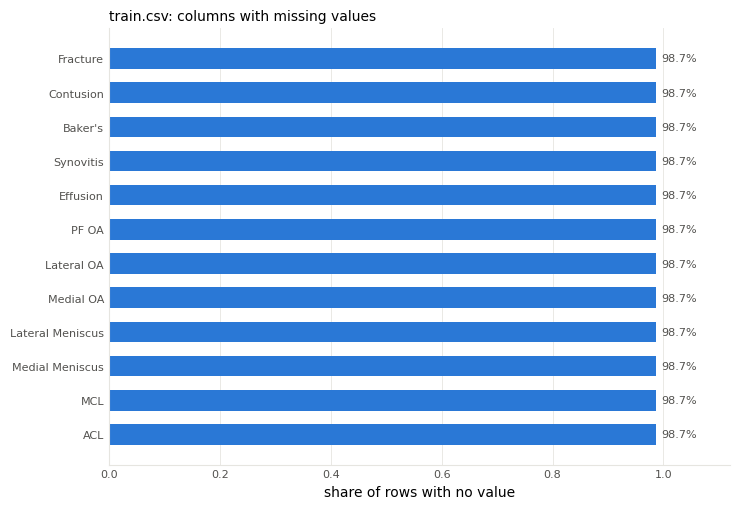

train.csv: 4,407 studies | officially labelled on all 12 findings: 58 | partially labelled: 0 | no official label: 4,349


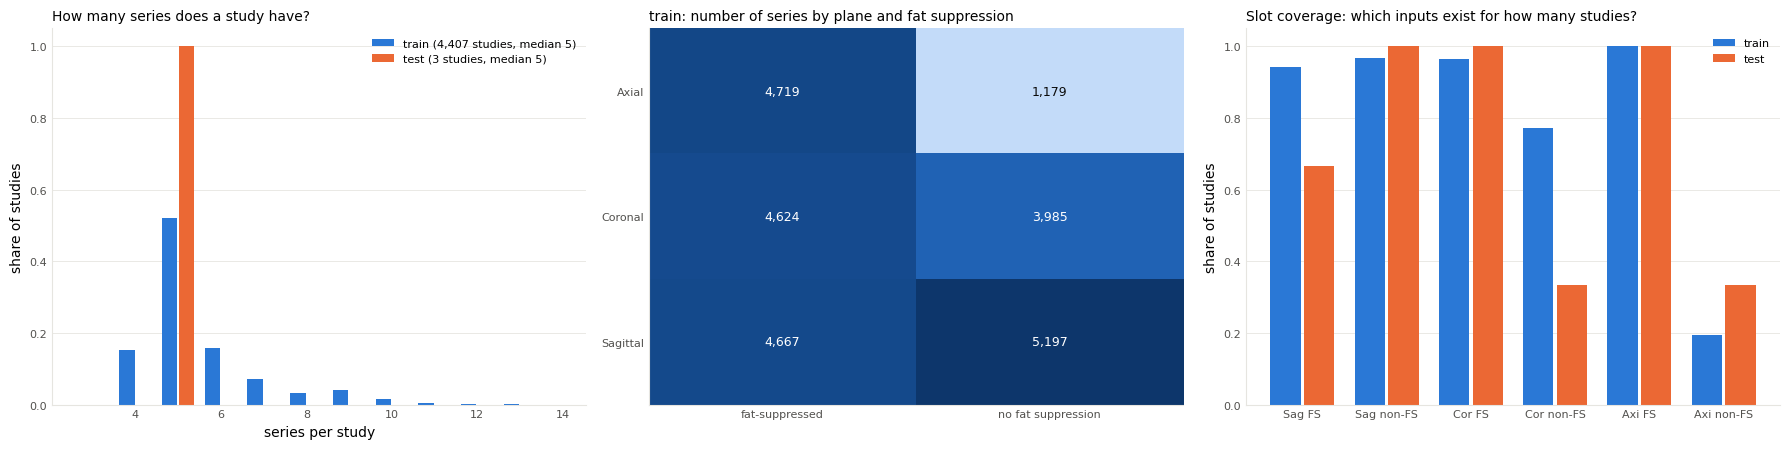

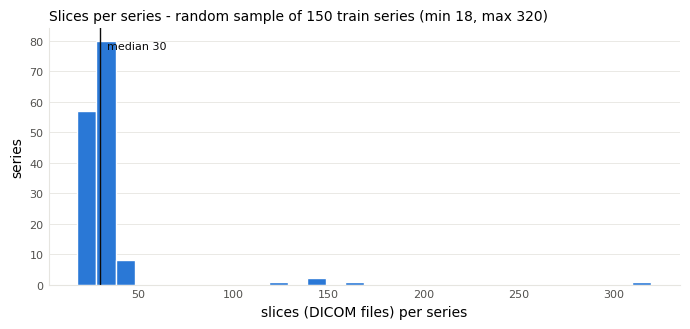

In [2]:
# ======================= Part A.2 - what is in the competition data? =======================
AX_tables = {}     # name -> DataFrame, reused by later analysis cells (kept in memory only)


def AX_data_overview():
    top = sorted(p.name for p in AX_COMP.iterdir())          # top level only: the tree holds ~820k DICOM files
    print("top-level entries:", top)
    rows = []
    for name in ("train.csv", "train_series.csv", "test.csv", "test_series.csv", "sample_submission.csv"):
        f = AX_COMP / name
        if not f.is_file():
            rows.append({"file": name, "rows": "missing"})
            continue
        d = AX_pd.read_csv(f, dtype={AX_UID: str, "SeriesInstanceUID": str})
        AX_tables[name] = d
        text_cols = [c for c in d.columns if AX_is_text(d[c]) and d[c].dropna().astype(str).str.len().mean() > 150]
        rows.append({"file": name, "rows": len(d), "columns": d.shape[1],
                     "studies": d[AX_UID].nunique() if AX_UID in d else None,
                     "column names": ", ".join(c if c not in text_cols else f"{c} (free text)" for c in d.columns)[:160]})
    AX_show(AX_pd.DataFrame(rows), "Tables in the competition directory")
    for split in ("train_series", "test_series"):
        p = AX_COMP / split
        if p.is_dir():
            print(f"{split}/: {sum(1 for _ in os.scandir(p)):,} study folders")


def AX_missing_values():
    """Fraction of empty cells per column. In train.csv most label cells are empty BY DESIGN:
    only a small set of studies has official labels, the rest only have a report."""
    use = []
    for n in ("train.csv", "train_series.csv", "test.csv", "test_series.csv"):
        if n in AX_tables:
            miss = AX_tables[n].isna().mean()
            if (miss > 0).any():
                use.append((n, miss[miss > 0].sort_values()))
            else:
                print(f"{n}: no missing values in any of its {AX_tables[n].shape[1]} columns")
    if use:
        fig, axes = AX_plt.subplots(1, len(use), figsize=(7.5 * len(use), 0.3 * max(len(m) for _, m in use) + 1.6), squeeze=False)
        for ax, (name, miss) in zip(axes[0], use):
            ax.barh(miss.index.astype(str), miss.values, color=AX_C["blue"], height=0.6)
            for y, v in enumerate(miss.values):
                ax.text(v + 0.01, y, f"{v:.1%}", va="center", fontsize=8, color=AX_C["muted"])
            ax.set_xlim(0, 1.12); ax.set_xlabel("share of rows with no value")
            ax.set_title(f"{name}: columns with missing values", fontsize=10, loc="left")
            AX_style(ax)
        AX_plt.tight_layout(); AX_plt.show()
    if "train.csv" in AX_tables:
        d = AX_tables["train.csv"]
        lab = [c for c in d.columns if AX_norm(c) in AX_NLAB]
        if lab:
            n_all = int(d[lab].notna().all(axis=1).sum()); n_any = int(d[lab].notna().any(axis=1).sum())
            print(f"train.csv: {len(d):,} studies | officially labelled on all {len(lab)} findings: {n_all} "
                  f"| partially labelled: {n_any - n_all} | no official label: {len(d) - n_any:,}")


def AX_series_statistics():
    """How studies are built from series: this decides which model 'slots' can be filled."""
    have = {k: AX_tables[f"{k}_series.csv"] for k in ("train", "test") if f"{k}_series.csv" in AX_tables}
    if not have:
        print("no series tables loaded"); return
    need = {"Anatomical_Plane", "Fat_Suppression"}
    fig, axes = AX_plt.subplots(1, 3, figsize=(18, 4.6))
    # (1) series per study
    ax = axes[0]
    width = 0.8 / len(have)
    for k, ((split, d), color) in enumerate(zip(have.items(), (AX_C["blue"], AX_C["orange"]))):
        per = d.groupby(AX_UID).size()
        share = per.value_counts(normalize=True).sort_index()
        ax.bar(share.index + k * width - 0.4 + width / 2, share.values, width=width * 0.9, color=color,
               label=f"{split} ({len(per):,} studies, median {per.median():.0f})")
    ax.xaxis.get_major_locator().set_params(integer=True)
    ax.set_xlabel("series per study"); ax.set_ylabel("share of studies")
    ax.set_title("How many series does a study have?", fontsize=10, loc="left"); ax.legend(frameon=False, fontsize=8)
    AX_style(ax, "y")
    # (2) plane x fat-suppression counts (train if present)
    split, d = next(iter(have.items()))
    ax = axes[1]
    if need.issubset(d.columns):
        tab = AX_pd.crosstab(d["Anatomical_Plane"].fillna("missing"), d["Fat_Suppression"].fillna(-1).map(
            {0: "no fat suppression", 1: "fat-suppressed", -1: "flag missing"}))
        im = ax.imshow(tab.to_numpy(), cmap=AX_SEQ, vmin=0, aspect="auto")
        ax.set_xticks(range(tab.shape[1]), tab.columns, fontsize=8); ax.set_yticks(range(tab.shape[0]), tab.index, fontsize=8)
        for i in range(tab.shape[0]):
            for j in range(tab.shape[1]):
                v = tab.iat[i, j]
                ax.text(j, i, f"{v:,}", ha="center", va="center", fontsize=9,
                        color="white" if v > tab.to_numpy().max() * 0.55 else AX_C["ink"])
        ax.set_title(f"{split}: number of series by plane and fat suppression", fontsize=10, loc="left")
        AX_style(ax, None)
    else:
        ax.axis("off"); ax.text(0.5, 0.5, "plane / fat-suppression columns not found", ha="center")
    # (3) slot coverage: share of studies owning at least one series of each (plane, fat-sat) kind
    ax = axes[2]
    slots = [(p, f) for p in ("Sagittal", "Coronal", "Axial") for f in (1, 0)]
    names = [f"{p[:3]} {'FS' if f else 'non-FS'}" for p, f in slots]
    width = 0.8 / len(have)
    for k, ((split, d), color) in enumerate(zip(have.items(), (AX_C["blue"], AX_C["orange"]))):
        if not need.issubset(d.columns):
            continue
        n = d[AX_UID].nunique()
        cov = [d[(d.Anatomical_Plane == p) & (d.Fat_Suppression == f)][AX_UID].nunique() / max(n, 1) for p, f in slots]
        ax.bar(AX_np.arange(len(slots)) + k * width - 0.4 + width / 2, cov, width=width * 0.9, color=color, label=split)
    ax.set_xticks(range(len(slots)), names, fontsize=8); ax.set_ylim(0, 1.05); ax.set_ylabel("share of studies")
    ax.set_title("Slot coverage: which inputs exist for how many studies?", fontsize=10, loc="left")
    ax.legend(frameon=False, fontsize=8); AX_style(ax, "y")
    AX_plt.tight_layout(); AX_plt.show()


def AX_slices_per_series(max_series=150, seed=0):
    """Count DICOM files in a random sample of series folders (a full scan of ~820k files is not needed)."""
    split = "train" if (AX_COMP / "train_series").is_dir() and "train_series.csv" in AX_tables else "test"
    d = AX_tables.get(f"{split}_series.csv")
    if d is None or "SeriesInstanceUID" not in d:
        print("series table not available"); return
    sample = d.sample(min(max_series, len(d)), random_state=seed)
    counts = []
    for r in sample.itertuples(index=False):
        p = AX_COMP / f"{split}_series" / str(getattr(r, AX_UID)) / str(r.SeriesInstanceUID)
        if p.is_dir():
            counts.append(sum(1 for e in os.scandir(p) if e.name.endswith(".dcm")))
    if not counts:
        print("no series folders readable for the slice count"); return
    c = AX_np.asarray(counts)
    fig, ax = AX_plt.subplots(figsize=(7, 3.4))
    ax.hist(c, bins=min(30, max(5, len(set(counts)))), color=AX_C["blue"], edgecolor="white", linewidth=1)
    ax.axvline(AX_np.median(c), color=AX_C["ink"], lw=1)
    ax.text(AX_np.median(c), ax.get_ylim()[1] * 0.95, f"  median {AX_np.median(c):.0f}", fontsize=8, color=AX_C["ink"], va="top")
    ax.set_xlabel("slices (DICOM files) per series"); ax.set_ylabel("series")
    ax.set_title(f"Slices per series - random sample of {len(c)} {split} series (min {c.min()}, max {c.max()})", fontsize=10, loc="left")
    AX_style(ax, "y"); AX_plt.tight_layout(); AX_plt.show()


with AX_cell("A.2 data overview"):
    AX_data_overview()
with AX_cell("A.2 missing values"):
    AX_missing_values()
with AX_cell("A.2 series statistics"):
    AX_series_statistics()
with AX_cell("A.2 slices per series"):
    AX_slices_per_series()

# Part B — Radiology-report text preprocessing

**What.** Finds the report column, normalises the text, guesses script and language, measures length, and sets simple English keyword flags.

**Why.** The reports are the only supervision for 4,349 of the 4,407 training studies. Before a language model can turn them into labels they have to be clean and their language mix understood. This notebook does *not* run a language model: the labels were produced upstream (Part C). The preprocessing here documents the input those labels came from and yields a crude, independent signal (keywords) to cross-check them.

**How.**
1. `AX_clean`: Unicode NFKC normalisation (full-width characters, ligatures and non-breaking spaces become ordinary characters) and whitespace collapse. Nothing is translated or removed.
2. `AX_script`: counts characters per Unicode block to find the writing system.
3. `AX_lang`: for Latin-script text, counts common function words per language. This is a rough guess, good enough for a bar chart.
4. Keyword flags: regular expressions for English terms only.

**Effect on predictions.** None. This part is descriptive.

**Fixed here.** A missing report used to be converted to the string `"nan"` and counted as a three-letter Latin report. Missing reports are now empty and excluded from the language and length statistics.

*Real report text is never printed (`AX_SHOW_REPORT_TEXT = False`). The before/after table uses invented sentences.*

raw (invented example),after AX_clean,script,language guess,English keyword flags
'MRI of the right knee.\n\nComplete tear of the ACL .\xa0Moderate joi,MRI of the right knee. Complete tear of the ACL . Moderate joint effus,Latin,en,"ACL, Effusion"
'ＭＲＩ：膝関節。前十字靭帯の断裂を認める。',MRI:膝関節。前十字靭帯の断裂を認める。,CJK,CJK,-
'RM de rodilla izquierda. Se observa rotura del menisco medial sin der,RM de rodilla izquierda. Se observa rotura del menisco medial sin derr,Latin,es,-
'MRT des Kniegelenks. Es zeigt sich ein Erguss und eine Baker-Zyste oh,MRT des Kniegelenks. Es zeigt sich ein Erguss und eine Baker-Zyste ohn,Latin,de,Baker's
"'МРТ коленного сустава: выпот, разрыв мениска.'","МРТ коленного сустава: выпот, разрыв мениска.",Cyrillic,Cyrillic,-
None,,-,-,-


Note the last three rows: the keyword flags only fire on English text, and the keyword 'fracture' would fire on 'No fracture' too.
That is why keywords are used only as a rough cross-check, never as labels.
report table: train.csv, text column 'Report' | studies: 4,407 | with a report: 4,407 | without: 0
cleaning changed 76.7% of reports; median characters removed (extra whitespace): 1


col_0,no official labels,official labels
has_report,,
has report,4349,58


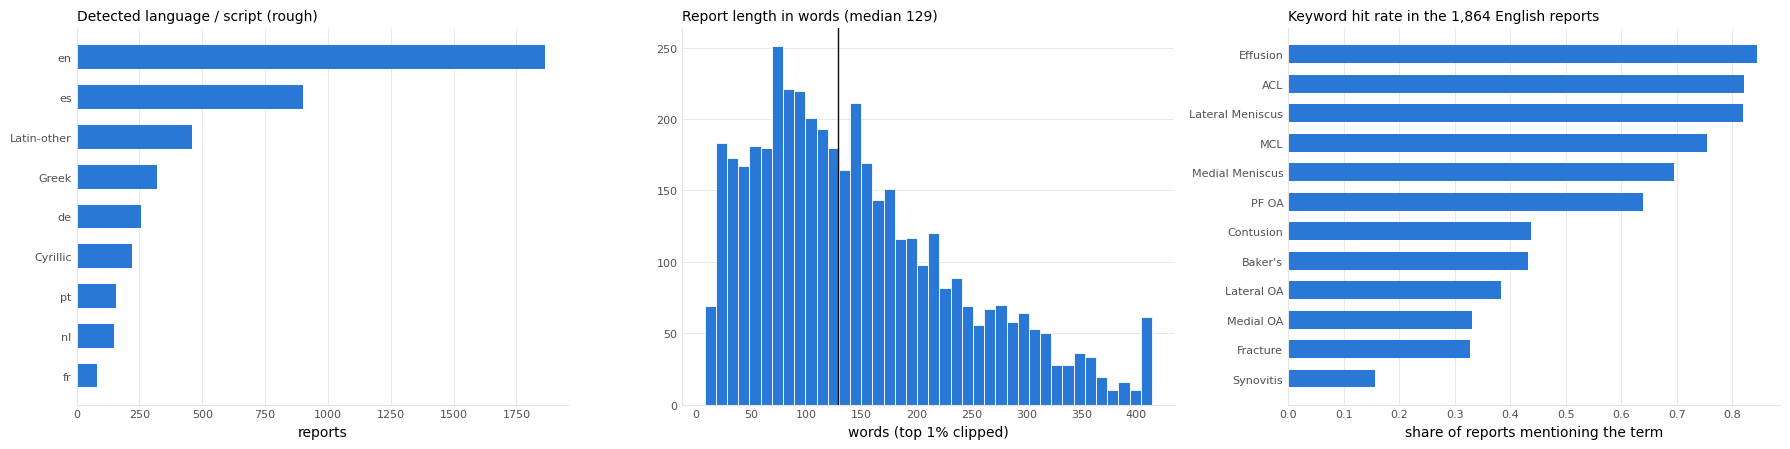

In [3]:
# ======================= Part B - radiology-report text preprocessing =======================
AX_reports = None


def AX_find_reports():
    """Locate the table that holds the free-text reports (longest average text column next to a study id)."""
    cands = [AX_Path(AX_REPORT_FILE)] if AX_REPORT_FILE else sorted(AX_COMP.glob("*.csv"))
    best = None
    for f in cands:
        try:
            d = AX_tables[f.name] if f.name in AX_tables and not AX_REPORT_FILE else AX_pd.read_csv(f)
        except Exception:
            continue
        uid = next((c for c in d.columns if "uid" in c.lower() or AX_norm(c) in ("studyid",)), None)
        txt = [c for c in d.columns if AX_is_text(d[c]) and c != uid]
        if uid is None or not txt:
            continue
        tcol = max(txt, key=lambda c: d[c].dropna().astype(str).str.len().mean() if d[c].notna().any() else 0)
        score = d[tcol].dropna().astype(str).str.len().mean() if d[tcol].notna().any() else 0
        if score > 150 and (best is None or score > best[0]):
            best = (score, f, uid, tcol, d)
    return best


def AX_clean(t):
    """NFKC unicode normalisation (full-width digits, ligatures, odd spaces -> plain forms) + whitespace collapse.
    Nothing is deleted or translated: the text stays readable for any later labelling step."""
    if t is None or (isinstance(t, float) and AX_np.isnan(t)):
        return ""                      # FIX: a missing report used to become the 3-letter string "nan"
    t = unicodedata.normalize("NFKC", str(t))
    return re.sub(r"\s+", " ", t).strip()


def AX_script(t):
    """Dominant writing system among the first 1,500 characters."""
    c = {"Latin": 0, "Cyrillic": 0, "CJK": 0, "Arabic": 0, "Hangul": 0, "Greek": 0, "Hebrew": 0, "Thai": 0, "Devanagari": 0}
    for ch in t[:1500]:
        o = ord(ch)
        if 0x41 <= o <= 0x24F: c["Latin"] += 1
        elif 0x400 <= o <= 0x4FF: c["Cyrillic"] += 1
        elif 0x4E00 <= o <= 0x9FFF or 0x3040 <= o <= 0x30FF: c["CJK"] += 1
        elif 0x600 <= o <= 0x6FF: c["Arabic"] += 1
        elif 0xAC00 <= o <= 0xD7AF: c["Hangul"] += 1
        elif 0x370 <= o <= 0x3FF: c["Greek"] += 1
        elif 0x590 <= o <= 0x5FF: c["Hebrew"] += 1
        elif 0xE00 <= o <= 0xE7F: c["Thai"] += 1
        elif 0x900 <= o <= 0x97F: c["Devanagari"] += 1
    return max(c, key=c.get) if sum(c.values()) else "Unknown"


AX_STOP = {
    "en": {"the", "and", "of", "with", "is", "no", "there", "are", "without", "normal", "seen"},
    "es": {"el", "la", "de", "con", "sin", "y", "en", "los", "las", "se", "del"},
    "fr": {"le", "la", "les", "de", "du", "et", "avec", "sans", "des", "une", "est"},
    "de": {"der", "die", "das", "und", "mit", "ohne", "keine", "ein", "eine", "im", "zeigt"},
    "pt": {"o", "a", "os", "as", "de", "com", "sem", "e", "uma", "um", "do", "da"},
    "it": {"il", "lo", "gli", "di", "con", "senza", "e", "una", "un", "del", "della"},
    "nl": {"de", "het", "een", "en", "met", "zonder", "geen", "van", "is", "er"},
}


def AX_lang(t, script):
    """Very rough language guess for Latin-script text by counting common function words."""
    if script != "Latin":
        return script
    w = re.findall(r"[a-zà-ÿ]+", t.lower())[:300]
    sc = {k: sum(x in v for x in w) for k, v in AX_STOP.items()}
    k = max(sc, key=sc.get)
    return k if sc[k] >= 3 else "Latin-other"


AX_KW = {  # English-only rough flags: an independent, deliberately simple signal
    "ACL": r"\bacl\b|anterior cruciate", "MCL": r"\bmcl\b|medial collateral",
    "Medial Meniscus": r"medial menisc", "Lateral Meniscus": r"lateral menisc",
    "Effusion": r"effusion", "Baker's": r"baker", "Fracture": r"fracture",
    "Contusion": r"contusion|bone bruis|marrow edema", "Synovitis": r"synovitis",
    "Medial OA": r"medial.{0,40}(osteoarth|cartilage)", "Lateral OA": r"lateral.{0,40}(osteoarth|cartilage)",
    "PF OA": r"patellofemoral|retropatellar|trochlea"}


def AX_report_demo():
    """Before/after on INVENTED sentences (not competition data), so the steps can be shown in public output."""
    demo = [
        "MRI  of the right knee.\n\nComplete tear of the ACL . Moderate joint effusion.",
        "ＭＲＩ：膝関節。前十字靭帯の断裂を認める。",                       # full-width Latin letters + Japanese
        "RM de rodilla izquierda. Se observa rotura del menisco medial sin derrame.",
        "MRT des Kniegelenks. Es zeigt sich ein Erguss und eine Baker-Zyste ohne Fraktur.",
        "МРТ коленного сустава: выпот, разрыв мениска.",
        None,
    ]
    rows = []
    for raw in demo:
        clean = AX_clean(raw); script = AX_script(clean) if clean else "-"
        hits = [k for k, rx in AX_KW.items() if re.search(rx, clean.lower())]
        rows.append({"raw (invented example)": repr(raw)[:70], "after AX_clean": clean[:70],
                     "script": script, "language guess": AX_lang(clean, script) if clean else "-",
                     "English keyword flags": ", ".join(hits) or "-"})
    AX_show(AX_pd.DataFrame(rows), "Report preprocessing on invented examples: each step made visible")
    print("Note the last three rows: the keyword flags only fire on English text, and the keyword 'fracture' "
          "would fire on 'No fracture' too.\nThat is why keywords are used only as a rough cross-check, never as labels.")


def AX_process_reports():
    global AX_reports
    found = AX_find_reports()
    if found is None:
        print("No report table detected under the competition dir. Set REPORT_FILE to enable this analysis.")
        return
    _, rf, uid_col, text_col, d = found
    d = d.rename(columns={uid_col: AX_UID}).copy(); d[AX_UID] = d[AX_UID].astype(str)
    d["has_report"] = d[text_col].notna() & (d[text_col].astype(str).str.strip() != "")
    d["report_clean"] = d[text_col].map(AX_clean)
    raw_len = d[text_col].fillna("").astype(str).str.len()
    d["script"] = d["report_clean"].map(AX_script)
    d["lang"] = [AX_lang(t, s) if h else "no report" for t, s, h in zip(d["report_clean"], d["script"], d["has_report"])]
    d["n_chars"] = d["report_clean"].str.len(); d["n_words"] = d["report_clean"].str.split().str.len()
    low = d["report_clean"].str.lower()
    for k, rx in AX_KW.items():
        d["kw_" + k] = low.str.contains(rx, regex=True).astype(int)
    AX_reports = d   # NOTE: held in memory only, never written to disk (competition data must not be redistributed)
    r = d[d.has_report]
    changed = (r["report_clean"] != r[text_col].astype(str)).mean() if len(r) else float("nan")
    removed = (raw_len[d.has_report] - r["n_chars"]).clip(lower=0)
    print(f"report table: {rf.name}, text column '{text_col}' | studies: {len(d):,} | with a report: {len(r):,} "
          f"| without: {len(d) - len(r):,}")
    print(f"cleaning changed {changed:.1%} of reports; median characters removed (extra whitespace): {removed.median():.0f}")
    lab = [c for c in d.columns if AX_norm(c) in AX_NLAB]
    if lab:
        has_lab = d[lab].notna().all(axis=1)
        AX_show(AX_pd.crosstab(d.has_report.map({True: "has report", False: "no report"}),
                               has_lab.map({True: "official labels", False: "no official labels"})),
                "Which supervision exists for which training study?")
    fig, ax = AX_plt.subplots(1, 3, figsize=(18, 4.6))
    vc = r["lang"].value_counts().head(12)
    ax[0].barh(vc.index[::-1], vc.values[::-1], color=AX_C["blue"], height=0.6)
    ax[0].set_title("Detected language / script (rough)", fontsize=10, loc="left"); ax[0].set_xlabel("reports")
    ax[1].hist(r["n_words"].clip(upper=r["n_words"].quantile(.99)), bins=40, color=AX_C["blue"], edgecolor="white", linewidth=0.6)
    ax[1].axvline(r["n_words"].median(), color=AX_C["ink"], lw=1)
    ax[1].set_title(f"Report length in words (median {r['n_words'].median():.0f})", fontsize=10, loc="left"); ax[1].set_xlabel("words (top 1% clipped)")
    en = r[r.lang == "en"]
    kwm = en[[c for c in d.columns if c.startswith("kw_")]].mean().sort_values(); kwm.index = [i[3:] for i in kwm.index]
    ax[2].barh(kwm.index, kwm.values, color=AX_C["blue"], height=0.6)
    ax[2].set_title(f"Keyword hit rate in the {len(en):,} English reports", fontsize=10, loc="left"); ax[2].set_xlabel("share of reports mentioning the term")
    AX_style(ax[0]); AX_style(ax[1], "y"); AX_style(ax[2])
    AX_plt.tight_layout(); AX_plt.show()
    if AX_SHOW_REPORT_TEXT and len(r):   # off by default - see the data-handling note at the top
        for t_raw, t_clean in zip(r[text_col].head(2), r["report_clean"].head(2)):
            print("RAW  :", repr(str(t_raw)[:200])); print("CLEAN:", t_clean[:200]); print()


with AX_cell("B report demo"):
    AX_report_demo()
with AX_cell("B report preprocessing"):
    AX_process_reports()

# Part C — LLM pseudo-labels: description and quality audit

**What.** Loads the attached label file (`rsna-knee-llm-labels`), describes it, and compares it with the official labels on the studies that have both.

**Why.** A model can only be as good as its training labels. These labels were written by a language model reading reports, so they inherit three kinds of error: the report may not mention a finding that is visible, the language model may misread the report (negation, another language), and a "soft" score may be undecided. The pipeline's networks were trained by their authors on report-derived labels of this kind (which exact file each author used is not recorded here). Knowing how noisy each finding is tells you where to expect weak predictions.

**How to read the audit.**
- *ROC-AUC against official labels*: 1.0 means the LLM score ranks every officially positive study above every negative one; 0.5 is chance. Intervals come from resampling the studies (bootstrap).
- *Sensitivity / specificity / kappa* use the 0.5 threshold. Kappa corrects agreement for chance.
- The right-hand chart compares class frequencies. If the LLM labels call a finding positive much more often than the official labels do, the pseudo-labels are systematically shifted.

**Three cautions.**
1. With 58 studies and sometimes fewer than ten positives, the intervals are wide. Treat single-finding numbers as rough.
2. This is a check of **label quality**. It says nothing about how accurate any image model is.
3. The reverse also holds: a model that agrees well with pseudo-labels has learned the pseudo-labels, including their mistakes. Model accuracy is only ever measured against official labels (Part F).

**Effect on predictions.** None. The label file is read for analysis only.

LLM-label dataset files: ['report_labels_v2.csv']
  report_labels_v2.csv: wide (12/12)
using report_labels_v2.csv: 4,406 studies x 12 findings | soft scores in [0, 1] | missing cells 0


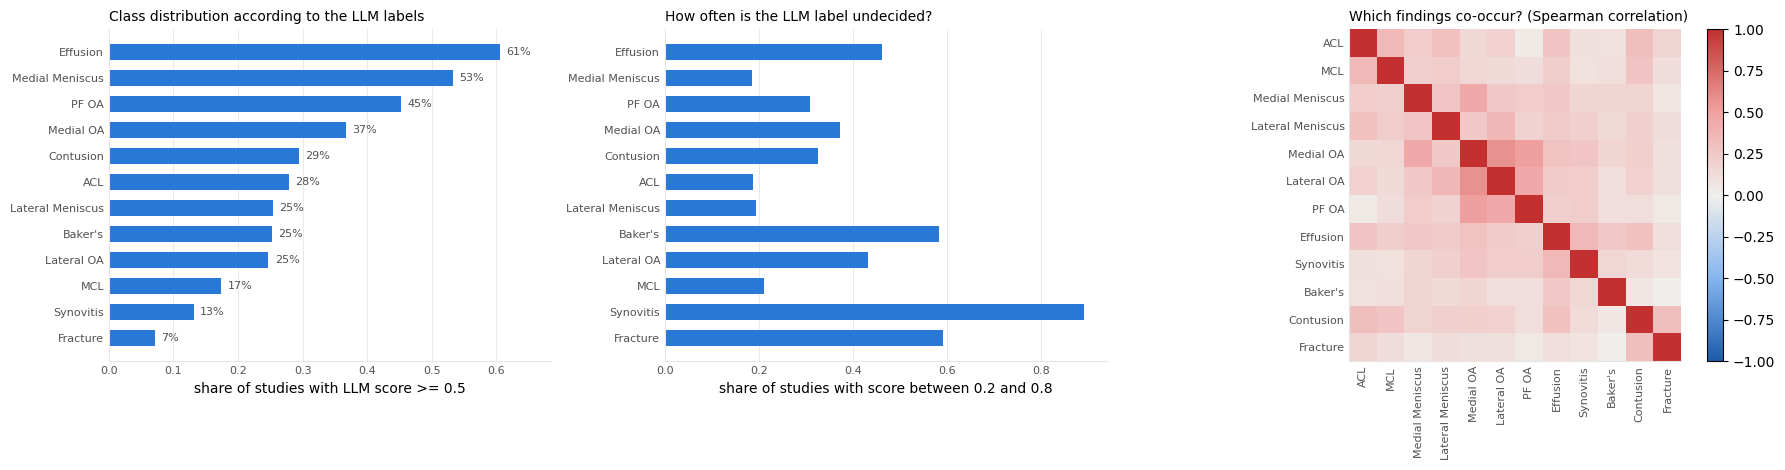

coverage: 4,406 of 4,407 training studies have an LLM label; 0 LLM rows match no training study
official labels: train.csv, 58 labelled studies | with an LLM label too: 57 | fully usable: 57


,n,positives,gold prevalence,LLM prevalence (>=0.5),auc,auc 95% low,auc 95% high,sensitivity,specificity,agreement,kappa
finding,,,,,,,,,,,
ACL,57,23,0.404,0.561,0.997,0.990,1.000,1.000,0.735,0.842,0.692
MCL,57,9,0.158,0.316,0.976,0.945,1.000,1.000,0.812,0.842,0.578
Medial Meniscus,57,26,0.456,0.561,0.943,0.875,0.991,0.962,0.774,0.860,0.722
Lateral Meniscus,57,23,0.404,0.526,0.841,0.722,0.931,0.870,0.706,0.772,0.548
Medial OA,57,15,0.263,0.386,0.908,0.796,0.986,0.933,0.810,0.842,0.646
Lateral OA,57,11,0.193,0.281,0.789,0.584,0.946,0.818,0.848,0.842,0.568
PF OA,57,20,0.351,0.421,0.891,0.787,0.965,0.800,0.784,0.789,0.558
Effusion,57,34,0.596,0.877,0.830,0.733,0.909,1.000,0.304,0.719,0.343
Synovitis,57,27,0.474,0.281,0.694,0.586,0.800,0.481,0.900,0.702,0.389


macro AUC of the LLM labels against official labels: 0.870 (95% bootstrap interval 0.831 - 0.900, n = 57 studies)


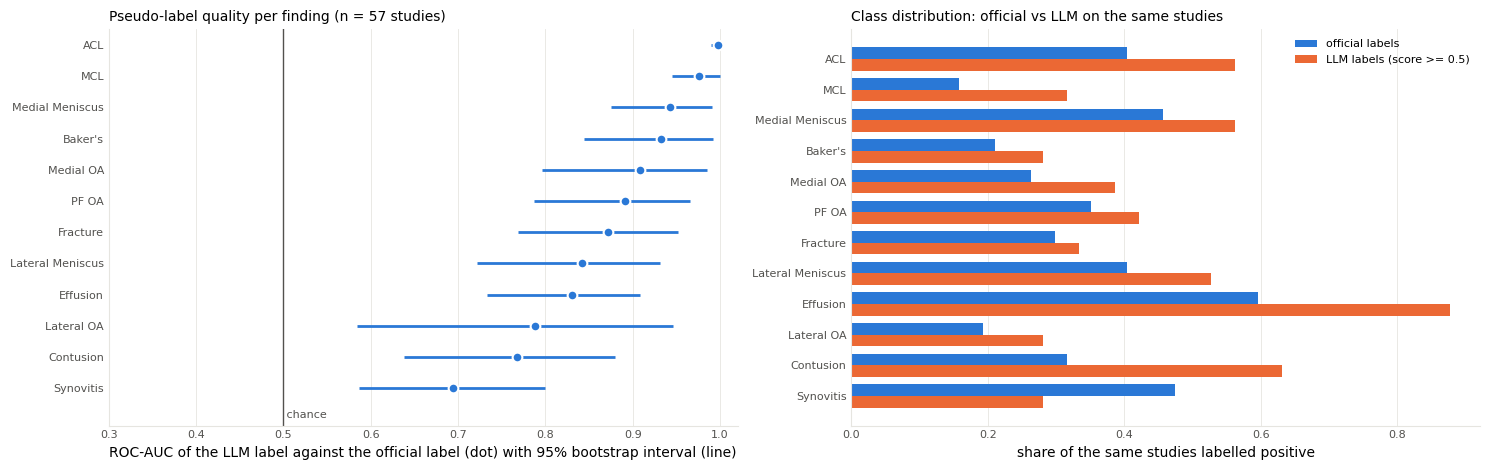

English reports with LLM labels: 1,863


,agreement_auc,n,keyword_rate
finding,,,
ACL,0.566,1863,0.820
MCL,0.538,1863,0.755
Medial Meniscus,0.752,1863,0.695
Lateral Meniscus,0.545,1863,0.819
Medial OA,0.544,1863,0.331
Lateral OA,0.446,1863,0.384
PF OA,0.540,1863,0.639
Effusion,0.571,1863,0.843
Synovitis,0.940,1863,0.156


In [4]:
# ======================= Part C - LLM pseudo-labels: load, describe, and audit against official labels =======================
AX_llm = None; AX_llm_corr = None; AX_gold = None; AX_gold_auc = None; AX_gold_macro_ci = None


def AX_to_wide(df):
    """Bring any label table into the shape [study x finding], whatever the column spelling is."""
    cols = {AX_norm(c): c for c in df.columns}
    uid_col = next((cols[k] for k in cols if k in ("studyinstanceuid", "studyuid", "uid", "studyid")), None) \
        or next((c for c in df.columns if "uid" in c.lower() or "study" in c.lower()), None)
    if uid_col is None:
        return None, "no study-id column"
    m = {}
    for c in df.columns:
        if c == uid_col:
            continue
        n = AX_norm(c)
        hit = [k for k in AX_NLAB if n == k] or [k for k in sorted(AX_NLAB, key=len, reverse=True) if k in n]
        if hit and AX_NLAB[hit[0]] not in m and AX_pd.api.types.is_numeric_dtype(df[c]):
            m[AX_NLAB[hit[0]]] = c
    if len(m) >= 6:
        w = df[[uid_col] + list(m.values())].rename(columns={uid_col: AX_UID, **{v: k for k, v in m.items()}})
        w[AX_UID] = w[AX_UID].astype(str)
        return w.drop_duplicates(AX_UID).set_index(AX_UID), f"wide ({len(m)}/12)"
    fcol = next((c for c in df.columns if AX_norm(c) in ("finding", "label", "target", "abnormality", "name")), None)
    vcol = next((c for c in df.columns if AX_norm(c) in ("value", "score", "prob", "probability", "pred", "prediction", "llmlabel", "y")), None)
    if fcol and vcol:
        t = df[[uid_col, fcol, vcol]].copy(); t[fcol] = t[fcol].map(lambda s: AX_NLAB.get(AX_norm(s)))
        t = t.dropna(subset=[fcol]); t[uid_col] = t[uid_col].astype(str)
        return t.pivot_table(index=uid_col, columns=fcol, values=vcol, aggfunc="mean").rename_axis(AX_UID), "long->wide"
    return None, "could not map columns"


def AX_read(f):
    return AX_pd.read_parquet(f) if f.suffix == ".parquet" else (AX_pd.read_json(f, lines=True) if f.suffix == ".jsonl" else AX_pd.read_csv(f))


def AX_find_gold():
    """Official ('gold') labels = the training studies whose 12 label cells are filled with 0/1.

    Only files from the competition's TRAINING side are considered: a sample submission full of zeros
    would otherwise look like a label table.
    """
    files = [AX_Path(AX_GOLD_FILE)] if AX_GOLD_FILE else [
        f for f in sorted(AX_COMP.glob("*.csv")) if not f.name.lower().startswith(("test", "sample"))]
    best = None
    for f in files:
        try:
            w, _ = AX_to_wide(AX_pd.read_csv(f))
        except Exception:
            continue
        if w is None:
            continue
        w = w.dropna(how="all"); a = w.to_numpy(float)
        if len(w) >= 10 and AX_np.isin(AX_np.unique(a[~AX_np.isnan(a)]), [0, 1]).all():
            if best is None or w.shape[1] > best[0].shape[1]:
                best = (w[[c for c in AX_LAB if c in w.columns]], f)
    return best if best is not None else (None, None)


def AX_load_llm():
    global AX_llm, AX_llm_corr
    files = [AX_Path(AX_LLM_FILE)] if AX_LLM_FILE else sorted(AX_LLM.rglob("*.csv")) + sorted(AX_LLM.rglob("*.parquet")) + sorted(AX_LLM.rglob("*.jsonl"))
    print("LLM-label dataset files:", [f.name for f in files][:15])
    best = None
    for f in files:
        try:
            w, note = AX_to_wide(AX_read(f))
        except Exception as e:
            print("  skip", f.name, e); continue
        print(f"  {f.name}: {note}")
        if w is not None and (best is None or len(w) > len(best[0])):
            best = (w, f)
    if best is None:
        raise RuntimeError("could not parse LLM labels; set LLM_LABEL_FILE")
    AX_llm = best[0][[c for c in AX_LAB if c in best[0].columns]]
    vals = AX_llm.to_numpy(float); binary = AX_np.isin(AX_np.unique(vals[~AX_np.isnan(vals)]), [0, 1]).all()
    print(f"using {best[1].name}: {AX_llm.shape[0]:,} studies x {AX_llm.shape[1]} findings | "
          f"{'hard 0/1 labels' if binary else 'soft scores in [0, 1]'} | missing cells {int(AX_np.isnan(vals).sum())}")
    AX_llm_corr = AX_llm.corr(method="spearman")


def AX_llm_eda():
    """Class distribution, how 'decided' the soft labels are, and which findings co-occur."""
    if AX_llm is None:
        print("LLM labels not loaded"); return
    L = AX_llm
    pos = (L >= 0.5).mean().sort_values()                       # share of studies called positive
    unsure = ((L > 0.2) & (L < 0.8)).mean().reindex(pos.index)   # share of studies with an undecided score
    fig, ax = AX_plt.subplots(1, 3, figsize=(18, 4.8), gridspec_kw={"width_ratios": [1, 1, 1.15]})
    ax[0].barh(pos.index, pos.values, color=AX_C["blue"], height=0.6)
    for y, v in enumerate(pos.values):
        ax[0].text(v + 0.01, y, f"{v:.0%}", va="center", fontsize=8, color=AX_C["muted"])
    ax[0].set_xlim(0, max(0.6, pos.max() + 0.08)); ax[0].set_xlabel("share of studies with LLM score >= 0.5")
    ax[0].set_title("Class distribution according to the LLM labels", fontsize=10, loc="left"); AX_style(ax[0])
    ax[1].barh(unsure.index, unsure.values, color=AX_C["blue"], height=0.6)
    ax[1].set_xlim(0, max(0.2, float(unsure.max()) + 0.05)); ax[1].set_xlabel("share of studies with score between 0.2 and 0.8")
    ax[1].set_title("How often is the LLM label undecided?", fontsize=10, loc="left"); AX_style(ax[1])
    im = ax[2].imshow(AX_llm_corr, cmap=AX_DIV, vmin=-1, vmax=1)
    ax[2].set_xticks(range(len(AX_llm_corr)), AX_llm_corr.columns, rotation=90, fontsize=8)
    ax[2].set_yticks(range(len(AX_llm_corr)), AX_llm_corr.columns, fontsize=8)
    ax[2].set_title("Which findings co-occur? (Spearman correlation)", fontsize=10, loc="left"); AX_style(ax[2], None)
    fig.colorbar(im, ax=ax[2], fraction=.046)
    AX_plt.tight_layout(); AX_plt.show()
    if "train.csv" in AX_tables:
        train_ids = set(AX_tables["train.csv"][AX_UID].astype(str))
        print(f"coverage: {len(train_ids & set(L.index)):,} of {len(train_ids):,} training studies have an LLM label; "
              f"{len(set(L.index) - train_ids)} LLM rows match no training study")


def AX_llm_vs_gold(n_boot=2000, seed=0):
    """Pseudo-label QUALITY check: LLM labels vs the official labels of the same studies.
    This measures how noisy the training signal is. It is not a measure of any model's accuracy."""
    global AX_gold, AX_gold_auc, AX_gold_macro_ci
    gold, gf = AX_find_gold()
    if gold is None or AX_llm is None:
        print("official-label check skipped (labels not auto-detected; set GOLD_LABEL_FILE)"); return
    AX_gold = gold
    both = [u for u in gold.index if u in AX_llm.index]
    labs = [l for l in AX_LAB if l in gold.columns and l in AX_llm.columns]
    G = gold.loc[both, labs]; P = AX_llm.loc[both, labs]
    ok = (G.notna().all(axis=1) & P.notna().all(axis=1)).to_numpy()
    y = G.to_numpy(float)[ok]; s = P.to_numpy(float)[ok]; hard = (s >= 0.5).astype(float)
    print(f"official labels: {gf.name}, {len(gold)} labelled studies | with an LLM label too: {len(both)} | fully usable: {int(ok.sum())}")
    if ok.sum() < 10:
        print("too few overlapping studies for a meaningful comparison"); return
    auc = AX_auc_matrix(y, s)
    tp = (hard * y).sum(0); tn = ((1 - hard) * (1 - y)).sum(0); n1 = y.sum(0); n0 = len(y) - n1
    with AX_np.errstate(invalid="ignore", divide="ignore"):
        sens = tp / n1; spec = tn / n0; acc = (tp + tn) / len(y)
        pe = (n1 / len(y)) * hard.mean(0) + (n0 / len(y)) * (1 - hard.mean(0)); kappa = (acc - pe) / (1 - pe)
    rng = AX_np.random.default_rng(seed)                      # bootstrap: resample studies with replacement
    boot = AX_np.stack([AX_auc_matrix(y[i], s[i]) for i in rng.integers(0, len(y), (n_boot, len(y)))])
    lo, hi = AX_np.nanpercentile(boot, [2.5, 97.5], axis=0)
    macro = AX_np.nanmean(boot, axis=1); AX_gold_macro_ci = (float(AX_np.nanmean(auc)), *AX_np.percentile(macro, [2.5, 97.5]))
    AX_gold_auc = AX_pd.DataFrame({"n": len(y), "positives": n1.astype(int), "gold prevalence": n1 / len(y),
                                   "LLM prevalence (>=0.5)": hard.mean(0), "auc": auc, "auc 95% low": lo, "auc 95% high": hi,
                                   "sensitivity": sens, "specificity": spec, "agreement": acc, "kappa": kappa},
                                  index=AX_pd.Index(labs, name="finding"))
    AX_show(AX_gold_auc.round(3), "LLM labels vs official labels (threshold 0.5 for sensitivity / specificity / kappa)")
    print(f"macro AUC of the LLM labels against official labels: {AX_gold_macro_ci[0]:.3f} "
          f"(95% bootstrap interval {AX_gold_macro_ci[1]:.3f} - {AX_gold_macro_ci[2]:.3f}, n = {len(y)} studies)")
    few = [l for l, k in zip(labs, n1) if min(k, len(y) - k) < 8]
    if few:
        print(f"fewer than 8 positives or negatives -> very wide intervals for: {', '.join(few)}")
    order = AX_np.argsort(AX_np.nan_to_num(auc, nan=0))
    fig, ax = AX_plt.subplots(1, 2, figsize=(15, 4.8))
    yy = AX_np.arange(len(labs))
    ax[0].hlines(yy, lo[order], hi[order], color=AX_C["blue"], lw=2)
    ax[0].plot(auc[order], yy, "o", color=AX_C["blue"], ms=7, mec="white", mew=1.5)
    ax[0].axvline(0.5, color=AX_C["muted"], lw=1); ax[0].text(0.5, -0.85, " chance", fontsize=8, color=AX_C["muted"], va="center")
    ax[0].set_yticks(yy, [labs[i] for i in order], fontsize=8); ax[0].set_ylim(-1.2, len(labs) - 0.5)
    ax[0].set_xlim(min(0.3, float(AX_np.nanmin(lo)) - 0.03), 1.02)
    ax[0].set_xlabel("ROC-AUC of the LLM label against the official label (dot) with 95% bootstrap interval (line)")
    ax[0].set_title(f"Pseudo-label quality per finding (n = {len(y)} studies)", fontsize=10, loc="left"); AX_style(ax[0])
    w = 0.38
    ax[1].barh(yy + w / 2, (n1 / len(y))[order], height=w, color=AX_C["blue"], label="official labels")
    ax[1].barh(yy - w / 2, hard.mean(0)[order], height=w, color=AX_C["orange"], label="LLM labels (score >= 0.5)")
    ax[1].set_yticks(yy, [labs[i] for i in order], fontsize=8); ax[1].set_xlabel("share of the same studies labelled positive")
    ax[1].set_title("Class distribution: official vs LLM on the same studies", fontsize=10, loc="left")
    ax[1].legend(frameon=False, fontsize=8); AX_style(ax[1])
    AX_plt.tight_layout(); AX_plt.show()


def AX_llm_vs_keywords():
    """Second, weaker cross-check on English reports only: does the LLM score rise when the finding is mentioned?"""
    if AX_llm is None or AX_reports is None:
        print("keyword cross-check skipped (needs LLM labels and the report table)"); return
    en = AX_reports[AX_reports["lang"] == "en"].set_index(AX_UID); both = en.index.intersection(AX_llm.index); rows = []
    from sklearn.metrics import roc_auc_score
    for l in AX_LAB:
        c = "kw_" + l
        if c in en.columns and l in AX_llm.columns and len(both) > 30:
            y = en.loc[both, c]; p = AX_llm.loc[both, l]; ok = p.notna()
            if y[ok].nunique() == 2 and p[ok].nunique() > 1:
                rows.append((l, roc_auc_score(y[ok], p[ok]), int(ok.sum()), float(y[ok].mean())))
    if not rows:
        print("keyword cross-check skipped (not enough English reports with variation)"); return
    kw = AX_pd.DataFrame(rows, columns=["finding", "agreement_auc", "n", "keyword_rate"]).set_index("finding")
    print(f"English reports with LLM labels: {len(both):,}")
    AX_show(kw.round(3), "LLM label vs 'the report mentions the term' (agreement, not accuracy)")


with AX_cell("C load LLM labels"):
    AX_load_llm()
with AX_cell("C LLM-label EDA"):
    AX_llm_eda()
with AX_cell("C LLM vs official labels"):
    AX_llm_vs_gold()
with AX_cell("C LLM vs keywords"):
    AX_llm_vs_keywords()

# Part D — The model pipeline (inference only)

Everything from here to Part E is the original model code. Cells are unchanged unless a heading says **Fixed** or **New gate**.

## Training versus inference

| | Training (done elsewhere, by the checkpoint authors) | Inference (this notebook) |
|---|---|---|
| Input | training studies + pseudo-labels from reports | test studies, no labels |
| What changes | network weights, by gradient descent over many epochs, with augmentation and dropout | nothing: weights are loaded and frozen (`model.eval()`, `torch.no_grad()`) |
| Output | checkpoint files (`.pt`) | one score per study and finding |
| Folds | data split in 5 parts; each model trains on 4 and is checked on the 5th | all fold models predict every test study and are averaged |

Consequences you will see in the code:

- **Preprocessing must match training exactly.** A network trained on 130 mm crops at 336 px with a particular slice order gives worse answers on anything else. That is why crop size, slice band and ordering rules are read *from the checkpoint files* and why this notebook does not "improve" the preprocessing: changing it without retraining would lower accuracy.
- **Integrity checks.** Each checkpoint is identified by a SHA-256 hash or by a stored "fingerprint" (its output on a fixed random input). A mismatch stops the run instead of silently producing different predictions.
- **Leftover training settings.** Constants such as `EPOCHS`, `LR_HEAD` or `AUG_ROT_DEG` in the startup cell are remnants of the training script. Nothing at inference reads them.

The training code is not part of this notebook, so statements about how a checkpoint was trained are limited to what its files and the original notes record.

## D.1 Environment check

**What.** Prints Python, PyTorch and GPU details and lists the attached inputs. **Why.** The pipeline is tuned for two T4 GPUs and refuses to run otherwise; seeing the hardware first makes a later refusal understandable. **Effect on predictions.** None (read-only).

In [5]:
# Read-only environment and input check. Defines no state used by later cells.
import os
import platform
import sys
from pathlib import Path

import torch

print("python :", sys.version.split()[0], "|", platform.platform())
print("torch  :", torch.__version__, "| CUDA available:", torch.cuda.is_available())
for i in range(torch.cuda.device_count()):
    p = torch.cuda.get_device_properties(i)
    print(f"  cuda:{i} {p.name}  {p.total_memory / 2**30:.1f} GiB")
if torch.cuda.device_count() < 2:
    print("WARNING: pipeline is tuned for 2x T4; runtime will be longer with fewer GPUs.")

input_root = Path("/kaggle/input")
print("attached inputs:")
for d in sorted(input_root.iterdir()) if input_root.is_dir() else []:
    print("  -", d.name)


python : 3.13.15 | Linux-6.18.48+-x86_64-with-glibc2.39
torch  : 2.11.0+cu128 | CUDA available: True
  cuda:0 Tesla T4  14.6 GiB
  cuda:1 Tesla T4  14.6 GiB
attached inputs:
  - competitions
  - datasets
  - models
  - notebooks


## D.2 Runtime contract and checkpoint integrity

**What.** Helper functions that (a) verify hashes of the CoAtNet "D4" reader's files, batch sizes and library versions, (b) locate every attached weight file by name and hash, (c) run a required model in a child process with a time limit, and (d) patch the dense slice sampling into two external reader scripts.

**Why.** The pipeline combines files from more than a dozen datasets. If one of them were replaced by a different version, the notebook would still run and the predictions would silently change. Pinning hashes turns that into an immediate, readable error.

**How.** `_asset_find_asset(name, sha256)` walks only the listed dataset folders and demands exactly one match. `_d4_check_runtime` / `_d4_check_outputs` compare a long list of expected properties (model count, epochs, resolution, exact numeric round-trip of the written CSV).

**Effect on predictions.** None when everything matches; a hard stop otherwise.

In [6]:
import os

for _thread_env in ('OMP_NUM_THREADS', 'OPENBLAS_NUM_THREADS', 'MKL_NUM_THREADS'):
    os.environ.setdefault(_thread_env, '4')
os.environ.setdefault('CUDNN_CONV_WSCAP_DBG', '1024')


def _d4_check_runtime(rt, artifact_root):
    import hashlib
    import json
    from pathlib import Path
    import torch

    root = Path(artifact_root)
    manifest_path = root / 'coatnet_pairfilm_manifest.json'
    digest = hashlib.sha256(manifest_path.read_bytes()).hexdigest()
    if digest != '7ada0605bca6b0530569c6454e988ace479606a3328ed591d090e5764fea661d':
        raise RuntimeError('D4 reference manifest identity changed')
    expected = json.loads(manifest_path.read_text())
    manifest, paths = rt.validate_artifact_root(root, verify_hashes=True)
    if manifest != expected or len(paths) != 1 or rt.N_MODELS != 1:
        raise RuntimeError('D4 must load exactly the reference SWA model')
    if Path(paths[0]).name != 'coatnet_d4_parent_rank8_swa2.pt':
        raise RuntimeError('D4 must use its reference rank-8 parent checkpoint')
    if (
        manifest['slice_depth']['adapter_sha256']
        != 'b7c48b19997bc7ecb7e997f8dcf491ec5701ff917d1dac4b369eb85ac97ae89a'
    ):
        raise RuntimeError('D4 reference adapter identity changed')
    if rt.GPU_BATCH_STUDIES != 2 or rt.BACKBONE_MICRO_IMAGES != 8:
        raise RuntimeError('D4 reference batching changed')
    if rt.CUDNN_BENCHMARK is not False:
        raise RuntimeError('D4 reference convolution policy changed')
    if rt.base.cv2.__version__ != '4.12.0' or rt.parent.timm.__version__ != '1.0.22':
        raise RuntimeError('D4 reference dependency versions changed')
    if torch.cuda.device_count() != 2:
        raise RuntimeError('D4 requires exactly two T4 GPUs')
    names = [torch.cuda.get_device_name(i) for i in range(2)]
    if not all(('T4' in name for name in names)):
        raise RuntimeError(f'D4 reference device mismatch: {names}')
    return (manifest, paths)


def _d4_check_outputs(rt, manifest, receipt, output, competition):
    import hashlib
    from pathlib import Path
    import numpy as np
    import pandas as pd

    def need(condition, message):
        if not condition:
            raise RuntimeError('D4 release check: ' + message)

    need(receipt['status'] == rt.SUBMISSION_STATUS, 'unsuccessful status')
    expected_fields = {
        'models': 1,
        'fallback_studies': 0,
        'dicom_preparations_per_study': 1,
        'model_passes_per_study': 1,
        'rank_after_probability_average': True,
        'canonical_sagittal': True,
        'common_physical_triplet_warp': False,
        'resolution': 384,
        'slice_depth_arm': 'd4_zones',
        'slice_depth_state_elements': 3255,
        'slice_depth_parent_checkpoint_sha256': '5de38e333e3184d7b52fb068183f0cc198d6cbabb6ffbe36b26338622e82d297',
        'fsx_attention_heads': 2,
        'fsx_attention_width': 128,
        'fsx_serving_delta_cap': 0.3,
        'fsx_training_delta_cap': 0.5,
        'head': 'rank8_swa2_plus_d4_three_zone_expanded_fsx',
        'slice_depth_swa_member_epochs': [11, 9, 5],
        'slice_depth_checkpoint_sha256': manifest['slice_depth']['adapter_sha256'],
    }
    for key, value in expected_fields.items():
        need(receipt[key] == value, key)
    need(1 <= int(receipt['maximum_eval_windows']) <= 94, 'window limit')
    checkpoints = receipt['checkpoints']
    need(len(checkpoints) == 1, 'parent checkpoint count')
    need(
        checkpoints[0]['sha256']
        == '5de38e333e3184d7b52fb068183f0cc198d6cbabb6ffbe36b26338622e82d297',
        'parent checkpoint hash',
    )
    need(checkpoints[0]['member_epochs'] == [15, 16], 'parent SWA member epochs')
    need(
        receipt['slice_depth_checkpoint_sha256']
        == 'b7c48b19997bc7ecb7e997f8dcf491ec5701ff917d1dac4b369eb85ac97ae89a',
        'adapter checkpoint hash',
    )
    processes = receipt['processes']
    need(
        len(processes) == 2 and all((int(p['returncode']) == 0 for p in processes)),
        'worker process failure',
    )
    shards = receipt['shards']
    need(len(shards) == 2, 'shard count')
    for s in shards:
        need(s['device'] == 'cuda', 'non-CUDA shard')
        need(
            int(s['fallback_studies']) == 0 and int(s['preparation_warnings']) == 0,
            'failed study/preparation',
        )
        need(int(s['models_resident']) == 1, 'resident model count')
        need(int(s['peak_reserved_bytes']) < int(15.5 * 1024**3), 'reference memory gate')
        need(
            s['specialized_worker_loader_contract'] == manifest['worker_loader_contract'],
            'specialized loader',
        )
    output = Path(output)
    prediction_path = output.parent / rt.PREDICTIONS_NAME
    with np.load(prediction_path, allow_pickle=False) as payload:
        uids = payload['study_uids'].astype(str).tolist()
        raw = np.asarray(payload['raw_probabilities'], dtype=np.float32)
        mean = np.asarray(payload['probability_mean'], dtype=np.float32)
        ranked = np.asarray(payload['submission_percentile_rank'], dtype=np.float64)
    ids = pd.read_csv(
        Path(competition) / 'test.csv', dtype={'StudyInstanceUID': str}
    ).StudyInstanceUID.tolist()
    need(len(ids) > 0 and len(ids) == len(set(ids)), 'test identity')
    need(uids == ids and int(receipt['studies']) == len(ids), 'prediction identity/count')
    need(raw.shape == (1, len(ids), 12), 'raw probability shape')
    need(np.isfinite(raw).all() and ((raw >= 0) & (raw <= 1)).all(), 'raw probabilities')
    need(
        np.array_equal(raw.astype(np.float64).mean(0).astype(np.float32), mean), 'probability mean'
    )
    need(np.array_equal(rt.percentile_rank64(mean), ranked), 'global percentile ranks')
    frame = pd.read_csv(output, dtype={'StudyInstanceUID': str}, float_precision='round_trip')
    need(frame.columns.tolist() == ['StudyInstanceUID', *rt.base.LABELS], 'CSV labels')
    need(frame.StudyInstanceUID.tolist() == ids, 'CSV identity')
    need(np.array_equal(frame.iloc[:, 1:].to_numpy(np.float64), ranked), 'CSV numeric round trip')
    actual_hash = hashlib.sha256(output.read_bytes()).hexdigest()
    need(actual_hash == receipt['output_sha256'], 'CSV hash')
    receipt['reference_wrapper_checks'] = {
        'export_sha256': '7f8410fdf1b60cd3831d50f517bb25798a4e4a3404c59dc269193d5fe7cce729',
        'validated_manifest_sha256': '7ada0605bca6b0530569c6454e988ace479606a3328ed591d090e5764fea661d',
        'probability_mean_exact': True,
        'ranks_exact': True,
        'csv_roundtrip_exact': True,
        'source_and_model_hashes_validated': True,
        'input_identity_equals_original_grid': False,
    }
    return receipt


def _run_required_child(command, environment, logfile):
    import os
    import signal
    import subprocess
    import time
    from pathlib import Path

    remaining = TIME_BUDGET - (time.time() - T0)
    if remaining <= 0:
        raise TimeoutError('No time remains for a required model branch')
    path = Path(logfile)
    path.parent.mkdir(parents=True, exist_ok=True)
    with path.open('w') as log_handle:
        process = subprocess.Popen(
            command,
            env=environment,
            stdout=log_handle,
            stderr=subprocess.STDOUT,
            start_new_session=True,
        )
        try:
            returncode = process.wait(timeout=remaining)
        except BaseException:
            try:
                os.killpg(process.pid, signal.SIGTERM)
            except ProcessLookupError:
                pass
            try:
                process.wait(timeout=10)
            except subprocess.TimeoutExpired:
                try:
                    os.killpg(process.pid, signal.SIGKILL)
                except ProcessLookupError:
                    pass
                process.wait()
            raise
    if returncode != 0:
        with path.open('rb') as handle:
            handle.seek(max(0, path.stat().st_size - 5000))
            tail = handle.read().decode('utf-8', errors='replace')
        raise RuntimeError(f'Required model branch failed ({returncode}); {path}\n{tail}')
    return returncode


ASSET_ROOTS = [
    '/kaggle/input/datasets/dreaddevelopment/raptor-knee-maxspan',
    '/kaggle/input/raptor-knee-maxspan',
    '/kaggle/input/datasets/dreaddevelopment/raptor-knee-native384',
    '/kaggle/input/raptor-knee-native384',
    '/kaggle/input/datasets/dreaddevelopment/raptor-knee-native384dense',
    '/kaggle/input/raptor-knee-native384dense',
    '/kaggle/input/datasets/mattiaangeli/knee-mri-fold-weights',
    '/kaggle/input/knee-mri-fold-weights',
    '/kaggle/input/datasets/mattiaangeli/opencv-python-headless-4120088-x86',
    '/kaggle/input/opencv-python-headless-4120088-x86',
    '/kaggle/input/datasets/marwanmath/resnet-50-radimagenet-marwan',
    '/kaggle/input/resnet-50-radimagenet-marwan',
    '/kaggle/input/datasets/mattiaangeli/rsna-knee-coat-resgated-ep10-top3',
    '/kaggle/input/rsna-knee-coat-resgated-ep10-top3',
    '/kaggle/input/datasets/antoinegg1/rsna-knee-e11-diverse-heads-v20',
    '/kaggle/input/rsna-knee-e11-diverse-heads-v20',
    '/kaggle/input/datasets/antoinegg1/rsna-knee-e9-radimagenet-heads-v15',
    '/kaggle/input/rsna-knee-e9-radimagenet-heads-v15',
    '/kaggle/input/datasets/pilkwang/rsna-knee-llm-labels',
    '/kaggle/input/rsna-knee-llm-labels',
    '/kaggle/input/datasets/prvsiyan/rsna-knee-v52-radimagenet-heads-20260812',
    '/kaggle/input/rsna-knee-v52-radimagenet-heads-20260812',
    '/kaggle/input/datasets/pilkwang/rsna-knee-weights',
    '/kaggle/input/rsna-knee-weights',
    '/kaggle/input/datasets/mattiaangeli/rsna-knee-coatnet-d4-depthzone-swa3-b2',
    '/kaggle/input/rsna-knee-coatnet-d4-depthzone-swa3-b2',
    '/kaggle/input/datasets/mattiaangeli/rsna-knee-coatnet-global96-top3',
    '/kaggle/input/rsna-knee-coatnet-global96-top3',
    '/kaggle/input/notebooks/sofiaanjenje/rsna-knee-e11-train',
    '/kaggle/input/rsna-knee-e11-train',
    '/kaggle/input/notebooks/sofiaanjenje/rsna-knee-e13-train',
    '/kaggle/input/rsna-knee-e13-train',
    '/kaggle/input/models/metaresearch/dinov2/pytorch/small/1',
    '/kaggle/input/dinov2/pytorch/small/1',
]


def _asset_walk():
    from pathlib import Path

    seen = set()
    for root in ASSET_ROOTS:
        root = Path(root).resolve()
        if not root.is_dir():
            continue
        level = [root]
        for _depth in range(6):
            following = []
            for directory in sorted(level):
                if str(directory) in seen:
                    continue
                seen.add(str(directory))
                children = sorted(directory.iterdir())
                dirs = [
                    p
                    for p in children
                    if p.is_dir()
                    and p.name not in ('train_series', 'test_series', 'train_images', 'test_images')
                ]
                files = [p.name for p in children if p.is_file()]
                yield (str(directory), [p.name for p in dirs], files)
                following.extend(dirs)
            level = following


def _asset_find_asset(name, digest=None):
    import fnmatch, hashlib
    from pathlib import Path

    hits = []
    for root, _, files in _asset_walk():
        for file in files:
            if fnmatch.fnmatchcase(file, name):
                p = Path(root) / file
                if digest:
                    h = hashlib.sha256()
                    with p.open('rb') as handle:
                        for block in iter(lambda: handle.read(8 << 20), b''):
                            h.update(block)
                    if h.hexdigest() != digest:
                        continue
                if p.resolve() not in [h.resolve() for h in hits]:
                    hits.append(p)
    if len(hits) != 1:
        raise RuntimeError(f'expected one pinned asset {name}, got {hits}')
    return hits[0]


def _asset_half_rank_mix(*members):
    if len(members) < 2:
        raise ValueError('CoAt family rank mix needs at least two members')
    first = members[0]
    for other in members[1:]:
        if other.shape != first.shape or not other.index.equals(first.index):
            raise ValueError('CoAt family alignment changed')
    for member in members:
        if member.isna().any().any():
            raise ValueError('missing CoAt family prediction')
    units = members[0].rank(method='average')
    for other in members[1:]:
        units = units + other.rank(method='average')
    return units / (float(len(members)) * len(units))


def _asset_write_coat_runtime(artifact, output, helper_source):
    from pathlib import Path
    import hashlib

    source = Path(artifact) / 'coatnet_resgated_ep10_top3_inference.py'
    text = source.read_text()
    if (
        hashlib.sha256(source.read_bytes()).hexdigest()
        != 'b11e58f8d7cabe9e264ac70b01e811dc6a846aa01248ace1f0e6536d0d4094d9'
    ):
        raise RuntimeError('unexpected parent CoAt runtime')
    edits = {
        'if not 1 <= windows <= MAX_EVAL_WINDOWS:': 'if not 1 <= windows <= 94:',
        'or int(counts.max()) > MAX_EVAL_WINDOWS:': 'or int(counts.max()) > 94:',
        '"runtime_contract": RUNTIME_CONTRACT,': '"runtime_contract": RUNTIME_CONTRACT, "input_max_windows": 94,',
        '"eval_grid": "saved_training_gold_unique_center_slot_budgets",': '"eval_grid": "input_unique_native_centers_six_slot_v1",',
    }
    for old, new in edits.items():
        if old not in text:
            raise RuntimeError('CoAt patch target missing: ' + old)
        text = text.replace(old, new)
    text = text.replace(
        '"gold58_rank_ensemble_auc": manifest["selection"]',
        '"historical_parent_gold58_rank_ensemble_auc": manifest["selection"]',
    )
    text = text.replace(
        '"t4_gold58_rank_ensemble_auc": manifest["t4_numerical_portability"]',
        '"historical_parent_t4_gold58_rank_ensemble_auc": manifest["t4_numerical_portability"]',
    )
    marker = 'if __name__ == "__main__":'
    if text.count(marker) != 1:
        raise RuntimeError('CoAt entrypoint changed')
    patch = helper_source + (
        '\n_original_train_faithful_eval_specs = train_faithful_eval_specs\n'
        'def _tolerant_coat_specs(study):\n    try:\n        return _dense_coat_specs(study)\n'
        '    except Exception as exc:\n        print("[dense-fallback] " + str(getattr(study, "study_uid", "?")) + ": " + type(exc).__name__ + ": " + str(exc), flush=True)\n'
        '        return _original_train_faithful_eval_specs(study)\n'
        'train_faithful_eval_specs = _tolerant_coat_specs\nRUNTIME_CONTRACT = "resgated_ep10_input_nativecenters_v1"\n'
    )
    text = text.replace(marker, patch + '\n' + marker)
    compile(text, str(output), 'exec')
    Path(output).write_text(text)
    return hashlib.sha256(text.encode()).hexdigest()


def _asset_patch_d4(rt, grid_source):
    import ast
    import hashlib
    import inspect
    import json
    import os
    import textwrap
    from pathlib import Path

    audited = rt.parent.audited
    original = audited.prepare_global96_bag
    original_shard = rt._PARENT_INFER_SHARD
    if getattr(original, '_input_patch_installed', False):
        raise RuntimeError('D4 input preparation was already patched')
    src = textwrap.dedent(inspect.getsource(original))
    tree = ast.parse(src)
    fn = next((n for n in tree.body if isinstance(n, ast.FunctionDef)), None)
    if fn is None or fn.name != 'prepare_global96_bag':
        raise RuntimeError('D4 preparation function identity changed')
    if 'study_uid' not in inspect.signature(original).parameters:
        raise RuntimeError('D4 preparation study-UID contract changed')
    candidates = [
        n
        for n in ast.walk(fn)
        if isinstance(n, ast.Assign)
        and any((isinstance(t, ast.Name) and t.id == 'specs' for t in n.targets))
        and isinstance(n.value, ast.Call)
        and isinstance(n.value.func, ast.Attribute)
        and isinstance(n.value.func.value, ast.Name)
        and (n.value.func.value.id == 'global_stack')
        and (n.value.func.attr == 'sample_global_windows')
    ]
    if len(candidates) != 1 or candidates[0] not in fn.body:
        raise RuntimeError('D4 expected one top-level Global96 specs constructor')
    call = candidates[0]
    keywords = {k.arg: k.value for k in call.value.keywords}
    if not (
        isinstance(keywords.get('count'), ast.Constant)
        and keywords['count'].value is None
        and isinstance(keywords.get('train'), ast.Constant)
        and (keywords['train'].value is False)
    ):
        raise RuntimeError('D4 original evaluation must use count=None, train=False')
    exec(compile(grid_source, '<input-grid>', 'exec'), audited.__dict__)
    audit_dir = Path(os.environ['RSNA_D4_INPUT_AUDIT_DIR'])
    audit_dir.mkdir(parents=True, exist_ok=True)

    def record_input(study_uid, stack, audit):
        import numpy as np

        arrays = (
            'global_indices',
            'nominal_slots',
            'canonical_depths',
            'nominal_steps',
            'source_series_rows',
            'source_slot_ids',
        )
        digest = hashlib.sha256()
        for name in arrays:
            value = np.ascontiguousarray(getattr(stack, name))
            digest.update(name.encode())
            digest.update(str(value.dtype).encode())
            digest.update(str(value.shape).encode())
            digest.update(value.tobytes())
        record = {
            'study_uid': str(study_uid),
            'pid': os.getpid(),
            'positions': int(len(stack.global_indices)),
            'windows_expected': int(len(stack.global_indices) - 2),
            'slot_widths': list(map(int, stack.slot_widths)),
            'stack_sidecars_sha256': digest.hexdigest(),
            'slots': audit,
        }
        with (audit_dir / f'input_{os.getpid()}.jsonl').open('a') as handle:
            handle.write(json.dumps(record, sort_keys=True, allow_nan=False) + '\n')

    audited.__dict__['_record_input'] = record_input
    injection = ast.parse(
        'try:\n    stack, input_audit = _dense_stack(stack, study.offsets, study.valid, study.source_depth)\n'
        'except Exception as _dense_exc:\n    print("[dense-fallback] " + str(study_uid) + ": " + type(_dense_exc).__name__ + ": " + str(_dense_exc), flush=True)\n'
        '    input_audit = [{"fallback": type(_dense_exc).__name__ + ": " + str(_dense_exc)}]\n'
        '_record_input(study_uid, stack, input_audit)\n'
    ).body
    where = fn.body.index(call)
    fn.body[where:where] = injection
    ast.fix_missing_locations(tree)
    exec(compile(tree, '<D4-input-preparation-only>', 'exec'), audited.__dict__)
    patched = audited.prepare_global96_bag
    patched._input_patch_installed = True
    for module in (rt, rt.parent):
        if getattr(module, 'prepare_global96_bag', None) is original:
            module.prepare_global96_bag = patched
    if rt._PARENT_INFER_SHARD is not original_shard:
        raise RuntimeError('D4 parent shard must remain the official callable')
    files = {}
    for name, module in [
        ('d4_runtime', rt),
        ('parent_runtime', rt.parent),
        ('audited_runtime', audited),
    ]:
        path = Path(module.__file__)
        if path.is_file():
            files[name] = {
                'file': path.name,
                'sha256': hashlib.sha256(path.read_bytes()).hexdigest(),
            }
    receipt = {
        'contract': 'd4-original-runtime-input-preparation-only-v2',
        'reference_script_version_id': 348764100,
        'reference_export_available': True,
        'original_prepare_source_sha256': hashlib.sha256(src.encode()).hexdigest(),
        'patched_prepare_source_sha256': hashlib.sha256(ast.unparse(tree).encode()).hexdigest(),
        'model_loader_modified': False,
        'zone_head_modified': False,
        'parent_infer_shard_replaced': False,
        'grid_source_sha256': hashlib.sha256(grid_source.encode()).hexdigest(),
        'artifact_source_files': files,
    }
    (audit_dir / f'patch_{os.getpid()}.json').write_text(json.dumps(receipt, indent=2))
    return receipt


def _asset_run_d4(artifact, environment_dir, competition, output):
    import hashlib, inspect, json, os, sys
    from pathlib import Path
    import pandas as pd

    artifact, output = (Path(artifact), Path(output))
    manifest = artifact / 'coatnet_pairfilm_manifest.json'
    if (
        hashlib.sha256(manifest.read_bytes()).hexdigest()
        != '7ada0605bca6b0530569c6454e988ace479606a3328ed591d090e5764fea661d'
    ):
        raise RuntimeError('D4 SWA3 manifest changed')
    grid = (
        'import numpy as np\nfrom raptor_global_stack_smart336 import FixedGlobalStack, INFERRED96_WIDTHS\n'
        + '\n'.join((inspect.getsource(f) for f in (_dense_quotas, _dense_stack)))
    )
    audit_dir = output.parent / 'study_input_receipts'
    audit_dir.mkdir(parents=True, exist_ok=True)
    for stale in audit_dir.glob('*.json*'):
        stale.unlink()
    output.unlink(missing_ok=True)
    output.with_suffix('.receipt.json').unlink(missing_ok=True)
    wrapper = output.parent / 'd4_worker_entry.py'
    code = (
        f'import sys\nsys.path.insert(0,{str(environment_dir)!r})\nsys.path.insert(0,{str(artifact)!r})\nfrom pathlib import Path\nimport json\nimport coatnet_d4_depthzone_swa_inference as rt\n'
        + inspect.getsource(_asset_patch_d4)
        + '\n'
        + inspect.getsource(_d4_check_runtime)
        + '\n'
        + inspect.getsource(_d4_check_outputs)
        + '\n'
        + f"if __name__ == '__main__' and '--worker-output' not in sys.argv:\n    _checked_manifest, _checked_paths = _d4_check_runtime(rt, Path({str(artifact)!r}))\n"
        + f'_asset_patch_d4(rt,{grid!r})\n'
        + 'rt.parent.audited.__file__ = __file__\n'
        + "if __name__ == '__main__':\n"
        + "    if '--worker-output' in sys.argv:\n        raise SystemExit(rt.main())\n"
        + '    manifest, paths = _checked_manifest, _checked_paths\n'
        + '    r = rt.run_submission(\n'
        + f'        competition_root=Path({str(competition)!r}), artifact_root=Path({str(artifact)!r}),\n'
        + f'        output_path=Path({str(output)!r}), gpu_batch_studies=2, backbone_micro_images=8)\n'
        + f'    r = _d4_check_outputs(rt, manifest, r, Path({str(output)!r}), Path({str(competition)!r}))\n'
        + f"    Path({str(output.with_suffix('.receipt.json'))!r}).write_text(json.dumps(r,indent=2,allow_nan=False))\n"
    )
    compile(code, str(wrapper), 'exec')
    wrapper.write_text(code)
    env = dict(os.environ)
    env['RSNA_D4_INPUT_AUDIT_DIR'] = str(audit_dir)
    env['PYTHONPATH'] = f'{environment_dir}:/kaggle/working/_coat_env:{artifact}:' + env.get(
        'PYTHONPATH', ''
    )
    env.pop('CUDNN_CONV_WSCAP_DBG', None)
    _run_required_child([sys.executable, str(wrapper)], env, output.with_suffix('.log'))
    receipt = json.loads(output.with_suffix('.receipt.json').read_text())
    expected = pd.read_csv(
        Path(competition) / 'test.csv', dtype={'StudyInstanceUID': str}
    ).StudyInstanceUID.tolist()
    records = []
    for path in sorted(audit_dir.glob('input_*.jsonl')):
        records.extend((json.loads(line) for line in path.read_text().splitlines() if line.strip()))
    ids = [r['study_uid'] for r in records]
    if len(ids) != len(expected) or len(ids) != len(set(ids)) or set(ids) != set(expected):
        raise RuntimeError('D4 input hook must execute exactly once for every test study')
    if not all(
        (
            1 <= r['windows_expected'] <= 94 and r['positions'] == r['windows_expected'] + 2
            for r in records
        )
    ):
        raise RuntimeError('D4 input record cardinality drift')
    receipt['input_coverage'] = {
        'studies': len(records),
        'folder': str(audit_dir),
        'min_windows': min((r['windows_expected'] for r in records)),
        'max_windows': max((r['windows_expected'] for r in records)),
        'original_model_loader_retained': True,
        'original_shard_scheduler_retained': True,
    }
    output.with_suffix('.receipt.json').write_text(json.dumps(receipt, indent=2, allow_nan=False))
    return receipt


_speed_original_asset_walk = _asset_walk
_speed_original_find_asset = _asset_find_asset
'Catalogue named immutable attachments once; no competition-tree search.'
import threading as _speed_threading

_speed_asset_lock = _speed_threading.RLock()
_speed_asset_catalogue = None
_speed_asset_hits = {}


def _asset_walk():
    global _speed_asset_catalogue
    with _speed_asset_lock:
        if _speed_asset_catalogue is None:
            _speed_asset_catalogue = tuple(
                (
                    (root, tuple(dirs), tuple(files))
                    for root, dirs, files in _speed_original_asset_walk()
                )
            )
        catalogue = _speed_asset_catalogue
    for root, dirs, files in catalogue:
        yield (root, list(dirs), list(files))


def _asset_find_asset(name, digest=None):
    key = (str(name), digest)
    with _speed_asset_lock:
        if key not in _speed_asset_hits:
            _speed_asset_hits[key] = _speed_original_find_asset(name, digest)
        return _speed_asset_hits[key]


## D.3 Slice sampling for the dense CoAtNet inputs

**What.** Functions that decide *which slices* of each series the Raptor and CoAtNet readers see.

**Why.** A series can have anywhere from about 10 to several hundred slices, and the readers accept at most 96. Taking a fixed number per series would duplicate slices in short series and skip large parts of long ones.

**How.** `_dense_allocate` distributes a budget across the slots in fixed proportions (for example 18 : 14 : 12 : 8 : 12), capped by how many slices each series really has; budget a short series cannot use is handed to the others. `_dense_unique_linspace` then picks evenly spaced, never repeated positions. `_dense_stack` does the same for the "Global96" layout and writes an audit record per study.

**Effect on predictions.** Decides the image evidence stages 4–5 receive. The code refuses duplicated or out-of-range slices instead of padding.

In [7]:
import numpy as np


def _dense_allocate(capacities, proportions, target):
    capacities = np.asarray(capacities, dtype=np.int64)
    proportions = np.asarray(proportions, dtype=np.float64)
    if (
        capacities.ndim != 1
        or capacities.shape != proportions.shape
        or np.any(capacities < 0)
        or (not np.isfinite(proportions).all())
        or np.any(proportions <= 0)
        or (int(target) < 1)
    ):
        raise ValueError('invalid capacity-aware sampling allocation')
    ideal = int(target) * proportions / proportions.sum()
    initial = np.floor(ideal).astype(np.int64)
    for i in np.argsort(-(ideal - initial), kind='stable')[: int(target) - int(initial.sum())]:
        initial[i] += 1
    quotas = np.minimum(initial, capacities)
    wanted = min(int(target), int(capacities.sum()))
    deficit = np.zeros(len(quotas), dtype=np.float64)
    while int(quotas.sum()) < wanted:
        donors = quotas < capacities
        weights = np.where(donors, proportions, 0.0)
        deficit[donors] += weights[donors] / weights.sum()
        chosen = int(np.argmax(np.where(donors, deficit, -np.inf)))
        quotas[chosen] += 1
        deficit[chosen] -= 1
    assert int(quotas.sum()) == wanted and np.all(quotas <= capacities)
    return quotas


def _dense_unique_linspace(capacity, count):
    if not 0 <= count <= capacity:
        raise ValueError('cannot create unique picks beyond physical capacity')
    result = np.linspace(0, capacity - 1, count).round().astype(np.int64)
    if count and (result.min() < 0 or result.max() >= capacity):
        raise AssertionError('out-of-range source')
    assert len(np.unique(result)) == count
    return result


def _dense_coat_specs(study):
    import raptor_light224 as sampler

    capacities = []
    for row in study.series_rows:
        if int(row) < 0:
            capacities.append(0)
        else:
            centers, _, _, _ = sampler._candidate_centers(
                int(row), study.offsets, study.valid, study.source_depth
            )
            capacities.append(len(centers))
    if sum(capacities) < 1:
        raise ValueError('no usable CoAt triplets')
    quotas = _dense_allocate(capacities, (20, 12, 12, 8, 16, 8), 94)
    specs = sampler.sample_eval_windows(
        study.series_rows,
        study.offsets,
        study.valid,
        study.source_depth,
        count=None,
        slot_budgets=np.maximum(quotas, 1).tolist(),
    )
    if len(specs) != min(94, sum(capacities)):
        raise RuntimeError('capacity-aware sampling window-count drift')
    keys = [(s.series_row, s.center_local) for s in specs]
    if len(keys) != len(set(keys)):
        raise RuntimeError('capacity-aware sampling repeated a native center')
    for s in specs:
        start = int(study.offsets[s.series_row])
        if not np.all(study.valid[start + np.asarray(s.local_indices)]):
            raise RuntimeError('capacity-aware sampling invalid source channel')
    return specs


INFERRED96_WIDTHS = (27, 21, 18, 12, 18)


def _dense_quotas(capacities) -> np.ndarray:
    capacities = np.asarray(capacities, dtype=np.int64)
    base = np.asarray(INFERRED96_WIDTHS, dtype=np.int64)
    if capacities.shape != (5,) or bool((capacities < 0).any()):
        raise ValueError('expected five nonnegative source capacities')
    quotas = np.minimum(base, capacities)
    target = min(96, int(capacities.sum()))
    deficit = np.zeros(5, dtype=np.float64)
    while int(quotas.sum()) < target:
        donors = quotas < capacities
        weights = np.where(donors, base, 0).astype(np.float64)
        deficit[donors] += weights[donors] / weights.sum()
        selected = int(np.argmax(np.where(donors, deficit, -np.inf)))
        quotas[selected] += 1
        deficit[selected] -= 1
    if int(quotas.sum()) != target or bool((quotas > capacities).any()):
        raise RuntimeError('additional quota allocation changed')
    return quotas


def _dense_stack(reference, offsets, valid, source_depth):
    from types import SimpleNamespace
    from raptor_global_stack_smart336 import FixedGlobalStack

    if tuple(reference.slot_widths) != tuple(INFERRED96_WIDTHS):
        raise ValueError('capacity-aware sampling is pinned to the Global96 reference layout')
    pools = []
    audit = []
    begin = 0
    for slot, width in enumerate(reference.slot_widths, 1):
        end = begin + width
        old = reference.global_indices[begin:end]
        row = int(reference.source_series_rows[begin])
        info = {'slot': slot, 'original_width': width, 'source_row': row}
        audit.append(info)
        if row < 0 or bool((old < 0).all()):
            pools.append((np.empty(0, dtype=np.int64), np.empty(0, dtype=np.float32)))
            begin = end
            continue
        start, stop = map(int, offsets[row : row + 2])
        if not 0 <= start < stop <= len(valid) == len(source_depth):
            raise ValueError('source offset drift')
        depth = np.asarray(source_depth[start:stop], dtype=np.float32)
        keep = (
            np.asarray(valid[start:stop], dtype=bool)
            & np.isfinite(depth)
            & (depth >= 0.02)
            & (depth <= 0.98)
        )
        eligible = np.flatnonzero(keep).astype(np.int64) + start
        reverse = bool(
            old[0] > old[-1]
            or (
                old[0] == old[-1]
                and np.float32(source_depth[old[0]]) != reference.canonical_depths[begin]
            )
        )
        if reverse:
            eligible = eligible[::-1].copy()
        depth = np.asarray(source_depth[eligible], dtype=np.float32)
        if reverse:
            depth = (1.0 - depth).astype(np.float32)
        pools.append((eligible, depth))
        begin = end
    quotas = _dense_quotas([len(pool[0]) for pool in pools])
    if int(quotas.sum()) < 3:
        raise ValueError('study has fewer than three usable unique source slices')
    parts = {
        key: []
        for key in (
            'global_indices',
            'nominal_slots',
            'canonical_depths',
            'nominal_steps',
            'source_series_rows',
            'source_slot_ids',
        )
    }
    for slot, ((eligible, depth), quota, info) in enumerate(zip(pools, quotas, audit), 1):
        quota = int(quota)
        info.update(
            eligible=len(eligible),
            allocated_width=quota,
            additional=max(0, quota - info['original_width']),
        )
        info['reason'] = (
            'missing_no_padding'
            if not quota
            else (
                'short_slot_all_unique'
                if len(eligible) < info['original_width']
                else 'uniform_native_centers' if info['additional'] else 'uniform_native_centers'
            )
        )
        positions = np.linspace(0, len(eligible) - 1, quota).round().astype(np.int64)
        if len(positions) != quota or not bool((np.diff(positions) > 0).all()):
            raise RuntimeError('capacity-aware sampling slot selection repeated a source')
        mask = reference.nominal_slots == slot
        source_slot = int(reference.source_slot_ids[mask][0])
        parts['global_indices'].append(eligible[positions])
        parts['canonical_depths'].append(depth[positions])
        parts['nominal_slots'].append(np.full(quota, slot, dtype=np.int8))
        parts['nominal_steps'].append(np.full(quota, 0.96 / max(quota - 1, 1), dtype=np.float32))
        parts['source_series_rows'].append(np.full(quota, info['source_row'], dtype=np.int32))
        parts['source_slot_ids'].append(np.full(quota, source_slot, dtype=np.int8))
    result = FixedGlobalStack(
        **{key: np.concatenate(value) for key, value in parts.items()},
        slot_widths=tuple((int(value) for value in quotas))
    )
    if len(np.unique(result.global_indices)) != len(result.global_indices) or bool(
        (result.global_indices < 0).any()
    ):
        raise RuntimeError('capacity-aware sampling output contains a repeated/missing source')
    return (result, audit)


## D.4 Startup: imports, GPU probe, constants and audit helpers

**What.** Imports the libraries, runs a tiny convolution on each GPU to prove it works, defines the 12 targets, the anatomical slots and the helper functions used for integrity and logging (`rsna_*`).

**Key ideas.**
- **Slots.** `SLOTS_RECOVERED` names the six inputs of the DINOv2 stage: sagittal/coronal/axial fluid-sensitive fat-suppressed, sagittal fluid-sensitive without fat suppression, coronal T1 and sagittal T1.
- **Ranks.** `rsna_rank01` and `rsna_rankpct` convert scores into percentile ranks. Because AUC only depends on order, averaging ranks lets models with very different probability scales vote equally.
- **Fail closed.** `rsna_strict_load` refuses a checkpoint with missing or extra tensors (a partly random network would still produce numbers). `rsna_finite` refuses NaN before ranking. `rsna_event` writes every tolerated irregularity to an audit trail, shown as a table in Part E.

**Effect on predictions.** Defines the ranking functions used in every blend.

In [8]:
from __future__ import annotations
import time as _startup_time

_STARTUP_T0 = _startup_time.perf_counter()
import os

for _v in ('OMP_NUM_THREADS', 'OPENBLAS_NUM_THREADS', 'MKL_NUM_THREADS'):
    os.environ.setdefault(_v, '4')
import gc
import hashlib
import json
import re
import time
import traceback
import threading
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path
import numpy as np
import pandas as pd
import pydicom
import torch
import torch.nn as nn
import torch.nn.functional as F


def _cuda_execution_probe(index):
    dev = torch.device(f'cuda:{index}')
    try:
        major, minor = torch.cuda.get_device_capability(index)
        probe = nn.Conv2d(3, 4, kernel_size=3, padding=1).eval().to(dev)
        with torch.inference_mode():
            out = probe(torch.zeros((1, 3, 16, 16), device=dev))
            if tuple(out.shape) != (1, 4, 16, 16):
                raise RuntimeError(f'unexpected CUDA probe shape {tuple(out.shape)}')
        torch.cuda.synchronize(index)
        print(f'cuda:{index} probe PASS (compute {major}.{minor})')
        del probe, out
        torch.cuda.empty_cache()
        return True
    except Exception as exc:
        print(f'cuda:{index} probe FAIL ({type(exc).__name__}: {exc}); rejecting device')
        try:
            torch.cuda.empty_cache()
        except Exception:
            pass
        return False


DEVS = []
if torch.cuda.is_available():
    DEVS = [
        torch.device(f'cuda:{i}')
        for i in range(torch.cuda.device_count())
        if _cuda_execution_probe(i)
    ]
if len(DEVS) != 2:
    raise RuntimeError(
        'This complete ensemble requires two working GPUs; no CPU/single-GPU partial fallback'
    )
if any('T4' not in torch.cuda.get_device_name(d) for d in DEVS):
    raise RuntimeError('Select the reference T4 x2 accelerator')
print(f'devices: {[str(d) for d in DEVS]}')
_STARTUP_GPU_IMPORT_S = _startup_time.perf_counter() - _STARTUP_T0
print(f'[startup] imports+GPU preflight: {_STARTUP_GPU_IMPORT_S:.2f}s', flush=True)
T0 = time.time()
SEED = 2026
np.random.seed(SEED)
torch.manual_seed(SEED)
TARGETS = [
    'ACL',
    'MCL',
    'Medial Meniscus',
    'Lateral Meniscus',
    'Medial OA',
    'Lateral OA',
    'PF OA',
    'Effusion',
    'Synovitis',
    "Baker's",
    'Contusion',
    'Fracture',
]
CROP_MM = 130.0
CACHE_IMG = 336
GROUP = 3
N_GROUP_MAX = 1
CACHE_FRACTION = 0.45
CACHE_BUDGET_MAX_GB = 24.0
CACHE_BUDGET_GB = 12.0
TEST_SHARE = 0.3
HDR_THREADS = 16
PIX_THREADS = 12
ORDER_THREADS = 32
ORDER_BUDGET_S = 5400
RUNS = [{'name': 'r224', 'img': 224}, {'name': 'r336', 'img': 336}]
EPOCHS = 10
BATCH_STUDIES = 8
AUG_ROT_DEG = 8.0
AUG_SCALE = 0.08
AUG_SHIFT = 0.05
AUG_INTENSITY = 0.1
LAT_MIN_OFFSET_MM = 20.0
SLICE_BAND = (0.2, 0.8)
RULES_NATIVE = {
    'order': 'normal',
    'lat': 'centre',
    'slot_fallback': False,
    'decode_fill': 'nearest',
}
RULES_LEGACY = {
    'order': 'dominant_axis',
    'lat': 'corner_x',
    'slot_fallback': True,
    'decode_fill': 'zero',
}
RULES = dict(RULES_NATIVE)
LEGACY_LAT_OFFSET_MM = 5.0
LR_HEAD = 0.001
LR_BACKBONE = 8e-06
UNFREEZE_LAST = 6
WEIGHT_DECAY = 0.02
EVAL_BATCH = 8
TIME_BUDGET = 8.0 * 3600
SLOTS_RECOVERED = [
    ('SAG_FLUID_FS', 'Sagittal', True, True),
    ('COR_FLUID_FS', 'Coronal', True, True),
    ('AX_FLUID_FS', 'Axial', True, True),
    ('SAG_FLUID_NOFS', 'Sagittal', True, False),
    ('COR_T1', 'Coronal', False, False),
    ('SAG_T1', 'Sagittal', False, False),
]
SLOTS_PUBLIC = [
    ('SAG_FLUID', 'Sagittal', None, True),
    ('COR_FLUID', 'Coronal', None, True),
    ('AX_FLUID', 'Axial', None, True),
    ('SAG_STRUCT', 'Sagittal', None, False),
    ('COR_STRUCT', 'Coronal', None, False),
    ('AX_STRUCT', 'Axial', None, False),
]
SLOT_SCHEME = os.environ.get('SLOT_SCHEME', 'recovered')
SLOTS = SLOTS_PUBLIC if SLOT_SCHEME == 'public' else SLOTS_RECOVERED
N_SLOT = len(SLOTS)
POOL_PARTS = {'cls_mean': 2, 'cls_mean_focal': 3}
SLOT_PRIOR_TABLE = {
    'ACL': (0, 3, 5),
    'MCL': (1, 4),
    'Medial Meniscus': (0, 1, 3, 4),
    'Lateral Meniscus': (0, 1, 3, 4),
    'Medial OA': (1, 4, 5),
    'Lateral OA': (1, 4, 5),
    'PF OA': (0, 2, 5),
    'Effusion': (0, 2),
    'Synovitis': (0, 2),
    "Baker's": (0,),
    'Contusion': (0, 1, 2),
    'Fracture': (0, 1, 2, 4, 5),
}
SLOT_PRIOR_STRENGTH = 0.55
FATSAT_OPTS = {'FS', 'FATSAT', 'FAT_SAT', 'FSAT'}
_SEP = re.compile('[_\\-.]')
_FATSAT_RX = re.compile(
    '\\bfs\\b|fatsat|fat sat|\\bstir\\b|\\bspair\\b|\\bspir\\b|\\bwe\\b|water excit|\\btirm\\b|\\bsting\\b|\\bfatsup\\b|smart fat|\\bwater\\b'
)  # 2026-09-17: GE Dixon water images ('SMART FAT', 'Water: SMART FAT', seq FSEfw) are fat-suppressed; 37/4407 training studies had no fat-sat series detected before
_T1_RX = re.compile('\\bt1\\b|\\bt1w\\b')
_T2_RX = re.compile('\\bt2\\b|\\bt2w\\b')
_PD_RX = re.compile('\\bpd\\b|\\bpdw\\b|proton|\\bdp\\b|dens')

# Runtime integrity: no partial ensemble is ever published as submission.csv.
import os, json, hashlib, time, threading, tempfile
from pathlib import Path
import numpy as np
import pandas as pd

_RSNA_AUDIT_LOCK = threading.RLock()
_RSNA_AUDIT = {'contract': 'btkd_speedy_v558_input_uniform', 'events': [], 'phases': {}}
_RSNA_ORDER_MEMO = {}
_RSNA_HEADERS_MEMO = {}
_RSNA_CACHE_FILES = []
_RSNA_TEST_IDS = None
_RSNA_LABELS = [
    'ACL',
    'MCL',
    'Medial Meniscus',
    'Lateral Meniscus',
    'Medial OA',
    'Lateral OA',
    'PF OA',
    'Effusion',
    'Synovitis',
    "Baker's",
    'Contusion',
    'Fracture',
]


def rsna_sha(path):
    h = hashlib.sha256()
    with Path(path).open('rb') as f:
        for b in iter(lambda: f.read(8 << 20), b''):
            h.update(b)
    return h.hexdigest()


def rsna_json(path, value):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    tmp = path.with_name('.' + path.name + '.tmp')
    with tmp.open('w') as f:
        json.dump(value, f, indent=2, sort_keys=True, allow_nan=False, default=str)
        f.write('\n')
        f.flush()
        os.fsync(f.fileno())
    os.replace(tmp, path)


def rsna_event(kind, **details):
    with _RSNA_AUDIT_LOCK:
        _RSNA_AUDIT['events'].append({'kind': kind, **details})


def rsna_finite(values, tag, probability=False):
    x = np.asarray(values)
    if not np.issubdtype(x.dtype, np.number) or not np.isfinite(x).all():
        raise RuntimeError(f'{tag}: nonfinite/non-numeric values BEFORE ranking')
    if probability and x.size and (x.min() < 0 or x.max() > 1):
        raise RuntimeError(f'{tag}: probability outside [0,1]')
    return x


def rsna_rank01(values):
    """Parent endpoint scale; tied values share their average rank."""
    x = np.asarray(rsna_finite(values, 'rank01'), dtype=np.float64)
    if x.ndim != 2 or not len(x):
        raise ValueError('rank01 requires a nonempty [study,finding] matrix')
    if len(x) == 1:
        return np.full_like(x, 0.5)
    return (pd.DataFrame(x).rank(method='average').to_numpy() - 1) / (len(x) - 1)


def rsna_rankpct(values):
    x = np.asarray(rsna_finite(values, 'rankpct'), dtype=np.float64)
    if x.ndim != 2 or not len(x):
        raise ValueError('rankpct requires a nonempty matrix')
    return pd.DataFrame(x).rank(method='average', pct=True).to_numpy(np.float64)


def rsna_frame(frame, ids, labels, tag):
    ids = [str(u) for u in ids]
    labels = list(labels)
    if len(ids) != len(set(ids)):
        raise RuntimeError(f'{tag}: duplicate expected UID')
    if frame.columns.tolist() != ['StudyInstanceUID', *labels]:
        raise RuntimeError(f'{tag}: label order/schema mismatch')
    frame = frame.copy()
    frame['StudyInstanceUID'] = frame['StudyInstanceUID'].astype(str)
    if frame.StudyInstanceUID.duplicated().any() or set(frame.StudyInstanceUID) != set(ids):
        raise RuntimeError(f'{tag}: missing/extra/duplicate UID')
    frame = frame.set_index('StudyInstanceUID').loc[ids].reset_index()
    rsna_finite(frame[labels].to_numpy(), tag, probability=True)
    return frame


def rsna_save_predictions(tag, ids, values, labels=None):
    x = rsna_finite(values, tag)
    target = Path('/kaggle/working/diagnostics')
    target.mkdir(parents=True, exist_ok=True)
    path = target / (tag + '.npz')
    np.savez_compressed(
        path,
        study_uids=np.asarray(ids, dtype=str),
        labels=np.asarray(labels or _RSNA_LABELS, dtype=str),
        values=x,
    )
    with _RSNA_AUDIT_LOCK:
        _RSNA_AUDIT['phases'][tag] = {
            'path': str(path),
            'sha256': rsna_sha(path),
            'shape': list(x.shape),
        }


def rsna_strict_load(model, state, tag):
    """A random frozen encoder is never an acceptable missing-state fallback."""
    expected = model.state_dict()
    missing = sorted(set(expected) - set(state))
    extra = sorted(set(state) - set(expected))
    bad_shape = [
        k for k in set(expected) & set(state) if tuple(expected[k].shape) != tuple(state[k].shape)
    ]
    if missing or extra or bad_shape:
        raise RuntimeError(
            f'{tag}: incomplete/mismatched checkpoint; missing={missing[:20]}, extra={extra[:20]}, shapes={bad_shape[:20]}. A partial encoder needs its exact pinned source weights; random initialization is forbidden.'
        )
    for k, t in state.items():
        if t.is_floating_point() and not bool(t.isfinite().all()):
            raise RuntimeError(f'{tag}: nonfinite checkpoint tensor {k}')
    return model.load_state_dict(state, strict=True)


def rsna_deadline(tag):
    if time.time() - T0 > TIME_BUDGET:
        raise TimeoutError(
            f'{tag}: full-run budget exceeded; no incomplete output may be submitted'
        )


def rsna_array(shape, tag):
    """Large temporary pixels belong in scratch space, not saved notebook outputs."""
    size = int(np.prod(shape))
    if size <= float(os.environ.get('RSNA_CACHE_RAM_GIB', '1')) * (1 << 30):
        return np.zeros(shape, np.uint8)
    directory = Path(os.environ.get('RSNA_PIXEL_SCRATCH', '/kaggle/temp/rsna_pixels_v559'))
    try:
        directory.mkdir(parents=True, exist_ok=True)
    except (
        OSError
    ) as scratch_error:  # /kaggle/temp is not guaranteed; /tmp is non-persisted scratch with ~1 TiB free
        rsna_event(
            'scratch_fallback',
            tag=tag,
            requested=str(directory),
            error=f'{type(scratch_error).__name__}: {scratch_error}',
        )
        directory = Path('/tmp/rsna_pixels_v559')
        directory.mkdir(parents=True, exist_ok=True)
    import shutil

    free = shutil.disk_usage(directory).free
    rsna_event(
        'scratch_allocation', tag=tag, bytes=size, directory=str(directory), free_bytes=int(free)
    )
    if free < size + (1 << 30) and str(directory) != '/tmp/rsna_pixels_v559':
        rsna_event(
            'scratch_fallback',
            tag=tag,
            requested=str(directory),
            error=f'insufficient free space ({free} bytes)',
        )
        directory = Path('/tmp/rsna_pixels_v559')
        directory.mkdir(parents=True, exist_ok=True)
        free = shutil.disk_usage(directory).free
    if free < size + (1 << 30):
        raise RuntimeError(
            f'{tag}: not enough scratch disk for complete cache ({size} bytes; {free} free)'
        )
    fd, path = tempfile.mkstemp(prefix='pixels_', suffix='.npy', dir=directory)
    os.close(fd)
    try:
        a = np.lib.format.open_memmap(path, mode='w+', dtype=np.uint8, shape=tuple(shape))
        a[:] = 0
    except BaseException:
        Path(path).unlink(missing_ok=True)
        raise
    _RSNA_CACHE_FILES.append(path)
    return a


def rsna_release_pixels(array):
    if isinstance(array, np.memmap):
        path = str(array.filename)
        array.flush()
        # POSIX unlink releases the file after the last view is closed.
        Path(path).unlink(missing_ok=True)
        if path in _RSNA_CACHE_FILES:
            _RSNA_CACHE_FILES.remove(path)


def rsna_initialize(ids):
    global _RSNA_TEST_IDS
    _RSNA_TEST_IDS = [str(u) for u in ids]
    if not _RSNA_TEST_IDS or len(set(_RSNA_TEST_IDS)) != len(_RSNA_TEST_IDS):
        raise RuntimeError('empty or duplicate competition study IDs')
    work = Path('/kaggle/working')
    work.mkdir(parents=True, exist_ok=True)
    os.chdir(work)
    for f in [
        'submission.csv',
        '_pipeline_stage.csv',
        'btkd_v559_complete.json',
        'btkd_v559_complete.json',
    ]:
        (work / f).unlink(missing_ok=True)
    (work / 'diagnostics').mkdir(exist_ok=True)
    _RSNA_AUDIT['cohort'] = len(_RSNA_TEST_IDS)
    _RSNA_AUDIT['environment'] = {
        'python': __import__('sys').version,
        'torch': str(torch.__version__),
        'cuda': torch.version.cuda,
        'gpu_names': [torch.cuda.get_device_name(i) for i in range(torch.cuda.device_count())],
    }
    rsna_json(work / 'diagnostics/runtime_started.json', _RSNA_AUDIT)


def rsna_asset_preflight():
    """Locate required additions before spending time on the public parent."""
    names = [
        'raptor_ft_coatnet_v5_full_swa.pt',
        'raptor_ft_coatnet_v10_full.pt',
        'raptor_ft_coatnet_v8_full_swa.pt',
    ]
    receipt = {name: str(_asset_find_asset(name)) for name in names}
    for name, digest in [
        (
            'coat_resgated_ep10_top3_manifest.json',
            '98511a8fdeb9da0e6e70c78d013ff636e1476f31c80b5dc134d294b18c3f284e',
        ),
        (
            'coatnet_pairfilm_manifest.json',
            '7ada0605bca6b0530569c6454e988ace479606a3328ed591d090e5764fea661d',
        ),
        (
            'opencv_python_headless-4.12.0.88-*.whl',
            '236c8df54a90f4d02076e6f9c1cc763d794542e886c576a6fee46ec8ff75a7a9',
        ),
    ]:
        receipt[name] = {'path': str(_asset_find_asset(name, digest)), 'sha256': digest}
    roots = [
        Path(p)
        for p in [
            '/kaggle/input/datasets/mattiaangeli/knee-mri-fold-weights',
            '/kaggle/input/knee-mri-fold-weights',
        ]
        if (Path(p) / 'm_f0.pt').is_file()
    ]
    roots = list({str(p.resolve()): p for p in roots}.values())
    if len(roots) != 1:
        raise RuntimeError(f'A5: expected one complete attached root, found {roots}')
    missing = [
        str(roots[0] / f'm_f{i}.pt') for i in range(5) if not (roots[0] / f'm_f{i}.pt').is_file()
    ]
    if missing:
        raise FileNotFoundError(f'A5 missing folds: {missing}')
    receipt['A5_root'] = str(roots[0])
    receipt['tensor_loading_and_fingerprints'] = (
        'validated by mandatory component loaders before predictions'
    )
    d4_manifest_path = _asset_find_asset(
        'coatnet_pairfilm_manifest.json',
        '7ada0605bca6b0530569c6454e988ace479606a3328ed591d090e5764fea661d',
    )
    timm_wheel = d4_manifest_path.parent / 'timm-1.0.22-py3-none-any.whl'
    if (
        not timm_wheel.is_file()
        or rsna_sha(timm_wheel)
        != '888981753e65cbaacfc07494370138b1700a27b1f0af587f4f9b47bc024161d0'
    ):
        raise RuntimeError('D4 pinned timm wheel missing or changed')
    receipt['D4_timm_wheel_sha256'] = rsna_sha(timm_wheel)
    rsna_json('/kaggle/working/diagnostics/asset_preflight.json', receipt)


def rsna_phase(stage, status='START', **extra):
    """Local phase evidence; this does not expose Kaggle's hidden rerun logs."""
    import json, os, resource, time
    from pathlib import Path

    work = Path('/kaggle/working/diagnostics')
    work.mkdir(parents=True, exist_ok=True)
    current = {
        'stage': stage,
        'status': status,
        'elapsed_seconds': time.time() - T0,
        'max_rss_kib': int(resource.getrusage(resource.RUSAGE_SELF).ru_maxrss),
        **extra,
    }
    for path in ['/sys/fs/cgroup/memory.current', '/sys/fs/cgroup/memory.max']:
        try:
            current[path.rsplit('/', 1)[-1]] = Path(path).read_text().strip()
        except OSError:
            pass
    if torch.cuda.is_initialized():
        current['gpus'] = [
            {
                'id': i,
                'allocated_bytes': torch.cuda.memory_allocated(i),
                'reserved_bytes': torch.cuda.memory_reserved(i),
            }
            for i in range(torch.cuda.device_count())
        ]
    print('[phase] ' + json.dumps(current, sort_keys=True), flush=True)
    rsna_json(work / 'current_phase.json', current)
    with (work / 'phase_events.jsonl').open('a') as f:
        f.write(json.dumps(current, sort_keys=True) + '\n')
    return current


# Record uncaught cell errors locally; Kaggle may still withhold hidden-run logs.
def _rsna_capture_cell_error(result):
    error = getattr(result, 'error_in_exec', None) or getattr(result, 'error_before_exec', None)
    if error is None:
        return
    try:
        path = Path('/kaggle/working/diagnostics/current_phase.json')
        previous = json.loads(path.read_text()) if path.is_file() else {}
        rsna_phase(
            previous.get('stage', 'unknown'),
            'FAILED',
            error_type=type(error).__name__,
            error=str(error),
        )
    except Exception as logging_error:
        print('[diagnostic-write-failed]', type(logging_error).__name__, flush=True)


try:
    _rsna_ip = get_ipython()
    if _rsna_ip is not None:
        _rsna_ip.events.register('post_run_cell', _rsna_capture_cell_error)
except NameError:
    pass


cuda:0 probe PASS (compute 7.5)
cuda:1 probe PASS (compute 7.5)
devices: ['cuda:0', 'cuda:1']
[startup] imports+GPU preflight: 1.92s


## D.5 Run-mode switch (new)

**What.** In submit mode this cell only prints a line. In validate mode it builds a small folder that looks like the competition test set but contains the officially labelled training studies (as links, no data is copied), and points the pipeline at it.

**Why this design.** The pipeline is long and hard-wired to "the test set". Re-implementing it for validation would create a second code path that could differ from the one that is submitted. Redirecting the input instead means the validated code *is* the submitted code.

**Is that valid validation data?** Only partly, and it is important to be exact about it:
- The labels are official, so they are the right yardstick.
- The studies are **not unseen**. They belong to the training set: fold models have each seen four fifths of them, checkpoints named `_full` were by their name trained on all studies, and the checkpoint manifests record that models were selected by their AUC on these same 58 studies. Scores on them are optimistic.
- What the comparison is still good for: two versions of *this notebook* evaluated on the same studies (for example with and without A5) are affected by that optimism in a similar way, so the *difference* is more informative than the level. The intervals remain wide.
- The only leakage-free measurement is the leaderboard.

In [9]:
# ======================= Validation mode: point the pipeline at the officially labelled training studies =======================
# This is NOT a teaching cell: in validate mode a failure here must stop the run, so it is not wrapped in AX_cell.
AX_VAL = None
AX_SHADOW_ROOT = AX_Path(os.environ.get("RSNA_VAL_ROOT", "/tmp/rsna_val_root"))   # scratch disk: never saved as notebook output


def AX_prepare_validation_root():
    """Build a small directory that LOOKS like the competition test set but contains the gold-labelled
    training studies (as symlinks - no pixel data is copied). The pipeline then runs on it unchanged."""
    gold, gold_file = AX_find_gold()
    if gold is None:
        raise RuntimeError("validate mode: no official labels found under the competition dir (set GOLD_LABEL_FILE)")
    gold = gold.dropna(how="any")
    series_csv, series_dir = AX_COMP / "train_series.csv", AX_COMP / "train_series"
    if not series_csv.is_file() or not series_dir.is_dir():
        raise RuntimeError("validate mode needs train_series.csv and train_series/ in the competition dir")
    ser = AX_pd.read_csv(series_csv, dtype={AX_UID: str, "SeriesInstanceUID": str})
    need = {AX_UID, "SeriesInstanceUID", "Anatomical_Plane", "Fat_Suppression"}
    if not need.issubset(ser.columns):
        raise RuntimeError(f"train_series.csv lacks columns the pipeline reads: {sorted(need - set(ser.columns))}")
    ids = [u for u in gold.index if (series_dir / u).is_dir() and (ser[AX_UID] == u).any()]
    limit = int(os.environ.get("RSNA_VAL_LIMIT", "0"))
    if limit:
        ids = ids[:limit]
    if len(ids) < 10:
        raise RuntimeError(f"validate mode: only {len(ids)} labelled studies with images were found")
    marker = AX_SHADOW_ROOT / ".rsna_validation_root"
    if AX_SHADOW_ROOT.exists():
        if not marker.is_file():
            raise RuntimeError(f"{AX_SHADOW_ROOT} exists and was not created by this notebook; refusing to replace it")
        shutil.rmtree(AX_SHADOW_ROOT)            # removes symlinks only, never the linked competition data
    (AX_SHADOW_ROOT / "test_series").mkdir(parents=True)
    marker.write_text("created by the validation mode of this notebook\n")
    for u in ids:
        os.symlink(series_dir / u, AX_SHADOW_ROOT / "test_series" / u, target_is_directory=True)
    AX_pd.DataFrame({AX_UID: ids}).to_csv(AX_SHADOW_ROOT / "test.csv", index=False)
    ser[ser[AX_UID].isin(set(ids))].to_csv(AX_SHADOW_ROOT / "test_series.csv", index=False)
    sample = AX_pd.DataFrame(0.5, index=range(len(ids)), columns=AX_LAB); sample.insert(0, AX_UID, ids)
    sample.to_csv(AX_SHADOW_ROOT / "sample_submission.csv", index=False)
    os.symlink(AX_COMP / "train.csv", AX_SHADOW_ROOT / "train.csv")
    return {"root": AX_SHADOW_ROOT, "ids": ids, "gold": gold.loc[ids, AX_LAB].astype(float), "gold_file": gold_file.name}


if AX_RUN_MODE == "validate":
    AX_VAL = AX_prepare_validation_root()
    os.environ["RSNA_COMP_ROOT"] = str(AX_VAL["root"])      # the pipeline's own root finder honours this variable
    print("=" * 100)
    print(f"VALIDATE MODE: the pipeline below will predict {len(AX_VAL['ids'])} officially labelled TRAINING studies "
          f"(labels from {AX_VAL['gold_file']}).")
    print("No submission.csv will be published from this run. Switch RUN_MODE back to 'submit' before submitting.")
    print("=" * 100)
else:
    if os.environ.get("RSNA_COMP_ROOT", "") == str(AX_SHADOW_ROOT):
        os.environ.pop("RSNA_COMP_ROOT")     # a validate run earlier in this session must not leak into a submit run
    print("SUBMIT MODE: the pipeline below predicts the competition test set.")

SUBMIT MODE: the pipeline below predicts the competition test set.


## D.6 Locating inputs and planning memory

**What.** Finds the competition folder and the DINOv2 model, plans the size of the slice cache from available memory, registers the list of test studies (`_RSNA_TEST_IDS`, the single source of truth for study order from here on) and checks that all required weight files are attached. It also records which studies have no series the A5 stage could use; the A5 coverage gate later compares against this list.

**Effect on predictions.** Fixes the study order and set. Every later stage is checked against `_RSNA_TEST_IDS`.

In [10]:
def log(msg):
    print(f'[{time.time() - T0:7.1f}s] {msg}', flush=True)


def _one_direct(tag, candidates, required):
    matches = []
    for candidate in map(Path, candidates):
        if candidate.is_dir() and all((candidate / item).exists() for item in required):
            matches.append(candidate)
    unique = []
    for match in matches:
        if str(match.resolve()) not in {str(item.resolve()) for item in unique}:
            unique.append(match)
    if len(unique) != 1:
        raise FileNotFoundError(
            f'{tag}: expected exactly one direct mounted artifact, found '
            f'{[str(item) for item in unique]}; checked {[str(Path(item)) for item in candidates]}'
        )
    return unique[0]


def find_root():
    return _one_direct(
        'competition',
        [
            os.environ.get(
                'RSNA_COMP_ROOT', '/kaggle/input/competitions/rsna-knee-abnormality-detection'
            ),
            '/kaggle/input/rsna-knee-abnormality-detection',
        ],
        ['test.csv', 'test_series.csv', 'test_series'],
    )


def find_dinov2(variant='small'):
    if variant != 'small':
        raise ValueError(f'unpinned DINOv2 variant: {variant}')
    return _one_direct(
        'DINOv2-S model',
        [
            '/kaggle/input/models/metaresearch/dinov2/PyTorch/small/1',
            '/kaggle/input/models/metaresearch/dinov2/pytorch/small/1',
            '/kaggle/input/dinov2/PyTorch/small/1',
            '/kaggle/input/dinov2/pytorch/small/1',
        ],
        ['config.json', 'pytorch_model.bin'],
    )


ROOT = find_root()
DINOV2_SOURCE = find_dinov2('small')
log(f'input root: {ROOT}')
_STARTUP_PATH_S = _startup_time.perf_counter() - _STARTUP_T0 - _STARTUP_GPU_IMPORT_S
print(f'[startup] competition-root preflight: {_STARTUP_PATH_S:.2f}s', flush=True)
IMG = CACHE_IMG


def available_gb():
    try:
        with open('/proc/meminfo') as fh:
            info = {k.strip(): v for k, v in (l.split(':', 1) for l in fh if ':' in l)}
        return int(info['MemAvailable'].split()[0]) / 1024**2
    except Exception:
        return CACHE_BUDGET_GB / CACHE_FRACTION


def plan_cache(n_study, n_test=0):
    avail = available_gb()
    budget = min(avail * CACHE_FRACTION, CACHE_BUDGET_MAX_GB)
    n_total = n_study + max(n_test, int(TEST_SHARE * n_study))
    per_slice = n_total * N_SLOT * IMG * IMG
    afford = int(budget * 1024**3 // max(per_slice, 1))
    groups = max(1, min(N_GROUP_MAX, afford // GROUP))
    log(
        f'memory: {avail:.1f} GB available, {budget:.1f} GB to the cache; sizing for {n_study} train + {n_total - n_study} test studies -> {groups} group(s) of {GROUP} = {groups * GROUP} slices per slot'
        + (f' (wanted {N_GROUP_MAX})' if groups < N_GROUP_MAX else '')
    )
    return groups


N_GROUP = plan_cache(len(pd.read_csv(ROOT / 'train.csv')), len(pd.read_csv(ROOT / 'test.csv')))
CACHE_SLICES = GROUP * N_GROUP
log(f'cache layout: {N_GROUP} groups x {GROUP} slices = {CACHE_SLICES} per slot')
rsna_initialize(
    pd.read_csv(ROOT / 'test.csv', dtype={'StudyInstanceUID': str}).StudyInstanceUID.tolist()
)
os.environ['RSNA_COMP_ROOT'] = str(ROOT)
rsna_asset_preflight()

# Resolve unsupported A5 metadata before long model inference, without inventing labels.
_meta = pd.read_csv(ROOT / 'test_series.csv', dtype={'StudyInstanceUID': str})
_required = {'StudyInstanceUID', 'Anatomical_Plane', 'Fat_Suppression'}
if not _required.issubset(_meta.columns):
    raise RuntimeError(
        'Missing required series metadata columns: ' + str(sorted(_required - set(_meta.columns)))
    )
_a5_matches = _meta.Anatomical_Plane.isin(
    ['Sagittal', 'Coronal', 'Axial']
) & _meta.Fat_Suppression.isin([0, 1])
_a5_ids = set(_meta.loc[_a5_matches, 'StudyInstanceUID'])
_a5_unavailable = [u for u in _RSNA_TEST_IDS if u not in _a5_ids]
rsna_json(
    '/kaggle/working/diagnostics/a5_metadata_applicability.json',
    {
        'studies': len(_RSNA_TEST_IDS),
        'no_matching_acquisition_uids': _a5_unavailable,
        'policy': 'base-only contribution for explicit A5 absence; model failures remain fatal',
    },
)
rsna_phase(
    'input_metadata',
    'COMPLETE',
    a5_without_matching_acquisition=len(_a5_unavailable),
    missing_fluid_flags=(
        int(_meta.Fluid_Sensitive.isna().sum()) if 'Fluid_Sensitive' in _meta else len(_meta)
    ),
)
del _meta, _a5_matches, _a5_ids, _a5_unavailable


[    0.2s] input root: /kaggle/input/competitions/rsna-knee-abnormality-detection
[startup] competition-root preflight: 0.16s
[    0.2s] memory: 29.4 GB available, 13.2 GB to the cache; sizing for 4407 train + 1322 test studies -> 1 group(s) of 3 = 3 slices per slot
[    0.2s] cache layout: 1 groups x 3 slices = 3 per slot
[phase] {"a5_without_matching_acquisition": 0, "elapsed_seconds": 1.6620309352874756, "gpus": [{"allocated_bytes": 0, "id": 0, "reserved_bytes": 0}, {"allocated_bytes": 0, "id": 1, "reserved_bytes": 0}], "max_rss_kib": 1139616, "memory.current": "1598345216", "memory.max": "32212254720", "missing_fluid_flags": 0, "stage": "input_metadata", "status": "COMPLETE"}


## D.7 Preprocessing, step 1 — read DICOM headers, classify series, find the knee side

**What.** A DICOM file is an image plus a header of named fields. `probe` reads the header of the middle slice of every series; `annotate` derives the *contrast* of the series; `lat_of` decides whether the study is a left or a right knee.

**How.**
- *Fat suppression*: detected from words in the series description (`fs`, `stir`, `spair`, ...) or the scan options.
- *Weighting*: from the description (`t1`, `t2`, `pd`) and otherwise from repetition and echo time (short TR → T1, long TE → T2, long TR → PD). PD and T2 count as "fluid-sensitive".
- *Side*: the `Laterality` field if present, otherwise geometry: in the DICOM patient coordinate system x grows towards the patient's left, so an image centre far to the negative side is a right knee.

**Why the side matters.** Left and right knees are mirror images. Right knees are flipped so that every network always sees the medial side in the same place; "medial meniscus" versus "lateral meniscus" depends on it.

**Effect on predictions.** A misclassified series ends up in the wrong slot or in none; a wrong side swaps medial and lateral findings.

In [11]:
HDR_TAGS = [
    'SeriesDescription',
    'SequenceName',
    'ScanOptions',
    'ScanningSequence',
    'RepetitionTime',
    'EchoTime',
    'Laterality',
    'PixelSpacing',
    'Rows',
    'Columns',
    'RescaleSlope',
    'RescaleIntercept',
    'ImagePositionPatient',
    'ImageOrientationPatient',
]


def _hdr_vec(s, n):
    if not isinstance(s, str):
        return None
    try:
        v = [float(x) for x in s.split('|')]
    except ValueError:
        return None
    return np.array(v) if len(v) >= n else None


def side_from_geometry(h):
    cx = {}
    for r in h.itertuples(index=False):
        ipp = _hdr_vec(getattr(r, 'ImagePositionPatient', None), 3)
        iop = _hdr_vec(getattr(r, 'ImageOrientationPatient', None), 6)
        ps = _hdr_vec(getattr(r, 'PixelSpacing', None), 2)
        rows, cols = (getattr(r, 'Rows', None), getattr(r, 'Columns', None))
        if ipp is None or iop is None or ps is None or (not rows) or (not cols):
            continue
        try:
            c = ipp[:3] + iop[:3] * ps[1] * float(cols) / 2 + iop[3:6] * ps[0] * float(rows) / 2
        except (TypeError, ValueError):
            continue
        cx.setdefault(r.StudyInstanceUID, []).append(float(c[0]))
    out = {}
    for st, xs in cx.items():
        m = float(np.median(xs))
        out[st] = None if abs(m) < LAT_MIN_OFFSET_MM else 'R' if m < 0 else 'L'
    return out


def side_from_corner_x(h):
    out = {}
    for st, g in h.groupby('StudyInstanceUID'):
        xs = []
        for r in g.itertuples(index=False):
            ipp = _hdr_vec(getattr(r, 'ImagePositionPatient', None), 3)
            if ipp is not None and np.isfinite(ipp).all():
                xs.append(float(ipp[0]))
        if not xs:
            out[st] = None
            continue
        x = float(np.median(xs))
        out[st] = None if abs(x) < LEGACY_LAT_OFFSET_MM else 'R' if x < 0 else 'L'
    return out


def lat_of(h, tag=''):
    geo = side_from_corner_x(h) if RULES['lat'] == 'corner_x' else side_from_geometry(h)
    d, n_tag, n_geo, n_none, n_disagree = ({}, 0, 0, 0, 0)
    for st, g in h.groupby('StudyInstanceUID'):
        v = [str(x).strip().upper() for x in g['Laterality'].dropna()]
        if RULES['lat'] == 'corner_x' and 'ImageLaterality' in g.columns:
            v += [str(x).strip().upper() for x in g['ImageLaterality'].dropna()]
        v = [x[0] for x in v if x and x[0] in ('L', 'R')]
        side = v[0] if v else None
        if side is not None:
            n_tag += 1
            if geo.get(st) is not None and geo[st] != side:
                n_disagree += 1
        else:
            side = geo.get(st)
            n_geo += side is not None
            n_none += side is None
        d[st] = side
    log(
        f'{tag}laterality: {n_tag} from the tag, {n_geo} from geometry, {n_none} unresolved; tag and geometry disagree on {n_disagree} ({n_disagree / max(n_tag, 1):.1%} of the tagged)'
    )
    return d


def probe(item):
    split, study, series, path = item
    row = {'split': split, 'StudyInstanceUID': study, 'SeriesInstanceUID': series, 'dir': path}
    try:
        files = sorted((e.name for e in os.scandir(path) if e.name.endswith('.dcm')))
        row['files'] = files
        row['n_slices'] = len(files)
        if not files:
            return row
        ds = pydicom.dcmread(
            os.path.join(path, files[len(files) // 2]), stop_before_pixels=True, force=True
        )
        for t in HDR_TAGS:
            v = getattr(ds, t, None)
            if v is None:
                row[t] = None
            elif isinstance(v, (list, tuple)) or type(v).__name__ == 'MultiValue':
                row[t] = '|'.join((str(x) for x in v))
            else:
                row[t] = str(v)
    except Exception as exc:
        row['err'] = str(exc)[:120]
    return row


def walk(split):
    key = (str(ROOT.resolve()), str(split))
    if key in _RSNA_HEADERS_MEMO:
        return _RSNA_HEADERS_MEMO[key].copy(deep=True)
    base = ROOT / split
    items = []
    if not base.is_dir():
        return pd.DataFrame(
            columns=['split', 'StudyInstanceUID', 'SeriesInstanceUID', 'dir', 'files', 'n_slices']
            + HDR_TAGS
        )
    for study in os.scandir(base):
        if study.is_dir():
            for series in os.scandir(study.path):
                if series.is_dir():
                    items.append((split, study.name, series.name, series.path))
    with ThreadPoolExecutor(max_workers=HDR_THREADS) as pool:
        rows = list(pool.map(probe, items))
    result = pd.DataFrame(rows)
    _RSNA_HEADERS_MEMO[key] = result.copy(deep=True)
    return result


def annotate(df):
    desc = df['SeriesDescription'].fillna('') + ' ' + df['SequenceName'].fillna('')
    desc = desc.str.lower().str.replace(_SEP, ' ', regex=True)
    opts = df['ScanOptions'].fillna('').str.upper().str.split('|')
    opts_fs = opts.apply(lambda ts: any((t.strip() in FATSAT_OPTS for t in ts)))
    df['fatsat'] = desc.str.contains(_FATSAT_RX) | opts_fs
    tr = pd.to_numeric(df['RepetitionTime'], errors='coerce')
    te = pd.to_numeric(df['EchoTime'], errors='coerce')
    gre = df['ScanningSequence'].fillna('').str.upper().str.contains('GR')
    t1, t2, pdw = (desc.str.contains(_T1_RX), desc.str.contains(_T2_RX), desc.str.contains(_PD_RX))
    df['weight'] = np.where(
        t1 & ~t2 & ~pdw,
        'T1',
        np.where(
            t2 & ~pdw,
            'T2',
            np.where(
                pdw,
                'PD',
                np.where(
                    gre,
                    'GRE',
                    np.where(
                        tr < 800, 'T1', np.where(te > 60, 'T2', np.where(tr >= 800, 'PD', 'UNK'))
                    ),
                ),
            ),
        ),
    )
    df['fluid'] = np.isin(df['weight'], ['PD', 'T2'])
    df['px'] = pd.to_numeric(
        df['PixelSpacing'].fillna('').str.split('|').str[0].replace('', np.nan), errors='coerce'
    )
    return df


## D.8 Preprocessing, step 2 — choose one series per slot

**What.** `pick_slots` gives every study at most one series for each slot (plane × fluid-sensitivity × fat suppression). If several qualify, the one with the most slices wins. **Missing slots** are simply absent from the result and are masked out in the model. The *plane* comes from the competition's series table, the contrast from the header analysis above.

**Effect on predictions.** Determines which images each DINOv2 and RadImageNet model sees.

In [12]:
def pick_slots(series_df, plane_map):
    series_df = series_df.copy()
    series_df['plane'] = series_df['SeriesInstanceUID'].map(plane_map)
    out = {}
    for study, g in series_df.groupby('StudyInstanceUID'):
        chosen = {}
        for name, plane, fluid, fs in SLOTS:
            sel = (g['plane'] == plane) & (g['fatsat'] == fs)
            if fluid is not None:
                sel &= g['fluid'] == fluid
            cand = g[sel]
            if len(cand) == 0 and RULES['slot_fallback'] and (fluid is False):
                cand = g[(g['plane'] == plane) & ~g['fatsat']]
            if len(cand):
                chosen[name] = cand.sort_values('n_slices', ascending=False).iloc[0]
        out[study] = chosen
    return out


## D.9 Preprocessing, step 3 — order slices, pick a subset, read and normalise pixels

**What.** `order_slices` sorts the files of a series by physical position; `read_slot` picks evenly spaced slices from the central band of the series, converts them to a standard image; `normalise_laterality` mirrors right knees.

**How.**
1. *Ordering.* File names are not a reliable order. The position of each slice along the scan direction is the dot product of `ImagePositionPatient` with the slice normal (the cross product of the two orientation vectors). `InstanceNumber` and the file name are fall-backs. Stage 3 uses an older rule (sort along the axis with the largest position spread) because its heads were trained with it.
2. *Slice selection.* Only the band given by `SLICE_BAND` (for example the central 60 %) is used, because the outermost slices mostly show skin and fat. `np.linspace` spreads the requested number of slices evenly over that band.
3. *Pixels.* Stored values are rescaled with the header's slope/intercept, the image is centre-cropped to a fixed physical size (`CROP_MM`, using the pixel spacing, so that a knee has the same size in pixels whatever the scanner's field of view), intensities are clipped to the 1st–99th percentile of the selected slices and scaled to 0–255, and the result is resized.
4. *Corrupted slices.* A slice that cannot be decoded is replaced by its nearest readable neighbour (by a black image under the legacy rules Stage 3 uses) and the event is logged. A series with no readable slice leaves its slot empty and masked.

**Why percentiles?** MRI intensities have no fixed unit. The same tissue can be 300 on one scanner and 3,000 on another. Percentile windowing puts every series on a comparable scale.

**Effect on predictions.** This is the image the networks see. The figure after Stage 1 shows the result for one study.

In [13]:
ORDER_TAGS = [(32, 50), (32, 55), (32, 19)]
DECODE_FAILED = []
RAPTOR_HEADER_CACHE = {}


def _natural_key(name):
    return tuple((int(x) if x.isdigit() else x.lower() for x in re.split('(\\d+)', str(name))))


def _order_dominant_axis(rec):
    files, d = (rec['files'], rec['dir'])
    rows = []
    for pos, f in enumerate(files):
        ipp = inst = None
        try:
            ds = pydicom.dcmread(
                os.path.join(d, f),
                force=True,
                stop_before_pixels=True,
                specific_tags=['ImagePositionPatient', 'InstanceNumber'],
            )
            raw = getattr(ds, 'ImagePositionPatient', None)
            if raw is not None and len(raw) >= 3:
                c = np.asarray(raw[:3], dtype=np.float64)
                if np.isfinite(c).all():
                    ipp = c
            n = getattr(ds, 'InstanceNumber', None)
            if n is not None:
                inst = float(n)
        except Exception:
            pass
        rows.append((f, ipp, inst, pos))
    placed = [r for r in rows if r[1] is not None]
    need = max(2, int(0.8 * len(rows)))
    if len(placed) >= need:
        xyz = np.stack([r[1] for r in placed])
        axis = int(np.argmax(np.ptp(xyz, axis=0)))
        spare = float(np.nanmedian(xyz[:, axis]))
        rows.sort(
            key=lambda r: (
                float(r[1][axis]) if r[1] is not None else spare,
                r[2] if r[2] is not None else float('inf'),
                r[3],
            )
        )
    elif sum((r[2] is not None for r in rows)) >= need:
        rows.sort(key=lambda r: (r[2] if r[2] is not None else float('inf'), r[3]))
    else:
        rows.sort(key=lambda r: _natural_key(r[0]))
    return ([r[0] for r in rows], True)


def order_slices(rec):
    if RULES['order'] == 'dominant_axis':
        return _order_dominant_axis(rec)
    files, d = (rec['files'], rec['dir'])
    RAPTOR_HEADER_CACHE.pop(str(d), None)
    keyed = []
    raptor_records = []
    raptor_safe = bool(files)
    for f in files:
        k = None
        ds = None
        file_raptor_safe = False
        try:
            try:
                ds = pydicom.dcmread(os.path.join(d, f), stop_before_pixels=True)
                file_raptor_safe = True
            except Exception:
                ds = pydicom.dcmread(
                    os.path.join(d, f),
                    force=True,
                    stop_before_pixels=True,
                    specific_tags=ORDER_TAGS,
                )
            iop = np.asarray(ds.ImageOrientationPatient, dtype=float)
            ipp = np.asarray(ds.ImagePositionPatient, dtype=float)
            k = float(np.dot(ipp, np.cross(iop[:3], iop[3:])))
        except Exception:
            file_raptor_safe = False
            try:
                k = float(ds.InstanceNumber)
            except Exception:
                k = None
        if file_raptor_safe:
            try:
                file_raptor_safe = (
                    iop.shape == (6,)
                    and ipp.shape == (3,)
                    and np.isfinite(iop).all()
                    and np.isfinite(ipp).all()
                    and np.isfinite(k)
                )
                spacing = getattr(ds, 'PixelSpacing', None)
                spacing = float(spacing[0]) if spacing is not None else 0.5
                file_raptor_safe = file_raptor_safe and np.isfinite(spacing) and spacing > 0
                if file_raptor_safe:
                    raptor_records.append((k, os.path.join(d, f), spacing))
            except Exception:
                file_raptor_safe = False
        raptor_safe = raptor_safe and file_raptor_safe
        keyed.append((k, f))
    if any((k is None for k, _ in keyed)):
        return (sorted(files, key=_natural_key), False)
    if (
        raptor_safe
        and len(raptor_records) == len(files)
        and len({item[0] for item in raptor_records}) == len(files)
    ):
        raptor_records.sort(key=lambda item: (item[0], item[1]))
        RAPTOR_HEADER_CACHE[str(d)] = (
            [(item[1], item[2]) for item in raptor_records],
            float(np.median([item[2] for item in raptor_records])),
        )
    return ([f for _, f in sorted(keyed, key=lambda t: t[0])], True)


def read_slot(rec, n_slice=None, out_size=None):
    """Same healthy pixels as BTKD; failed slices cannot erase good native planes."""
    n_slice = GROUP if n_slice is None else int(n_slice)
    out_size = IMG if out_size is None else int(out_size)
    files, d, px = rec.get('ordered') or rec['files'], rec['dir'], rec['px']
    if not files:
        rsna_event('slot_no_files', series=str(rec.get('SeriesInstanceUID', d)), dir=str(d))
        return None
    lo, hi = int(SLICE_BAND[0] * (len(files) - 1)), int(SLICE_BAND[1] * (len(files) - 1))
    idx = (
        np.unique(np.linspace(lo, hi, n_slice).astype(int))
        if hi > lo
        else np.array([len(files) // 2])
    )
    while len(idx) < n_slice:
        idx = np.append(idx, idx[-1])
    decoded, errors = {}, []
    for i in sorted(set(int(v) for v in idx[:n_slice])):
        path = os.path.join(d, files[i])
        try:
            ds = pydicom.dcmread(path, force=True)
            a = ds.pixel_array.astype(np.float32)
            a = a * float(getattr(ds, 'RescaleSlope', 1) or 1) + float(
                getattr(ds, 'RescaleIntercept', 0) or 0
            )
            if a.ndim != 2 or not np.isfinite(a).all():
                raise ValueError('expected finite 2-D pixels')
            decoded[i] = a
        except Exception as exc:
            decoded[i] = None
            errors.append({'path': path, 'error': f'{type(exc).__name__}: {exc}'})
    planes = [decoded[int(i)] for i in idx[:n_slice]]
    got = [i for i, p in enumerate(planes) if p is not None]
    if errors:
        DECODE_FAILED.append(rec.get('SeriesInstanceUID', d))
        rsna_event(
            'partial_slice_decode', series=str(rec.get('SeriesInstanceUID', d)), errors=errors
        )
    if not got:
        rsna_event(
            'slot_all_decode_failed',
            series=str(rec.get('SeriesInstanceUID', d)),
            dir=str(d),
            errors=errors[:5],
        )
        return None
    from collections import Counter

    shape = Counter(planes[i].shape for i in got).most_common(1)[0][0]
    odd = [i for i in got if planes[i].shape != shape]
    if odd:
        rsna_event(
            'slot_shape_mismatch',
            series=str(rec.get('SeriesInstanceUID', d)),
            dir=str(d),
            majority=[int(v) for v in shape],
            dropped=len(odd),
        )
        for i in odd:
            planes[i] = None
        got = [i for i in got if planes[i] is not None]
    for i, p in enumerate(planes):
        if p is None:
            planes[i] = (
                np.zeros(shape, np.float32)
                if RULES['decode_fill'] == 'zero'
                else planes[min(got, key=lambda j: abs(j - i))]
            )
    vol = np.stack(planes)
    if px and np.isfinite(px) and px > 0:
        want = int(round(CROP_MM / px))
        h, w = shape
        if 16 < want < min(h, w):
            cy, cx = h // 2, w // 2
            half = want // 2
            vol = vol[:, max(0, cy - half) : cy + half, max(0, cx - half) : cx + half]
    lo_v, hi_v = np.percentile(vol, [1, 99])
    vol = np.clip((vol - lo_v) / max(hi_v - lo_v, 1e-6), 0, 1)
    t = torch.from_numpy(np.ascontiguousarray(vol)).unsqueeze(0)
    t = F.interpolate(t, size=(out_size, out_size), mode='bilinear', align_corners=False)
    return (t.squeeze(0) * 255).round().clamp(0, 255).to(torch.uint8)


In [14]:
def normalise_laterality(img, plane, lat):
    if lat != 'R':
        return img
    if plane in ('Coronal', 'Axial'):
        return torch.flip(img, dims=[-1])
    return torch.flip(img, dims=[0])


## D.10 Preprocessing, step 4 — build the slice cache

**What.** `build_cache` runs ordering and decoding for all studies in parallel threads and stores the result as one array `[study, slot, slice, height, width]` of 8-bit images, plus a mask `[study, slot]` that is 1 where a slot was filled.

**Why a cache.** Twenty DINOv2 members read the same pixels. Decoding once and reusing the array is far cheaper than decoding twenty times. Large caches are memory-mapped to scratch disk.

**Corrupted or missing data.** A failed slot is logged and masked; a study with no usable slot at all stays in the array as an all-zero, fully masked row so that the study order never shifts. The function refuses to return if the number of processed slots differs from the number planned.

**Effect on predictions.** None beyond the previous steps; it guarantees every member sees identical input.

In [15]:
def build_cache(slot_map, plane_map, lat_map, tag):
    studies = list(_RSNA_TEST_IDS) if _RSNA_TEST_IDS is not None else sorted(slot_map)
    if set(studies) != set(slot_map):
        rsna_event(
            'coverage_mismatch',
            tag=tag,
            missing=[str(s) for s in studies if s not in slot_map][:20],
            extra=len(set(slot_map) - set(studies)),
        )
        slot_map = {s: slot_map.get(s, {}) for s in studies}
    sidx = {s: i for i, s in enumerate(studies)}
    cache = rsna_array((len(studies), N_SLOT, CACHE_SLICES, IMG, IMG), tag)
    mask = np.zeros((len(studies), N_SLOT), np.float32)
    jobs = [
        (st, k, plane, slot_map[st][name])
        for st in studies
        for k, (name, plane, _, _) in enumerate(SLOTS)
        if name in slot_map[st]
    ]
    log(
        f'{tag}: {len(studies)} studies, {len(jobs)} slot-series, {cache.nbytes/2**30:.2f} GiB pixels'
    )
    missing = []
    reused = 0
    for job in jobs:
        rec = job[3]
        key = (str(Path(rec['dir']).resolve()), RULES['order'], tuple(sorted(rec['files'])))
        saved = _RSNA_ORDER_MEMO.get(key)
        if saved is not None:
            rec['ordered'] = list(saved[0])
            reused += 1
        else:
            missing.append((job, key))

    def ordered(item):
        job, key = item
        try:
            files, good = order_slices(job[3])
            if len(files) != len(job[3]['files']) or set(files) != set(job[3]['files']):
                raise ValueError(
                    f'ordering lost/added files ({len(files)} vs {len(job[3]["files"])})'
                )
        except Exception as exc:
            rsna_event(
                'ordering_fallback',
                tag=tag,
                series=str(job[3].get('SeriesInstanceUID')),
                error=f'{type(exc).__name__}: {exc}',
            )
            return key, sorted(job[3]['files']), False
        return key, files, bool(good)

    with ThreadPoolExecutor(max_workers=ORDER_THREADS) as pool:
        for start in range(0, len(missing), 256):
            rsna_deadline(tag + ' ordering')
            block = missing[start : start + 256]
            for (job, _), (key, files, good) in zip(block, pool.map(ordered, block)):
                job[3]['ordered'] = files
                _RSNA_ORDER_MEMO[key] = (tuple(files), good)
                if not good:
                    rsna_event(
                        'deterministic_order_fallback', series=str(job[3].get('SeriesInstanceUID'))
                    )
    done = 0
    unfilled = 0

    def _tolerant_read_slot(j):
        try:
            return read_slot(j[3], CACHE_SLICES, IMG)
        except Exception as exc:
            rsna_event(
                'slot_read_error',
                tag=tag,
                study=str(j[0]),
                series=str(j[3].get('SeriesInstanceUID')),
                error=f'{type(exc).__name__}: {exc}',
            )
            return None

    with ThreadPoolExecutor(max_workers=PIX_THREADS) as pool:
        for start in range(0, len(jobs), 128):
            rsna_deadline(tag + ' decoding')
            block = jobs[start : start + 128]
            for (st, k, plane, rec), img in zip(block, pool.map(_tolerant_read_slot, block)):
                done += 1
                if img is None:
                    unfilled += 1
                    rsna_event(
                        'slot_unfilled',
                        tag=tag,
                        study=str(st),
                        series=str(rec.get('SeriesInstanceUID')),
                        slot=int(k),
                    )
                    continue
                cache[sidx[st], k] = normalise_laterality(img, plane, lat_map.get(st)).numpy()
                mask[sidx[st], k] = 1
    if unfilled:
        log(f'{tag}: {unfilled} slot(s) left empty and masked (flagged)')
    _empty = [studies[i] for i in np.flatnonzero(mask.sum(1) == 0)]
    if _empty:
        rsna_event('empty_study_rows', tag=tag, count=len(_empty), studies=[str(s) for s in _empty])
        log(
            f'{tag}: {len(_empty)} study(ies) with no series matching this layout kept as all-zero masked rows (parent policy): {_empty[:5]}'
        )
    if done != len(jobs):
        raise RuntimeError(f'{tag}: incomplete cache; {done}/{len(jobs)} slots')
    if isinstance(cache, np.memmap):
        cache.flush()
    rsna_event(
        'cache_complete',
        tag=tag,
        studies=len(studies),
        slot_jobs=len(jobs),
        filled=done,
        order_cache_hits=reused,
        bytes=int(cache.nbytes),
    )
    log(f'{tag}: COMPLETE {done}/{len(jobs)}; reused ordering for {reused} series')
    return studies, cache, mask


# Stage 1 — DINOv2 ensemble (20 members)

**Architecture.**
- **Backbone: DINOv2 ViT-S/14.** A vision transformer cuts the image into 14×14-pixel patches, turns each into a vector ("token"), adds one extra summary token (CLS) and passes all tokens through 12 transformer blocks in which every token can attend to every other. DINOv2 was pre-trained by Meta on a very large set of ordinary photographs without labels, which gives general-purpose visual features.
- **2.5-D input.** A transformer for photographs expects three colour channels. Here the three channels are **three neighbouring MRI slices** (`GROUP = 3`), which gives the network a little depth context at the cost of a 2-D model.
- **Per-slot features.** Each slot's 3-slice image is encoded separately; the CLS token and the mean of the patch tokens are concatenated (2 × 384 = 768 numbers per slot).
- **`SlotHead`.** Twelve learned query vectors, one per finding, attend over the six slot features. A finding can thus learn which slots to trust: the ACL query can prefer sagittal images, the effusion query fluid-sensitive ones. Missing slots are excluded through the mask. Members marked `prior` start from a hand-written table of sensible slots per finding (`SLOT_PRIOR_TABLE`).
- **Fine-tuning depth.** During training the first 6 blocks stayed frozen (identical to the public DINOv2 weights) and the last 6 were adapted to knee MRI.

**Inference.**
- The cache holds 12 slices per slot, so a 3-slice window can be placed at 10 positions. Every member predicts all 10 windows.
- *Pooling over windows* depends on the finding: the mean probability by default; the **maximum** for focal findings that may be visible on only one or two slices (fracture, contusion, menisci, Baker's cyst); the mean of the top two for ACL and MCL.
- *Shared prefix.* Because the first 6 blocks are identical in all 20 members (verified by hash), they are computed once per window and only the last 6 blocks run per member. This is an exact speed-up, and a parity test confirms that the split computation equals the plain forward pass.
- *Fingerprint gate.* Each checkpoint stores its output for a fixed random input. The loaded model must reproduce it within 0.002, otherwise the run stops.

**Ensembling.** 5 folds × 4 members. Each member's probabilities are converted to percentile ranks and the 20 rank vectors are averaged with equal weight.

**Why an ensemble.** Members trained on different folds with different settings make partly different mistakes; averaging cancels some of them and almost always ranks better than any single member.

**Effect on predictions.** Produces the first version of the blend, `_pipeline_stage.csv`, which all later stages refine.

### Stage 1 model definition

The three cells below define the attention head over slots (`SlotHead`), the full model (`Model`: backbone → pooled slot features → head) and the model factory. `build_model` builds the architecture once on the CPU and hands out deep copies, so the 20 members do not re-read the backbone files; each copy then receives its own checkpoint.

In [16]:
class SlotHead(nn.Module):

    def __init__(self, dim, n_slot, n_out, hidden=256, p=0.2, prior=False):
        super().__init__()
        self.proj = nn.Sequential(nn.LayerNorm(dim), nn.Linear(dim, hidden), nn.GELU())
        self.slot_emb = nn.Parameter(torch.randn(n_slot, hidden) * 0.02)
        self.query = nn.Parameter(torch.randn(n_out, hidden) * 0.02)
        self.drop = nn.Dropout(p)
        self.out = nn.Linear(hidden, n_out)
        self.hidden = hidden
        p_ = torch.zeros(n_out, n_slot)
        if prior and n_slot == len(SLOTS) and (n_out == len(TARGETS)):
            for t, slots in SLOT_PRIOR_TABLE.items():
                if t in TARGETS:
                    p_[TARGETS.index(t), list(slots)] = SLOT_PRIOR_STRENGTH
        self.prior = prior
        if prior:
            self.register_buffer('slot_prior', p_)

    def forward(self, x, mask):
        h = self.proj(x) + self.slot_emb
        att = torch.einsum('bsh,oh->bos', h, self.query) / self.hidden**0.5
        if self.prior:
            att = att + self.slot_prior.unsqueeze(0)
        att = att.masked_fill(mask.unsqueeze(1) < 0.5, -10000.0).softmax(-1)
        ctx = self.drop(torch.einsum('bos,bsh->boh', att, h))
        return (ctx * self.out.weight.unsqueeze(0)).sum(-1) + self.out.bias


In [17]:
class Model(nn.Module):

    def __init__(self, backbone, dim, pool='cls_mean', prior=False):
        super().__init__()
        self.backbone = backbone
        self.pool = pool
        self.head = SlotHead(dim * POOL_PARTS[pool], N_SLOT, len(TARGETS), prior=prior)
        self.register_buffer('mean', torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1))
        self.register_buffer('std', torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1))

    def forward(self, imgs, mask, img_size=None):
        B, S = imgs.shape[:2]
        x = imgs.reshape(B * S, *imgs.shape[2:]).float().div_(255.0)
        if img_size is not None and img_size != x.shape[-1]:
            x = F.interpolate(x, size=(img_size, img_size), mode='bilinear', align_corners=False)
        x = (x - self.mean) / self.std
        out = self.backbone(pixel_values=x).last_hidden_state
        patch = out[:, 1:]
        parts = [out[:, 0], patch.mean(1)]
        if self.pool == 'cls_mean_focal':
            k = max(1, patch.shape[1] // 8)
            parts.append(patch.topk(k, dim=1).values.mean(1))
        feat = torch.cat(parts, dim=1).reshape(B, S, -1)
        return self.head(feat, mask)


In [18]:
def build_model(unfreeze_last, source=None, variant='small', pool='cls_mean', prior=False):
    from transformers import AutoModel

    p = source if source is not None else DINOV2_SOURCE
    if p is None:
        raise FileNotFoundError('DINOv2 weights not attached')
    bb = AutoModel.from_pretrained(str(p))
    n_layer = len(bb.encoder.layer)
    for prm in bb.parameters():
        prm.requires_grad = False
    for blk in bb.encoder.layer[max(0, n_layer - unfreeze_last) :]:
        for prm in blk.parameters():
            prm.requires_grad = True
    for prm in bb.layernorm.parameters():
        prm.requires_grad = True
    dim = bb.config.hidden_size
    trainable = sum((p.numel() for p in bb.parameters() if p.requires_grad))
    log(
        f'backbone: {n_layer} blocks, last {unfreeze_last} trainable ({trainable / 1000000.0:.1f}M params), feature dim {dim * POOL_PARTS[pool]}'
    )
    return Model(bb, dim, pool=pool, prior=prior)


_speed_original_build_model = build_model
"""Reuse a CPU architecture template; every member still strict-loads and fingerprints."""
import copy as _speed_copy
import threading as _speed_dino_threading

_speed_dino_templates = {}
_speed_dino_lock = _speed_dino_threading.RLock()


def build_model(unfreeze_last, source=None, variant='small', pool='cls_mean', prior=False):
    key = (
        int(unfreeze_last),
        None if source is None else str(source),
        variant,
        pool,
        bool(prior),
        N_SLOT,
        tuple(TARGETS),
    )
    with _speed_dino_lock:
        if key not in _speed_dino_templates:
            template = _speed_original_build_model(unfreeze_last, source, variant, pool, prior)
            assert all(p.device.type == 'cpu' for p in template.parameters())
            _speed_dino_templates[key] = template
        # No mutable state or GPU tensors shared between independently trained models.
        return _speed_copy.deepcopy(_speed_dino_templates[key])


### Stage 1 inference machinery

This long cell contains the shared-prefix execution, the fingerprint gate, the window pooling rules, the weight-package reader and `infer_from_package`, which ties them together: read the manifest → build the cache → run the members on both GPUs → verify that all 20 passed their fingerprint → rank-average → write the staged blend.

`adopt_config_globals` is worth a look: image size, number of slices, crop and slice band are taken from the weight package, and the cell refuses to continue if the package was trained on a different slot layout. This is the "preprocessing must match training" rule enforced in code.

In [19]:
SHARED_DINO_PREFIX_LAYERS = 6
SHARED_DINO_PREFIX_SHA256 = '0a55b893bde971c864ea5aeea443f075b17c084d13aa36f30bd1c7863f655cf9'


def _shared_prefix_state_sha256(state):
    digest = hashlib.sha256()
    prefixes = (
        'backbone.embeddings.',
        *(f'backbone.encoder.layer.{index}.' for index in range(SHARED_DINO_PREFIX_LAYERS)),
    )
    keys = sorted(key for key in state if key.startswith(prefixes))
    if len(keys) != 113:
        raise WeightsError('shared DINOv2 prefix key-count drift: ' f'{len(keys)} != 113')
    for key in keys:
        tensor = state[key].detach().cpu().contiguous()
        digest.update(key.encode())
        digest.update(str(tensor.dtype).encode())
        digest.update(str(tuple(tensor.shape)).encode())
        digest.update(tensor.numpy().tobytes())
    return digest.hexdigest()


def _shared_prefix_eligible(members):
    if not members or not DEVS:
        return False
    return all(
        'state' not in member
        and int(member['config']['unfreeze_last']) == SHARED_DINO_PREFIX_LAYERS
        and member['config']['variant'] == 'small'
        and member['config'].get('pool', 'cls_mean') in POOL_PARTS
        for member in members
    )


def _shared_dino_prefix(model, images, img_size):
    batch, slots = images.shape[:2]
    values = (
        images.reshape(
            batch * slots,
            *images.shape[2:],
        )
        .float()
        .div_(255.0)
    )
    if img_size is not None and img_size != values.shape[-1]:
        values = F.interpolate(
            values,
            size=(img_size, img_size),
            mode='bilinear',
            align_corners=False,
        )
    values = (values - model.mean) / model.std
    hidden = model.backbone.embeddings(values)
    for layer in model.backbone.encoder.layer[:SHARED_DINO_PREFIX_LAYERS]:
        hidden = layer(hidden)
        hidden = hidden[0] if isinstance(hidden, (tuple, list)) else hidden
    return hidden


def _shared_dino_tail(
    model,
    hidden,
    batch,
    slots,
    slot_mask,
):
    value = hidden
    for layer in model.backbone.encoder.layer[SHARED_DINO_PREFIX_LAYERS:]:
        value = layer(value)
        value = value[0] if isinstance(value, (tuple, list)) else value
    value = model.backbone.layernorm(value)
    patch = value[:, 1:]
    parts = [
        value[:, 0],
        patch.mean(1),
    ]
    if model.pool == 'cls_mean_focal':
        count = max(
            1,
            patch.shape[1] // 8,
        )
        parts.append(
            patch.topk(
                count,
                dim=1,
            ).values.mean(1)
        )
    feature = torch.cat(
        parts,
        dim=1,
    ).reshape(
        batch,
        slots,
        -1,
    )
    return model.head(feature, slot_mask)


@torch.no_grad()
def _predict_shared_dino_members(
    entries,
    cache,
    mask,
    idx,
    dev,
    img_size,
    group,
    starts,
):
    target_idx = {target: index for index, target in enumerate(TARGETS)}
    states = {}
    for member, model, jitter in entries:
        generator = torch.Generator(device=dev)
        jitter_seed = SEED + int(
            hashlib.sha256(str(member['id']).encode()).hexdigest()[:8],
            16,
        )
        generator.manual_seed(int(jitter_seed) % (2**63 - 1))
        states[member['id']] = {
            'out': [],
            'public': [],
            'soft': [],
            'generator': generator,
            'jitter': jitter,
        }
        model.eval()

    reference = entries[0][1]
    for batch_start in range(
        0,
        len(idx),
        EVAL_BATCH,
    ):
        selected = idx[batch_start : batch_start + EVAL_BATCH]
        slot_mask = torch.from_numpy(mask[selected]).to(dev)
        batch = len(selected)
        slots = cache.shape[1]
        member_windows = {
            member['id']: (
                [],
                [],
                [],
            )
            for member, _, _ in entries
        }

        for start in starts:
            rows = torch.from_numpy(
                np.ascontiguousarray(
                    cache[
                        selected,
                        :,
                        start : start + group,
                    ]
                )
            ).to(dev)

            def _dino_shared_forward(_amp):
                with torch.autocast('cuda', enabled=_amp):
                    _common = _shared_dino_prefix(reference, rows, img_size)
                    return {
                        member['id']: _shared_dino_tail(
                            model, _common, batch, slots, slot_mask
                        ).float()
                        for member, model, _ in entries
                    }

            original_logits = _dino_shared_forward(dev.type == 'cuda')
            if dev.type == 'cuda' and not all(
                bool(torch.isfinite(v).all()) for v in original_logits.values()
            ):
                rsna_event('dino_fp16_nonfinite_retry_fp32', window_start=int(start))
                original_logits = _dino_shared_forward(False)

            for member, model, jitter in entries:
                member_id = member['id']
                view_logits = [original_logits[member_id]]
                if jitter:
                    jittered = augment(
                        rows,
                        generator=states[member_id]['generator'],
                    )
                    with torch.autocast(
                        'cuda',
                        enabled=dev.type == 'cuda',
                    ):
                        jitter_hidden = _shared_dino_prefix(
                            reference,
                            jittered,
                            img_size,
                        )
                        view_logits.append(
                            _shared_dino_tail(
                                model,
                                jitter_hidden,
                                batch,
                                slots,
                                slot_mask,
                            ).float()
                        )
                    if dev.type == 'cuda' and not bool(torch.isfinite(view_logits[-1]).all()):
                        rsna_event('dino_jitter_fp16_nonfinite_dropped', member=str(member_id))
                        view_logits.pop()
                view_probs = [torch.sigmoid(value) for value in view_logits]
                probabilities, logits, originals = member_windows[member_id]
                logits.append(torch.stack(view_logits).mean(0))
                probabilities.append(torch.stack(view_probs).mean(0))
                originals.append(view_probs[0])

        for member, _, _ in entries:
            member_id = member['id']
            win_probs, win_logits, win_originals = member_windows[member_id]
            probabilities = torch.stack(win_probs)
            logits = torch.stack(win_logits)
            originals = torch.stack(win_originals)
            value = torch.sigmoid(logits.mean(0)) if TTA_POOL == 'logit' else probabilities.mean(0)
            value = apply_target_window_pool(
                value,
                probabilities,
                logits,
                originals,
                TTA_TARGET_POOL,
                target_idx,
            )
            states[member_id]['out'].append(value.cpu().numpy())
            public_value = apply_target_window_pool(
                originals.mean(0),
                originals,
                logits,
                originals,
                PUBLIC_FRONTIER_TARGET_POOL,
                target_idx,
            )
            states[member_id]['public'].append(public_value.cpu().numpy())
            states[member_id]['soft'].append(
                legacy_fold_soft_window_pool(
                    originals,
                    target_idx,
                )
                .cpu()
                .numpy()
            )

    return {
        member['id']: (
            np.concatenate(states[member['id']]['out']),
            np.concatenate(states[member['id']]['public']),
            np.concatenate(states[member['id']]['soft']),
        )
        for member, _, _ in entries
    }


@torch.inference_mode()
def _check_shared_dino_path(model, dev, img_size, tag):
    model.eval()
    g = torch.Generator().manual_seed(SEED)
    im = torch.randint(
        0, 256, (2, N_SLOT, GROUP, img_size, img_size), generator=g, dtype=torch.uint8
    ).to(dev)
    mask = torch.ones(2, N_SLOT, device=dev)
    mask[1, -1] = 0
    direct = model(im, mask, img_size).float()
    split = _shared_dino_tail(
        model, _shared_dino_prefix(model, im, img_size), 2, N_SLOT, mask
    ).float()
    if not torch.isfinite(split).all() or not torch.allclose(split, direct, rtol=1e-5, atol=2e-5):
        raise RuntimeError(f'{tag}: shared-prefix execution differs from full forward')
    rsna_event('dino_shared_path_parity', member=tag, max_abs=float((split - direct).abs().max()))


def _run_shared_dino_group(
    path,
    members,
    cache,
    mask,
    idx,
    starts,
):
    ordered = sorted(
        members,
        key=lambda member: -(member.get('holdout') or 0),
    )
    # run_dinov2 retains only submission_public_0899.csv, whose member
    # predictions are built exclusively from the unaugmented views.
    # Jittering here affected only the intermediate submission.csv that the
    # retained public-frontier file replaces at the end of this stage.
    plans = [
        (
            member,
            False,
        )
        for member in ordered
    ]
    assignments = [plans[index :: len(DEVS)] for index in range(len(DEVS))]
    results = {}
    result_lock = threading.Lock()

    def worker(dev, plans_for_device):
        global _DINOV2_MATCHED_MEMBERS
        loaded = []
        for member, jitter in plans_for_device:
            with BUILD_LOCK:
                checkpoint = torch.load(
                    Path(path) / member['file'],
                    map_location='cpu',
                    weights_only=False,
                )
                state = checkpoint['model']
                prefix_sha256 = _shared_prefix_state_sha256(state)
                if prefix_sha256 != SHARED_DINO_PREFIX_SHA256:
                    raise WeightsError(
                        f"{member['id']}: frozen prefix " 'hash mismatch: ' f'{prefix_sha256}'
                    )
                model = build_model(
                    int(member['config']['unfreeze_last']),
                    variant=member['config']['variant'],
                    pool=member['config'].get(
                        'pool',
                        'cls_mean',
                    ),
                    prior=bool(
                        member['config'].get(
                            'prior',
                            False,
                        )
                    ),
                ).to(dev)
                model.load_state_dict(state)
                check_fingerprint(
                    model,
                    dev,
                    IMG,
                    checkpoint.get('fingerprint'),
                    tag=f"{member['id']}: ",
                )
                _check_shared_dino_path(model, dev, IMG, member['id'])
                _DINOV2_MATCHED_MEMBERS += 1
                del checkpoint, state
            loaded.append((member, model, jitter))

        predicted = _predict_shared_dino_members(
            loaded,
            cache,
            mask,
            idx,
            dev,
            IMG,
            GROUP,
            starts,
        )
        with result_lock:
            results.update(predicted)
        del loaded
        gc.collect()
        with torch.cuda.device(dev):
            torch.cuda.empty_cache()

    with ThreadPoolExecutor(max_workers=len(DEVS)) as pool:
        futures = [pool.submit(worker, dev, plan) for dev, plan in zip(DEVS, assignments)]
        for future in futures:
            future.result()
    if len(results) != len(ordered):
        raise WeightsError(
            'shared DINOv2 worker did not return '
            f'all members: {len(results)} / '
            f'{len(ordered)}'
        )
    log(
        'shared first 6 DINOv2 blocks for '
        f'{len(ordered)} members; original views '
        f'computed once per {len(DEVS)} device(s)'
    )
    return [
        (
            member,
            results[member['id']],
            jitter,
        )
        for member, jitter in plans
    ]


FINGERPRINT_TOL = 0.002
EXPECTED_DINOV2_MEMBERS = 20
_DINOV2_MATCHED_MEMBERS = 0


def fingerprint(model, dev, img_size, n_slot=None, group=None, seed=None):
    n_slot = N_SLOT if n_slot is None else n_slot
    group = GROUP if group is None else group
    seed = SEED if seed is None else seed
    g = torch.Generator().manual_seed(seed)
    imgs = torch.randint(
        0, 256, (2, n_slot, group, img_size, img_size), generator=g, dtype=torch.uint8
    ).to(dev)
    mask = torch.ones(2, n_slot, device=dev)
    mask[1, -1] = 0.0
    was_training = model.training
    model.eval()
    with torch.no_grad():
        out = model(imgs, mask, img_size).float().cpu().numpy()
    if was_training:
        model.train()
    return out


def check_fingerprint(model, dev, img_size, expected, tol=FINGERPRINT_TOL, tag=''):
    got = fingerprint(model, dev, img_size)
    exp = np.asarray(expected, np.float32)
    if not np.isfinite(got).all() or not np.isfinite(exp).all():
        raise WeightsError(f'{tag}: nonfinite fingerprint')
    if got.shape != exp.shape:
        raise WeightsError(
            f'{tag}fingerprint shape {got.shape} != stored {exp.shape}: the architecture is not the one these weights were fitted to'
        )
    d = float(np.abs(got - exp).max())
    if d > tol:
        raise WeightsError(
            f'{tag}fingerprint differs by {d:.4g} (tolerance {tol:g}). The weights load but do not compute what they computed when fitted - preprocessing, resolution or architecture has moved between the two runs.'
        )
    log(f'{tag}fingerprint matches within {d:.2g}')
    return d


class WeightsError(RuntimeError):
    pass


def find_weights(name='manifest.json'):
    import json

    roots = [
        Path('/kaggle/input/datasets/pilkwang/rsna-knee-weights'),
        Path('/kaggle/input/rsna-knee-weights'),
    ]
    valid = []
    for root in roots:
        path = root / name
        if not path.is_file():
            continue
        try:
            man = json.loads(path.read_text())
        except (OSError, ValueError) as exc:
            raise WeightsError(f'invalid pinned weights manifest at {path}: {exc}') from exc
        if (
            not isinstance(man.get('members'), list)
            or len(man['members']) != EXPECTED_DINOV2_MEMBERS
        ):
            raise WeightsError(f'{path} must list exactly {EXPECTED_DINOV2_MEMBERS} members')
        if len({m.get('id') for m in man['members']}) != EXPECTED_DINOV2_MEMBERS:
            raise WeightsError(f'{path} has duplicate or missing member ids')
        missing = [m['file'] for m in man['members'] if not (root / m['file']).is_file()]
        if missing:
            raise WeightsError(
                f'{root} lists {len(man["members"])} members but misses {missing[0]!r}'
            )
        valid.append(root)
    if len(valid) != 1:
        raise WeightsError(f'expected one pinned rsna-knee-weights root, found {valid}')
    return valid[0]


TTA_OVERLAP = True
TTA_POOL = 'prob'
PUBLIC_FRONTIER_TARGET_POOL = {
    'Fracture': 'max',
    'Contusion': 'max',
    'Medial Meniscus': 'max',
    'Lateral Meniscus': 'max',
    'ACL': 'top2',
    'MCL': 'top2',
    "Baker's": 'max',
}
TTA_TARGET_POOL = {**PUBLIC_FRONTIER_TARGET_POOL, 'Synovitis': 'original_mean'}
# No-extra-pass diversity branch: smooth focal pooling is evaluated from
# the same no-jitter public-member windows already used by the parent.
LEGACY_FOLD_SOFTPOOL_BETA = {
    'ACL': 6.0,
    'MCL': 6.0,
    'Medial Meniscus': 8.0,
    'Lateral Meniscus': 8.0,
    "Baker's": 8.0,
    'Contusion': 8.0,
    'Fracture': 10.0,
}
LEGACY_FOLD_SOFTPOOL_ALPHA = {
    'ACL': 0.20,
    'MCL': 0.20,
    'Medial Meniscus': 0.25,
    'Lateral Meniscus': 0.25,
    "Baker's": 0.20,
    'Contusion': 0.20,
    'Fracture': 0.15,
}
LEGACY_MEMBER_WEIGHT_BY_TARGET = {
    'Lateral Meniscus': 15.0,
    'Medial OA': 2.5,
    'Lateral OA': 15.0,
    'Contusion': 5.0,
}


def window_starts(n_slice, group, overlap=None):
    overlap = TTA_OVERLAP if overlap is None else overlap
    if overlap and n_slice >= group:
        return list(range(n_slice - group + 1))
    return [g * group for g in range(max(n_slice // group, 1))]


def apply_target_window_pool(values, probs, logits, original_probs, mapping, target_idx):
    for target, mode in mapping.items():
        j = target_idx[target]
        if mode == 'max':
            values[:, j] = probs[:, :, j].max(0).values
        elif mode == 'mean':
            values[:, j] = probs[:, :, j].mean(0)
        elif mode == 'logit_mean':
            values[:, j] = torch.sigmoid(logits[:, :, j].mean(0))
        elif mode == 'original_mean':
            values[:, j] = original_probs[:, :, j].mean(0)
        elif mode in ('top2', 'top3'):
            k = min(int(mode[3:]), probs.shape[0])
            values[:, j] = probs[:, :, j].topk(k, dim=0).values.mean(0)
        else:
            raise ValueError(f'unknown TTA pooling mode for {target}: {mode}')
    return values


def legacy_fold_soft_window_pool(original_probs, target_idx):
    values = original_probs.mean(0).clone()
    for target, beta in LEGACY_FOLD_SOFTPOOL_BETA.items():
        j = target_idx[target]
        x = original_probs[:, :, j]
        weight = torch.softmax(float(beta) * x, dim=0)
        values[:, j] = (weight * x).sum(0)
    return values


@torch.no_grad()
def predict_member(
    model,
    cache,
    mask,
    idx,
    dev,
    img_size,
    group=None,
    pool=None,
    starts=None,
    jitter=False,
    jitter_seed=SEED,
    return_public_frontier=False,
):
    group = GROUP if group is None else group
    pool = TTA_POOL if pool is None else pool
    starts = window_starts(cache.shape[2], group) if starts is None else list(starts)
    if not starts:
        raise ValueError('predict_member was given no windows to average over')
    target_idx = {t: j for j, t in enumerate(TARGETS)}
    unknown = (set(TTA_TARGET_POOL) | set(PUBLIC_FRONTIER_TARGET_POOL)) - set(target_idx)
    if unknown:
        raise ValueError(f'unknown target(s) in TTA_TARGET_POOL: {unknown}')
    jitter_gen = torch.Generator(device=dev)
    jitter_gen.manual_seed(int(jitter_seed) % (2**63 - 1))
    model.eval()
    out, public_frontier_out, public_soft_out = ([], [], [])
    for b in range(0, len(idx), EVAL_BATCH):
        sel = idx[b : b + EVAL_BATCH]
        m = torch.from_numpy(mask[sel]).to(dev)
        win_probs, win_logits, win_original_probs = ([], [], [])
        for st in starts:
            rows = torch.from_numpy(np.ascontiguousarray(cache[sel, :, st : st + group])).to(dev)
            views = [rows] + ([augment(rows, generator=jitter_gen)] if jitter else [])
            view_probs, view_logits = ([], [])
            for view in views:
                with torch.autocast('cuda', enabled=dev.type == 'cuda'):
                    z = model(view, m, img_size).float()
                if dev.type == 'cuda' and not bool(torch.isfinite(z).all()):
                    rsna_event('dino_legacy_fp16_nonfinite_retry_fp32')
                    with torch.autocast('cuda', enabled=False):
                        z = model(view, m, img_size).float()
                view_logits.append(z)
                view_probs.append(torch.sigmoid(z))
            win_logits.append(torch.stack(view_logits).mean(0))
            win_probs.append(torch.stack(view_probs).mean(0))
            win_original_probs.append(view_probs[0])
        probs = torch.stack(win_probs)
        logits = torch.stack(win_logits)
        original_probs = torch.stack(win_original_probs)
        v = torch.sigmoid(logits.mean(0)) if pool == 'logit' else probs.mean(0)
        v = apply_target_window_pool(v, probs, logits, original_probs, TTA_TARGET_POOL, target_idx)
        out.append(v.cpu().numpy())
        if return_public_frontier:
            public_v = apply_target_window_pool(
                original_probs.mean(0),
                original_probs,
                logits,
                original_probs,
                PUBLIC_FRONTIER_TARGET_POOL,
                target_idx,
            )
            public_frontier_out.append(public_v.cpu().numpy())
            public_soft = legacy_fold_soft_window_pool(original_probs, target_idx)
            public_soft_out.append(public_soft.cpu().numpy())
    primary = np.concatenate(out) if out else np.zeros((0, len(TARGETS)), np.float32)
    if not return_public_frontier:
        return primary
    public_frontier = (
        np.concatenate(public_frontier_out)
        if public_frontier_out
        else np.zeros((0, len(TARGETS)), np.float32)
    )
    public_soft = (
        np.concatenate(public_soft_out)
        if public_soft_out
        else np.zeros((0, len(TARGETS)), np.float32)
    )
    return (primary, public_frontier, public_soft)


BUILD_LOCK = threading.Lock()
STATE_LOCK = threading.Lock()
LEGACY_BUNDLE_FILE = 'rsna_20260807_v1.pt'
LEGACY_WEIGHT = 0.5


def find_legacy_bundle():
    candidates = [
        Path('/kaggle/input/datasets/pilkwang/rsna-knee-weights') / LEGACY_BUNDLE_FILE,
        Path('/kaggle/input/rsna-knee-weights') / LEGACY_BUNDLE_FILE,
    ]
    hits = [path for path in candidates if path.is_file()]
    if len(hits) > 1:
        raise WeightsError(f'ambiguous legacy bundle: {hits}')
    return hits[0] if hits else None


def legacy_group_members():
    return {}


def _run_member(path, m, dev, Cte, Mte, idx, starts, jitter):
    t0 = time.time()
    with BUILD_LOCK:
        if 'state' in m:
            raise WeightsError(f"{m['id']}: inline legacy state is forbidden")
        ck = torch.load(Path(path) / m['file'], map_location='cpu', weights_only=False)
        state, fp = (ck['model'], ck.get('fingerprint'))
        if fp is None:
            raise WeightsError(f"{m['id']}: stored fingerprint is required")
        model = build_model(
            int(m['config']['unfreeze_last']),
            variant=m['config']['variant'],
            pool=m['config'].get('pool', 'cls_mean'),
            prior=bool(m['config'].get('prior', False)),
        ).to(dev)
        model.load_state_dict(state)
        check_fingerprint(model, dev, IMG, fp, tag=f"{m['id']}: ")
        global _DINOV2_MATCHED_MEMBERS
        _DINOV2_MATCHED_MEMBERS += 1
    t_ready = time.time()
    jitter_seed = SEED + int(hashlib.sha256(str(m['id']).encode()).hexdigest()[:8], 16)
    public_member = 'state' not in m
    predicted = predict_member(
        model,
        Cte,
        Mte,
        idx,
        dev,
        IMG,
        starts=starts,
        jitter=jitter,
        jitter_seed=jitter_seed,
        return_public_frontier=public_member,
    )
    if public_member:
        p, public_p, public_soft = predicted
    else:
        p, public_p, public_soft = (predicted, None, None)
    t_done = time.time()
    del model, state
    gc.collect()
    if dev.type == 'cuda':
        with torch.cuda.device(dev):
            torch.cuda.empty_cache()
    passes = len(starts) * (2 if jitter else 1)
    return (p, public_p, public_soft, (t_ready - t0, (t_done - t_ready) / max(passes, 1)))


def _combine(per_member):
    all_ids = sorted({s for m in per_member for s in m['ids']})
    pos = {s: i for i, s in enumerate(all_ids)}
    acc = np.zeros((len(all_ids), len(TARGETS)), np.float64)
    tot = np.zeros(len(TARGETS), np.float64)
    for m in per_member:
        target_weight = m.get('target_weight')
        w = np.asarray(
            (
                target_weight
                if target_weight is not None
                else [float(m.get('weight', 1.0))] * len(TARGETS)
            ),
            dtype=np.float64,
        )
        if w.shape != (len(TARGETS),) or np.any(w < 0):
            raise ValueError(f"invalid target weights for {m.get('id')}: {w}")
        rsna_finite(m['pred'], str(m['id']) + ' retained raw', probability=True)
        r = pd.DataFrame(m['pred']).rank(pct=True).to_numpy()
        acc[[pos[s] for s in m['ids']]] += r * w[None, :]
        tot += w
    if np.any(tot <= 0):
        raise ValueError(f'at least one target has no ensemble vote: {tot}')
    return (all_ids, acc / tot[None, :])


def combine_public_members_by_fold(per_member, pred_key='pred'):
    # Raw-average the four members within each fold, rank each fold,
    # then give all five folds equal weight.
    all_ids = sorted({study for member in per_member for study in member['ids']})
    position = {study: i for i, study in enumerate(all_ids)}
    groups = {}
    for i, member in enumerate(per_member):
        fold = member.get('fold')
        key = f'fold_{fold}' if fold is not None else f'member_{i}'
        groups.setdefault(key, []).append(member)
    fold_ranks, diagnostics = ([], [])
    for key, members_in_fold in sorted(groups.items()):
        matrices = []
        for member in members_in_fold:
            values = np.full((len(all_ids), len(TARGETS)), np.nan, np.float64)
            values[[position[study] for study in member['ids']]] = np.asarray(
                member[pred_key], np.float64
            )
            if np.isnan(values).any():
                raise WeightsError(f"{member.get('id')}: incomplete {pred_key} coverage")
            matrices.append(values)
        raw_fold_mean = np.mean(matrices, axis=0)
        fold_ranks.append(
            pd.DataFrame(raw_fold_mean).rank(method='average', pct=True).to_numpy(np.float64)
        )
        diagnostics.append({'ensemble_group': key, 'members': len(members_in_fold)})
    if len(fold_ranks) != 5:
        raise WeightsError(f'legacy branch requires five folds, found {len(fold_ranks)}')
    return all_ids, np.mean(fold_ranks, axis=0), pd.DataFrame(diagnostics)


def blend_legacy_frontier_and_soft(frontier_rank, soft_rank):
    output = np.asarray(frontier_rank, np.float64).copy()
    for j, target in enumerate(TARGETS):
        alpha = float(LEGACY_FOLD_SOFTPOOL_ALPHA.get(target, 0.0))
        if alpha:
            output[:, j] = (1.0 - alpha) * frontier_rank[:, j] + alpha * soft_rank[:, j]
    return output


def infer_from_package(path, dev=None):
    man = json.loads((Path(path) / 'manifest.json').read_text())
    members = man['members']
    if len(members) != EXPECTED_DINOV2_MEMBERS:
        raise WeightsError(
            f'expected {EXPECTED_DINOV2_MEMBERS} DINOv2 members, found {len(members)}'
        )
    log(f'weights package: {len(members)} member(s) from {path}; {len(DEVS)} device(s)')
    test_df = pd.read_csv(ROOT / 'test.csv')
    test_series = pd.read_csv(ROOT / 'test_series.csv')
    plane_map = dict(zip(test_series['SeriesInstanceUID'], test_series['Anatomical_Plane']))
    hte = annotate(walk('test_series'))
    log(f'test header pass: {len(hte)} series')
    groups = {}
    for m in members:
        groups.setdefault(m['pixel_group'], []).append(m)
    groups.update(legacy_group_members())
    per_member, public_frontier_members = ([], [])
    failures = []
    abort = threading.Event()
    est = {'fixed': None, 'win': None}

    def bank(m, ids, pred, starts, jitter, public_pred=None, public_soft=None):
        if not np.isfinite(pred).all():
            rsna_event(
                'dino_member_nonfinite_neutral',
                member=str(m['id']),
                rows=int((~np.isfinite(pred)).reshape(len(pred), -1).any(axis=1).sum()),
            )
            pred = np.where(np.isfinite(pred), pred, 0.5)
        if public_pred is not None and not np.isfinite(public_pred).all():
            rsna_event('dino_member_public_nonfinite_neutral', member=str(m['id']))
            public_pred = np.where(np.isfinite(public_pred), public_pred, 0.5)
        rsna_finite(pred, m['id'] + ' DINO raw', probability=True)
        if public_pred is not None:
            rsna_finite(public_pred, m['id'] + ' DINO retained raw', probability=True)
        rsna_save_predictions(
            'dino_' + str(m['id']), ids, public_pred if public_pred is not None else pred, TARGETS
        )
        if float(np.std(pred)) < 1e-09:
            raise WeightsError(f"{m['id']}: degenerate predictions")
        with STATE_LOCK:
            per_member.append(
                {
                    'id': m['id'],
                    'fold': m.get('fold'),
                    'ids': ids,
                    'pred': pred,
                    'weight': m.get('weight', 1.0),
                    'target_weight': m.get('target_weight'),
                    'holdout': m.get('holdout'),
                }
            )
            if public_pred is not None and len(starts) == len(starts_full):
                if float(np.std(public_pred)) < 1e-09:
                    raise WeightsError(f"{m['id']}: degenerate public-frontier prediction")
                public_frontier_members.append(
                    {
                        'id': m['id'],
                        'fold': m.get('fold'),
                        'ids': ids,
                        'pred': public_pred,
                        'soft_pred': public_soft,
                    }
                )
            elif public_pred is not None:
                raise WeightsError(f"{m['id']}: incomplete public-frontier windows")
            log(
                f"  banked {m['id']} fold {m.get('fold', '?')} ({len(starts)} window(s); {len(per_member)} member(s)"
            )

    for gi, (key, gm) in enumerate(groups.items(), 1):
        cfg = json.loads(key)
        adopt_config_globals(cfg)
        log(
            f"decode group {gi}/{len(groups)}: {cfg['img']}px x {cfg['slices']} slices, crop {cfg['crop_mm']} mm -> {len(gm)} member(s)"
        )
        st_te, Cte, Mte = build_cache(
            pick_slots(hte, plane_map), plane_map, lat_of(hte, 'test '), f'test g{gi}'
        )
        idx = np.arange(len(st_te))
        starts_full = window_starts(Cte.shape[2], GROUP)
        if len(groups) == 1 and _shared_prefix_eligible(gm):
            shared_results = _run_shared_dino_group(
                path,
                gm,
                Cte,
                Mte,
                idx,
                starts_full,
            )
            for member, predicted, jitter in shared_results:
                prediction, public, soft = predicted
                bank(
                    member,
                    st_te,
                    prediction,
                    starts_full,
                    jitter,
                    public,
                    soft,
                )
            rsna_release_pixels(Cte)
            del Cte, Mte, shared_results
            gc.collect()
            continue
        pending = sorted(gm, key=lambda m: -(m.get('holdout') or 0))
        left_after = sum((len(g) for j, (_, g) in enumerate(groups.items(), 1) if j > gi))

        def pop_next():
            with STATE_LOCK:
                if not pending:
                    return (None, None, False)
                rsna_deadline('DINO complete-member inference')
                starts, jit = starts_full, False
                return (pending.pop(0), starts, jit)

        def worker(dev):
            while not abort.is_set():
                m, starts, jit = pop_next()
                if m is None:
                    return
                try:
                    p, public_p, public_soft, (fs, ws) = _run_member(
                        path, m, dev, Cte, Mte, idx, starts, jit
                    )
                    with STATE_LOCK:
                        est['fixed'], est['win'] = (fs, ws)
                    bank(m, st_te, p, starts, jit, public_p, public_soft)
                except Exception as exc:
                    with STATE_LOCK:
                        failures.append((m['id'], str(dev), type(exc).__name__, str(exc)))
                    abort.set()
                    return

        threads = [threading.Thread(target=worker, args=(d,)) for d in DEVS]
        for t in threads:
            t.start()
        for t in threads:
            t.join()
        if failures:
            raise WeightsError(f'DINOv2 member failure; no fallback permitted: {failures[0]}')
        rsna_release_pixels(Cte)
        del Cte, Mte
        gc.collect()
    if _DINOV2_MATCHED_MEMBERS != EXPECTED_DINOV2_MEMBERS:
        raise WeightsError(
            f'fingerprint gate failed: {_DINOV2_MATCHED_MEMBERS} / {EXPECTED_DINOV2_MEMBERS}'
        )
    if len(public_frontier_members) != EXPECTED_DINOV2_MEMBERS:
        raise WeightsError(
            f'public-frontier inference incomplete: {len(public_frontier_members)} / {EXPECTED_DINOV2_MEMBERS} members'
        )
    log(
        f'DINOv2 fail-closed gate PASS: {_DINOV2_MATCHED_MEMBERS}/{EXPECTED_DINOV2_MEMBERS} fingerprints and members'
    )
    frontier_ids, frontier_acc = _combine(public_frontier_members)
    sub = write_submission(frontier_acc, frontier_ids, test_df, '_pipeline_stage.csv')
    log(
        f'submission.csv = exact no-jitter public-frontier rank mean of {len(public_frontier_members)} member(s); {sub.shape}'
    )
    return sub


def adopt_config_globals(cfg):
    global IMG, CACHE_IMG, GROUP, CACHE_SLICES, N_GROUP, CROP_MM, SLICE_BAND, RULES
    CACHE_IMG = IMG = int(cfg['img'])
    GROUP = int(cfg['group'])
    CACHE_SLICES = int(cfg['slices'])
    N_GROUP = max(CACHE_SLICES // GROUP, 1)
    CROP_MM = float(cfg['crop_mm'])
    SLICE_BAND = tuple((float(x) for x in cfg['band']))
    rules = cfg.get('rules') or RULES_NATIVE
    unknown = {
        k: v
        for k, v in rules.items()
        if k not in RULES_NATIVE or v not in (RULES_NATIVE[k], RULES_LEGACY[k])
    }
    if unknown:
        raise WeightsError(
            f'the members record pixel rules this pipeline cannot reproduce: {unknown}'
        )
    RULES = {**RULES_NATIVE, **rules}
    if [s[0] for s in SLOTS] != list(cfg['slots']):
        raise WeightsError(
            f"the members were fitted on slots {cfg['slots']} and this pipeline defines {[s[0] for s in SLOTS]}; a weight would be read against the wrong slot"
        )


In [20]:
def write_submission(pred, studies, test_df, path):
    sub = pd.DataFrame(pd.DataFrame(pred).rank(pct=True).values, columns=TARGETS)
    sub.insert(0, 'StudyInstanceUID', studies)
    sub = test_df[['StudyInstanceUID']].merge(sub, on='StudyInstanceUID', how='left')
    if sub[TARGETS].isna().any().any():
        rsna_event('submission_neutral_fill', studies=int(sub[TARGETS].isna().any(axis=1).sum()))
        sub[TARGETS] = sub[TARGETS].fillna(0.5)
    sub.to_csv(path, index=False)
    return sub


def _v37_validate_submission(path, test_df, tag):
    frame = pd.read_csv(path)
    expected = ['StudyInstanceUID'] + TARGETS
    if list(frame.columns) != expected:
        raise ValueError(f'{tag}: columns differ from the competition contract')
    if len(frame) != len(test_df) or not frame['StudyInstanceUID'].is_unique:
        raise ValueError(f'{tag}: row count or StudyInstanceUID uniqueness failed')
    if set(frame['StudyInstanceUID'].astype(str)) != set(test_df['StudyInstanceUID'].astype(str)):
        raise ValueError(f'{tag}: StudyInstanceUID set differs from test.csv')
    values = frame[TARGETS].to_numpy(np.float64)
    if not np.isfinite(values).all():
        raise ValueError(f'{tag}: non-finite prediction')
    return frame


def main():
    pkg = find_weights()
    if pkg is None:
        raise WeightsError('required public checkpoint manifest not found')
    infer_from_package(pkg, DEVS[0])
    _v37_validate_submission(
        '_pipeline_stage.csv', pd.read_csv(ROOT / 'test.csv'), 'public frontier'
    )


### Run stage 1

In [21]:
rsna_phase('dinov2', 'START')
main()
log('done')

_speed_dino_templates.clear()
gc.collect()

rsna_phase('dinov2', 'COMPLETE')


[phase] {"elapsed_seconds": 2.568119525909424, "gpus": [{"allocated_bytes": 0, "id": 0, "reserved_bytes": 0}, {"allocated_bytes": 0, "id": 1, "reserved_bytes": 0}], "max_rss_kib": 1139616, "memory.current": "1614807040", "memory.max": "32212254720", "stage": "dinov2", "status": "START"}
[    2.6s] weights package: 20 member(s) from /kaggle/input/datasets/pilkwang/rsna-knee-weights; 2 device(s)
[    2.7s] test header pass: 15 series
[    2.7s] decode group 1/1: 336px x 12 slices, crop 130.0 mm -> 20 member(s)
[    2.7s] test laterality: 1 from the tag, 2 from geometry, 0 unresolved; tag and geometry disagree on 0 (0.0% of the tagged)
[    2.8s] test g1: 3 studies, 12 slot-series, 0.02 GiB pixels
[    5.8s] test g1: COMPLETE 12/12; reused ordering for 0 series


Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

[   28.1s] backbone: 12 blocks, last 6 trainable (10.7M params), feature dim 768
[   29.3s] e5427d6c21: fingerprint matches within 2.8e-06
[   31.2s] d47313baef: fingerprint matches within 2.1e-06
[   33.1s] ea3fbf6edf: fingerprint matches within 3.8e-06
[   34.8s] 5f8ba4c5ea: fingerprint matches within 3.3e-06
[   36.4s] 013dc75703: fingerprint matches within 3.3e-06
[   37.8s] 2f7e785e82: fingerprint matches within 1.1e-06
[   39.3s] 8baecb9d1b: fingerprint matches within 2.4e-06
[   41.1s] 44bc3c6f14: fingerprint matches within 3.8e-06
[   42.9s] 44128e3ff3: fingerprint matches within 4.3e-06
[   44.4s] 84079fe8cb: fingerprint matches within 1.2e-06
[   45.9s] ed427aa10a: fingerprint matches within 4.6e-06
[   47.6s] 2dce50ebd9: fingerprint matches within 3.8e-06
[   49.3s] 3d1f4c48fc: fingerprint matches within 1.3e-06
[   50.8s] 91f171fe6f: fingerprint matches within 2.6e-06
[   52.6s] 8476b29285: fingerprint matches within 4.4e-06
[   54.2s] 72081758ce: fingerprint matches within

{'stage': 'dinov2',
 'status': 'COMPLETE',
 'elapsed_seconds': 65.0855712890625,
 'max_rss_kib': 2535964,
 'memory.current': '5606125568',
 'memory.max': '32212254720',
 'gpus': [{'id': 0, 'allocated_bytes': 9568256, 'reserved_bytes': 23068672},
  {'id': 1, 'allocated_bytes': 9568256, 'reserved_bytes': 195035136}]}

### Stage 1 review: inputs and outputs (new)

**Figure 1** rebuilds, for the first test study, the exact slot images the members received, by calling the pipeline's own `pick_slots`, `read_slot` and `normalise_laterality` with the settings just used. A grey panel means the study has no series for that slot.

**Figure 2** shows the slice selection: the full series as a grey bar, the allowed band in light blue, and the slices that were read as blue ticks.

**Figure 3** summarises the answers: the spread of predicted probabilities per finding and, when at least 8 studies are present, how strongly the 20 members agree. The public test folder contains only a 3-study sample, so the agreement panel is informative in validate mode and on the hidden test set.

[snapshot] blend after stage '1_dino' saved
[   65.2s] illustration: laterality: 1 from the tag, 0 from geometry, 0 unresolved; tag and geometry disagree on 0 (0.0% of the tagged)
study 1.2.826.0.1.3680043.8.498.10047035057544427318018579121635276191 | knee side used for flipping: L | image size 336px | crop 130 mm | 12 slices per slot from the 20%-80% band of each series


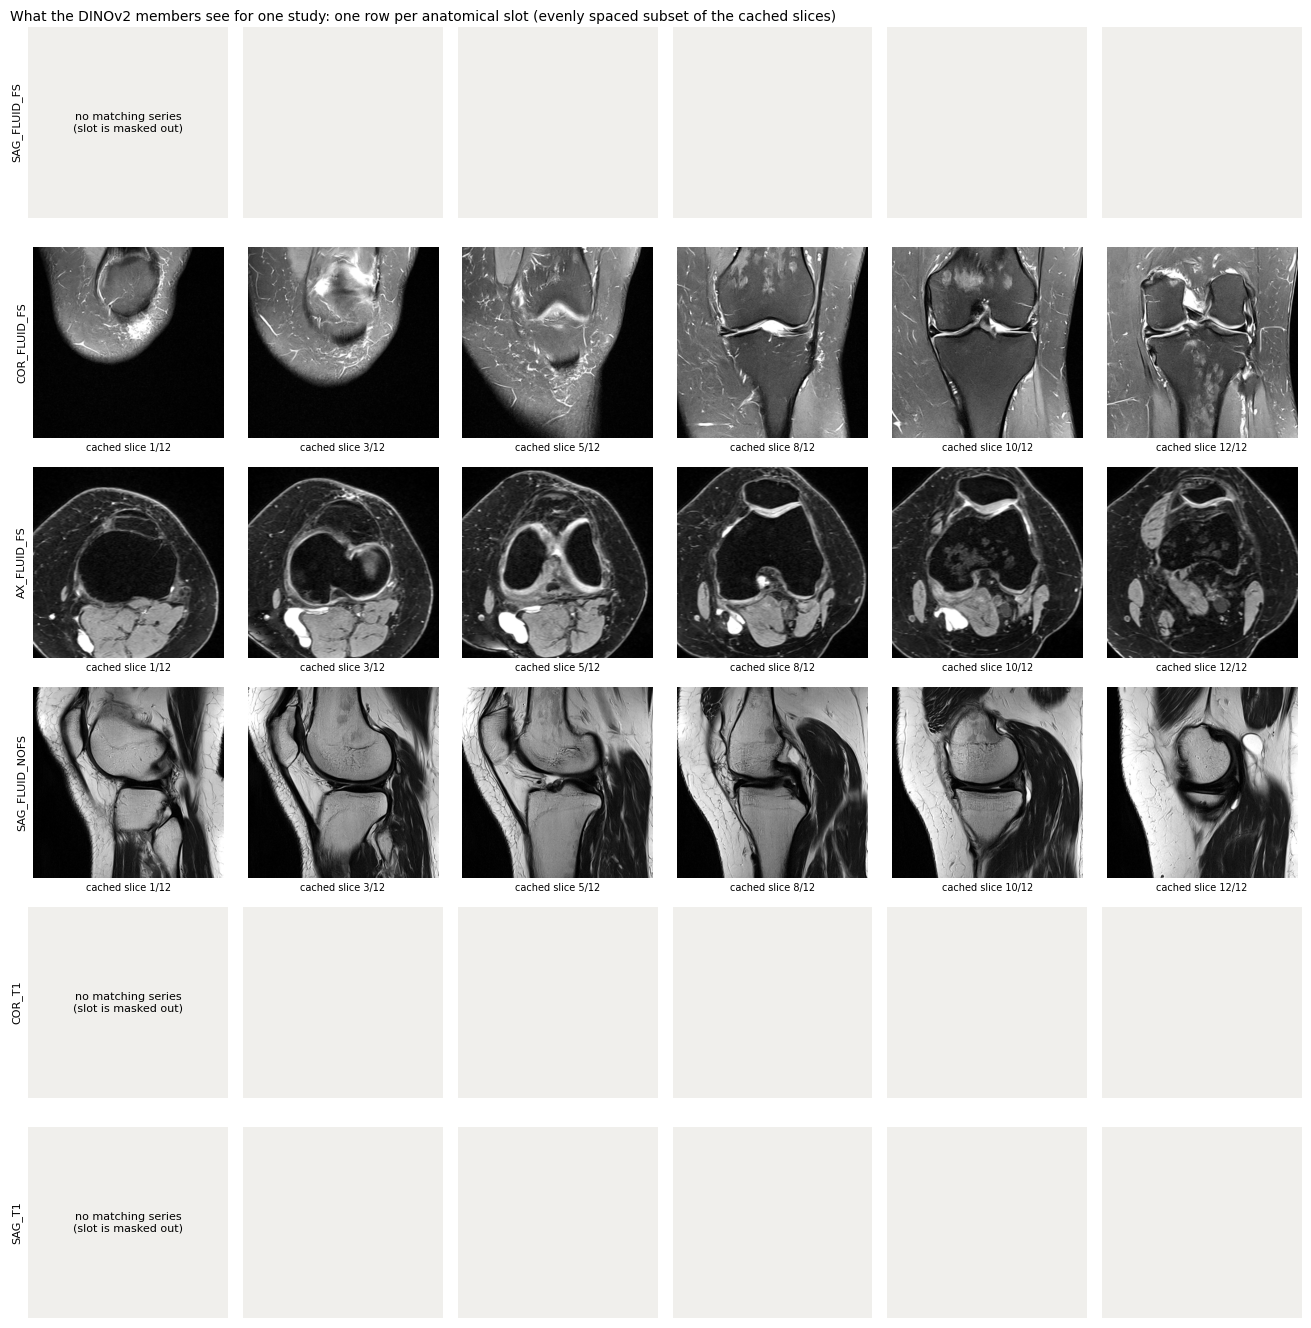

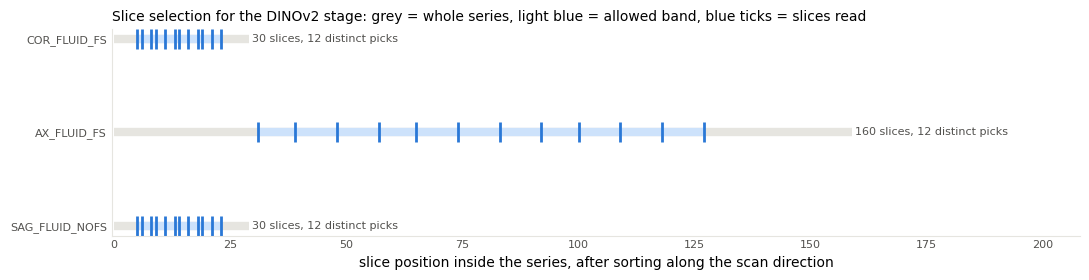

20 members x 3 studies x 12 findings; probability range 0.060 - 0.965


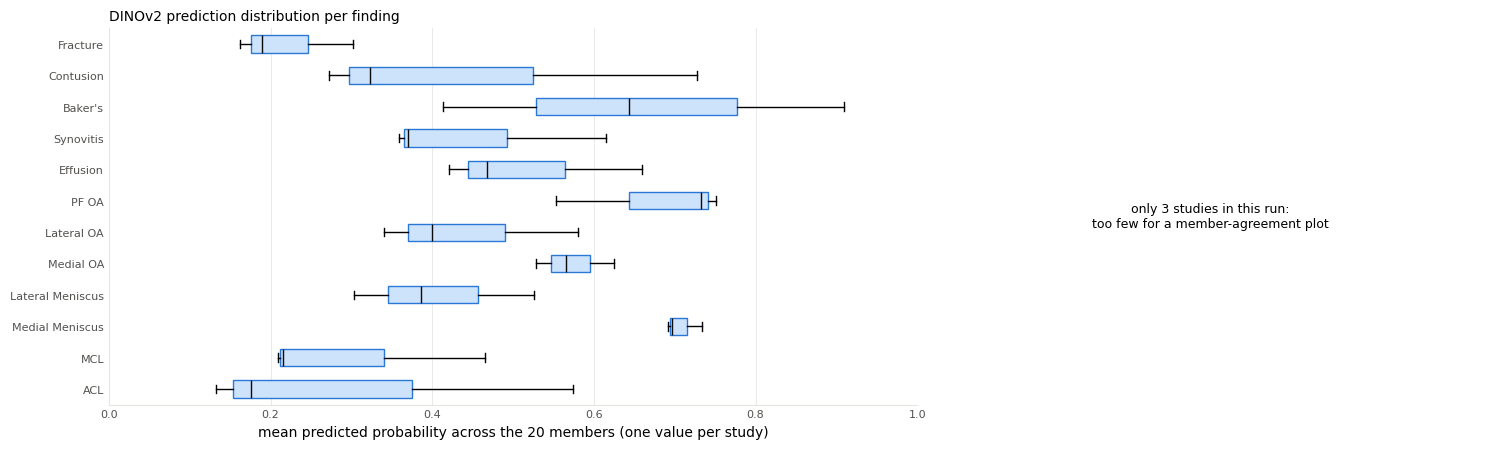

In [22]:
# ======================= Stage 1 review: what the DINOv2 members were shown, and what they answered =======================
with AX_cell("snapshot stage 1"):
    AX_snapshot("1_dino")


def AX_dino_inputs(study_index=0, max_cols=6):
    """Rebuild, for ONE test study, exactly the slot images that were cached for the DINOv2 members,
    using the pipeline's own functions and its current settings (no model is run)."""
    import matplotlib.pyplot as plt
    hte = annotate(walk("test_series"))                         # header table is memoised: no DICOM is re-read
    tser = pd.read_csv(ROOT / "test_series.csv")
    plane_map = dict(zip(tser["SeriesInstanceUID"], tser["Anatomical_Plane"]))
    uid = _RSNA_TEST_IDS[study_index]
    chosen = pick_slots(hte[hte.StudyInstanceUID == uid], plane_map).get(uid, {})
    side = lat_of(hte[hte.StudyInstanceUID == uid], "illustration: ").get(uid)   # same rule as the pipeline: tag first, geometry second
    n_events, n_failed = len(_RSNA_AUDIT["events"]), len(DECODE_FAILED)
    rows = []
    try:
        for name, plane, _, _ in SLOTS:
            rec = chosen.get(name)
            if rec is None:
                rows.append((name, plane, None, None, None)); continue
            rec = dict(rec)                                     # plain copy: the pipeline's own records stay untouched
            memo = _RSNA_ORDER_MEMO.get((str(Path(rec["dir"]).resolve()), RULES["order"], tuple(sorted(rec["files"]))))
            if memo is not None:
                rec["ordered"] = list(memo[0])
            img = read_slot(rec, CACHE_SLICES, IMG)
            if img is not None:
                img = normalise_laterality(img, plane, side).numpy()
            n = len(rec["files"])
            lo, hi = int(SLICE_BAND[0] * (n - 1)), int(SLICE_BAND[1] * (n - 1))
            picks = np.unique(np.linspace(lo, hi, CACHE_SLICES).astype(int)) if hi > lo else np.array([n // 2])
            rows.append((name, plane, img, n, picks))
    finally:   # the audit trail must describe the real run only, not this illustration
        del _RSNA_AUDIT["events"][n_events:]
        del DECODE_FAILED[n_failed:]
    print(f"study {uid} | knee side used for flipping: {side or 'unresolved'} | image size {IMG}px | crop {CROP_MM:.0f} mm | "
          f"{CACHE_SLICES} slices per slot from the {SLICE_BAND[0]:.0%}-{SLICE_BAND[1]:.0%} band of each series")
    cols = min(max_cols, CACHE_SLICES)
    show = np.linspace(0, CACHE_SLICES - 1, cols).round().astype(int)
    fig, axes = plt.subplots(len(rows), cols, figsize=(2.2 * cols, 2.25 * len(rows)), squeeze=False)
    for r, (name, plane, img, n, picks) in enumerate(rows):
        for c, k in enumerate(show):
            ax = axes[r][c]; ax.set_xticks([]); ax.set_yticks([])
            for s in ax.spines.values():
                s.set_visible(False)
            if img is None:
                ax.set_facecolor("#f0efec")
                if c == 0:
                    ax.text(0.5, 0.5, "no matching series\n(slot is masked out)", ha="center", va="center", fontsize=8, transform=ax.transAxes)
            else:
                ax.imshow(img[k], cmap="gray", vmin=0, vmax=255)
                ax.set_xlabel(f"cached slice {k + 1}/{CACHE_SLICES}", fontsize=7)
            if c == 0:
                ax.set_ylabel(name, fontsize=8)
    fig.suptitle("What the DINOv2 members see for one study: one row per anatomical slot (evenly spaced subset of the cached slices)",
                 fontsize=10, x=0.01, ha="left")
    plt.tight_layout(); plt.show()

    # slice selection: which positions of each original series were used
    present = [(name, n, picks) for name, _, img, n, picks in rows if img is not None]
    if present:
        fig, ax = plt.subplots(figsize=(11, 0.5 * len(present) + 1.4))
        for y, (name, n, picks) in enumerate(present):
            ax.hlines(y, 0, n - 1, color=AX_C["grid"], lw=6)
            ax.hlines(y, int(SLICE_BAND[0] * (n - 1)), int(SLICE_BAND[1] * (n - 1)), color="#cde2fb", lw=6)
            ax.plot(picks, [y] * len(picks), "|", color=AX_C["blue"], ms=14, mew=2)
            ax.text(n - 1 + 0.6, y, f"{n} slices, {len(picks)} distinct picks", va="center", fontsize=8, color=AX_C["muted"])
        ax.set_yticks(range(len(present)), [p[0] for p in present], fontsize=8); ax.invert_yaxis()
        ax.set_xlabel("slice position inside the series, after sorting along the scan direction")
        ax.set_title("Slice selection for the DINOv2 stage: grey = whole series, light blue = allowed band, blue ticks = slices read",
                     fontsize=10, loc="left")
        AX_style(ax, None); ax.set_xlim(-0.5, max(p[1] for p in present) * 1.3); plt.tight_layout(); plt.show()
        if any(len(p[2]) < CACHE_SLICES for p in present):
            print(f"A series whose band holds fewer than {CACHE_SLICES} slices is read completely and its last slice is repeated to fill the cache.")


def AX_dino_member_summary():
    """Do the 20 members agree? Low agreement = diverse ensemble; one member far from the rest = suspect."""
    import matplotlib.pyplot as plt
    files = sorted((AX_OUT / "diagnostics").glob("dino_*.npz"))
    if not files:
        print("no DINOv2 member predictions found"); return
    P = np.stack([np.load(f, allow_pickle=False)["values"] for f in files])       # [member, study, finding] probabilities
    print(f"{P.shape[0]} members x {P.shape[1]} studies x {P.shape[2]} findings; probability range {P.min():.3f} - {P.max():.3f}")
    fig, ax = plt.subplots(1, 2, figsize=(15, 4.6), gridspec_kw={"width_ratios": [1.5, 1]})
    mean = P.mean(0)                                                              # ensemble mean probability per study
    bp = ax[0].boxplot([mean[:, j] for j in range(P.shape[2])], vert=False, tick_labels=TARGETS, widths=0.55,
                       patch_artist=True, medianprops=dict(color=AX_C["ink"]), flierprops=dict(marker=".", ms=3, mec=AX_C["grey"]))
    for b in bp["boxes"]:
        b.set(facecolor="#cde2fb", edgecolor=AX_C["blue"])
    ax[0].set_xlim(0, 1); ax[0].set_xlabel("mean predicted probability across the 20 members (one value per study)")
    ax[0].set_title("DINOv2 prediction distribution per finding", fontsize=10, loc="left"); AX_style(ax[0])
    if P.shape[1] >= 8:
        R = np.stack([AX_rankpct(p) for p in P])                                  # rank within each member
        flat = R.transpose(0, 2, 1).reshape(P.shape[0], -1)                       # ranks are comparable across findings
        C = np.corrcoef(flat)
        im = ax[1].imshow(C, cmap=AX_SEQ, vmin=min(0.5, float(C.min())), vmax=1)
        ax[1].set_xlabel("member"); ax[1].set_ylabel("member")
        ax[1].set_title(f"Agreement between members (rank correlation, mean off-diagonal {(C.sum() - len(C)) / (C.size - len(C)):.2f})",
                        fontsize=10, loc="left")
        AX_style(ax[1], None); fig.colorbar(im, ax=ax[1], fraction=.046)
    else:
        ax[1].axis("off")
        ax[1].text(0.5, 0.5, f"only {P.shape[1]} studies in this run:\ntoo few for a member-agreement plot", ha="center", va="center", fontsize=9)
    plt.tight_layout(); plt.show()


with AX_cell("stage 1 inputs"):
    AX_dino_inputs()
with AX_cell("stage 1 member summary"):
    AX_dino_member_summary()

# Stage 2 — A5 attention pooling (5 folds)

**Why a second, different model.** DINOv2 members see three slices at a time and combine *slots*. A5 looks at **16 slices of a slot at once** and combines evidence with a different mechanism. Models that look at the data differently make different errors, which is what makes blending them worthwhile.

**Input.** Six slots (three planes × fat-suppressed / not), 16 slices each at 336 px from the central 12–88 % of the series, ordered by `InstanceNumber`, cropped to 130 mm, each slice windowed to its own 1st–99th percentile. Coronal and axial images are mirrored when the image position indicates a right knee. Note that these rules differ slightly from Stage 1; each stage reproduces what *its* checkpoints were trained with.

**Architecture** (`Net`, configured by the checkpoint itself).
- *Slices as channels.* The 16 slices of a slot form one 16-channel image, so the very first layer already mixes neighbouring slices. Depending on the checkpoint's `stem` setting, a small depth module first blends neighbouring slices (`SlotDepthMixer`) or compresses 16 channels to 3 (`DepthCompress`).
- *Encoder.* A `timm` image backbone named in the checkpoint. With `cond == 'token'`, an extra learned token tells the transformer which slot it is looking at (`ViTSlotToken`).
- *Readout.* A study has a variable number of slots. The readout pools them with per-finding attention (`LabelAttentionPool`, `TokenXAttnPool`, residual variants) or mean+max pooling, again chosen by the checkpoint. An embedding of *which* slots are present is added, so the model knows what it could not see.

The loader checks that all five folds share one configuration and that image size and slice count match this notebook's loader, then loads strictly.

**Ensembling.** Each fold's probabilities are ranked, the five rank vectors averaged, and the result blended into stage 1 with weight **0.52**.

**Effect on predictions.** A5 supplies 52 % of the stage-2 blend. That blend is the input of the RadImageNet blend and of the calibrator in Stage 3.

## The bug this stage had

In the original notebook the visualization cell in the middle of this stage contained

```python
studies = sorted(p for p in Path(SERIES_ROOT).iterdir() if p.is_dir())
```

Two cells earlier, `studies` had been defined as the list of test study IDs (strings) that A5 iterates over. After the plotting cell it was a list of folder paths. A5 then looked up `by.get(study, [])` in a dictionary keyed by ID strings, got an empty list for every study, recorded "no metadata", and marked every study as not applicable. The blend function treats "not applicable" as a legitimate case (some studies really lack usable series) and returned the DINOv2 blend unchanged. No error, no warning in the cell output, and a complete, valid-looking `submission.csv` at the end.

The saved output of the original run shows the contradiction: the startup check reports `a5_without_matching_acquisition: 0` (every study has usable series), while the A5 stage ends with `"absent": 3, "applicable": 0`.

**What was done.**
1. The plotting code moved into a function and runs under `AX_cell`.
2. **New gate 1 — input contract** (before inference): `studies` must be exactly the list of test IDs.
3. **New gate 2 — coverage** (after inference): the studies without an A5 prediction must be explained by the metadata; if more than 25 % are unexplained the run stops.

The general lesson: a pipeline that tolerates missing inputs needs a check that the tolerated case is the exception.

### Stage 2 inputs

The next two cells set the A5 constants and define how a study is decoded (`build_study`). A snapshot of all variables is taken first (`_A5_SAVED`) and restored at the end of the stage, because A5 re-uses names such as `SLOTS` and `SLICE_BAND` with different values than Stage 1.

In [23]:
if globals().get('_DINOV2_MATCHED_MEMBERS') != 20:
    raise RuntimeError('DINOv2 20/20 fingerprint gate did not pass')
rsna_phase('a5', 'START')
_A5_SAVED = dict(globals())
import gc, os, time, warnings
from concurrent.futures import ThreadPoolExecutor as A5DecodePool, as_completed
from pathlib import Path
import cv2
import numpy as np
import pandas as pd
import pydicom
import timm
import torch
import torch.nn as nn
import torch.nn.functional as F

warnings.filterwarnings('ignore')
cv2.setNumThreads(1)
CROP_MM = 130.0
SIZE = 336
SLICE_BAND = (0.12, 0.88)
N_SLICE = 16
INTENSITY = 'slice'
SLOTS = [
    ('Sagittal', 1),
    ('Sagittal', 0),
    ('Coronal', 1),
    ('Coronal', 0),
    ('Axial', 1),
    ('Axial', 0),
]
N_SLOT = len(SLOTS)
LABELS = [
    'ACL',
    'MCL',
    'Medial Meniscus',
    'Lateral Meniscus',
    'Medial OA',
    'Lateral OA',
    'PF OA',
    'Effusion',
    'Synovitis',
    "Baker's",
    'Contusion',
    'Fracture',
]


def _one_a5_root(tag, candidates, marker):
    hits = [
        Path(path) for path in candidates if Path(path).is_dir() and (Path(path) / marker).exists()
    ]
    if len(hits) != 1:
        raise RuntimeError(f'{tag}: expected one direct root, found {hits}')
    return hits[0]


COMP = Path(ROOT)
CKPT = _one_a5_root(
    'A5 weights',
    [
        '/kaggle/input/datasets/mattiaangeli/knee-mri-fold-weights',
        '/kaggle/input/knee-mri-fold-weights',
    ],
    'm_f0.pt',
)
assert COMP is not None, 'competition data not attached'
assert CKPT is not None, 'fold weights not attached'
assert (COMP / 'sample_submission.csv').exists(), f'no competition data at {COMP}'
assert list(CKPT.glob('*_f*.pt')), f'no checkpoints at {CKPT}'
DEV = 'cuda' if torch.cuda.is_available() else 'cpu'


[phase] {"elapsed_seconds": 67.23069930076599, "gpus": [{"allocated_bytes": 9568256, "id": 0, "reserved_bytes": 23068672}, {"allocated_bytes": 9568256, "id": 1, "reserved_bytes": 195035136}], "max_rss_kib": 2556008, "memory.current": "5676621824", "memory.max": "32212254720", "stage": "a5", "status": "START"}


In [24]:
SERIES_ROOT = COMP / 'test_series'
if not SERIES_ROOT.is_dir():
    raise FileNotFoundError('Missing test_series; train-series fallback is forbidden')
print('series root:', SERIES_ROOT)


def ordered_files(sdir, cap=64):
    # Preserve the parent's InstanceNumber ordering; remove pre-sort truncation.
    # The unused cap argument remains only for call compatibility.
    keyed = []
    unreadable = []
    for f in sorted(sdir.glob('*.dcm')):
        try:
            ds = pydicom.dcmread(str(f), stop_before_pixels=True)
            key = int(ds.InstanceNumber)
        except Exception as exc:
            unreadable.append(str(f))
            continue
        keyed.append((key, str(f)))
    if unreadable:
        rsna_event(
            'a5_order_unreadable_dropped',
            series=str(sdir),
            unreadable=len(unreadable),
            readable=len(keyed),
            examples=unreadable[:3],
        )
    return [f for _, f in sorted(keyed)]


def series_side(path):
    try:
        return float(pydicom.dcmread(path, stop_before_pixels=True).ImagePositionPatient[0])
    except Exception:
        return 0.0


def read_crop(path):
    try:
        ds = pydicom.dcmread(path)
        arr = ds.pixel_array.astype(np.float32)
    except Exception:
        return None
    try:
        ps = float(ds.PixelSpacing[0])
    except Exception:
        ps = CROP_MM / max(arr.shape)
    half = int(round(CROP_MM / ps / 2))
    cy, cx = (arr.shape[0] // 2, arr.shape[1] // 2)
    y0, y1 = (max(0, cy - half), min(arr.shape[0], cy + half))
    x0, x1 = (max(0, cx - half), min(arr.shape[1], cx + half))
    crop = arr[y0:y1, x0:x1]
    return None if crop.size == 0 else crop


def window(crop, lo, hi, flip):
    c = np.clip((crop - lo) / max(hi - lo, 1e-06), 0, 1)
    img = cv2.resize(c, (SIZE, SIZE), interpolation=cv2.INTER_AREA)
    return img[:, ::-1].copy() if flip else img


def render(path, flip):
    crop = read_crop(path)
    if crop is None:
        return None
    lo, hi = np.percentile(crop[::4, ::4], [1, 99])
    return window(crop, lo, hi, flip)


def build_study(args):
    idx, study, recs = args
    out = np.zeros((N_SLOT, N_SLICE, SIZE, SIZE), np.uint8)
    mask = np.zeros(N_SLOT, np.uint8)
    rows = pd.DataFrame(recs)
    if not len(rows):
        rsna_event('a5_no_metadata', study=str(study))
        return idx, out, mask
    for s_i, (plane, fs) in enumerate(SLOTS):
        sub = rows[(rows.Anatomical_Plane == plane) & (rows.Fat_Suppression == fs)]
        if sub.empty:
            continue  # Actual acquisition absence, not a decoding failure.
        series = str(sub.iloc[0].SeriesInstanceUID)
        files = ordered_files(SERIES_ROOT / str(study) / series)
        if not files:
            rsna_event('a5_slot_no_files', study=str(study), series=series)
            continue
        flip = plane != 'Sagittal' and series_side(files[0]) < 0
        i0 = int(round(SLICE_BAND[0] * (len(files) - 1)))
        i1 = int(round(SLICE_BAND[1] * (len(files) - 1)))
        avail = list(range(i0, i1 + 1))
        if len(avail) >= N_SLICE:
            picks = [avail[int(round(t))] for t in np.linspace(0, len(avail) - 1, N_SLICE)]
            off = 0
        else:
            picks, off = avail, (N_SLICE - len(avail)) // 2
        rendered = 0
        errors = []
        if INTENSITY == 'series':
            crops = [read_crop(files[p]) for p in picks]
            got = [x for x in crops if x is not None]
            if not got:
                rsna_event('a5_slot_all_crops_failed', study=str(study), series=series)
                continue
            samp = np.concatenate([x[::4, ::4].ravel() for x in got])
            lo_, hi_ = np.percentile(samp, [1, 99])
            for c, x in enumerate(crops):
                if x is None:
                    x = read_crop(files[min(len(files) - 1, picks[c] + 1)])
                if x is None:
                    errors.append(files[picks[c]])
                    continue
                img = window(x, lo_, hi_, flip)
                rsna_finite(img, 'A5 rendered pixels')
                out[s_i, off + c] = (img * 255).astype(np.uint8)
                rendered += 1
        else:
            for c, p in enumerate(picks):
                img = render(files[p], flip)
                if img is None:
                    img = render(files[min(len(files) - 1, p + 1)], flip)
                if img is None:
                    errors.append(files[p])
                    continue
                rsna_finite(img, 'A5 rendered pixels')
                out[s_i, off + c] = (img * 255).astype(np.uint8)
                rendered += 1
        if errors or rendered != len(picks):
            rsna_event(
                'a5_decode_failure',
                study=str(study),
                series=series,
                failed=errors,
                rendered=int(rendered),
                wanted=int(len(picks)),
            )
            if not rendered:
                continue
        mask[s_i] = rendered
    if not mask.any():
        rsna_event('a5_empty_study', study=str(study))
        print(f'[a5] {study}: no acquired slots; all-zero mask kept (parent policy)', flush=True)
    return idx, out, mask


sub_df = pd.read_csv(COMP / 'sample_submission.csv', dtype={'StudyInstanceUID': str})
ser_csv = pd.read_csv(
    COMP / 'test_series.csv', dtype={'StudyInstanceUID': str, 'SeriesInstanceUID': str}
)
if set(sub_df.StudyInstanceUID) != set(_RSNA_TEST_IDS):
    raise RuntimeError('A5 test/sample UID mismatch')
ser_csv = ser_csv.loc[:, ~ser_csv.columns.duplicated()]
studies = sub_df.StudyInstanceUID.tolist()
by = {
    s: g.to_dict('records')
    for s, g in ser_csv[ser_csv.StudyInstanceUID.isin(set(studies))].groupby('StudyInstanceUID')
}
print(f'{len(studies):,} test studies, {len(by):,} with series metadata')


series root: /kaggle/input/competitions/rsna-knee-abnormality-detection/test_series
3 test studies, 3 with series metadata


### Raw slices and the A5 slice selection — **Fixed**

Shows raw slices of the first test study as stored in the DICOM files (before cropping and normalisation), taken from the positions A5 will read. This is the cell that caused the bug described above; it now cannot touch pipeline variables.

series 605155903947: 34 slices; A5 reads 16 of them between positions 5 and 30
series 518906646132: 30 slices; A5 reads 16 of them between positions 4 and 27
series 062489758495: 30 slices; A5 reads 16 of them between positions 4 and 27


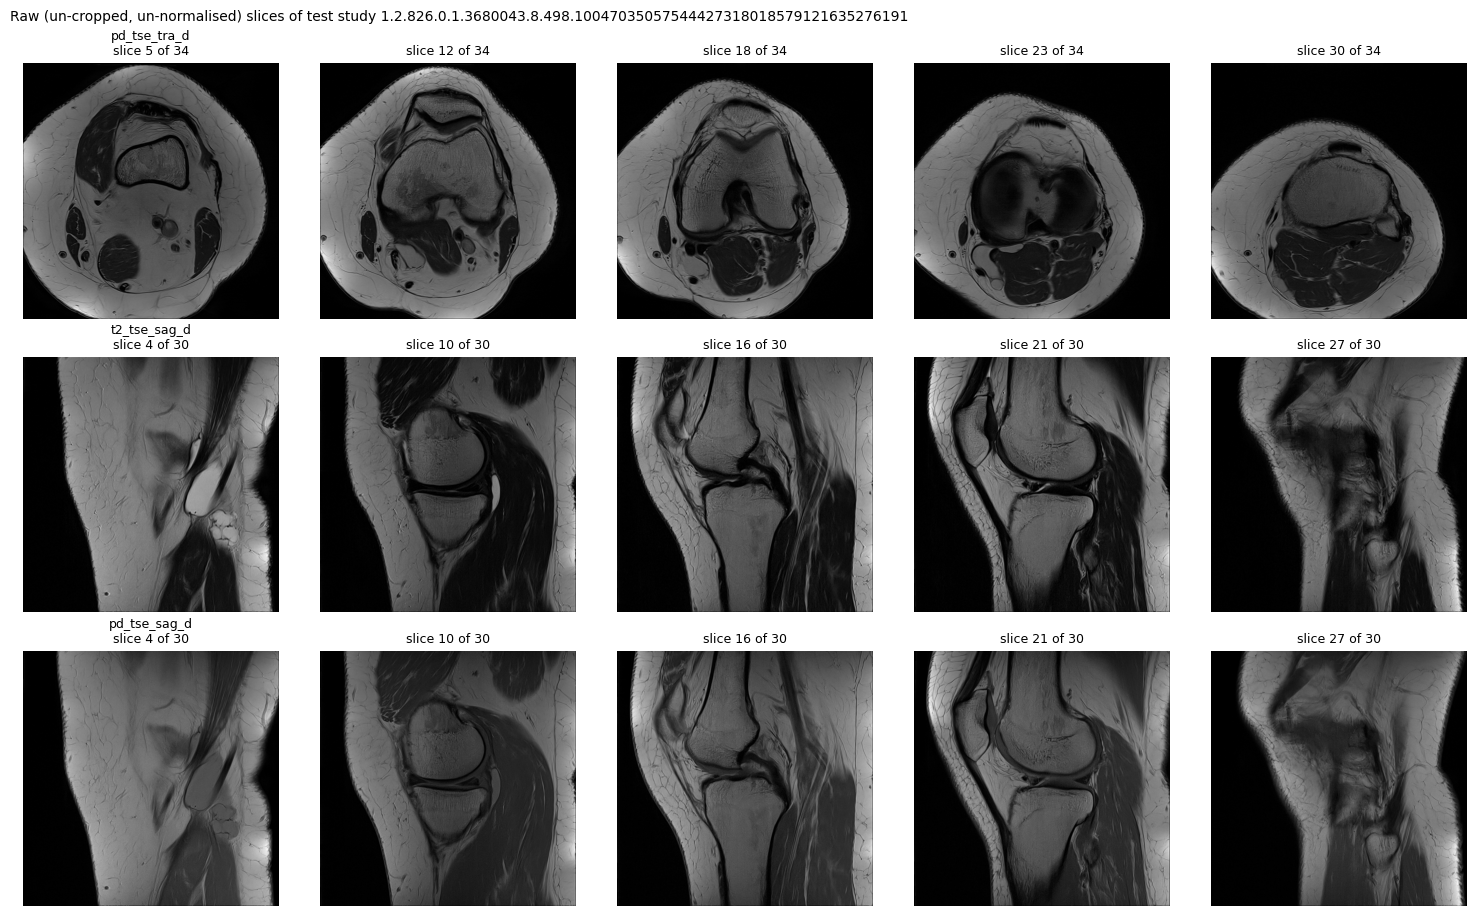

In [25]:
# Visualization: raw slices of one test study, and which of them the A5 stage will read.
# FIX: the original version of this cell ran at top level and assigned `studies = sorted(<folders>)`.
# That replaced the list of study UIDs the A5 cells had just built, so A5 found no metadata for any
# study and was silently left out of the blend. The code now lives in a function (its variables are
# local) and runs under AX_cell, which additionally restores any pipeline variable a cell re-binds.
def AX_a5_raw_slices(max_series=3, n_show=5):
    import matplotlib.pyplot as plt
    study_dirs = sorted(p for p in Path(SERIES_ROOT).iterdir() if p.is_dir())
    if not study_dirs:
        print("no test studies found under", SERIES_ROOT); return
    study_dir = study_dirs[0]
    series_dirs = sorted(p for p in study_dir.iterdir() if p.is_dir())[:max_series]
    fig, axes = plt.subplots(len(series_dirs), n_show, figsize=(3 * n_show, 3.1 * len(series_dirs)), squeeze=False)
    n_events = len(_RSNA_AUDIT["events"])
    for r, sdir in enumerate(series_dirs):
        files = ordered_files(sdir)                       # the A5 ordering (by InstanceNumber)
        n = len(files)
        i0, i1 = int(round(SLICE_BAND[0] * (n - 1))), int(round(SLICE_BAND[1] * (n - 1)))
        avail = list(range(i0, i1 + 1))
        picks = [avail[int(round(t))] for t in np.linspace(0, len(avail) - 1, N_SLICE)] if len(avail) >= N_SLICE else avail
        shown = [picks[int(i)] for i in np.linspace(0, len(picks) - 1, n_show).round()] if picks else []
        for c in range(n_show):
            ax = axes[r][c]; ax.axis("off")
            if c < len(shown):
                ds = pydicom.dcmread(files[shown[c]], force=True)
                ax.imshow(ds.pixel_array, cmap="gray")
                title = f"slice {shown[c] + 1} of {n}"
                if c == 0:
                    title = f"{str(getattr(ds, 'SeriesDescription', ''))[:24]}\n{title}"
                ax.set_title(title, fontsize=9)
        print(f"series {sdir.name[-12:]}: {n} slices; A5 reads {len(picks)} of them between positions {i0 + 1} and {i1 + 1}")
    del _RSNA_AUDIT["events"][n_events:]                  # keep the audit trail about the real run only
    fig.suptitle(f"Raw (un-cropped, un-normalised) slices of test study {study_dir.name}", fontsize=10, x=0.01, ha="left")
    plt.tight_layout(); plt.show()


with AX_cell("stage 2 raw slices"):
    AX_a5_raw_slices()

### Stage 2 model components and checkpoint loading

Defines the pooling modules, the depth stems, the slot token and `Net`, then loads the five fold checkpoints with a strict check: every tensor must be present, have the right shape and be finite.

In [26]:
N_SLOT_TYPES, MASK_IDX = (6, 0)


def segment_softmax(scores, sidx, B):
    T, K = scores.shape
    idx = sidx.unsqueeze(1).expand(-1, K)
    m = torch.full((B, K), float('-inf'), device=scores.device, dtype=scores.dtype)
    m = m.scatter_reduce(0, idx, scores, reduce='amax', include_self=True)
    e = (scores - m[sidx]).exp()
    s = torch.zeros(B, K, device=scores.device, dtype=scores.dtype).index_add_(0, sidx, e)
    return e / s[sidx].clamp(min=1e-06)


class MeanMaxPool(nn.Module):

    def forward(self, f, sidx, B, slot=None, return_attn=False):
        D = f.shape[1]
        cnt = torch.zeros(B, device=f.device, dtype=f.dtype).index_add_(
            0, sidx, torch.ones(f.shape[0], device=f.device, dtype=f.dtype)
        )
        mean = torch.zeros(B, D, device=f.device, dtype=f.dtype).index_add_(0, sidx, f)
        mean = mean / cnt.clamp(min=1).unsqueeze(1)
        mx = torch.full((B, D), -10000.0, device=f.device, dtype=f.dtype)
        mx = mx.scatter_reduce(
            0, sidx.unsqueeze(1).expand(-1, D), f, reduce='amax', include_self=True
        )
        return (torch.cat([mean, mx], 1), None)


class LabelAttentionPool(nn.Module):

    def __init__(self, d, n_labels=12, n_heads=4, slot_bias=True):
        super().__init__()
        self.d, self.k, self.h = (d, n_labels, n_heads)
        self.q = nn.Parameter(torch.randn(n_labels, d) * 0.02)
        self.key, self.val = (nn.Linear(d, d), nn.Linear(d, d))
        self.slot_bias = (
            nn.Parameter(torch.zeros(n_labels, N_SLOT_TYPES + 1)) if slot_bias else None
        )

    def forward(self, f, sidx, B, slot=None, return_attn=False):
        scores = self.key(f) @ self.q.t() / self.d**0.5
        if self.slot_bias is not None and slot is not None:
            scores = scores + self.slot_bias.t()[slot]
        a = segment_softmax(scores, sidx, B)
        out = torch.zeros(B, self.k, self.d, device=f.device, dtype=f.dtype)
        out = out.index_add_(0, sidx, a.unsqueeze(-1) * self.val(f).unsqueeze(1))
        return (out, a)


class TokenXAttnPool(nn.Module):

    def __init__(self, d, n_labels=12, n_heads=6, dropout=0.2):
        super().__init__()
        self.d, self.k = (d, n_labels)
        self.q = nn.Parameter(torch.randn(n_labels, d) * 0.02)
        self.slot_emb = nn.Embedding(N_SLOT_TYPES + 1, d, padding_idx=0)
        self.kv_norm = nn.LayerNorm(d)
        self.attn = nn.MultiheadAttention(d, n_heads, dropout=dropout, batch_first=True)

    def forward(self, tok, sidx, B, slot=None, return_attn=False):
        T, N, D = tok.shape
        cnt = torch.bincount(sidx, minlength=B)
        S = int(cnt.max().item())
        starts = torch.cumsum(cnt, 0) - cnt
        pos = torch.arange(T, device=tok.device) - starts[sidx]
        kv = tok + self.slot_emb(slot).unsqueeze(1)
        pad = tok.new_zeros(B, S, N, D)
        pad[sidx, pos] = kv
        keep = torch.zeros(B, S, dtype=torch.bool, device=tok.device)
        keep[sidx, pos] = True
        kpm = ~keep.repeat_interleave(N, dim=1)
        pad = self.kv_norm(pad.reshape(B, S * N, D))
        q = self.q.unsqueeze(0).expand(B, -1, -1)
        att, w = self.attn(
            q, pad, pad, key_padding_mask=kpm, need_weights=return_attn, average_attn_weights=True
        )
        cls = tok[:, 0]
        mean = torch.zeros(B, D, device=tok.device, dtype=tok.dtype).index_add_(
            0, sidx, cls
        ) / cnt.clamp(min=1).unsqueeze(1)
        mx = torch.full((B, D), -10000.0, device=tok.device, dtype=tok.dtype)
        mx = mx.scatter_reduce(
            0, sidx.unsqueeze(1).expand(-1, D), cls, reduce='amax', include_self=True
        )
        base = torch.cat([mean, mx], 1).unsqueeze(1).expand(-1, self.k, -1)
        return (torch.cat([att, base], -1), w)


class ViTSlotToken(nn.Module):

    def __init__(self, vit, n_cat, dim=None):
        super().__init__()
        self.vit = vit
        d = dim or vit.embed_dim
        self.tok = nn.Embedding(n_cat + 1, d, padding_idx=MASK_IDX)
        self.num_features = vit.num_features
        self._orig_prefix = getattr(vit, 'num_prefix_tokens', 1)
        vit.num_prefix_tokens = self._orig_prefix + 1
        for blk in vit.blocks:
            a = getattr(blk, 'attn', None)
            if a is not None and hasattr(a, 'num_prefix_tokens'):
                a.num_prefix_tokens = a.num_prefix_tokens + 1

    @staticmethod
    def _maybe(mod, x):
        return x if mod is None else mod(x)

    def forward_features(self, x, cat):
        v = self.vit
        x = v.patch_embed(x)
        pos = v._pos_embed(x)
        rope = None
        if isinstance(pos, tuple):
            x, rope = pos
        else:
            x = pos
        x = self._maybe(getattr(v, 'patch_drop', None), x)
        x = self._maybe(getattr(v, 'norm_pre', None), x)
        npt = self._orig_prefix
        tok = self.tok(cat).unsqueeze(1)
        x = torch.cat([x[:, :npt], tok, x[:, npt:]], dim=1)
        if rope is not None:
            if getattr(v, 'rope_mixed', False):
                for i, blk in enumerate(v.blocks):
                    x = blk(x, rope=rope[i])
            else:
                for blk in v.blocks:
                    x = blk(x, rope=rope)
        else:
            x = v.blocks(x)
        return v.norm(x)

    def forward_head(self, x, pre_logits=True):
        return self.vit.forward_head(x, pre_logits=pre_logits)


IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD = (0.229, 0.224, 0.225)


class _GatedDepthBlock(nn.Module):

    def __init__(self, n_slice, dropout=0.0, ls_init=0.1):
        super().__init__()
        self.norm = nn.GroupNorm(1, n_slice)
        self.v = nn.Conv2d(n_slice, n_slice, 1)
        self.g = nn.Conv2d(n_slice, n_slice, 1)
        self.out = nn.Conv2d(n_slice, n_slice, 1)
        self.gamma = nn.Parameter(torch.full((n_slice, 1, 1), ls_init))
        self.drop = nn.Dropout2d(dropout) if dropout else nn.Identity()

    def forward(self, x):
        z = self.norm(x)
        return x + self.gamma * self.drop(self.out(self.v(z) * F.silu(self.g(z))))


class DepthCompress(nn.Module):

    def __init__(
        self,
        n_slice=16,
        out_ch=3,
        depth=1,
        dropout=0.0,
        ls_init=0.1,
        imagenet=True,
        proj_noise=0.25,
    ):
        super().__init__()
        self.imagenet = imagenet
        self.blocks = nn.ModuleList(
            [_GatedDepthBlock(n_slice, dropout, ls_init) for _ in range(depth)]
        )
        self.proj = nn.Conv2d(n_slice, out_ch, 1, bias=True)
        if imagenet:
            self.register_buffer('mu', torch.tensor(IMAGENET_MEAN).view(1, -1, 1, 1))
            self.register_buffer('sd', torch.tensor(IMAGENET_STD).view(1, -1, 1, 1))

    def forward(self, x):
        keep = (x.amax(dim=1, keepdim=True) > 0).to(x.dtype)
        z = x
        for b in self.blocks:
            z = b(z)
        z = self.proj(z)
        if self.imagenet:
            z = (z - self.mu.to(z.dtype)) / self.sd.to(z.dtype)
        return z * keep


N_PLANE, N_CONTRAST = (3, 2)
_PLANE_OF = lambda s: torch.clamp(s - 1, 0, 5) // 2
_CONTRAST_OF = lambda s: torch.clamp(s - 1, 0, 5) % 2


class SlotDepthMixer(nn.Module):

    def __init__(self, n_slice=16, ksize=5, alpha_max=0.25):
        super().__init__()
        self.n_slice, self.ksize, self.r = (n_slice, ksize, ksize // 2)
        self.alpha_max = alpha_max
        b = torch.tensor([1.0, 4.0, 6.0, 4.0, 1.0])
        self.register_buffer('base', b.log()[self.r :])
        n_u = self.r + 1
        self.shared = nn.Parameter(torch.zeros(n_u))
        self.plane_k = nn.Parameter(torch.zeros(N_PLANE, n_u))
        self.contrast_k = nn.Parameter(torch.zeros(N_CONTRAST, n_u))
        self.g0 = nn.Parameter(torch.zeros(()))
        self.gate_p = nn.Parameter(torch.zeros(N_PLANE))
        self.gate_c = nn.Parameter(torch.zeros(N_CONTRAST))
        idx = torch.arange(n_slice)
        self.register_buffer('off', idx[None, :] - idx[:, None])

    def kernel(self, slot):
        p, c = (_PLANE_OF(slot), _CONTRAST_OF(slot))
        half = self.base + self.shared + self.plane_k[p] + self.contrast_k[c]
        full = torch.cat([half.flip(-1)[..., : self.r], half], dim=-1)
        return F.softmax(full, dim=-1)

    def alpha(self, slot):
        p, c = (_PLANE_OF(slot), _CONTRAST_OF(slot))
        return self.alpha_max * torch.tanh(self.g0 + self.gate_p[p] + self.gate_c[c])

    def forward(self, x, slot, vmask):
        T, S, H, W = x.shape
        if vmask is None:
            raise ValueError('stem=mixer requires the padding mask')
        k = self.kernel(slot)
        v = vmask.to(k.dtype)
        d = self.off + self.r
        inb = (d >= 0) & (d < self.ksize)
        kk = k[:, d.clamp(0, self.ksize - 1)] * inb
        M = kk * v[:, None, :]
        den = M.sum(-1, keepdim=True)
        eye = torch.eye(S, device=x.device, dtype=M.dtype).expand(T, S, S)
        ok = (den > 1e-06) & v[:, :, None].bool()
        M = torch.where(ok, M / den.clamp(min=1e-06), eye)
        a = self.alpha(slot)[:, None, None]
        Aop = ((1.0 - a) * eye + a * M).to(x.dtype)
        if x.is_contiguous(memory_format=torch.channels_last) and (not x.is_contiguous()):
            y = torch.bmm(x.permute(0, 2, 3, 1).reshape(T, H * W, S), Aop.transpose(1, 2))
            return y.reshape(T, H, W, S).permute(0, 3, 1, 2)
        return torch.bmm(Aop, x.reshape(T, S, H * W)).reshape(T, S, H, W)


def _seg_mean_max(v, sidx, B):
    D = v.shape[1]
    cnt = torch.zeros(B, device=v.device, dtype=v.dtype).index_add_(
        0, sidx, torch.ones(v.shape[0], device=v.device, dtype=v.dtype)
    )
    mean = torch.zeros(B, D, device=v.device, dtype=v.dtype).index_add_(0, sidx, v)
    mean = mean / cnt.clamp(min=1).unsqueeze(1)
    mx = torch.full((B, D), -10000.0, device=v.device, dtype=v.dtype)
    mx = mx.scatter_reduce(0, sidx.unsqueeze(1).expand(-1, D), v, reduce='amax', include_self=True)
    return torch.cat([mean, mx], 1)


def _pad_kv(x, sidx, B, norm):
    T, P, D = x.shape
    cnt = torch.bincount(sidx, minlength=B)
    S = int(cnt.max().item())
    starts = torch.cumsum(cnt, 0) - cnt
    pos = torch.arange(T, device=x.device) - starts[sidx]
    pad = x.new_zeros(B, S, P, D)
    pad[sidx, pos] = x
    keep = torch.zeros(B, S, dtype=torch.bool, device=x.device)
    keep[sidx, pos] = True
    return (norm(pad.reshape(B, S * P, D)), ~keep.repeat_interleave(P, dim=1))


class _GatedDelta(nn.Module):

    def __init__(self, d, n_labels, n_heads, dropout):
        super().__init__()
        self.q = nn.Parameter(torch.randn(n_labels, d) * 0.02)
        self.kv_norm = nn.LayerNorm(d)
        self.attn = nn.MultiheadAttention(d, n_heads, dropout=dropout, batch_first=True)
        self.d_norm = nn.LayerNorm(d)
        self.dw = nn.Parameter(torch.randn(n_labels, d) * (1.0 / d**0.5))
        self.db = nn.Parameter(torch.zeros(n_labels))
        self.gate = nn.Parameter(torch.zeros(n_labels))

    def delta(self, pat, sidx, B, return_attn):
        kv, kpm = _pad_kv(pat, sidx, B, self.kv_norm)
        q = self.q.unsqueeze(0).expand(B, -1, -1)
        att, w = self.attn(
            q, kv, kv, key_padding_mask=kpm, need_weights=return_attn, average_attn_weights=True
        )
        return ((self.d_norm(att) * self.dw).sum(-1) + self.db, w)


class TokenResidualPool(_GatedDelta):

    def __init__(self, d, n_labels=12, n_heads=6, pe=64, dropout=0.2):
        super().__init__(d, n_labels, n_heads, dropout)
        self.base = nn.Sequential(
            nn.LayerNorm(2 * d + pe), nn.Dropout(dropout), nn.Linear(2 * d + pe, n_labels)
        )

    def forward(self, tok, slot, sidx, B, pres, return_attn=False):
        base = self.base(torch.cat([_seg_mean_max(tok[:, 1:].mean(1), sidx, B), pres], 1))
        d_, w = self.delta(tok[:, 1:], sidx, B, return_attn)
        return (base + self.gate * d_, w)


class CodexResidualPool(_GatedDelta):

    def __init__(self, d, n_labels=12, n_heads=6, pe=64, dropout=0.2):
        super().__init__(d, n_labels, n_heads, dropout)
        self.base = nn.Sequential(
            nn.LayerNorm(2 * d + pe), nn.Dropout(dropout), nn.Linear(2 * d + pe, n_labels)
        )

    def forward(self, tok, slot, sidx, B, pres, return_attn=False):
        base = self.base(torch.cat([_seg_mean_max(tok[:, 0], sidx, B), pres], 1))
        d_, w = self.delta(tok[:, 1:], sidx, B, return_attn)
        return (base + self.gate * d_, w)


class ClsAddPool(nn.Module):

    def __init__(self, d, n_labels=12, pe=64, dropout=0.2):
        super().__init__()
        self.net = nn.Sequential(
            nn.LayerNorm(4 * d + pe), nn.Dropout(dropout), nn.Linear(4 * d + pe, n_labels)
        )

    def forward(self, tok, slot, sidx, B, pres, return_attn=False):
        return (
            self.net(
                torch.cat(
                    [
                        _seg_mean_max(tok[:, 1:].mean(1), sidx, B),
                        _seg_mean_max(tok[:, 0], sidx, B),
                        pres,
                    ],
                    1,
                )
            ),
            None,
        )


class Readout(nn.Module):

    def __init__(self, pool, d, n_labels=12, pe=64):
        super().__init__()
        self.pool_kind, self.k = (pool, n_labels)
        self.pres_emb = nn.Embedding(N_SLOT_TYPES + 1, pe, padding_idx=0)
        if pool in ('xres', 'clsadd', 'xcodex'):
            self.pool = {
                'xres': TokenResidualPool,
                'clsadd': ClsAddPool,
                'xcodex': CodexResidualPool,
            }[pool](d, n_labels, pe=pe)
        elif pool in ('attn', 'xattn'):
            if pool == 'xattn':
                self.pool = TokenXAttnPool(d, n_labels)
                wd = 3 * d + pe
            else:
                self.pool = LabelAttentionPool(d, n_labels)
                wd = d + pe
            self.norm = nn.LayerNorm(wd)
            self.w = nn.Parameter(torch.randn(n_labels, wd) * (1.0 / wd**0.5))
            self.b = nn.Parameter(torch.zeros(n_labels))
        else:
            self.pool = MeanMaxPool()
            self.net = nn.Sequential(
                nn.LayerNorm(2 * d + pe), nn.Dropout(0.2), nn.Linear(2 * d + pe, n_labels)
            )
        self.drop = nn.Dropout(0.2)

    def forward(self, f, slot, sidx, B, return_attn=False):
        pe = self.pres_emb(slot)
        pres = torch.zeros(B, pe.shape[1], device=f.device, dtype=f.dtype).index_add_(0, sidx, pe)
        if self.pool_kind in ('xres', 'clsadd', 'xcodex'):
            return self.pool(f, slot, sidx, B, pres)[0]
        pooled, attn = self.pool(f, sidx, B, slot=slot, return_attn=return_attn)
        if self.pool_kind in ('attn', 'xattn'):
            x = torch.cat([pooled, pres.unsqueeze(1).expand(-1, self.k, -1)], -1)
            x = self.drop(self.norm(x))
            return (x * self.w).sum(-1) + self.b
        return self.net(torch.cat([pooled, pres], 1))


class Net(nn.Module):

    def __init__(self, enc, cond, n_meta=0, pool='mean_max', stem='native', n_slice=16):
        super().__init__()
        self.enc, self.cond = (enc, cond)
        self.compress = DepthCompress(n_slice, 3) if stem == 'compress' else None
        self.mixer = SlotDepthMixer(n_slice) if stem == 'mixer' else None
        self.tokens = pool in ('xattn', 'xres', 'clsadd', 'xcodex')
        D = enc.num_features
        self.meta_mlp = (
            nn.Sequential(
                nn.LayerNorm(n_meta), nn.Linear(n_meta, 128), nn.GELU(), nn.Linear(128, D)
            )
            if n_meta > 0
            else None
        )
        self.readout = Readout(pool, D)
        if cond == 'post':
            self.slot_emb = nn.Embedding(N_SLOT_TYPES + 1, D, padding_idx=MASK_IDX)

    def forward(self, im, slot, smeta, sidx, B, vm=None):
        if self.mixer is not None:
            im = self.mixer(im, slot, vm)
        if self.compress is not None:
            im = self.compress(im)
        f = (
            self.enc.forward_features(im, slot)
            if self.cond == 'token'
            else self.enc.forward_features(im)
        )
        if self.tokens:
            inner = getattr(self.enc, 'vit', self.enc)
            orig = getattr(self.enc, '_orig_prefix', getattr(inner, 'num_prefix_tokens', 1))
            f = torch.cat([f[:, :1], f[:, orig:]], 1)
        else:
            f = self.enc.forward_head(f, pre_logits=True)
            if f.dim() > 2:
                f = f.flatten(1)
        ex = (lambda v: v.unsqueeze(1)) if self.tokens else lambda v: v
        if self.cond == 'post':
            f = f + ex(self.slot_emb(slot))
        if self.meta_mlp is not None and smeta.shape[1] > 0:
            mt = self.meta_mlp(smeta)
            f = torch.cat([f, mt.unsqueeze(1)], 1) if self.tokens else f + mt
        return self.readout(f, slot, sidx, B)


models = []
_A5_LOAD_RECEIPT = []
_a5_paths = [CKPT / f'm_f{i}.pt' for i in range(5)]
if not all(p.is_file() for p in _a5_paths):
    raise RuntimeError(
        f'A5 requires m_f0.pt..m_f4.pt; missing {[str(p) for p in _a5_paths if not p.is_file()]}'
    )
_a5_config = None
for ckpt_path in _a5_paths:
    z = torch.load(ckpt_path, map_location='cpu', weights_only=False)
    cfg = z['cfg']
    fold = int(z['fold'])
    if ckpt_path.name != f'm_f{fold}.pt':
        raise RuntimeError('A5 fold/file identity mismatch')
    fields = {
        'backbone': cfg['backbone'],
        'cond': cfg['cond'],
        'pool': cfg['pool'],
        'img': int(cfg['img']),
        'n_slice': int(cfg.get('n_slice', 16)),
        'n_meta': int(cfg.get('n_meta', 0)),
        'meta': cfg.get('meta', 'none'),
        'stem': cfg.get('stem', 'native'),
        'norm': cfg.get('norm', 'none'),
    }
    if _a5_config is None:
        _a5_config = fields
    if fields != _a5_config:
        raise RuntimeError(f'A5 per-fold input/model contract differs: {ckpt_path}')
    if fields['img'] != SIZE or fields['n_slice'] != N_SLICE or fields['n_meta'] != 0:
        raise RuntimeError(f'A5 checkpoint input contract incompatible with loader: {fields}')
    if 'labels' in z and list(z['labels']) != list(LABELS):
        raise RuntimeError('A5 label order differs')
    _stem = fields['stem']
    _in = 3 if _stem == 'compress' else fields['n_slice']
    enc = timm.create_model(
        cfg['backbone'],
        pretrained=False,
        num_classes=0,
        in_chans=_in,
        **({'img_size': cfg['img']} if 'vit_' in cfg['backbone'] else {}),
    )
    if cfg['cond'] == 'token':
        enc = ViTSlotToken(enc, N_SLOT_TYPES)
    m = Net(
        enc,
        cfg['cond'],
        cfg.get('n_meta', 0),
        cfg['pool'],
        stem=_stem,
        n_slice=cfg.get('n_slice', 16),
    )
    rsna_strict_load(m, z['state_dict'], f'A5 fold {fold}')
    models.append(m.eval())
    _A5_LOAD_RECEIPT.append(
        {
            'fold': fold,
            'file': str(ckpt_path),
            'sha256': rsna_sha(ckpt_path),
            'tensor_keys': len(z['state_dict']),
            'strict': True,
            'config': fields,
        }
    )
    print(f'A5 strict-loaded {ckpt_path.name}; all encoder and head tensors present')
CFG = dict(cfg)
rsna_json('/kaggle/working/diagnostics/a5_loads.json', _A5_LOAD_RECEIPT)


A5 strict-loaded m_f0.pt; all encoder and head tensors present
A5 strict-loaded m_f1.pt; all encoder and head tensors present
A5 strict-loaded m_f2.pt; all encoder and head tensors present
A5 strict-loaded m_f3.pt; all encoder and head tensors present
A5 strict-loaded m_f4.pt; all encoder and head tensors present


### New gate 1 — A5 input contract

In [27]:
# ---- Pipeline gate (allowed to stop the run): the A5 input contract ---------------------------------
# A5 walks the list `studies`, looks each entry up in the metadata dict `by`, and stores the result
# under the UIDs of `sub_df` in the same order. All three must therefore describe the same studies in
# the same order. This is the check that would have caught the lost-A5 bug.
_a5_contract_expected = sub_df.StudyInstanceUID.astype(str).tolist()
if not isinstance(studies, list) or any(not isinstance(u, str) for u in studies) or studies != _a5_contract_expected:
    raise RuntimeError(
        "A5 input contract broken: `studies` is no longer the list of test StudyInstanceUIDs built in the "
        f"A5 input cell (type of first element: {type(studies[0]).__name__ if len(studies) else 'empty'}). "
        "A cell between the A5 input cell and here re-used the name `studies`."
    )
if set(studies) != set(_RSNA_TEST_IDS):
    raise RuntimeError("A5 input contract broken: `studies` does not cover exactly the test studies")
print(f"A5 input contract OK: {len(studies):,} study UIDs, {sum(u in by for u in studies):,} with series metadata")
del _a5_contract_expected

A5 input contract OK: 3 study UIDs, 3 with series metadata


### Stage 2 inference

Studies are decoded on CPU threads one block ahead of the GPUs; each GPU holds a copy of the five folds. Studies with no usable slot receive `NaN` as an explicit "no prediction" marker, which is never confused with a failed prediction: a non-finite output on a study that *does* have input is retried at full precision and otherwise recorded.

In [28]:
AMP_PREF = 'bf16'  # BTKD precision retained, including T4 execution; no unvalidated AMP change.


def amp_for(dev):
    if not str(dev).startswith('cuda'):
        return (torch.float32, False)
    cc = torch.cuda.get_device_capability(dev)
    if AMP_PREF == 'bf16':
        return (torch.bfloat16, True)
    if AMP_PREF == 'fp16':
        return (torch.float16, True)
    if AMP_PREF == 'fp32':
        return (torch.float32, False)
    return (torch.bfloat16 if cc >= (8, 0) else torch.float16, True)


AMP_DT, AMP_ON = amp_for(DEV)
WORKERS = max(1, min(4, os.cpu_count() or 4))
CHUNK = 48
MICRO = 8
import copy as _speed_a5_copy
from concurrent.futures import ThreadPoolExecutor as _SpeedA5Pool

if torch.cuda.device_count() != 2:
    raise RuntimeError('A5 optimized path requires exactly two GPUs')
_speed_a5_second = [_speed_a5_copy.deepcopy(m).to('cuda:1').eval() for m in models]
_speed_a5_models = [[m.to('cuda:0').eval() for m in models], _speed_a5_second]
del _speed_a5_second
models = _speed_a5_models[0]
_speed_a5_pool = _SpeedA5Pool(max_workers=2)
print(
    f"device {DEV} | amp {str(AMP_DT).split('.')[-1]} (on={AMP_ON}) | workers {WORKERS} | chunk {CHUNK} | micro {MICRO}"
)


def _norm_(im):
    k = CFG.get('norm', 'none')
    if k == 'zscore':
        m = (im > 0).float()
        n = m.sum(dim=(1, 2, 3), keepdim=True).clamp(min=1.0)
        mu = (im * m).sum(dim=(1, 2, 3), keepdim=True) / n
        var = (((im - mu) * m) ** 2).sum(dim=(1, 2, 3), keepdim=True) / n
        return (im - mu) / (var.sqrt() + 1e-06) * m
    if k == 'imagenet':
        m = (im > 0).float()
        return (im - 0.485) / 0.229 * m
    return im


@torch.no_grad()
def _speed_a5_micro(images, masks, *, dev, model_group, amp_dtype):
    """Predict acquired rows only; NaN is a sentinel exclusively for absent inputs."""
    active = np.flatnonzero((masks > 0).any(axis=1))
    out = np.full((len(model_group), len(masks), len(LABELS)), np.nan, np.float32)
    if not len(active):
        return out
    ims, slots, sidx, vms = [], [], [], []
    for compact_index, original_index in enumerate(active):
        present = np.flatnonzero(masks[original_index] > 0)
        blk = images[original_index][present]
        ims.append(torch.from_numpy(blk))
        vms.append(torch.from_numpy(blk.reshape(blk.shape[0], blk.shape[1], -1).max(2) > 0))
        slots.append(torch.from_numpy(present + 1).long())
        sidx.append(torch.full((len(present),), compact_index, dtype=torch.long))
    im = _norm_(torch.cat(ims).to(dev, non_blocking=True).float().div_(255.0))
    sl = torch.cat(slots).to(dev)
    si = torch.cat(sidx).to(dev)
    vm = torch.cat(vms).to(dev)
    sm = torch.zeros(len(sl), CFG.get('n_meta', 0), device=dev)
    per = torch.zeros(len(model_group), len(active), len(LABELS), device=dev, dtype=torch.float32)

    def _a5_forward(enabled):
        with torch.autocast(
            'cuda' if str(dev).startswith('cuda') else 'cpu', dtype=amp_dtype, enabled=enabled
        ):
            for fold_index, model in enumerate(model_group):
                per[fold_index] = torch.sigmoid(model(im, sl, sm, si, len(active), vm=vm).float())
        return per.cpu().numpy()

    got = _a5_forward(AMP_ON)
    if AMP_ON and not np.isfinite(got).all():
        rsna_event('a5_fp16_nonfinite_retry_fp32', rows=int(len(active)))
        got = _a5_forward(False)
    _bad = ~np.isfinite(got)
    if _bad.any():
        rsna_event('a5_nonfinite_neutral', rows=int(_bad.any(axis=(0, 2)).sum()))
        got = np.where(_bad, 0.5, got)
    rsna_finite(got, 'A5 acquired-row probabilities', probability=True)
    out[:, active] = got
    return out


"""Two GPU owners, preserving every original eight-study microbatch."""


def speed_a5_ranges(n, micro=8, devices=2):
    if n < 0 or micro < 1 or devices < 1:
        raise ValueError((n, micro, devices))
    return [
        [
            (start, min(start + micro, n))
            for i, start in enumerate(range(0, n, micro))
            if i % devices == d
        ]
        for d in range(devices)
    ]


def speed_a5_predict(images, masks, models_by_device, executor, dtype=None):
    """No shard-local ranks; output remains [fold, original study, finding]."""
    count = len(masks)
    assert len(images) == count
    output = np.full((len(models_by_device[0]), count, len(LABELS)), np.nan, np.float32)
    plans = speed_a5_ranges(count, MICRO, len(models_by_device))

    def owner(device_index, ranges):
        device = torch.device(f"cuda:{device_index}")
        result = []
        with torch.cuda.device(device):
            for start, stop in ranges:
                value = _speed_a5_micro(
                    images[start:stop],
                    masks[start:stop],
                    dev=device,
                    model_group=models_by_device[device_index],
                    amp_dtype=AMP_DT if dtype is None else dtype,
                )
                result.append((start, stop, value))
        return result

    tasks = [executor.submit(owner, d, ranges) for d, ranges in enumerate(plans) if ranges]
    for future in tasks:
        for start, stop, value in future.result():
            output[:, start:stop] = value
    return output


def predict(images, masks):
    return speed_a5_predict(images, masks, _speed_a5_models, _speed_a5_pool)


def _a5_validate_applicability(raw, eligible):
    """Never confuse an absent input with failed inference on an acquired input."""
    x = np.asarray(raw)
    m = np.asarray(eligible, dtype=bool)
    if x.ndim != 3 or x.shape[1] != len(m):
        raise ValueError('A5 eligibility/raw shape mismatch')
    if m.any():
        rsna_finite(x[:, m], 'A5 acquired-row complete tensor', probability=True)
    if (~m).any() and not np.isnan(x[:, ~m]).all():
        raise RuntimeError('A5 absent rows must retain explicit NaN sentinels')
    return m


def _a5_rank_available(raw, eligible):
    eligible = _a5_validate_applicability(raw, eligible)
    result = np.full((len(eligible), raw.shape[-1]), 0.5, dtype=np.float64)
    if eligible.any():
        result[eligible] = 0.0
        for fold in raw:
            result[eligible] += rsna_rank01(fold[eligible])
        result[eligible] /= raw.shape[0]
    return result


def _a5_blend_available(parent, a5_values, eligible, weight):
    """Parent-only on metadata-proven absence; no silent fallback on model error."""
    base = np.asarray(parent, dtype=np.float64)
    a5 = np.asarray(a5_values, dtype=np.float64)
    mask = np.asarray(eligible, dtype=bool)
    if base.shape != a5.shape or mask.shape != (len(base),):
        raise ValueError('A5 merge shape mismatch')
    rsna_finite(base, 'A5 parent probabilities', probability=True)
    if not mask.any() or weight == 0:
        return base.copy()
    rsna_finite(a5[mask], 'A5 applicable ranks', probability=True)
    base_rank = pd.DataFrame(base).rank(method='average', pct=True).to_numpy()
    a5_rank = pd.DataFrame(a5[mask]).rank(method='average', pct=True).to_numpy()
    result = base_rank.copy()
    result[mask] = (1 - weight) * base_rank[mask] + weight * a5_rank
    rsna_finite(result, 'A5 applicability-aware merge', probability=True)
    return result


# Macro ROC-AUC depends on ordering, so combine fold orderings rather
# than allowing a fold's probability scale to dominate the mean.
preds = np.full((len(models), len(studies), len(LABELS)), np.nan, np.float32)
_a5_eligible = np.zeros(len(studies), dtype=bool)
t0, done = (time.time(), 0)


def submit_study_block(executor, start):
    """Keep one bounded CPU decode block ahead of GPU inference."""
    block = studies[start : start + CHUNK]
    futures = [
        executor.submit(
            build_study,
            (index, study, by.get(study, [])),
        )
        for index, study in enumerate(block)
    ]
    return start, block, futures


# CPU decode threads avoid forking a process after CUDA/model initialization.
with A5DecodePool(max_workers=WORKERS) as ex:
    pending_block = submit_study_block(ex, 0)
    while pending_block is not None:
        rsna_deadline('A5 full-cohort inference')
        c0, block, futs = pending_block
        next_start = c0 + len(block)
        pending_block = submit_study_block(ex, next_start) if next_start < len(studies) else None
        imgs = np.zeros((len(block), N_SLOT, N_SLICE, SIZE, SIZE), np.uint8)
        msks = np.zeros((len(block), N_SLOT), np.uint8)
        _fut_index = {f: i for i, f in enumerate(futs)}
        for f in as_completed(futs):
            try:
                i, a, k = f.result()
                imgs[i], msks[i] = (a, k)
            except Exception as e:
                i = _fut_index[f]
                rsna_event(
                    'a5_study_failed',
                    study=str(block[i]),
                    error=f'{type(e).__name__}: {str(e)[:500]}',
                )
                print(
                    f'[a5] {block[i]}: build failed, treated as A5-absent (flagged): {type(e).__name__}: {str(e)[:200]}',
                    flush=True,
                )
                imgs[i] = 0
                msks[i] = 0
        _a5_eligible[c0 : c0 + len(block)] = (msks > 0).any(axis=1)
        preds[:, c0 : c0 + len(block)] = predict(imgs, msks)
        _a5_validate_applicability(
            preds[:, c0 : c0 + len(block)], _a5_eligible[c0 : c0 + len(block)]
        )
        done += len(block)
        el = time.time() - t0
        print(
            f'  {done:,}/{len(studies):,}  {el / 60:.1f}m  eta {el / done * (len(studies) - done) / 60:.1f}m',
            flush=True,
        )
        del imgs, msks
        gc.collect()
print(f'\ninference done in {(time.time() - t0) / 60:.1f} min')
np.savez_compressed(
    '/kaggle/working/speed_a5_raw.npz',
    study_uids=np.asarray(studies),
    raw_probabilities=preds,
    applicable=_a5_eligible,
)
_speed_a5_pool.shutdown(wait=True)
del _speed_a5_models, models, m, enc, z
gc.collect()
for _speed_device in range(2):
    with torch.cuda.device(_speed_device):
        torch.cuda.empty_cache()
A5_W = 0.52
A5_LABELS = list(LABELS)
_a5_ok = _a5_validate_applicability(preds, _a5_eligible)
_a5_rank_mean = _a5_rank_available(preds, _a5_eligible)
A5_PREDS = dict(zip(sub_df['StudyInstanceUID'].astype(str), _a5_rank_mean.astype(np.float32)))
A5_AVAILABLE = dict(zip(sub_df['StudyInstanceUID'].astype(str), _a5_eligible.tolist()))
rsna_save_predictions('a5_rank_mean', studies, _a5_rank_mean, LABELS)
rsna_json(
    '/kaggle/working/diagnostics/a5_applicability.json',
    {
        'unavailable_uids': [u for u, ok in A5_AVAILABLE.items() if not ok],
        'available_count': int(_a5_eligible.sum()),
        'model_failure_fallback_allowed': False,
        'rank_placeholder_for_unavailable': 0.5,
        'placeholder_used_in_blend': False,
    },
)
rsna_phase('a5', 'COMPLETE', applicable=int(_a5_eligible.sum()), absent=int((~_a5_eligible).sum()))
for _a5k, _a5v in _A5_SAVED.items():
    globals()[_a5k] = _a5v
del _A5_SAVED, _a5k, _a5v


device cuda | amp bfloat16 (on=True) | workers 4 | chunk 48 | micro 8
  3/3  0.1m  eta 0.0m

inference done in 0.1 min
[phase] {"absent": 0, "applicable": 3, "elapsed_seconds": 88.04404592514038, "gpus": [{"allocated_bytes": 9568256, "id": 0, "reserved_bytes": 23068672}, {"allocated_bytes": 9568256, "id": 1, "reserved_bytes": 23068672}], "max_rss_kib": 3184332, "memory.current": "6494138368", "memory.max": "32212254720", "stage": "a5", "status": "COMPLETE"}


### New gate 2 — A5 coverage

In [29]:
# ---- Pipeline gate (allowed to stop the run): did A5 actually predict the studies it should have? ----
# Before any model ran, the startup cell listed the studies whose metadata offers NO series A5 can use
# (diagnostics/a5_metadata_applicability.json). Every other study must now have an A5 prediction,
# apart from rare unreadable-DICOM cases. If a large share is missing, something is broken and the
# blend would quietly become "DINOv2 only" - so stop instead of publishing a degraded submission.
import json as _a5_gate_json

_a5_gate_expected_absent = set(map(str, _a5_gate_json.loads(
    Path('/kaggle/working/diagnostics/a5_metadata_applicability.json').read_text())['no_matching_acquisition_uids']))
_a5_gate_absent = {u for u, ok in A5_AVAILABLE.items() if not ok}
_a5_gate_unexplained = sorted(_a5_gate_absent - _a5_gate_expected_absent)
_a5_gate_share = len(_a5_gate_unexplained) / max(len(A5_AVAILABLE) - len(_a5_gate_expected_absent), 1)
_a5_gate_limit = float(os.environ.get('RSNA_A5_MAX_UNEXPLAINED_ABSENT', '0.25'))
rsna_event('a5_coverage_gate', studies=len(A5_AVAILABLE), predicted=len(A5_AVAILABLE) - len(_a5_gate_absent),
           absent_by_metadata=len(_a5_gate_expected_absent), absent_unexplained=len(_a5_gate_unexplained))
print(f"A5 coverage: {len(A5_AVAILABLE) - len(_a5_gate_absent):,} of {len(A5_AVAILABLE):,} studies predicted | "
      f"absent by metadata: {len(_a5_gate_expected_absent)} | absent without explanation: {len(_a5_gate_unexplained)} "
      f"({_a5_gate_share:.1%}; limit {_a5_gate_limit:.0%})")
if set(A5_AVAILABLE) != set(_RSNA_TEST_IDS):
    raise RuntimeError('A5 coverage gate: A5 predictions are not keyed by exactly the test study UIDs')
if _a5_gate_unexplained and _a5_gate_share > _a5_gate_limit:
    raise RuntimeError(
        f'A5 coverage gate: {len(_a5_gate_unexplained)} studies have usable series according to the metadata but no A5 '
        f'prediction (first: {_a5_gate_unexplained[:3]}). Refusing to continue with a silently weakened ensemble. '
        'Inspect the a5_* events in the audit trail; set RSNA_A5_MAX_UNEXPLAINED_ABSENT=1 to override.')
if _a5_gate_unexplained:
    print('WARNING: a few studies lost their A5 prediction to unreadable files; they keep the DINOv2-only score (flagged).')

A5 coverage: 3 of 3 studies predicted | absent by metadata: 0 | absent without explanation: 0 (0.0%; limit 25%)


### Blend A5 into the staged predictions

`S2 = 0.48 · rank(S1) + 0.52 · rank(A5)` for studies with an A5 prediction; the others keep their stage-1 rank.

In [30]:
_a5_sub = pd.read_csv('/kaggle/working/_pipeline_stage.csv', dtype={'StudyInstanceUID': str})
assert _a5_sub.columns.tolist()[1:] == A5_LABELS, 'submission schema drift'
if A5_W > 0:
    _a5_uid_order = _a5_sub.StudyInstanceUID.astype(str).tolist()
    _a5_ours = np.stack([A5_PREDS[u] for u in _a5_uid_order])
    _a5_presence = np.asarray([A5_AVAILABLE[u] for u in _a5_uid_order], dtype=bool)
    _a5_sub[A5_LABELS] = _a5_blend_available(
        _a5_sub[A5_LABELS].to_numpy(), _a5_ours, _a5_presence, A5_W
    )
    assert np.isfinite(_a5_sub[A5_LABELS].to_numpy()).all()
    _a5_sub.to_csv('/kaggle/working/_pipeline_stage.csv', index=False)


In [31]:
with AX_cell("snapshot stage 2"):
    AX_snapshot("2_a5")

[snapshot] blend after stage '2_a5' saved


# Stage 3 — RadImageNet heads and the calibrator

**Architecture.**
- **Encoder: ResNet-50 pre-trained on RadImageNet**, a large collection of CT, MRI and ultrasound images. Unlike DINOv2 it has seen medical images before. It is **frozen**: it only converts each slice into a vector of 2,048 numbers (global average pooling of the last convolutional feature map). Each grey slice is copied into three channels and scaled to −1…1.
- **Heads (`_RadHead`).** The trained part is small. Each slice vector is projected to 512 numbers and receives a *plane* embedding and a *slice-position* embedding. Twelve finding queries attend over all slice tokens of the study (8 attention heads, masked for missing slots). The attended vector and the plain mean of all tokens are combined (both, their difference and their product) and mapped to one score per finding. Five folds per head family.

**Three passes over three layouts** (224 px, 8 slices per slot):
1. *E10*: three fat-suppressed planes, full frame without cropping.
2. *E13*: three fat-suppressed planes + sagittal non-fat-suppressed, 130 mm crop.
3. The E13 heads applied to the *E11 layout* (three non-fat-suppressed planes + sagittal fat-suppressed) as a deliberately different second view.

**Blend.**
1. `ref = rank(0.5 · rank(E10) + 0.5 · rank(E13))`
2. `cand = 0.45 · rank(S2) + 0.55 · ref` for all findings except Baker's cyst
3. `branch = rank(0.8 · rank(cand) + 0.2 · rank(second view))`
4. **Calibrator.** A linear model stored inside this cell as compressed text (12 outputs × 88 inputs: the three rank blocks, their differences, their mean, four finding-group means and 12 protocol counts such as "number of fat-suppressed sagittal series"). For seven findings the result is `0.6 · branch + 0.4 · calibrator`.

**Why a calibrator.** Scanner protocol and findings are correlated in this data set, and related findings co-occur (the three osteoarthritis sites, effusion with synovitis). The calibrator lets one finding's score borrow from its group and from the protocol.

**A caution.** The calibrator's coefficients were fitted by its authors on training-set predictions. How that fit was validated is not recorded in this notebook. One of its inputs is the stage-2 blend, which is one more reason the A5 fix matters: the calibrator was fitted with A5 present.

**Effect on predictions.** After this stage the transformer branch (**S3**) is complete.

In [32]:
from __future__ import annotations
import base64 as _rad_b64
import zlib as _rad_zlib

_RAD_CAL_PAYLOAD = 'eNrtmk1vI8cRhv9KsJdcKKE/q6tzc4z4ZCMBcjQWhrCRDSG2ZEjaIEGQ/57n7RlRQ3KG4jqLJAcDS4o709NdXR9vvVU9/3z30+3N/bvffRuuawgxlm7eq2ePeffrpV8v/V9euvLraD3k6ilW6zn126vYd+U6eKmx9RiaF7OSx+X1weE67K7SdSgpVSauuaecUxr3rtp1LK0HyyV7y9Gmy/E6pBhTL61Zt2gWx+WtSew6JmOoM5AHutXp+ro8+ZrlsnvJOfDdfRL+Kl4zd2bqllNmga7rvrva2OzGNFuynGxpmnxrS/069hCtpt6T1dLLOQVsTbJ1fWunG2qXAX8NiU+7VK8rdqvNU89uwQwjpWyeLdTCnVy84ua9pthSjznHXLjDpZxbLe4WPRAQCT+LrSVcGGdLzNX0XKhesC2eV5uZ67lQPDlmSzUhS2+61ELtoTOyWGjdPudc73fvnj7c/Hg7ElpyzYXjdwIZ32m7X3INZ0crtvtc833ua6fyoUYUGf4H13rJpX+GK5aa5VbeWO9ye/03bLi97i8SpaSCl49nc4gdxI2p1dZyVmQnfL56jBH/j70GqSq6dyMROLHQGvCpcSnkYsyeohNErnVjbamVjs47wOpBa7BAsa61SXulDfSIwAbAkQqDmSK38WwImKK1kFJ3d11CpFqR1mPHlj1pWVAHeDfyU2hk0vGogz0GqCBbKmFMx9xIWEAbQ8I4PUvmAplQCeuij7GNXGMk3yhBsFIfEnvVE6HFYMHDtFuLzKwpya9gisaZduAkcyAvmw1ROjmd7OnBYytpOBqJjTyK4KzT0Pi0tQJYslc0nGqcNZV7dEaRvfcSewg9h4p41iwO+4CWMkNG1326VBmHFUoB7VoakzE+JAtYN/NknS9lLJ+9S5qR56Q2kLA4qgTuplGNmUJAkbXiGbrU0HCIsgtYaGOUVXbayNeykLfpGv8lulBfgiFEmx61xm3LTlrOPoa51Ng7IyJiT4tWxrE0ZmnJRnhawZsyLgjXIC9MRu0tRAgImkJ7bUyHKk1eUgIewtRjXGDJqO1mNJrHfNUty1HRW2SSoV3FAVIA//hrUXKANxhbRbEkgqAFKiCC43qOEXsPTaKtKCdkqx3/koMYsuP+mh4HrHoQtqSIw/h4DM7EpRL5zRirAcHiUDj2SUlr9fFAsElHBX/zWgJCQlw+83Qksw8Pt9+Ty0hmOBQBh9XQAr7fxjRQ2IkGTT/w8cAiBKwRc1jwcMh+WKtMgFShNaDGJWRAechNSOMUldXTynNIUPAaEKKkCv1cLFzxaowBOmX8vU8Pj1voWa5JTPFcGN4QXm+PpZPjA8QQYYp9Qab9rZiIAuLX8AA8f/jX4kHgI+BXCtBEeOTFvNPapIyC92YAEOmHypJcCSiFOpQi712M73IL8KiBX8Hz62pDNsAH8MK/rMR+tNSRIRJwAkIIY8Rn/fD2kB2V9I7BMX+KSJ/XJtNAbwFglmQZbu/90CZcMhAeZKudKAvlSBLwNwP1aA88BYpPdJRkbADGeBzWN2IOvySVELxyU0Lx0JHQHsFpEQRsCB9iO1qT3IOHGUjMDqeczX4BiIbvCjkiLD6t6G239p+gAML1KQuAdaLLdidDV6Y6uPR+9+3LT8KrlYgzAsjg7ok+VJakimvgAjn5qUFmtTGJKXGxSadg2UuLkWok4EvGJ0Hdsr+DmpVlGsUMZkxtuTI8vDAVaIsnSIDbK0DhVSpAFlu4iRtgrLYWRaArADOcFDAfErEdwBS8dWpNqHupW3o7nIukTmxlmASq4L/51ESrznqJTSkgCzslVSMncekb8659ljeyYttxK0oX9k50n3h2kDqoapToWt8S9/yO3tTXyteLu+19rkPViKkIblLnzJhJUhYENUJCtdfWKkEFe9WTsWin6azpqJFIfEwNyLNes+PZXFV3h+tIOXjb5mzIRnCLaWKuhnPtjsCVPAOwdkhQhBSMfWLVruTgwEM/WXt1FYgv5AN4IsyBiHrOSscCBjIomksgZCPFn9grqDrE9UXDQCSPfs5RXyeuQl3gwcEIdn5JzADhpG34s4uF5NQ24eh1GWISkEmYA6iFiNezYAbkKNGJhIk+l9XNXK3r7AgLT4YnRUuHicJS0NRLLG0KDrF1IbkaMzj2MoeKzAH/kTo9KsnWJe8gDZUuxs1iPi0CayABMdLIT4qQCbfENfCiAsujIsj9KMUQ1kXwXUBFZspHZm9Zj/dB/SrVy1qOJg9ApKAlmSQNpr6SjibnNgVoqZQCr8gllgsTiFAOCFSeDcYWuKOChZQXi5dPxouF5Oo6ogVTaxDwnVE8KfQFI6Zomwgb/oI4VG2Ae1MdsTQCwQuZp5ZROZPcdudWHrZRfwe4cPE1cv9L/FDuwRwGNYOttGllMRItS1K3sFDQDAwQMvgpfIzyIeQj2yTFOhomGLsBVPtAASGLqiXKnChASW/4ILUTGlftQlUVl8FDjifbKYIzLKXmco4anNPK6ZVl8MhVBs+D5YgTo8HXuIEDQDJF4wHEYL5PvEExn4PIt7x0JumDeUgjxHeFIZDt+6xN5mALCc6pMjTZ7oy8EomCUA09MTRvvuCLxyFC+sEWCGiqjE+HIAJ4g39Bi5sadSN9MJZaFWLbpubBNBvlmwrPAONJWS1DpaIgbyKuZSbKg7qZzgNKsqnwIX8RAOvINdgfRg0jPNJBWE+5xAQ9qDaAPh4nKInagjAL9otj26U+sAnbUERTF0QYjHV8j8OEA+mohtH9SLLuoUIh6uAWHI6yAw54uEsqL6zufMAAt3yW+6xSFLmKwEmYgIPlXHYbPAo3AvKovCk/0KR5m3fmKkpFz2W3ng58h7KzqVVHqVYUpfGlAJHvQ2dN7QKmXoQITggHUz9HGZhSty5smYHeSL4pFdvbXlXZcSJV7GCHKPpsePEmVAOm41WxbuW3Y+qkrhYhisbrSBqbGiGdAkBwd5gzNehxGUVhzu5JCKa2VAyL2pfYgYgUtcTwu3RKZzO2JublhfCDbO1Qqypu8SdTWO0501Z6iAAH68g21mECvjX8bZZ7yvpViqq9BlHCnhj7DFuiXm8qEwgrAkK9hpfbuU/nN/i4l7I/qQEnpR4qVHUxgDjblWuM2UZFhOpzp+apb8i4ua8gnyHrqPMHs839gK7gaaYDDtILqNTWOF8kxVYdMxlVDwE68/F8DR2CgpCSkkzkEvKY3x9GoRqjpn8ZLj62TyEoRVV1dxrV2GtNOMosPAjqSC6pm6yRKRJFM5wnixbhh6uLl9FdjElsUvX7WxR61T1gGohOkQaej27MxiR+DQjAndQ5SgL4Yb+VMKT2UncGK4se5hfeR7Jr6nygbTJcPGK7QSpXOoBJkuMXlFTYQX0aRsObYEQn22BNrDQdKwmZ1DDaZNcANxumdkGs3pZIJcaCcxBuPSlGziTf+UNZIgqmLMTWS1/XYNBxFowH5FchZb7uT5EQqervUK+Rc15pP55mBpKra6Wju5MCbZwiKOSS/HFuZyVRBFeeIoVrc35oNnVt1ARpKDaHF2BO1z3DLILOrOVZdhIG52ojyFxsVa1k6Bq+sOS7AA0upIqpiCt9Om8+1SsIoI4/ZYFKZq9tdwnhCzrVRpoCxpqSo+0ua1DNLCOMc3X19vGSZZ9znfEAMTUpymSGqYW/kpXU6FWV6+pah9OGLveaTkopOV1d3U9oWfAhMiyK46fRgPeL9LTSDAtUjj5cFN4D8S5zmaCjmaTjJ/Kvxb3MaFrHVI27QS2vRfcMCmeqcUXY+NX6652okyj19OEC3SaFrdWyeyJMxo7gPrANn17GjQ5RgtqvregNjzr1hYOOxATeos4b/IItGRxEFZC4aNruVL1ZbGx8ojpE5moLiGNavazB+baxPoXr/gK56zjI1VGbjtG8nA3Xg3SpFl2gtqzqsM/oGgb5Axj4w+XD1g48MBFrMAnR+TRxMci1+8h+uCC1e1nmC7XEWhf2zEdIw5SsCe3Tcc18XibsU/PKhJhd7a380s67RLEvQQWUw9KKjmps7qefVeub/IZQoLbK0qxnHRFP7qlOy8BURC7Fy2LDPk7N1F1VEm1lrZbSmSWVSoNk63DQXgvIohAjYcjXU7b/zI8u7RVvPiRChSqVjkiU6YQjrT1ImVAAN/WoKEp62V2aQGAdAuQKhSW5qouyIdQ4jNe5NS6I8v10hLIeqIIMqplDn71o0dYl4fEFkRZ4LmhFJNUSQqZCNlBT2fIWnKzJ9XWwG48bOzGZWEIffcVx/q23xAziBV83gf1cE4/+mvI8/EFV3QVmPW0a6rB7ZD314ploTllOSlFYqX3X4u7TJg6jmxLRWxit1FaPtArKoHfHeb3jwPmNGDqfvS+Iv9Ns14Vv6p9rfyft+HGiFqmJIQSU++rlbegPBqDumli9zoOGSptec8O6GAWqtaAgkOgqZ3P1WhQQ08aj2KGONuEIqdZetzuLFB6qQniid8HkZTnlyGsPGnA4lY5Qu1456WnbokG9IupwU0NoPhHTwRRUqynZU0HObV8QUyZuo/lb6tFhsdxb7bCoU9qWe8vLxBwj2laVzgS+bIZGMfee1Qaldl87gBZ5jjr3Y4rq2Xaf3LatohHwxzbqBKtv4d8bHnh1eUqfVRx07jc4zfzySrj8IGV9NMFX4mBKrq6FXc4Jz154/3737u7++fbxw+3Pz9N7eg0X0mHCeHfHbHrNhrCIpdXRA/LRRC4WR9sU/ZqJB46XJsJouwU1rPT+il6uKHqNAdbJ2InUJp0wVWBV7w8NuldU7uMyajZqh2N6UfeoM6ym1zLGizF6T6AnNQZiHO/KZMijZMOV2/yKQFKv0TSXq0Hb5teE9F4HLp50QKJ3OX64edZ7ie+++PLrd7t339z+5e7mx9/88Qt+f82dx5f//Omr6e8fvv/+49Pdwz0/f3/z19vH3z7x68uH++fpKhP+/Pjw/PDh4cfv+Hz86f5Jk99/93T7eHersfff/fnmh/H3y4fH8feLv9/x96ub5+l7vq9f0wj9msf8+HH6fhnDr3kMvzRGG3p8+PizVt3vaXy/ysjox5sPzx8fbxn+7cuWv7m9v3v68PFpsfH9pcWwLc1oyEI3f/7H/cPf7p7vnhZ6ev/+X/8GYIe3xg=='
# BTKD Rad graph: preserve its E13/E11 calibrated feature contract; remove unused twin work.
#
# The pinned reference Rad family is fused with correct-contract E13, then
# the same E13 heads run on the E11 layout at 0.15. No twin/legacy wrapper
# follows it, matching the branch that produced V48's visible submission.

import contextlib as _rad_contextlib
import gc as _rad_gc
import hashlib as _rad_hashlib
import json as _rad_json
import os as _rad_os
import re as _rad_re
import time as _rad_time
from concurrent.futures import ThreadPoolExecutor as _RadThreadPool
from pathlib import Path as _RadPath

import numpy as _rad_np
import pandas as _rad_pd
import pydicom as _rad_pydicom
import torch as _rad_torch
import torch.nn as _rad_nn
import torch.nn.functional as _rad_F
from torchvision.models import resnet50 as _rad_resnet50

_RAD_LABELS = [
    'ACL',
    'MCL',
    'Medial Meniscus',
    'Lateral Meniscus',
    'Medial OA',
    'Lateral OA',
    'PF OA',
    'Effusion',
    'Synovitis',
    "Baker's",
    'Contusion',
    'Fracture',
]
_RAD_ALPHA = 0.55
_RAD_EXCLUDE = ("Baker's",)
_RAD_HEADS_SHA256 = '54f657826b3458a7ba3d462e198ba380732f2b136246182312704929874a9a2c'
_RAD_REFERENCE_HEADS_SHA256 = '0f465649799ecfbccaac1767844639e7ced44e1bc9babde6e4bac7c5d9b89eaa'
_RAD_ENCODER_SHA256 = '08629f7e7bd3e29b8ee9522ca3f65ce4d010a7ddf74f0ea3c7e3f3d0bbab0734'
_RAD_E13_HEADS_SHA256 = 'ad9f19af73bfdf4e49263c0e45060dc3cb239e1195039b26dc8c0a3a6bcd1a8a'
_RAD_E13_MEMBER_WEIGHT = 0.50
_RAD_V48_SECOND_ALPHA = 0.20
_RAD_TWIN_ALT_WEIGHT = 0.500001
_RAD_TOKEN_DIM, _RAD_HEAD_DIM = 2048, 512

_RAD_E11_SLOTS = [
    ('SAG_NOFS', 'Sagittal', None, False),
    ('COR_NOFS', 'Coronal', None, False),
    ('AX_NOFS', 'Axial', None, False),
    ('SAG_FS', 'Sagittal', None, True),
]
_RAD_E11_CROP_MM = 130.0
_RAD_E11_CACHE_SLICES = 8
_RAD_E11_IMG = 224

_RAD_E13_SLOTS = [
    ('SAG_FS', 'Sagittal', None, True),
    ('COR_FS', 'Coronal', None, True),
    ('AX_FS', 'Axial', None, True),
    ('SAG_NOFS', 'Sagittal', None, False),
]
_RAD_E13_CROP_MM = 130.0
_RAD_E13_CACHE_SLICES = 8
_RAD_E13_IMG = 224

# Our independently trained five-fold family.  Its preprocessing and estimator
# are preserved from V35: native DICOM geometry/fat-sat handling and a mean of
# per-fold percentile ranks (rather than v15's rank of the probability mean).
_OUR_N_SLOT, _OUR_N_SLICE, _OUR_IMG = 3, 8, 224

# Exact V40/E10 test representation: three fat-suppressed planes, eight
# acquired slices per plane, full frame, legacy ordering/laterality/fill.
SLOTS = [
    ('SAG_FS', 'Sagittal', None, True),
    ('COR_FS', 'Coronal', None, True),
    ('AX_FS', 'Axial', None, True),
]
N_SLOT = len(SLOTS)
CACHE_SLICES = 8
IMG = CACHE_IMG = 224
CROP_MM = 10_000.0
SLICE_BAND = (0.2, 0.8)
RULES = dict(RULES_LEGACY)
TIME_BUDGET = 8.0 * 3600


def _rad_log(message):
    print(f'[Rad-dual5] {message}', flush=True)


def _rad_sha256(path, chunk=8 << 20):
    digest = _rad_hashlib.sha256()
    with open(path, 'rb') as handle:
        for block in iter(lambda: handle.read(chunk), b''):
            digest.update(block)
    return digest.hexdigest()


def _rad_find_file(name, expected_sha=None, explicit_env=None):
    if explicit_env and _rad_os.environ.get(explicit_env):
        candidates = [_RadPath(_rad_os.environ[explicit_env])]
    else:
        by_name = {
            'ResNet50.pt': [
                '/kaggle/input/datasets/marwanmath/resnet-50-radimagenet-marwan/ResNet50.pt',
                '/kaggle/input/resnet-50-radimagenet-marwan/ResNet50.pt',
            ],
            'v52_radimagenet_heads.pt': [
                '/kaggle/input/datasets/prvsiyan/rsna-knee-v52-radimagenet-heads-20260812/v52_radimagenet_heads.pt',
                '/kaggle/input/rsna-knee-v52-radimagenet-heads-20260812/v52_radimagenet_heads.pt',
                '/kaggle/input/datasets/antoinegg1/rsna-knee-e9-radimagenet-heads-v15/v52_radimagenet_heads.pt',
                '/kaggle/input/rsna-knee-e9-radimagenet-heads-v15/v52_radimagenet_heads.pt',
            ],
            'v52_e11_heads.pt': [
                '/kaggle/input/notebooks/sofiaanjenje/rsna-knee-e13-train/rsna_rad_e11/v52_e11_heads.pt',
                '/kaggle/input/rsna-knee-e13-train/rsna_rad_e11/v52_e11_heads.pt',
                '/kaggle/input/notebooks/sofiaanjenje/rsna-knee-e11-train/rsna_rad_e11/v52_e11_heads.pt',
                '/kaggle/input/rsna-knee-e11-train/rsna_rad_e11/v52_e11_heads.pt',
                '/kaggle/input/datasets/antoinegg1/rsna-knee-e11-diverse-heads-v20/v52_e11_heads.pt',
                '/kaggle/input/rsna-knee-e11-diverse-heads-v20/v52_e11_heads.pt',
            ],
        }
        if name not in by_name:
            raise FileNotFoundError(f'unpinned Rad artifact name: {name}')
        candidates = [_RadPath(path) for path in by_name[name]]
    existing = [path for path in candidates if path.is_file()]
    valid = [path for path in existing if expected_sha is None or _rad_sha256(path) == expected_sha]
    if len(valid) != 1:
        raise RuntimeError(
            f'expected one verified Rad artifact {name}, found {valid}; existing={existing}'
        )
    return valid[0]


class _RadEncoder(_rad_nn.Module):
    def __init__(self):
        super().__init__()
        self.backbone = _rad_nn.Sequential(*list(_rad_resnet50(weights=None).children())[:-2])

    def forward(self, image):
        return self.backbone(image).mean(dim=(2, 3))


class _RadHead(_rad_nn.Module):
    def __init__(self):
        super().__init__()
        self.project = _rad_nn.Sequential(
            _rad_nn.LayerNorm(_RAD_TOKEN_DIM),
            _rad_nn.Linear(_RAD_TOKEN_DIM, _RAD_HEAD_DIM),
            _rad_nn.GELU(),
        )
        self.plane = _rad_nn.Parameter(_rad_torch.randn(N_SLOT, _RAD_HEAD_DIM) * 0.01)
        self.position = _rad_nn.Parameter(_rad_torch.randn(CACHE_SLICES, _RAD_HEAD_DIM) * 0.01)
        self.query = _rad_nn.Parameter(_rad_torch.randn(len(_RAD_LABELS), _RAD_HEAD_DIM) * 0.02)
        self.attn = _rad_nn.MultiheadAttention(_RAD_HEAD_DIM, 8, dropout=0.10, batch_first=True)
        self.fuse = _rad_nn.Sequential(
            _rad_nn.LayerNorm(_RAD_HEAD_DIM * 4),
            _rad_nn.Linear(_RAD_HEAD_DIM * 4, _RAD_HEAD_DIM),
            _rad_nn.GELU(),
            _rad_nn.Dropout(0.15),
        )
        self.weight = _rad_nn.Parameter(_rad_torch.randn(len(_RAD_LABELS), _RAD_HEAD_DIM) * 0.02)
        self.bias = _rad_nn.Parameter(_rad_torch.zeros(len(_RAD_LABELS)))

    def forward(self, feature, mask):
        token = self.project(feature.float())
        token = token.view(
            len(token), self.plane.shape[0], self.position.shape[0], self.plane.shape[-1]
        )
        token = token + self.plane[None, :, None] + self.position[None, None]
        token = token.flatten(1, 2)
        key_padding = mask <= 0
        all_empty = key_padding.all(1)
        if all_empty.any():
            key_padding = key_padding.clone()
            key_padding[all_empty, 0] = False
        query = self.query.unsqueeze(0).expand(len(token), -1, -1)
        attended = (
            query
            + self.attn(query, token, token, key_padding_mask=key_padding, need_weights=False)[0]
        )
        denominator = mask.sum(1, keepdim=True).clamp_min(1).unsqueeze(-1)
        mean = (token * mask.unsqueeze(-1)).sum(1, keepdim=True) / denominator
        mean = mean.expand(-1, len(_RAD_LABELS), -1)
        fused = self.fuse(
            _rad_torch.cat(
                [attended, mean, _rad_torch.abs(attended - mean), attended * mean], dim=-1
            )
        )
        return (fused * self.weight.unsqueeze(0)).sum(-1) + self.bias


def _rad_load_public_heads(device, expected_sha):
    heads_path = _rad_find_file('v52_radimagenet_heads.pt', expected_sha)
    payload = _rad_torch.load(heads_path, map_location='cpu', weights_only=True)
    expected = {
        'version': 'v52-radimagenet-resnet50-official-1',
        'targets': _RAD_LABELS,
        'encoder_sha256': _RAD_ENCODER_SHA256,
        'encoder_source_commit': '0ce16f7375db4236e646829d1eca61cdb4282133',
        'img': 224,
        'slices_per_plane': 8,
        'feature': 'global_average_pool',
    }
    for key, value in expected.items():
        if payload.get(key) != value:
            raise RuntimeError(f'public-v15 head contract drift for {key}')
    folds = payload.get('folds')
    if not isinstance(folds, list) or len(folds) != 5:
        raise RuntimeError('public-v15 bundle requires exactly five heads')
    if sorted(int(record.get('fold', -1)) for record in folds) != list(range(5)):
        raise RuntimeError('public-v15 fold identity drift')
    heads = []
    for record in folds:
        head = _RadHead().to(device).eval()
        head.load_state_dict(record['state_dict'], strict=True)
        heads.append(head)
    return heads, str(heads_path)


def _rad_load_e13_heads(device):
    # V48 used an unqualified filename shared by E11 and E13. Resolve the
    # intended E13 bundle by content and validate its complete pixel contract.
    heads_path = _rad_find_file('v52_e11_heads.pt', _RAD_E13_HEADS_SHA256)
    payload = _rad_torch.load(heads_path, map_location='cpu', weights_only=False)
    expected = {
        'version': 'e11-radimagenet-resnet50-diverse-1',
        'targets': _RAD_LABELS,
        'encoder_sha256': _RAD_ENCODER_SHA256,
        'slots': [list(slot) for slot in _RAD_E13_SLOTS],
        'crop_mm': _RAD_E13_CROP_MM,
        'img': _RAD_E13_IMG,
        'slices_per_plane': _RAD_E13_CACHE_SLICES,
        'feature': 'global_average_pool',
    }
    for key, value in expected.items():
        if payload.get(key) != value:
            raise RuntimeError(f'E13 head contract drift for {key}')
    folds = payload.get('folds')
    if not isinstance(folds, list) or len(folds) != 5:
        raise RuntimeError('E13 bundle requires exactly five heads')
    if sorted(int(record.get('fold', -1)) for record in folds) != list(range(5)):
        raise RuntimeError('E13 fold identity drift')
    heads = []
    for record in folds:
        head = _RadHead().to(device).eval()
        head.load_state_dict(record['state_dict'], strict=True)
        heads.append(head)
    return heads, str(heads_path)


def _rad_load_models(device):
    """Two persistent encoder replicas; unused alternative heads are not loaded."""
    import copy

    path = _rad_find_file('ResNet50.pt', _RAD_ENCODER_SHA256, explicit_env='RSNA_RAD_WEIGHT_PATH')
    encoder = _RadEncoder().eval()
    rsna_strict_load(
        encoder, _rad_torch.load(path, map_location='cpu', weights_only=True), 'Rad encoder'
    )
    if sum(p.numel() for p in encoder.parameters()) != 23508032:
        raise RuntimeError('Rad encoder parameter count changed')
    replicas = [encoder.to('cuda:0'), copy.deepcopy(encoder).to('cuda:1')]
    for m in replicas:
        m.requires_grad_(False)
    heads, hpath = _rad_load_public_heads(device, _RAD_REFERENCE_HEADS_SHA256)
    return replicas, heads, str(path), hpath


@_rad_torch.inference_mode()
def _rad_encode(encoder, pixels, slot_mask, device):
    """Preserve parent's <=96 images/device chunks without DataParallel replication."""
    n, slots, slices, height, width = pixels.shape
    token_mask = _rad_np.repeat(slot_mask[:, :, None], slices, axis=2).reshape(n, -1)
    _rad_empty = int((token_mask.sum(1) == 0).sum())
    if _rad_empty:
        print(
            f'[rad] {_rad_empty} study(ies) with no slot evidence encoded as all-zero rows (parent policy)',
            flush=True,
        )
    valid = _rad_np.flatnonzero(token_mask.reshape(-1) > 0)
    flat = pixels.reshape(-1, height, width)
    features = _rad_np.zeros((n, slots * slices, _RAD_TOKEN_DIM), _rad_np.float16)

    def run(indices, d):
        dev = _rad_torch.device(f'cuda:{d}')

        def _rad_forward(_amp):
            with _rad_torch.cuda.device(dev), _rad_torch.inference_mode(), _rad_torch.autocast(
                'cuda', dtype=_rad_torch.float16, enabled=_amp
            ):
                image = _rad_torch.from_numpy(flat[indices]).to(dev).float().div_(127.5).sub_(1.0)
                image = image.unsqueeze(1).expand(-1, 3, -1, -1).contiguous()
                return encoder[d](image).float().cpu().numpy()

        value = _rad_forward(True)
        half = value.astype(_rad_np.float16)
        if not (_rad_np.isfinite(value).all() and _rad_np.isfinite(half).all()):
            rsna_event('rad_fp16_nonfinite_retry_fp32', tokens=int(len(indices)))
            value = _rad_forward(False)
            half = _rad_np.clip(value, -65000, 65000).astype(_rad_np.float16)
        if not _rad_np.isfinite(half).all():
            rsna_event(
                'rad_nonfinite_zeroed',
                tokens=int((~_rad_np.isfinite(half).reshape(len(half), -1).all(axis=1)).sum()),
            )
            half = _rad_np.where(_rad_np.isfinite(half), half, 0).astype(_rad_np.float16)
        return indices, half

    with _RadThreadPool(max_workers=2) as pool:
        for start in range(0, len(valid), 192):
            rsna_deadline('Rad full-cohort inference')
            block = valid[start : start + 192]
            cut = (len(block) + 1) // 2
            jobs = [
                pool.submit(run, ii, d)
                for d, ii in enumerate((block[:cut], block[cut:]))
                if len(ii)
            ]
            for job in jobs:
                indices, value = job.result()
                features.reshape(-1, _RAD_TOKEN_DIM)[indices] = value
    return features, token_mask.astype(_rad_np.float32)


@_rad_torch.inference_mode()
def _rad_predict_head(head, features, masks, device, batch=64):
    predictions = []
    for start in range(0, len(features), batch):
        image = _rad_torch.from_numpy(features[start : start + batch]).to(device)
        mask = _rad_torch.from_numpy(masks[start : start + batch]).to(device)

        def _head_forward(_amp):
            amp = (
                _rad_torch.autocast('cuda', enabled=_amp)
                if device.type == 'cuda'
                else _rad_contextlib.nullcontext()
            )
            with amp:
                return (
                    _rad_torch.sigmoid(head(image if _amp else image.float(), mask)).float().cpu()
                )

        block = _head_forward(True)
        if not bool(_rad_torch.isfinite(block).all()):
            rsna_event('rad_head_fp16_nonfinite_retry_fp32', rows=int(len(image)))
            block = _head_forward(False)
        if not bool(_rad_torch.isfinite(block).all()):
            rsna_event(
                'rad_head_nonfinite_neutral',
                rows=int((~_rad_torch.isfinite(block)).any(dim=1).sum()),
            )
            block = _rad_torch.where(
                _rad_torch.isfinite(block), block, _rad_torch.full_like(block, 0.5)
            )
        predictions.append(block)
    return _rad_torch.cat(predictions).numpy()


def _rad_rank_columns(values):
    return rsna_rankpct(values)


def _rad_validate(frame, expected_ids):
    if frame.columns.tolist() != ['StudyInstanceUID', *_RAD_LABELS]:
        raise RuntimeError('V36 submission schema drift')
    ids = frame['StudyInstanceUID'].astype(str).tolist()
    if ids != list(map(str, expected_ids)) or len(ids) != len(set(ids)):
        raise RuntimeError('V36 submission study identity/order drift')
    values = frame[_RAD_LABELS].to_numpy(_rad_np.float64)
    if not _rad_np.isfinite(values).all() or values.min() < 0 or values.max() > 1:
        rsna_event(
            'rad_invalid_values_repaired',
            nonfinite=int((~_rad_np.isfinite(values)).sum()),
            out_of_range=int(((values < 0) | (values > 1)).sum()),
        )
        frame[_RAD_LABELS] = _rad_np.clip(
            _rad_np.where(_rad_np.isfinite(values), values, 0.5), 0, 1
        )


class _RadLayoutPrefetch:
    """One CPU layout builder overlaps GPU work; GPU head shapes are model-owned."""

    def __init__(self, prepare, configurations, release):
        from concurrent.futures import ThreadPoolExecutor

        self.prepare = prepare
        self.configurations = list(configurations)
        self.release = release
        self.executor = ThreadPoolExecutor(max_workers=1)
        self.pending = None
        self.next_index = 0
        self.acquired = None

    def _submit(self):
        if self.next_index < len(self.configurations):
            config = self.configurations[self.next_index]
            self.next_index += 1
            self.pending = self.executor.submit(self.prepare, *config)

    def __enter__(self):
        self._submit()
        return self

    def take(self):
        if self.acquired is not None:
            raise RuntimeError('release the current Rad layout before taking another')
        if self.pending is None:
            raise StopIteration('all Rad layouts consumed')
        future, self.pending = self.pending, None
        try:
            self.acquired = future.result()
        except BaseException:
            self.executor.shutdown(wait=True, cancel_futures=True)
            raise
        self._submit()
        return self.acquired

    def release_current(self):
        if self.acquired is not None:
            self.release(self.acquired[1])  # (study IDs, pixels, masks)
            self.acquired = None

    def __exit__(self, exc_type, exc, tb):
        self.release_current()
        pending, self.pending = self.pending, None
        self.executor.shutdown(wait=True, cancel_futures=True)
        if pending is not None and not pending.cancelled():
            try:
                extra = pending.result()
                self.release(extra[1])
            except BaseException:
                if exc_type is None:
                    raise
        return False


def _rad_main():
    """BTKD Rad/calibrator graph unchanged; diagnostic-only twin work removed.

    BTKD's E13-on-E11 second input is intentional in its fitted calibrator.
    Keep that pair together; do not claim standalone E13 train/serve parity.
    """
    started = _rad_time.time()
    work = _RadPath('/kaggle/working')
    primary = work / '_pipeline_stage.csv'
    test = _rad_pd.read_csv(ROOT / 'test.csv', dtype={'StudyInstanceUID': str})
    ids = test.StudyInstanceUID.tolist()
    baseline = rsna_frame(
        _rad_pd.read_csv(primary, dtype={'StudyInstanceUID': str}), ids, _RAD_LABELS, 'Rad parent'
    )
    device = _rad_torch.device('cuda:0')
    encoder, reference_heads, encoder_path, reference_heads_path = _rad_load_models(device)
    tser = _rad_pd.read_csv(
        ROOT / 'test_series.csv', dtype={'StudyInstanceUID': str, 'SeriesInstanceUID': str}
    )
    plane = dict(zip(tser.SeriesInstanceUID, tser.Anatomical_Plane))
    # One annotation pass. All three layouts use the identical legacy annotation rules.
    headers = annotate(walk('test_series'))
    side_map = lat_of(headers, 'rad common')

    def prepare_layout(layout, crop, tag):
        globals().update(
            SLOTS=list(layout),
            N_SLOT=len(layout),
            CACHE_SLICES=8,
            IMG=224,
            CACHE_IMG=224,
            CROP_MM=float(crop),
            RULES=dict(RULES_LEGACY),
        )
        value = build_cache(pick_slots(headers, plane), plane, side_map, tag)
        if value[0] != ids:
            rsna_release_pixels(value[1])
            raise RuntimeError('Rad cache order changed')
        return value

    def encode_layout(prefetch):
        studies, pixels, mask = prefetch.take()
        try:
            f, tm = _rad_encode(encoder, pixels, mask, device)
            return f, tm, int(tm.sum())
        finally:
            prefetch.release_current()

    def predict_heads(heads, f, mask, tag):
        if len(heads) != 5:
            raise RuntimeError(tag + ': five heads required')
        probs = _rad_np.stack([_rad_predict_head(h, f, mask, device) for h in heads])
        rsna_finite(probs, tag, probability=True)
        rsna_save_predictions(tag, ids, probs, _RAD_LABELS)
        return probs.mean(0)

    first = [
        ('SAG_FS', 'Sagittal', None, True),
        ('COR_FS', 'Coronal', None, True),
        ('AX_FS', 'Axial', None, True),
    ]
    # E13 has four slots; construct its model before the producer mutates globals.
    globals().update(SLOTS=list(_RAD_E13_SLOTS), N_SLOT=4, CACHE_SLICES=8)
    e13_heads, e13_path = _rad_load_e13_heads(device)
    configurations = [
        (first, 10000.0, 'rad_e10'),
        (_RAD_E13_SLOTS, 130.0, 'rad_e13'),
        (_RAD_E11_SLOTS, 130.0, 'rad_legacy_second'),
    ]
    with _RadLayoutPrefetch(prepare_layout, configurations, rsna_release_pixels) as prefetch:
        f, m, tokens0 = encode_layout(prefetch)
        reference_rank = _rad_rank_columns(predict_heads(reference_heads, f, m, 'rad_e10_raw'))
        del f, m, reference_heads
        f, m, tokens1 = encode_layout(prefetch)
        e13_rank = _rad_rank_columns(predict_heads(e13_heads, f, m, 'rad_e13_raw'))
        reference_rank = _rad_rank_columns(
            (1 - _RAD_E13_MEMBER_WEIGHT) * reference_rank + _RAD_E13_MEMBER_WEIGHT * e13_rank
        )
        del f, m, e13_rank
        baseline_rank = _rad_rank_columns(baseline[_RAD_LABELS].to_numpy())
        candidate = baseline.copy()
        for j, label in enumerate(_RAD_LABELS):
            if label not in _RAD_EXCLUDE:
                candidate[label] = (1 - _RAD_ALPHA) * baseline_rank[
                    :, j
                ] + _RAD_ALPHA * reference_rank[:, j]
        _rad_validate(candidate, ids)
        f, m, tokens2 = encode_layout(prefetch)
        second_rank = _rad_rank_columns(predict_heads(e13_heads, f, m, 'rad_legacy_second_raw'))
        del f, m, e13_heads
    branch = candidate.copy()
    branch[_RAD_LABELS] = _rad_rank_columns(
        (1 - _RAD_V48_SECOND_ALPHA) * _rad_rank_columns(candidate[_RAD_LABELS].to_numpy())
        + _RAD_V48_SECOND_ALPHA * second_rank
    )
    cal = _rad_json.loads(_rad_zlib.decompress(_rad_b64.b64decode(_RAD_CAL_PAYLOAD)).decode())
    protocol = _rad_pd.DataFrame(index=_rad_pd.Index(ids, name='StudyInstanceUID'))
    protocol['n_series'] = tser.groupby('StudyInstanceUID').size().reindex(ids).fillna(0)
    for pl in ('Sagittal', 'Coronal', 'Axial'):
        part = tser[tser.Anatomical_Plane.astype(str) == pl]
        protocol[f'n_{pl[:3]}'] = part.groupby('StudyInstanceUID').size().reindex(ids).fillna(0)
    for flag in ('Fat_Suppression', 'Fluid_Sensitive'):
        marked = tser[_rad_pd.to_numeric(tser[flag], errors='coerce').fillna(0) > 0]
        protocol[flag[:3]] = marked.groupby('StudyInstanceUID').size().reindex(ids).fillna(0)
        for pl in ('Sagittal', 'Coronal', 'Axial'):
            part = marked[marked.Anatomical_Plane.astype(str) == pl]
            protocol[f'{flag[:3]}_{pl[:3]}'] = (
                part.groupby('StudyInstanceUID').size().reindex(ids).fillna(0)
            )
    if list(protocol.columns) != list(cal['protocol_columns']):
        raise RuntimeError('calibrator protocol drift')
    mean = (baseline_rank + reference_rank + second_rank) / 3.0
    blocks = [
        baseline_rank,
        reference_rank,
        second_rank,
        reference_rank - baseline_rank,
        second_rank - baseline_rank,
        mean,
    ]
    for group in cal['groups']:
        blocks.append(mean[:, [_RAD_LABELS.index(t) for t in group]].mean(axis=1, keepdims=True))
    blocks.append(protocol.to_numpy(_rad_np.float64))
    x = _rad_np.concatenate(blocks, axis=1)
    center = _rad_np.asarray(cal['mean'])
    spread = _rad_np.asarray(cal['scale'])
    coef = _rad_np.asarray(cal['coef'])
    bias = _rad_np.asarray(cal['intercept'])
    if x.shape[1] != coef.shape[1] or not bool((spread > 0).all()):
        raise RuntimeError('calibrator shape/scale drift')
    adjusted = _rad_rank_columns(((x - center) / spread) @ coef.T + bias)
    values = branch[_RAD_LABELS].to_numpy(_rad_np.float64).copy()
    for j, label in enumerate(_RAD_LABELS):
        if label in set(cal['gate']):
            values[:, j] = 0.6 * values[:, j] + 0.4 * adjusted[:, j]
    final = branch.copy()
    final[_RAD_LABELS] = _rad_rank_columns(values)
    _rad_validate(final, ids)
    rsna_save_predictions('btkd_parent_after_rad', ids, final[_RAD_LABELS].to_numpy(), _RAD_LABELS)
    tmp = primary.with_suffix('.tmp')
    final.to_csv(tmp, index=False)
    _rad_os.replace(tmp, primary)
    globals()['V18_CALIBRATOR_APPLIED'] = True
    rsna_json(
        work / 'v558_rad_receipt.json',
        {
            'status': 'COMPLETE',
            'graph': 'BTKD legacy Rad plus its matched calibrator preserved',
            'reference_heads_sha256': _RAD_REFERENCE_HEADS_SHA256,
            'e13_sha256': _RAD_E13_HEADS_SHA256,
            'encoder_sha256': _RAD_ENCODER_SHA256,
            'legacy_cross_layout_pass_preserved': True,
            'standalone_cross_layout_train_parity_claimed': False,
            'unused_alternate_family_removed': True,
            'encoder_replicas': 2,
            'layout_cpu_prefetch': True,
            'model_owned_head_shape': True,
            'tokens': [tokens0, tokens1, tokens2],
            'seconds': _rad_time.time() - started,
        },
    )
    del encoder
    _rad_gc.collect()
    for d in range(2):
        with _rad_torch.cuda.device(d):
            _rad_torch.cuda.empty_cache()
    _rad_log('BTKD reference Rad/calibrator complete; unused alternate-head branch removed')


rsna_phase('radimagenet', 'START')
_rad_main()
rsna_phase('radimagenet', 'COMPLETE')


[phase] {"elapsed_seconds": 88.65465807914734, "gpus": [{"allocated_bytes": 9568256, "id": 0, "reserved_bytes": 23068672}, {"allocated_bytes": 9568256, "id": 1, "reserved_bytes": 23068672}], "max_rss_kib": 3184332, "memory.current": "6512713728", "memory.max": "32212254720", "stage": "radimagenet", "status": "START"}
[   93.1s] rad commonlaterality: 1 from the tag, 2 from geometry, 0 unresolved; tag and geometry disagree on 0 (0.0% of the tagged)
[   95.6s] rad_e10: 3 studies, 8 slot-series, 0.00 GiB pixels
[   96.8s] rad_e10: COMPLETE 8/8; reused ordering for 0 series
[   96.8s] rad_e13: 3 studies, 11 slot-series, 0.00 GiB pixels
[   97.4s] rad_e13: COMPLETE 11/11; reused ordering for 8 series
[   97.5s] rad_legacy_second: 3 studies, 7 slot-series, 0.00 GiB pixels
[   97.9s] rad_legacy_second: COMPLETE 7/7; reused ordering for 5 series
[Rad-dual5] BTKD reference Rad/calibrator complete; unused alternate-head branch removed
[phase] {"elapsed_seconds": 98.41548371315002, "gpus": [{"allo

{'stage': 'radimagenet',
 'status': 'COMPLETE',
 'elapsed_seconds': 98.41548371315002,
 'max_rss_kib': 3358232,
 'memory.current': '7526035456',
 'memory.max': '32212254720',
 'gpus': [{'id': 0, 'allocated_bytes': 9568256, 'reserved_bytes': 23068672},
  {'id': 1, 'allocated_bytes': 9568256, 'reserved_bytes': 23068672}]}

In [33]:
with AX_cell("snapshot stage 3"):
    AX_snapshot("3_radimagenet")

[snapshot] blend after stage '3_radimagenet' saved


# Stages 4–5 — Raptor and the CoAtNet family

**Why another branch.** Stages 1–3 see at most 8–16 slices per slot at 224–336 px. Small focal lesions (a meniscal tear, a non-displaced fracture) may be visible on a single slice at full resolution. This branch reads up to **96 slices per study at 384 px**.

**Raptor architecture.**
- **Backbone: CoAtNet** (`coatnet_rmlp_2_rw_384`), a hybrid that starts with convolution blocks (good at local texture and edges) and ends with attention blocks (good at relating distant regions), pre-trained on ImageNet.
- **Windows.** Slices are sampled across five slots with the capacity-aware allocation of D.3, cropped to 140 mm and windowed to the series' 2nd–98th percentile. Every three consecutive sampled slices form one 3-channel image, giving up to 94 windows per study.
- **Attention pooling over windows.** The backbone turns each window into a feature vector. A small network assigns each window a weight *per finding* (softmax over windows), so the fracture score can come from two windows and the effusion score from many. This is multiple-instance learning: a label for the whole study, evidence on a few slices.

**Four views:** `maxspan-v5` (weight 0.60), `native384dense-v10` (0.10), `maxspan-v5` with the three channels in reversed order (0.10, a cheap test-time augmentation that shares the decoding work) and `native384-v8` (0.20). Their probabilities are averaged with these weights and ranked.

**CoAtNet family.** Four more readers (*residual-gated*, *Global96*, *D4 depth-zone*, *Repair-v1*) run as separate Python processes from scripts stored in the attached datasets. Their source code is therefore not visible in this notebook; what the notebook enforces are their file hashes, checkpoint epochs, library versions and output format. Three of them average three checkpoints each; D4 is a single weight-averaged model. The four probability matrices are averaged, ranked, and blended 40 % into the Raptor rank.

**Tolerated failures.** If one CoAtNet reader crashes, the pipeline logs it and continues with the others; with none left it keeps Raptor alone. That keeps a submission alive, but it also means a weakened ensemble can be published. The run health table in Part E shows how many members really contributed.

**Final blend.** `final = rank((1 − w) · rank(S3) + w · H)` with `w = 0.60` by default and higher values where high-resolution slice evidence matters most: ACL 0.75, medial meniscus 0.80, lateral meniscus 1.00 (the transformer branch is ignored), lateral OA 0.75, fracture 0.75.

**About these weights.** They are fixed numbers chosen upstream. The manifests and notes in this notebook refer to the 58 official labels for checkpoint selection and to leaderboard scores for the blend routing; how the per-finding weights were chosen is not recorded. Weights tuned on 58 studies or on the public leaderboard can easily fit noise. This notebook does not re-tune them, because doing so on the same 58 studies would add to that problem and could not be verified here. Part F shows per-stage scores so that the value of each blending step can at least be inspected.

In [34]:
# Reader threads share diagnostic JSON paths; serialize atomic writes.
import threading as _v9_threading

_v9_json_lock = _v9_threading.RLock()
_v9_original_json = rsna_json


def rsna_json(*args, **kwargs):
    with _v9_json_lock:
        return _v9_original_json(*args, **kwargs)


if globals().get('_DINOV2_MATCHED_MEMBERS') != 20:
    raise RuntimeError('DINOv2 20/20 fingerprint gate did not pass')
import gc as _ke_gc
import os as _ke_os
import time as _ke_time
from concurrent.futures import ThreadPoolExecutor as _KeThreadPool
import numpy as _ke_np
import pandas as _ke_pd
from pathlib import Path as _KePath

_ke_primary = _KePath('/kaggle/working/_pipeline_stage.csv')
_ke_ours = _ke_pd.read_csv(_ke_primary, dtype={'StudyInstanceUID': str})
_KE_LAB = [c for c in _ke_ours.columns if c != 'StudyInstanceUID']

_KE_SRC = r'''
import os, glob, time, gc, hashlib
os.environ.setdefault('HF_HUB_OFFLINE', '1')
os.environ.setdefault('TRANSFORMERS_OFFLINE', '1')
os.environ.setdefault('HF_HUB_DISABLE_TELEMETRY', '1')
import numpy as np
import torch, torch.nn as nn, torch.nn.functional as F
import timm
torch.backends.cudnn.benchmark = False  # ragged 94-window chunks: no repeated autotuning
torch.backends.cuda.matmul.allow_tf32 = True
IMG = 336
CROP_MM = 140.0
SPAN_LO, SPAN_HI = 0.02, 0.98
SLOTS = [("Sagittal", 1, 18), ("Sagittal", 0, 14),
         ("Coronal", 1, 12), ("Coronal", 0, 8), ("Axial", -1, 12)]
MAXS = sum(slot[2] for slot in SLOTS)
K_EVAL = 62
NORM = "imagenet"
LAB = ["ACL", "MCL", "Medial Meniscus", "Lateral Meniscus", "Medial OA",
       "Lateral OA", "PF OA", "Effusion", "Synovitis", "Baker's",
       "Contusion", "Fracture"]
_MEAN = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
_STD = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)
_SLOTS64 = [("Sagittal", 1, 18), ("Sagittal", 0, 14),
            ("Coronal", 1, 12), ("Coronal", 0, 8), ("Axial", -1, 12)]
_SLOTS44 = [("Sagittal", 1, 12), ("Sagittal", 0, 10),
            ("Coronal", 1, 8), ("Coronal", 0, 6), ("Axial", -1, 8)]
ARMS = [
    {"name": "maxspan-v5", "file": "raptor_ft_coatnet_v5_full_swa.pt",
     "arch": "coatnet_rmlp_2_rw_384.sw_in12k_ft_in1k", "res": 384,
     "img": 336, "slots": _SLOTS64, "span": (0.02, 0.98), "k_eval": 62,
     "reverse": False, "w": 0.60},
    {"name": "native384dense-v10", "file": "raptor_ft_coatnet_v10_full.pt",
     "arch": "coatnet_rmlp_2_rw_384.sw_in12k_ft_in1k", "res": 384,
     "img": 384, "slots": _SLOTS64, "span": (0.02, 0.98), "k_eval": 62,
     "reverse": False, "w": 0.10},
    {"name": "maxspan-v5-reverse", "file": "raptor_ft_coatnet_v5_full_swa.pt",
     "arch": "coatnet_rmlp_2_rw_384.sw_in12k_ft_in1k", "res": 384,
     "img": 336, "slots": _SLOTS64, "span": (0.02, 0.98), "k_eval": 62,
     "reverse": True, "w": 0.10},
    {"name": "native384-v8", "file": "raptor_ft_coatnet_v8_full_swa.pt",
     "arch": "coatnet_rmlp_2_rw_384.sw_in12k_ft_in1k", "res": 384,
     "img": 384, "slots": _SLOTS44, "span": (0.06, 0.94), "k_eval": 42,
     "reverse": False, "w": 0.20},
]

def build_backbone(arch, pretrained=False):
    hybrid = arch.startswith(('maxvit', 'maxxvit', 'coatnet', 'coat_', 'convnext'))
    is_vit = not hybrid and any((k in arch for k in ('vit', 'deit', 'dinov2', 'eva', 'beit')))
    kw = dict(pretrained=pretrained, num_classes=0, in_chans=3)
    if is_vit:
        kw.update(global_pool='token', dynamic_img_size=True)
    else:
        kw.update(global_pool='avg')
    return timm.create_model(arch, **kw)

class RaptorClassifier(nn.Module):

    def __init__(self, backbone, F_dim=768, n=12, drop=0.2):
        super().__init__()
        self.backbone = backbone
        self.norm = nn.LayerNorm(F_dim)
        self.att = nn.Sequential(nn.Linear(F_dim, 256), nn.Tanh(), nn.Dropout(drop), nn.Linear(256, n))
        self.clsW = nn.Parameter(torch.zeros(n, F_dim))
        self.clsb = nn.Parameter(torch.zeros(n))
        nn.init.trunc_normal_(self.clsW, std=0.02)
        self.n = n

    def encode(self, x):
        B, K = x.shape[:2]
        f = self.backbone(x.flatten(0, 1))
        return f.view(B, K, -1)

    def head(self, feats):
        h = self.norm(feats)
        a = self.att(h)
        a = torch.softmax(a, dim=1)
        pooled = torch.einsum('bkn,bkf->bnf', a, h)
        logits = (pooled * self.clsW).sum(-1) + self.clsb
        return logits

    def forward(self, x):
        return self.head(self.encode(x))

def load_model(pt_path, arch_default, res_default, device, ngpu=1):
    ck = torch.load(pt_path, map_location='cpu', weights_only=False)
    arch = ck.get('arch', arch_default)
    if arch != arch_default:
        raise RuntimeError(f'Raptor architecture drift: {arch} != {arch_default}')
    ck_res = int(ck.get('res', res_default))
    bb = build_backbone(arch, pretrained=False)
    model = RaptorClassifier(bb, F_dim=bb.num_features)
    rsna_strict_load(model,ck['model'],str(pt_path))
    rsna_event('raptor_checkpoint',file=str(pt_path),sha256=rsna_sha(pt_path),arch=arch,res=ck_res)
    model.eval().to(device)
    del ck
    gc.collect()
    return (model, ck_res)



def _eval_centers(mask, D, k):
    valid = np.where(mask > 0)[0]
    if len(valid) < 3:
        valid = np.arange(min(3, D))
    lo, hi = (int(valid.min()), int(valid.max()))
    cs = [c for c in range(lo + 1, hi) if c - 1 >= lo and c + 1 <= hi]
    if not cs:
        cs = [max(1, min((lo + hi) // 2, D - 2))]
    idx = np.linspace(0, len(cs) - 1, k).round().astype(int)
    return [cs[i] for i in idx]

def eval_windows(vol, mask, k, res, norm=NORM):
    """Resize each selected source plane once, then gather the unchanged RGB triplets."""
    volume = np.asarray(vol)
    depth = int(volume.shape[0])
    centers = np.asarray(_eval_centers(mask, depth, k), dtype=np.int64)
    centers = np.clip(centers, 1, depth - 2)
    if tuple(volume.shape[-2:]) == (res, res):
        # Native384 needs no interpolation; the existing small per-triplet copy
        # avoids a slower large advanced-index gather and preserves its exact math.
        wins = np.empty((len(centers), 3, res, res), np.float32)
        for j, center in enumerate(centers):
            wins[j] = np.stack([volume[center - 1], volume[center],
                                volume[center + 1]], axis=0).astype(np.float32) / 255.0
        x = torch.from_numpy(wins)
        if norm == 'imagenet':
            x = (x - _MEAN) / _STD
        return x
    triplets = centers[:, None] + np.asarray([-1, 0, 1], dtype=np.int64)
    # Use only planes referenced by the original eval-center recipe.
    unique, inverse = np.unique(triplets.reshape(-1), return_inverse=True)
    source = volume[unique].astype(np.float32) / 255.0
    planes = torch.from_numpy(source)
    if tuple(planes.shape[-2:]) != (res, res):
        resized = torch.empty((len(planes), res, res), dtype=torch.float32)
        for start in range(0, len(planes), 16):
            resized[start:start+16] = F.interpolate(
                planes[start:start+16, None], size=(res, res),
                mode='bilinear', align_corners=False)[:, 0]
        planes = resized
    x = planes[torch.from_numpy(inverse.reshape(-1, 3))]
    if norm == 'imagenet':
        x = (x - _MEAN) / _STD
    return x





def rankpct(x):
    return rsna_rank01(x)

def _make_reader():
    import pydicom, cv2
    from pydicom.pixel_data_handlers.util import apply_modality_lut

    def order_and_meta(sdir):
        fs = glob.glob(sdir + '/*.dcm')
        recs = []
        ps_list = []
        for f in fs:
            try:
                h = pydicom.dcmread(f, stop_before_pixels=True)
                iop = getattr(h, 'ImageOrientationPatient', None)
                ipp = getattr(h, 'ImagePositionPatient', None)
                if iop is not None and ipp is not None and (len(iop) == 6):
                    r = np.array(iop[:3], float)
                    c = np.array(iop[3:], float)
                    n = np.cross(r, c)
                    pos = float(np.dot(np.array(ipp, float), n))
                else:
                    instance = getattr(h, 'InstanceNumber', None)
                    if instance is None:
                        rsna_event('raptor_order_index_fallback', file=str(f)); instance = len(recs)
                    pos = float(instance)
                if not np.isfinite(pos):
                    rsna_event('raptor_order_nonfinite_fallback', file=str(f)); pos = float(len(recs))
                ps = getattr(h, 'PixelSpacing', None)
                ps = float(ps[0]) if ps is not None else 0.5
                ps_list.append(ps)
                recs.append((pos, f, ps))
            except Exception as exc:
                rsna_event('raptor_order_unreadable_skipped', file=str(f), error=f'{type(exc).__name__}: {exc}'); continue
        recs.sort(key=lambda x: (x[0], x[1]))
        med_ps = float(np.median(ps_list)) if ps_list else 0.5
        return ([(f, ps) for _, f, ps in recs], med_ps)

    def read_px(f):
        d = pydicom.dcmread(f)
        a = apply_modality_lut(d.pixel_array, d).astype(np.float32)
        if str(getattr(d, 'PhotometricInterpretation', '')) == 'MONOCHROME1':
            a = a.max() - a
        return a

    def mm_crop_resize(a, ps):
        h, w = a.shape
        cpx = int(round(CROP_MM / max(ps, 0.001)))
        cpx = min(cpx, min(h, w))
        y0 = (h - cpx) // 2
        x0 = (w - cpx) // 2
        a = a[y0:y0 + cpx, x0:x0 + cpx]
        return cv2.resize(a, (IMG, IMG), interpolation=cv2.INTER_AREA)
    return (order_and_meta, read_px, mm_crop_resize)

def _pick_series_for_slot(rows, plane, fluid, used):
    """An unknown protocol flag is not false and must not reach int(NaN)."""
    def flag(value):
        if value is None:
            return None
        if isinstance(value, str) and value.strip().lower() in ('', 'nan', 'none', '<na>', 'unknown'):
            return None
        try:
            number = float(value)
        except (TypeError, ValueError):
            text = str(value).strip().lower()
            if text in ('true', 'yes', 'y', 't'):
                return 1
            if text in ('false', 'no', 'n', 'f'):
                return 0
            return None  # unknown code: neither false nor fatal; the plane-level fallback applies
        if not np.isfinite(number):
            return None
        if number not in (0.0, 1.0):
            return None
        return int(number)
    candidates = [r for r in rows if r['Anatomical_Plane'] == plane
                  and r['SeriesInstanceUID'] not in used]
    if fluid in (0, 1):
        preferred = [r for r in candidates if flag(r.get('Fluid_Sensitive')) == fluid]
        if preferred:
            return preferred[0]
    return candidates[0] if candidates else None



def find_test_root():
    from pathlib import Path
    for value in [os.environ.get('RSNA_COMP_ROOT', ''),
                  '/kaggle/input/competitions/rsna-knee-abnormality-detection',
                  '/kaggle/input/rsna-knee-abnormality-detection']:
        if value and (Path(value)/'test.csv').is_file():
            return value
    raise FileNotFoundError('explicit competition root absent')

def find_weight_file(fname):
    return str(_asset_find_asset(fname))
'''
_KE_NS = {
    '__name__': '_ke_raptor',
    '_asset_find_asset': _asset_find_asset,
    'rsna_rank01': rsna_rank01,
    'rsna_strict_load': rsna_strict_load,
    'rsna_event': rsna_event,
    'rsna_sha': rsna_sha,
}
exec(compile(_KE_SRC, '<raptor>', 'exec'), _KE_NS)
from concurrent.futures import Future as _KeFuture
import threading as _ke_threading

_ke_base_make_reader = _KE_NS['_make_reader']
_ke_order_cache = {}
for _ke_series_dir, _ke_header_value in globals().get('RAPTOR_HEADER_CACHE', {}).items():
    try:
        _ke_cached_paths = [item[0] for item in _ke_header_value[0]]
        _ke_current_paths = _KE_NS['glob'].glob(str(_ke_series_dir) + '/*.dcm')
        if len(_ke_cached_paths) != len(_ke_current_paths) or set(_ke_cached_paths) != set(
            _ke_current_paths
        ):
            continue
        _ke_future = _KeFuture()
        _ke_future.set_result(_ke_header_value)
        _ke_order_cache[str(_ke_series_dir)] = _ke_future
    except (OSError, TypeError, ValueError):
        continue
from collections import OrderedDict as _KeOrderedDict

_ke_pixel_cache = _KeOrderedDict()
_ke_order_cache_lock = _ke_threading.Lock()


def _ke_make_cached_reader():
    """Share immutable DICOM ordering metadata across Raptor views."""
    base_order, read_pixel, crop_resize = _ke_base_make_reader()

    def cached_order(series_dir):
        key = str(series_dir)
        owner = False
        with _ke_order_cache_lock:
            future = _ke_order_cache.get(key)
            if future is None:
                future = _KeFuture()
                _ke_order_cache[key] = future
                owner = True
        if owner:
            try:
                future.set_result(base_order(series_dir))
            except BaseException as error:
                future.set_exception(error)
                with _ke_order_cache_lock:
                    _ke_order_cache.pop(key, None)
                raise
        return future.result()

    def cached_pixel(path):
        global _ke_pixel_cache_bytes
        from collections import OrderedDict

        key = str(path)
        with _ke_order_cache_lock:
            got = _ke_pixel_cache.get(key)
            if got is not None:
                _ke_pixel_cache.move_to_end(key)
                return got
        value = read_pixel(path)
        if value.ndim != 2 or not _ke_np.isfinite(value).all():
            raise RuntimeError(f'Raptor invalid pixels {path}')
        value.setflags(write=False)
        with _ke_order_cache_lock:
            previous = _ke_pixel_cache.pop(key, None)
            if previous is not None:
                _ke_pixel_cache_bytes -= previous.nbytes
            _ke_pixel_cache[key] = value
            _ke_pixel_cache_bytes += value.nbytes
            while _ke_pixel_cache_bytes > (192 << 20):
                _, removed = _ke_pixel_cache.popitem(last=False)
                _ke_pixel_cache_bytes -= removed.nbytes
        return value

    return cached_order, cached_pixel, crop_resize


_KE_NS['_make_reader'] = _ke_make_cached_reader
if _ke_os.environ.get('RSNA_COMP_ROOT'):
    _KE_NS['find_test_root'] = lambda: _ke_os.environ['RSNA_COMP_ROOT']


def _ke_prepare_windows(arm, study_uid, series, series_root, reader):

    order_and_meta, read_px, _ = reader
    image_size = int(arm['img'])
    slots = list(arm['slots'])
    span_lo, span_hi = map(float, arm['span'])
    used, pools = set(), []
    rows = series.get(study_uid, [])
    for plane, fluid, count in slots:
        record = _KE_NS['_pick_series_for_slot'](rows, plane, fluid, used)
        if record is None:
            pools.append(None)
            continue
        used.add(record['SeriesInstanceUID'])
        files, median_spacing = order_and_meta(
            f"{series_root}/{study_uid}/{record['SeriesInstanceUID']}"
        )
        if not files:
            rsna_event(
                'raptor_acquisition_empty',
                study=str(study_uid),
                series=str(record['SeriesInstanceUID']),
            )
            pools.append(None)
            continue
        lo = int(len(files) * span_lo)
        hi = max(int(len(files) * span_hi) - 1, lo)
        original = _ke_np.linspace(lo, hi, count).round().astype(int)
        pools.append((files, median_spacing, lo, hi, original))
    capacities = [0 if p is None else p[3] - p[2] + 1 for p in pools]
    quotas = _dense_allocate(capacities, [s[2] for s in slots], 96)
    volume, sources = [], []
    import cv2

    for pool, quota in zip(pools, quotas):
        if pool is None or not quota:
            continue
        files, median_spacing, lo, hi, original = pool
        picks = lo + _dense_unique_linspace(hi - lo + 1, int(quota))
        arrays = {}
        # Decode union once. Failure is explicit, not an unreported 0.5 score.
        for i in sorted(set(original.tolist()) | set(picks.tolist())):
            arrays[i] = read_px(files[i][0])
        all_pixels = _ke_np.concatenate([arrays[int(i)].ravel() for i in original])
        low, high = _ke_np.percentile(all_pixels, [2.0, 98.0])
        for i in picks:
            path, spacing = files[int(i)]
            a = arrays[int(i)]
            a = _ke_np.clip((a - low) / (high - low + 1e-6), 0, 1)
            spacing = spacing if spacing > 0 else median_spacing
            h, w = a.shape
            c = min(int(round(140.0 / max(spacing, 0.001))), min(h, w))
            y, x = (h - c) // 2, (w - c) // 2
            a = cv2.resize(
                a[y : y + c, x : x + c], (image_size, image_size), interpolation=cv2.INTER_AREA
            )
            volume.append((a * 255).astype(_ke_np.uint8))
            sources.append(str(path))
    if len(sources) != len(set(sources)):
        raise RuntimeError('capacity-aware sampling selected duplicate source files')
    if len(volume) < 3:
        raise RuntimeError(f'{study_uid}: fewer than three unique source slices')
    volume = _ke_np.stack(volume)
    # Presence means an acquired source, not an intensity test. A genuinely
    # black acquired slice is not interchangeable with padding.
    mask = _ke_np.ones(len(volume), dtype=_ke_np.uint8)
    windows = _KE_NS['eval_windows'](
        volume, mask, k=len(volume) - 2, res=int(arm['res']), norm=_KE_NS['NORM']
    )
    if len(windows) != min(96, sum(capacities)) - 2:
        raise RuntimeError('capacity-aware sampling Raptor cardinality drift')
    import hashlib, json

    signature = hashlib.sha256(
        json.dumps(sources, ensure_ascii=False, separators=(',', ':')).encode()
    ).hexdigest()
    audit = {
        'arm': arm['name'],
        'uid': str(study_uid),
        'capacities': capacities,
        'quotas': quotas.tolist(),
        'source_count': len(sources),
        'source_list_sha256': signature,
        'windows': len(windows),
        'duplicate_sources': 0,
    }
    identity = (arm['name'], str(study_uid))
    with _ke_input_lock:
        if identity in _ke_input_ids:
            raise RuntimeError(f'Duplicate Raptor preparation: {identity}')
        _ke_input_ids.add(identity)
        with _ke_input_audit_path.open('a') as handle:
            handle.write(json.dumps(audit, sort_keys=True, allow_nan=False) + '\n')
    return windows


def _ke_infer_input(model, xwins, device):
    """Bound backbone workspace; keep all window features for one head call."""
    torch = _KE_NS['torch']

    def _forward(_amp):
        with torch.inference_mode(), torch.autocast('cuda', dtype=torch.float16, enabled=_amp):
            features = [
                model.backbone(xwins[i : i + 8].to(device)) for i in range(0, len(xwins), 8)
            ]
            feats = torch.cat(features, dim=0).unsqueeze(0)
            return torch.sigmoid(model.head(feats).float())[0].cpu().numpy()

    probabilities = _forward(True)
    if not _ke_np.isfinite(probabilities).all():
        rsna_event('raptor_fp16_nonfinite_retry_fp32')
        probabilities = _forward(False)
    if not _ke_np.isfinite(probabilities).all():
        raise RuntimeError('nonfinite Raptor prediction')
    return probabilities


def _ke_prefetched_windows(arm, test_ids, series, series_root, reader):
    """Bound host memory while decoding one study ahead of its GPU forward."""
    depth = int(_ke_os.environ.get('RSNA_RAPTOR_PREFETCH', '2'))
    if not 1 <= depth <= 4:
        raise ValueError('Raptor prefetch must be 1..4')
    with _KeThreadPool(max_workers=1) as executor:
        pending = {}
        submit_at = 0
        while submit_at < min(depth, len(test_ids)):
            pending[submit_at] = executor.submit(
                _ke_prepare_windows,
                arm,
                test_ids[submit_at],
                series,
                series_root,
                reader,
            )
            submit_at += 1
        for study_index, study_uid in enumerate(test_ids):
            future = pending.pop(study_index)
            if submit_at < len(test_ids):
                pending[submit_at] = executor.submit(
                    _ke_prepare_windows,
                    arm,
                    test_ids[submit_at],
                    series,
                    series_root,
                    reader,
                )
                submit_at += 1
            yield study_index, study_uid, future


def _ke_run_raptor_arms():
    """Run the four unchanged Raptor arms across exactly two GPUs."""
    torch = _KE_NS['torch']
    if not torch.cuda.is_available() or torch.cuda.device_count() != 2:
        raise RuntimeError(
            f"optimized Raptor requires exactly two GPUs, got {torch.cuda.device_count()}"
        )
    started = _ke_time.time()
    root = _KE_NS['find_test_root']()
    series_root = root + '/test_series'
    if not _ke_os.path.isdir(series_root):
        series_root = root + '/test_images'
    test = _ke_pd.read_csv(root + '/test.csv')
    test['StudyInstanceUID'] = test['StudyInstanceUID'].astype(str)
    test_ids = test['StudyInstanceUID'].tolist()
    test_series = _ke_pd.read_csv(root + '/test_series.csv')
    test_series['StudyInstanceUID'] = test_series['StudyInstanceUID'].astype(str)
    test_series['SeriesInstanceUID'] = test_series['SeriesInstanceUID'].astype(str)
    series = {
        key: frame.to_dict('records') for key, frame in test_series.groupby('StudyInstanceUID')
    }
    sample = root + '/sample_submission.csv'
    columns = ['StudyInstanceUID', *_KE_NS['LAB']]
    if _ke_os.path.exists(sample):
        columns = list(_ke_pd.read_csv(sample, nrows=1).columns)
    arms = list(_KE_NS['ARMS'])
    outputs = [
        _ke_np.full((len(test_ids), len(_KE_NS['LAB'])), np.nan, _ke_np.float32) for _ in arms
    ]
    print(
        f"[raptor-fast] {len(test_ids)} studies; balanced arm groups "
        f"cuda:0=[0,2], cuda:1=[1,3]",
        flush=True,
    )

    def run_single(arm_index, device):
        arm = arms[arm_index]
        reader = _KE_NS['_make_reader']()
        weight_path = _KE_NS['find_weight_file'](arm['file'])
        model, resolution = _KE_NS['load_model'](weight_path, arm['arch'], arm['res'], device)
        if int(resolution) != int(arm['res']):
            raise RuntimeError(f"{arm['name']} checkpoint resolution {resolution} != {arm['res']}")
        for study_index, study_uid, future in _ke_prefetched_windows(
            arm, test_ids, series, series_root, reader
        ):
            rsna_deadline('Raptor full-cohort inference')
            try:
                windows = future.result()
                outputs[arm_index][study_index] = _KE_NS['infer_probs'](model, windows, device)
                del windows
            except Exception as error:
                rsna_event(
                    'raptor_study_failed',
                    arm=str(arm['name']),
                    study=str(study_uid),
                    error=f'{type(error).__name__}: {str(error)[:500]}',
                )
                with _ke_input_lock:
                    _ke_input_ids.add((arm['name'], str(study_uid)))
        del model
        _ke_gc.collect()
        with torch.cuda.device(device):
            torch.cuda.empty_cache()

    def run_shared_maxspan(device):
        first, reverse = arms[0], arms[2]
        comparable = ('file', 'arch', 'res', 'img', 'slots', 'span', 'k_eval')
        if any(first[key] != reverse[key] for key in comparable):
            raise RuntimeError('MaxSpan forward/reverse arms no longer share preprocessing')
        reader = _KE_NS['_make_reader']()
        weight_path = _KE_NS['find_weight_file'](first['file'])
        model, resolution = _KE_NS['load_model'](weight_path, first['arch'], first['res'], device)
        if int(resolution) != int(first['res']):
            raise RuntimeError(f"MaxSpan checkpoint resolution {resolution} != {first['res']}")
        for study_index, study_uid, future in _ke_prefetched_windows(
            first, test_ids, series, series_root, reader
        ):
            rsna_deadline('Raptor full-cohort inference')
            try:
                windows = future.result()
                outputs[0][study_index] = _KE_NS['infer_probs'](model, windows, device)
                outputs[2][study_index] = _KE_NS['infer_probs'](
                    model, windows.flip(1).contiguous(), device
                )
                del windows
            except Exception as error:
                rsna_event(
                    'raptor_study_failed',
                    arm=str(first['name']),
                    study=str(study_uid),
                    error=f'{type(error).__name__}: {str(error)[:500]}',
                )
                with _ke_input_lock:
                    _ke_input_ids.add((first['name'], str(study_uid)))
                    _ke_input_ids.add((reverse['name'], str(study_uid)))
        del model
        _ke_gc.collect()
        with torch.cuda.device(device):
            torch.cuda.empty_cache()

    def gpu_zero():
        with torch.cuda.device(0):
            run_shared_maxspan(torch.device('cuda:0'))

    def gpu_one():
        with torch.cuda.device(1):
            run_single(1, torch.device('cuda:1'))
            run_single(3, torch.device('cuda:1'))

    with _KeThreadPool(max_workers=2) as executor:
        workers = [executor.submit(gpu_zero), executor.submit(gpu_one)]
        for worker in workers:
            worker.result()

    _ke_np.savez_compressed(
        '/kaggle/working/raptor_raw.npz',
        study_uids=_ke_np.asarray(test_ids),
        raw_probabilities=_ke_np.stack(outputs),
    )
    for _ai, _arr in enumerate(outputs):
        _bad = ~_ke_np.isfinite(_arr).all(axis=1)
        if _bad.any():
            _fill = (
                _ke_np.nanmean(_ke_np.where(_ke_np.isfinite(_arr), _arr, _ke_np.nan), axis=0)
                if (~_bad).any()
                else _ke_np.full(_arr.shape[1], 0.5, _arr.dtype)
            )
            _arr[_bad] = _ke_np.where(_ke_np.isfinite(_fill), _fill, 0.5)
            rsna_event('raptor_neutral_fill', arm=str(arms[_ai]['name']), studies=int(_bad.sum()))
    rsna_finite(_ke_np.stack(outputs), 'all four Raptor views', probability=True)
    weights = _ke_np.asarray([float(arm['w']) for arm in arms], _ke_np.float64)
    weights /= weights.sum()
    probability_blend = _ke_np.tensordot(
        weights,
        _ke_np.stack([_ke_np.clip(value, 0, 1) for value in outputs]),
        axes=(0, 0),
    )
    ranks = _KE_NS['rankpct'](probability_blend)
    rsna_finite(ranks, 'Raptor ranked ensemble', probability=True)
    submission = _ke_pd.DataFrame(ranks.astype(_ke_np.float32), columns=_KE_NS['LAB'])
    submission.insert(0, 'StudyInstanceUID', test_ids)
    submission = submission[columns]
    if submission['StudyInstanceUID'].tolist() != test_ids:
        raise RuntimeError('Raptor study order drift')
    if not _ke_np.isfinite(submission[_KE_NS['LAB']].to_numpy()).all():
        raise RuntimeError('Raptor produced non-finite predictions')
    output = _KePath('/kaggle/working/_raptor.csv')
    submission.to_csv(output, index=False)
    print(
        f"[raptor-fast] wrote {output}; elapsed {_ke_time.time() - started:.1f}s",
        flush=True,
    )


_ke_input_lock = _ke_threading.Lock()
_ke_input_ids = set()
_ke_pixel_cache_bytes = 0
_ke_input_audit_path = _KePath('/kaggle/working/diagnostics/raptor_inputs.jsonl')
_ke_input_audit_path.unlink(missing_ok=True)
_KE_NS['infer_probs'] = _ke_infer_input
for _arm in _KE_NS['ARMS']:
    _arm['parent_k_eval'] = _arm['k_eval']
    _arm['k_eval'] = 94
rsna_phase('public_raptor', 'START')
_ke_run_raptor_arms()
rsna_phase('public_raptor', 'COMPLETE')
_ke_pixel_cache.clear()
_ke_order_cache.clear()
_ke_gc.collect()
_KePath('/kaggle/working/raptor_input_before_coat.csv').write_bytes(
    _KePath('/kaggle/working/_raptor.csv').read_bytes()
)
import json as _asset_json

_KePath('/kaggle/working/raptor_input_summary.json').write_text(
    _asset_json.dumps(
        {
            'studies': len(_RSNA_TEST_IDS),
            'preparations': len(_ke_input_ids),
            'view_names': [a['name'] for a in _KE_NS['ARMS']],
            'shared_preparation_views': ['maxspan-v5', 'maxspan-v5-reverse'],
            'records': str(_ke_input_audit_path),
        },
        indent=2,
    )
)


def _coat_substitute():
    import hashlib as _h, os as _o, subprocess as _sp, sys as _sy
    from pathlib import Path as _P
    import pandas as _pd

    import numpy as _np

    _P('/kaggle/working/_raptor_public.csv').write_bytes(
        _P('/kaggle/working/_raptor.csv').read_bytes()
    )
    _np.savez_compressed(
        '/kaggle/working/btk_v32_rest_input.npz',
        study_uids=_ke_ours.StudyInstanceUID.to_numpy().astype(str),
        labels=_np.asarray(_KE_LAB),
        values=_ke_ours[_KE_LAB].to_numpy(),
    )
    MAN_SHA = '98511a8fdeb9da0e6e70c78d013ff636e1476f31c80b5dc134d294b18c3f284e'
    WHL_SHA = '236c8df54a90f4d02076e6f9c1cc763d794542e886c576a6fee46ec8ff75a7a9'
    raptor = _P('/kaggle/working/_raptor.csv')

    def sha(p):
        d = _h.sha256()
        with _P(p).open('rb') as f:
            for b in iter(lambda: f.read(8 << 20), b''):
                d.update(b)
        return d.hexdigest()

    def find(name, want):
        return _asset_find_asset(name, want)

    man = find('coat_resgated_ep10_top3_manifest.json', MAN_SHA)
    if man is None:
        raise RuntimeError('coat manifest absent or hash mismatch')

    art = man.parent

    whl = find('opencv_python_headless-4.12.0.88-*.whl', WHL_SHA)
    envd = _P('/kaggle/working/_coat_env')
    _sp.run(
        [
            _sy.executable,
            '-m',
            'pip',
            'install',
            '--no-deps',
            '--quiet',
            '--target',
            str(envd),
            str(whl),
        ],
        check=True,
    )

    out = _P('/kaggle/working/_coat_arm.csv')

    import inspect

    runtime_path = _P('/kaggle/working/input_resgated_runtime.py')
    helper_source = 'import numpy as np\n' + '\n'.join(
        inspect.getsource(f) for f in (_dense_allocate, _dense_unique_linspace, _dense_coat_specs)
    )
    runtime_sha = _asset_write_coat_runtime(art, runtime_path, helper_source)

    child = (
        "import sys, json, os\n"
        f"sys.path.insert(0, {str(envd)!r})\n"
        f"sys.path.insert(0, {str(art)!r})\n"
        "import cv2; assert cv2.__version__ == '4.12.0', cv2.__version__\n"
        "import torch; assert torch.cuda.device_count() == 2\n"
        "sys.path.insert(0, '/kaggle/working')\n"
        "import input_resgated_runtime as rt\n"
        "assert rt.base.cv2.__version__ == '4.12.0'\n"
        "from pathlib import Path\n"
        "r = rt.run_submission("
        "competition_root=Path(os.environ['RSNA_COMP_ROOT']) "
        "if os.environ.get('RSNA_COMP_ROOT') "
        "else rt.base.find_competition_root(),\n"
        f"    artifact_root=Path({str(art)!r}), "
        f"output_path=Path({str(out)!r}),\n"
        "    gpu_batch_studies=2, backbone_micro_images=8)\n"
        "assert r['status'] == rt.SUBMISSION_STATUS\n"
        "assert r['models'] == 3\n"
        "assert [i['epoch'] for i in r['checkpoints']] == [4, 6, 8]\n"
        "print('[coat-child] fallback_studies', r['fallback_studies'], flush=True)\n"
        "Path('/kaggle/working/_coat_arm_receipt.json').write_text("
        "json.dumps(r, indent=2))\n"
    )

    env = dict(_o.environ)
    env['CUDNN_CONV_WSCAP_DBG'] = '1024'
    env['RSNA_COMP_ROOT'] = _KE_NS['find_test_root']()
    env['PYTHONPATH'] = f"{envd}:{art}:" + env.get('PYTHONPATH', '')

    import json as _j

    _coat_resgated_ok = _coat_g96_ok = _coat_d4_ok = _coat_rv1_ok = False
    _coat_receipt = _g96_receipt = _rv1_receipt = None
    g96_out = d4_out = rv1_out = None

    def _run_residual_reader():
        nonlocal _coat_resgated_ok, _coat_g96_ok, _coat_d4_ok, _coat_rv1_ok, _coat_receipt, _g96_receipt, _rv1_receipt, g96_out, d4_out, rv1_out
        rsna_phase('residual_coat', 'START')
        try:
            _run_required_child(
                [_sy.executable, '-c', child], env, _P('/kaggle/working/resgated_runtime.log')
            )
            _coat_receipt = _j.loads(_P('/kaggle/working/_coat_arm_receipt.json').read_text())
            if int(_coat_receipt.get('fallback_studies', 0) or 0):
                rsna_event(
                    'coat_resgated_fallback_studies',
                    count=int(_coat_receipt['fallback_studies']),
                    failures=list(_coat_receipt.get('failures', []))[:20],
                )
            _coat_resgated_ok = True
        except Exception as _coat_exc:
            rsna_event(
                'coat_resgated_child_failed',
                error=f'{type(_coat_exc).__name__}: {str(_coat_exc)[:1500]}',
            )
            print(
                f'[coat-arm] residual CoAt child FAILED; continuing without it (flagged): {type(_coat_exc).__name__}',
                flush=True,
            )
            _coat_resgated_ok = False
        rsna_phase('residual_coat', 'COMPLETE', ok=_coat_resgated_ok)

    def _run_global96_reader():
        nonlocal _coat_resgated_ok, _coat_g96_ok, _coat_d4_ok, _coat_rv1_ok, _coat_receipt, _g96_receipt, _rv1_receipt, g96_out, d4_out, rv1_out
        G96_MAN_SHA = '015f09030e76f86274cadae40777b3c3cf5c19f8c835d5ad88e15db41903779e'
        G96_TIMM_SHA = '888981753e65cbaacfc07494370138b1700a27b1f0af587f4f9b47bc024161d0'
        g96_out = _P('/kaggle/working/g96_input/_coat_g96.csv')
        g96_out.parent.mkdir(exist_ok=True)
        rsna_phase('global96_coat', 'START')
        try:
            g96_art = find('coatnet_global96_top3_manifest.json', G96_MAN_SHA).parent
            g96_timm = g96_art / 'timm-1.0.22-py3-none-any.whl'
            if sha(g96_timm) != G96_TIMM_SHA:
                raise RuntimeError('Global96 timm wheel changed')
            g96_env = _P('/kaggle/working/_g96_env')
            _sp.run(
                [
                    _sy.executable,
                    '-m',
                    'pip',
                    'install',
                    '--no-deps',
                    '--quiet',
                    '--target',
                    str(g96_env),
                    str(g96_timm),
                ],
                check=True,
            )
            g96_child = (
                "import sys, json, os\n"
                f"sys.path.insert(0, {str(g96_env)!r})\n"
                f"sys.path.insert(0, {str(envd)!r})\n"
                f"sys.path.insert(0, {str(g96_art)!r})\n"
                "import cv2; assert cv2.__version__ == '4.12.0', cv2.__version__\n"
                "import timm; assert timm.__version__ == '1.0.22', timm.__version__\n"
                "import torch; assert torch.cuda.device_count() == 2\n"
                "import coatnet_global96_baseline_top3_inference as rt\n"
                "assert rt.base.cv2.__version__ == '4.12.0'\n"
                "assert rt.MAX_EVAL_WINDOWS == 94, rt.MAX_EVAL_WINDOWS\n"
                "from pathlib import Path\n"
                "r = rt.run_submission("
                "competition_root=Path(os.environ['RSNA_COMP_ROOT']) "
                "if os.environ.get('RSNA_COMP_ROOT') "
                "else rt.base.find_competition_root(),\n"
                f"    artifact_root=Path({str(g96_art)!r}), "
                f"output_path=Path({str(g96_out)!r}),\n"
                "    gpu_batch_studies=2, backbone_micro_images=8)\n"
                "assert r['status'] == rt.SUBMISSION_STATUS\n"
                "assert r['models'] == 3\n"
                "assert [i['epoch'] for i in r['checkpoints']] == [16, 23, 18]\n"
                "print('[coat-child] global96 fallback_studies', r['fallback_studies'], flush=True)\n"
                "Path('/kaggle/working/_coat_g96_receipt.json').write_text("
                "json.dumps(r, indent=2))\n"
            )
            g96_env_vars = dict(_o.environ)
            g96_env_vars['CUDNN_CONV_WSCAP_DBG'] = '1024'
            g96_env_vars['RSNA_COMP_ROOT'] = _KE_NS['find_test_root']()
            g96_env_vars['PYTHONPATH'] = f"{g96_env}:{envd}:{g96_art}:" + g96_env_vars.get(
                'PYTHONPATH', ''
            )
            _run_required_child(
                [_sy.executable, '-c', g96_child],
                g96_env_vars,
                _P('/kaggle/working/global96_runtime.log'),
            )
            _g96_receipt = _j.loads(_P('/kaggle/working/_coat_g96_receipt.json').read_text())
            if int(_g96_receipt.get('fallback_studies', 0) or 0):
                rsna_event(
                    'coat_global96_fallback_studies', count=int(_g96_receipt['fallback_studies'])
                )
            _coat_g96_ok = True
        except Exception as _g96_exc:
            rsna_event(
                'coat_global96_child_failed',
                error=f'{type(_g96_exc).__name__}: {str(_g96_exc)[:1500]}',
            )
            print(
                f'[coat-arm] Global96 CoAt child FAILED; continuing without it (flagged): {type(_g96_exc).__name__}',
                flush=True,
            )
            _coat_g96_ok = False
        rsna_phase('global96_coat', 'COMPLETE', ok=_coat_g96_ok)

    def _run_d4_reader():
        nonlocal _coat_resgated_ok, _coat_g96_ok, _coat_d4_ok, _coat_rv1_ok, _coat_receipt, _g96_receipt, _rv1_receipt, g96_out, d4_out, rv1_out
        rsna_phase('d4', 'START')
        d4_out = _P('/kaggle/working/d4_input') / 'd4.csv'
        try:
            d4_manifest = _asset_find_asset(
                'coatnet_pairfilm_manifest.json',
                '7ada0605bca6b0530569c6454e988ace479606a3328ed591d090e5764fea661d',
            )
            timm_whl = d4_manifest.parent / 'timm-1.0.22-py3-none-any.whl'
            if sha(timm_whl) != '888981753e65cbaacfc07494370138b1700a27b1f0af587f4f9b47bc024161d0':
                raise RuntimeError('D4 timm wheel changed')
            d4_env = _P('/kaggle/working/_d4_env')
            _sp.run(
                [
                    _sy.executable,
                    '-m',
                    'pip',
                    'install',
                    '--no-deps',
                    '--quiet',
                    '--target',
                    str(d4_env),
                    str(timm_whl),
                ],
                check=True,
            )
            d4_dir = _P('/kaggle/working/d4_input')
            d4_dir.mkdir(exist_ok=True)
            _asset_run_d4(d4_manifest.parent, d4_env, _KE_NS['find_test_root'](), d4_out)
            _coat_d4_ok = True
        except Exception as _d4_exc:
            rsna_event(
                'coat_d4_child_failed', error=f'{type(_d4_exc).__name__}: {str(_d4_exc)[:1500]}'
            )
            print(
                f'[coat-arm] D4 CoAt child FAILED; continuing without it (flagged): {type(_d4_exc).__name__}',
                flush=True,
            )
            _coat_d4_ok = False
        rsna_phase('d4', 'COMPLETE', ok=_coat_d4_ok)

    def _run_repairv1_reader():
        nonlocal _coat_resgated_ok, _coat_g96_ok, _coat_d4_ok, _coat_rv1_ok, _coat_receipt, _g96_receipt, _rv1_receipt, g96_out, d4_out, rv1_out
        RV1_MAN_SHA = '99288a9a42f36ba544d7b0ad2fe645e3b1fc9c507c23802c16ca0d2e5085f684'
        rv1_out = _P('/kaggle/working/_coat_repairv1.csv')
        rsna_phase('repairv1_coat', 'START')
        try:
            rv1_art = find('coatnet_repairv1_top3_manifest.json', RV1_MAN_SHA).parent
            rv1_child = (
                "import sys, json, os\n"
                f"sys.path.insert(0, {str(envd)!r})\n"
                f"sys.path.insert(0, {str(rv1_art)!r})\n"
                "import cv2; assert cv2.__version__ == '4.12.0', cv2.__version__\n"
                "import torch; assert torch.cuda.device_count() == 2\n"
                "import coatnet_repairv1_top3_inference as rt\n"
                "assert rt.base.cv2.__version__ == '4.12.0'\n"
                "from pathlib import Path\n"
                "r = rt.run_submission("
                "competition_root=Path(os.environ['RSNA_COMP_ROOT']) "
                "if os.environ.get('RSNA_COMP_ROOT') "
                "else rt.base.find_competition_root(),\n"
                f"    artifact_root=Path({str(rv1_art)!r}), "
                f"output_path=Path({str(rv1_out)!r}),\n"
                "    gpu_batch_studies=2, backbone_micro_images=8)\n"
                "assert r['status'] == rt.SUBMISSION_STATUS\n"
                "assert r['models'] == 3\n"
                "assert [i['epoch'] for i in r['checkpoints']] == [12, 7, 11]\n"
                "print('[coat-child] repairv1 fallback_studies', r.get('fallback_studies', 0), flush=True)\n"
                "Path('/kaggle/working/_coat_repairv1_receipt.json').write_text("
                "json.dumps(r, indent=2))\n"
            )
            rv1_env_vars = dict(_o.environ)
            rv1_env_vars['CUDNN_CONV_WSCAP_DBG'] = '1024'
            rv1_env_vars['RSNA_COMP_ROOT'] = _KE_NS['find_test_root']()
            rv1_env_vars['PYTHONPATH'] = f"{envd}:{rv1_art}:" + rv1_env_vars.get('PYTHONPATH', '')
            _run_required_child(
                [_sy.executable, '-c', rv1_child],
                rv1_env_vars,
                _P('/kaggle/working/repairv1_runtime.log'),
            )
            _rv1_receipt = _j.loads(_P('/kaggle/working/_coat_repairv1_receipt.json').read_text())
            if int(_rv1_receipt.get('fallback_studies', 0) or 0):
                rsna_event(
                    'coat_repairv1_fallback_studies', count=int(_rv1_receipt['fallback_studies'])
                )
            _coat_rv1_ok = True
        except Exception as _rv1_exc:
            rsna_event(
                'coat_repairv1_child_failed',
                error=f'{type(_rv1_exc).__name__}: {str(_rv1_exc)[:1500]}',
            )
            print(
                f'[coat-arm] Repair-v1 CoAt child FAILED; continuing without it (flagged): {type(_rv1_exc).__name__}',
                flush=True,
            )
            _coat_rv1_ok = False
        rsna_phase('repairv1_coat', 'COMPLETE', ok=_coat_rv1_ok)

    _parallel_pairs = (
        _o.environ.get(
            'RSNA_PARALLEL_COAT_READERS',
            '1' if len(_RSNA_TEST_IDS) <= 48 else '0',
        )
        == '1'
    )
    if _parallel_pairs:
        for _pair in (
            (_run_residual_reader, _run_d4_reader),
            (_run_global96_reader, _run_repairv1_reader),
        ):
            with _KeThreadPool(max_workers=2) as _pool:
                _jobs = [_pool.submit(_reader) for _reader in _pair]
                for _job in _jobs:
                    _job.result()
    else:
        for _reader in (
            _run_residual_reader,
            _run_global96_reader,
            _run_d4_reader,
            _run_repairv1_reader,
        ):
            _reader()
    pub = _pd.read_csv(raptor, dtype={'StudyInstanceUID': str})
    pub = rsna_frame(pub, _RSNA_TEST_IDS, _KE_LAB, 'public Raptor')
    lab = [c for c in pub.columns if c != 'StudyInstanceUID']
    import numpy as _np

    # Retain BTKD inner blend coefficients; input/new family scores are unvalidated.
    private_alpha = 0.4
    public_rank = pub[lab].rank(method='average', pct=True)
    _members = []
    if _coat_resgated_ok:
        try:
            ours = _pd.read_csv(out, dtype={'StudyInstanceUID': str})
            ours = rsna_frame(ours, _RSNA_TEST_IDS, _KE_LAB, 'resgated CoAt')
            if list(ours.columns) != list(pub.columns):
                raise RuntimeError('coat arm column drift')
            ours = (
                ours.set_index('StudyInstanceUID')
                .reindex(pub.StudyInstanceUID.astype(str).tolist())
                .reset_index()
            )
            if ours[lab].isna().any().any():
                raise RuntimeError('coat arm does not cover every study')
            rsna_save_predictions('coat_resgated_rank', _RSNA_TEST_IDS, ours[lab].to_numpy(), lab)
            _members.append(('resgated_top3', ours[lab].rank(method='average', pct=True)))
        except Exception as _exc:
            rsna_event(
                'coat_resgated_output_rejected', error=f'{type(_exc).__name__}: {str(_exc)[:500]}'
            )
    if _coat_g96_ok:
        try:
            g96 = _pd.read_csv(g96_out, dtype={'StudyInstanceUID': str})
            g96 = rsna_frame(g96, _RSNA_TEST_IDS, _KE_LAB, 'Global96 CoAt')
            if list(g96.columns) != list(pub.columns):
                raise RuntimeError('global96 arm column drift')
            g96 = (
                g96.set_index('StudyInstanceUID')
                .reindex(pub.StudyInstanceUID.astype(str).tolist())
                .reset_index()
            )
            if g96[lab].isna().any().any():
                raise RuntimeError('global96 arm does not cover every study')
            rsna_save_predictions('coat_global96_rank', _RSNA_TEST_IDS, g96[lab].to_numpy(), lab)
            _members.append(('global96_top3', g96[lab].rank(method='average', pct=True)))
        except Exception as _exc:
            rsna_event(
                'coat_global96_output_rejected', error=f'{type(_exc).__name__}: {str(_exc)[:500]}'
            )
    if _coat_d4_ok:
        try:
            d4 = _pd.read_csv(d4_out, dtype={'StudyInstanceUID': str})
            d4 = rsna_frame(d4, _RSNA_TEST_IDS, _KE_LAB, 'D4 CoAt')
            rsna_save_predictions('coat_d4_rank', _RSNA_TEST_IDS, d4[lab].to_numpy(), lab)
            if d4.StudyInstanceUID.duplicated().any() or list(d4.columns) != list(pub.columns):
                raise RuntimeError('D4 schema/UID drift')
            d4 = d4.set_index('StudyInstanceUID').reindex(pub.StudyInstanceUID.astype(str))
            if d4[lab].isna().any().any():
                raise RuntimeError('D4 missing predictions')
            _members.append(
                ('d4_swa3', d4[lab].reset_index(drop=True).rank(method='average', pct=True))
            )
        except Exception as _exc:
            rsna_event('coat_d4_output_rejected', error=f'{type(_exc).__name__}: {str(_exc)[:500]}')
    if _coat_rv1_ok:
        try:
            rv1 = _pd.read_csv(rv1_out, dtype={'StudyInstanceUID': str})
            rv1 = rsna_frame(rv1, _RSNA_TEST_IDS, _KE_LAB, 'Repair-v1 CoAt')
            if list(rv1.columns) != list(pub.columns):
                raise RuntimeError('repairv1 arm column drift')
            rv1 = (
                rv1.set_index('StudyInstanceUID')
                .reindex(pub.StudyInstanceUID.astype(str).tolist())
                .reset_index()
            )
            if rv1[lab].isna().any().any():
                raise RuntimeError('repairv1 arm does not cover every study')
            rsna_save_predictions('coat_repairv1_rank', _RSNA_TEST_IDS, rv1[lab].to_numpy(), lab)
            _members.append(('repairv1_top3', rv1[lab].rank(method='average', pct=True)))
        except Exception as _exc:
            rsna_event(
                'coat_repairv1_output_rejected', error=f'{type(_exc).__name__}: {str(_exc)[:500]}'
            )
    if not _members:
        rsna_event(
            'coat_family_unavailable', note='public Raptor kept as the CoAt/Raptor input (flagged)'
        )
        print(
            '[coat-arm] no CoAt family member available; public Raptor retained (flagged)',
            flush=True,
        )
        return 0
    # Family reduction: rank of the members' PROBABILITY mean, not the mean of their ranks.
    # Each child already writes its probability_mean (or the raw per-checkpoint probabilities)
    # beside its rank CSV, in the submission's own label order.  If any member's probabilities
    # are unavailable, fall back to the previous rank mix rather than drop the member.
    _PROB_FILES = {
        'resgated_top3': _P('/kaggle/working/coat_resgated_ep10_top3_predictions.npz'),
        'global96_top3': _P('/kaggle/working/g96_input/coatnet_global96_top3_predictions.npz'),
        'd4_swa3': _P('/kaggle/working/d4_input/coatnet_d4_depthzone_swa3_predictions.npz'),
        'repairv1_top3': _P('/kaggle/working/coatnet_repairv1_top3_predictions.npz'),
    }

    def _coat_member_probability(name):
        with _np.load(_PROB_FILES[name], allow_pickle=False) as z:
            uids = [str(u) for u in z['study_uids'].astype(str)]
            if 'probability_mean' in z.files:
                prob = _np.asarray(z['probability_mean'], dtype=_np.float64)
            else:
                prob = _np.asarray(z['raw_probabilities'], dtype=_np.float64).mean(axis=0)
        if prob.shape != (len(uids), len(lab)):
            raise RuntimeError(f'{name} probability shape drift {prob.shape}')
        frame = _pd.DataFrame(prob, columns=lab, index=uids)
        frame = frame.reindex(pub.StudyInstanceUID.astype(str).tolist())
        values = frame.to_numpy(_np.float64)
        if frame.isna().any().any():
            raise RuntimeError(f'{name} probabilities do not cover every study')
        if not _np.isfinite(values).all() or (values < 0).any() or (values > 1).any():
            raise RuntimeError(f'{name} probabilities are not finite in [0,1]')
        return frame.reset_index(drop=True)

    _probs = {}
    for _name, _ in _members:
        try:
            _probs[_name] = _coat_member_probability(_name)
        except Exception as _exc:
            rsna_event(
                'coat_member_probability_unavailable',
                member=_name,
                error=f'{type(_exc).__name__}: {str(_exc)[:300]}',
            )
    if len(_members) >= 2 and len(_probs) == len(_members):
        _mean = sum(_probs[_n] for _n, _ in _members) / float(len(_members))
        private_rank = _mean.rank(method='average', pct=True)
        _family_reduction = 'rank_of_member_probability_mean'
    elif len(_members) >= 2:
        private_rank = _asset_half_rank_mix(*[_member for _, _member in _members])
        _family_reduction = 'rank_sum_fallback_probabilities_unavailable'
    else:
        rsna_event('coat_family_partial', member=_members[0][0])
        private_rank = _members[0][1]
        _family_reduction = 'single_member_rank'
    print('[coat-arm] family reduction: ' + _family_reduction, flush=True)
    print('[coat-arm] CoAt family members: ' + ', '.join(m for m, _ in _members), flush=True)
    family = pub.copy()
    family[lab] = private_rank
    family.to_csv('/kaggle/working/_coat_family_rank.csv', index=False)
    hybrid = pub.copy()
    hybrid[lab] = (1.0 - private_alpha) * public_rank + private_alpha * private_rank
    if not _np.isfinite(hybrid[lab].to_numpy(_np.float64)).all():
        raise RuntimeError('CoAt/Raptor hybrid contains non-finite values')
    tmp = raptor.with_name('.raptor_coat_hybrid.csv')
    hybrid.to_csv(tmp, index=False)
    _o.replace(tmp, raptor)
    raptor.with_name('_coat_raptor_blend_receipt.json').write_text(
        _j.dumps(
            {
                'contract': 'public_raptor_private_residual_coat_v32_no_inner_rerank_v1',
                'inner_rerank': False,
                'private_alpha': private_alpha,
                'within_coat': (
                    {m: 1.0 / len(_members) for m, _ in _members}
                    if len(_members) >= 2
                    else {_members[0][0]: 1.0}
                ),
                'public_raptor_alpha': 1.0 - private_alpha,
                'study_count': len(pub),
                'finding_specific_weights': False,
                'members': [m for m, _ in _members],
                'family_reduction': _family_reduction,
            },
            indent=2,
            sort_keys=True,
        )
        + '\n'
    )
    return len(pub)


_coat_n = _coat_substitute()
print(f'[coat-arm] equal-rank CoAt family; BTKD32 no-inner-rerank; {_coat_n} studies', flush=True)

_ke_theirs = _ke_pd.read_csv('/kaggle/working/_raptor.csv', dtype={'StudyInstanceUID': str})
assert list(_ke_theirs.columns) == list(_ke_ours.columns), 'column drift'
_ke_theirs = (
    _ke_theirs.set_index('StudyInstanceUID').reindex(_ke_ours['StudyInstanceUID']).reset_index()
)
assert _ke_theirs[_KE_LAB].notna().all().all(), 'study identity drift'


_ke_tr = _ke_ours[_KE_LAB].rank(method='average', pct=True)
_ke_cr = _ke_theirs[_KE_LAB].copy()
_blend_transformer = _ke_ours.copy()
_blend_coatnet = _ke_theirs.copy()
_blend_labels = list(_KE_LAB)
_blend_tr = _ke_tr.copy()
_blend_cr = _ke_cr.copy()
_coatnet_weight = {label: 0.60 for label in _blend_labels}
_coatnet_weight.update(
    {
        'ACL': 0.75,
        'Medial Meniscus': 0.80,
        'Lateral Meniscus': 1.00,
        'Lateral OA': 0.75,
        'Fracture': 0.75,
    }
)
_blend_output = _blend_transformer.copy()
for _blend_label in _blend_labels:
    _blend_w = float(_coatnet_weight[_blend_label])
    _blend_output[_blend_label] = (1.0 - _blend_w) * _blend_tr[_blend_label] + _blend_w * _blend_cr[
        _blend_label
    ]
_blend_output[_blend_labels] = _blend_output[_blend_labels].rank(method='average', pct=True)
assert _ke_np.isfinite(_blend_output[_blend_labels].to_numpy(_ke_np.float64)).all()
_blend_output.to_csv(_ke_primary, index=False)


[phase] {"elapsed_seconds": 98.78599500656128, "gpus": [{"allocated_bytes": 9568256, "id": 0, "reserved_bytes": 23068672}, {"allocated_bytes": 9568256, "id": 1, "reserved_bytes": 23068672}], "max_rss_kib": 3358232, "memory.current": "7525834752", "memory.max": "32212254720", "stage": "public_raptor", "status": "START"}
[raptor-fast] 3 studies; balanced arm groups cuda:0=[0,2], cuda:1=[1,3]
[raptor-fast] wrote /kaggle/working/_raptor.csv; elapsed 31.8s
[phase] {"elapsed_seconds": 130.61398077011108, "gpus": [{"allocated_bytes": 19136512, "id": 0, "reserved_bytes": 62914560}, {"allocated_bytes": 9568256, "id": 1, "reserved_bytes": 23068672}], "max_rss_kib": 6125164, "memory.current": "10062520320", "memory.max": "32212254720", "stage": "public_raptor", "status": "COMPLETE"}
[phase] {"elapsed_seconds": 133.09598398208618, "gpus": [{"allocated_bytes": 19136512, "id": 0, "reserved_bytes": 62914560}, {"allocated_bytes": 9568256, "id": 1, "reserved_bytes": 23068672}], "max_rss_kib": 6125164, 

# Final checks and publication

**What.** Re-validates the blended file against the registered test IDs (schema, label order, no duplicates, finite, within 0–1), confirms the DINOv2 member count and that the calibrator ran, records the full audit, and only then writes `submission.csv` atomically (write to a temporary file, flush to disk, rename).

**Why atomic.** If anything fails earlier, no `submission.csv` exists, and Kaggle reports an error instead of scoring a partial result.

In [35]:
# Publish submission.csv only after the entire BTKD + CoAt family graph succeeds.
import platform

_release_path = Path('/kaggle/working/_pipeline_stage.csv')
_release_df = rsna_frame(
    pd.read_csv(_release_path, dtype={'StudyInstanceUID': str}),
    _RSNA_TEST_IDS,
    _RSNA_LABELS,
    'FINAL',
)
if _DINOV2_MATCHED_MEMBERS != 20:
    raise RuntimeError('final DINO member count mismatch')
if not globals().get('V18_CALIBRATOR_APPLIED'):
    raise RuntimeError('BTKD calibrator was not applied')
_expected_preparations = {
    (name, uid)
    for name in ('maxspan-v5', 'native384dense-v10', 'native384-v8')
    for uid in _RSNA_TEST_IDS
}
if _ke_input_ids != _expected_preparations:
    rsna_event(
        'raptor_preparation_identities_incomplete',
        missing=len(_expected_preparations - _ke_input_ids),
        extra=len(_ke_input_ids - _expected_preparations),
    )
rsna_save_predictions('final', _RSNA_TEST_IDS, _release_df[_RSNA_LABELS].to_numpy(), _RSNA_LABELS)
import json as _coat_audit_json

_coat_receipt_path = Path('/kaggle/working/_coat_raptor_blend_receipt.json')
_coat_blend_receipt = (
    _coat_audit_json.loads(_coat_receipt_path.read_text()) if _coat_receipt_path.exists() else {}
)
_coat_members = _coat_blend_receipt.get('members', [])
_coat_weights = _coat_blend_receipt.get('within_coat', {})
_RSNA_AUDIT.update(
    status='COMPLETE',
    dino_members=20,
    a5_folds=5,
    raptor_views=4,
    coats={
        'resgated_epochs': [4, 6, 8],
        'd4_parent_swa_epochs': [15, 16],
        'd4_adapter_swa_epochs': [11, 9, 5],
        'global96_epochs': [16, 23, 18],
        'repairv1_epochs': [12, 7, 11],
    },
    family_mix=[_coat_weights[m] for m in _coat_members],
    inner_public_coat_mix=([0.6, 0.4] if _coat_members else [1.0, 0.0]),
    inner_rerank=False,
    coat_readers_parallel_pairs=(
        os.environ.get('RSNA_PARALLEL_COAT_READERS', '1' if len(_RSNA_TEST_IDS) <= 48 else '0')
        == '1'
    ),
    coat_family_members=len(_coat_members),
    family_reduction=_coat_blend_receipt.get('family_reduction', 'public_raptor_only'),
    outer_weights=_coatnet_weight,
    bt_input_sha256='eb9c51cf04ddbd4e923f1a5c278e7b019036db9e67ecc20bea6661bd536bb303',
    v555_input_sha256='22d71a1311ef8282e26a0ca498bed57100da5152352deae7cbdaeca4ab8539c9',
    elapsed_seconds=time.time() - T0,
    score_recovery_claimed=False,
)
for cache_file in list(_RSNA_CACHE_FILES):
    Path(cache_file).unlink(missing_ok=True)
_final = Path('/kaggle/working/submission.csv')
_tmp = _final.with_suffix('.csv.tmp')
with _tmp.open('w') as _out_handle:
    _release_df.to_csv(_out_handle, index=False)
    _out_handle.flush()
    os.fsync(_out_handle.fileno())
_RSNA_AUDIT['submission_sha256'] = rsna_sha(_tmp)
os.replace(_tmp, _final)
rsna_json('/kaggle/working/btkd_v559_complete.json', _RSNA_AUDIT)
print(f'COMPLETE: {_final}, {len(_release_df)} studies, SHA256={_RSNA_AUDIT["submission_sha256"]}')


COMPLETE: /kaggle/working/submission.csv, 3 studies, SHA256=8f0c5e7b2b561538dae55439a4d2e9173141096da3defd9bc0a4bac351eef37a


In [36]:
# ---- After publishing: keep a validation run from ever being mistaken for a submission -------------
with AX_cell("snapshot final"):
    AX_snapshot("5_final")
if AX_RUN_MODE == "validate":
    _ax_sub = AX_OUT / "submission.csv"
    if _ax_sub.is_file():
        os.replace(_ax_sub, AX_OUT / "validation_predictions.csv")
    print("VALIDATE MODE: predictions for the labelled training studies were written to validation_predictions.csv.")
    print("There is intentionally no submission.csv. Set RUN_MODE = 'submit' and re-run before submitting.")
    del _ax_sub
else:
    print("submission.csv published. The cells below only read files; they cannot change it.")

[snapshot] blend after stage '5_final' saved
submission.csv published. The cells below only read files; they cannot change it.


# Part E — Results: did the run do what it should, and what did the models say?

Everything below only *reads* files the pipeline wrote. No model is run again and the published file cannot change.

## E.1 Run health and submission validation

**Run health** answers the question the original notebook could not: *did every model family really contribute?* The A5 row would have read "0 of 3". The **audit trail** lists every irregularity the pipeline tolerated (an unreadable slice, a fallback ordering, a failed reader), grouped into informational and degraded.

**Submission validation** is an independent check against `sample_submission.csv` and `test.csv`: column names and order, the 12 findings, one row per study, same studies and order, finite values in 0–1.

In [37]:
# ======================= Part E.1 - run health report and submission validation =======================
def AX_final_file():
    """submission.csv in submit mode, validation_predictions.csv in validate mode."""
    for name in ("submission.csv", "validation_predictions.csv"):
        if (AX_OUT / name).is_file():
            return AX_OUT / name
    raise FileNotFoundError("no final prediction file found - did the pipeline finish?")


def AX_health_report():
    """One table answering: did every model family really contribute to the published predictions?"""
    diag = AX_OUT / "diagnostics"
    load = lambda p: json.loads(AX_Path(p).read_text()) if AX_Path(p).is_file() else {}
    audit = load(AX_OUT / "btkd_v559_complete.json")
    n = int(audit.get("cohort", 0)) or len(AX_pd.read_csv(AX_final_file()))
    rows = []

    def add(component, expected, got, ok, note=""):
        rows.append({"component": component, "expected": expected, "found": got, "status": "OK" if ok else "CHECK", "note": note})

    n_dino = len(list(diag.glob("dino_*.npz")))
    add("Stage 1  DINOv2 members", 20, n_dino, n_dino == 20, "each member passed its stored fingerprint test")
    a5 = load(diag / "a5_applicability.json"); meta = load(diag / "a5_metadata_applicability.json")
    expect_a5 = n - len(meta.get("no_matching_acquisition_uids", []))
    got_a5 = a5.get("available_count", 0)
    add("Stage 2  A5: studies predicted", expect_a5, got_a5, got_a5 >= 0.75 * expect_a5 and expect_a5 > 0,
        "the original notebook had 0 here (stage silently dropped)")
    rad = load(AX_OUT / "v558_rad_receipt.json")
    add("Stage 3  RadImageNet + calibrator", "COMPLETE", rad.get("status", "missing"), rad.get("status") == "COMPLETE",
        f"slice tokens encoded per layout: {rad.get('tokens')}")
    if (AX_OUT / "raptor_raw.npz").is_file():
        raw = AX_np.load(AX_OUT / "raptor_raw.npz", allow_pickle=False)["raw_probabilities"]
        done = int(AX_np.isfinite(raw).all(axis=2).sum())
        add("Stage 4  Raptor: (view, study) pairs predicted", raw.shape[0] * raw.shape[1], done, done == raw.shape[0] * raw.shape[1],
            "pairs that failed are filled with the view's mean prediction")
    else:
        add("Stage 4  Raptor", "4 views", "missing", False)
    coat = load(AX_OUT / "_coat_raptor_blend_receipt.json")
    members = coat.get("members", [])
    add("Stage 5  CoAtNet family members", 4, len(members), len(members) == 4,
        f"{', '.join(members) or 'none'}; reduction: {coat.get('family_reduction', '-')}")
    add("Final    audit status", "COMPLETE", audit.get("status", "missing"), audit.get("status") == "COMPLETE")
    AX_show(AX_pd.DataFrame(rows), f"Run health: {n:,} studies")

    events = AX_pd.Series([e.get("kind", "?") for e in audit.get("events", [])], dtype=object)
    if events.empty:
        print("audit trail: no events recorded"); return
    worrying = re.compile(r"fail|fallback|neutral|unfilled|empty|reject|unavailable|nonfinite|no_metadata|no_files|mismatch|incomplete|"
                          r"dropped|zeroed|repair|partial|error|unreadable|skipped|retry")
    counts = events.value_counts().rename_axis("event").reset_index(name="count")
    counts["meaning"] = counts["event"].map(lambda k: "degraded input or fallback - look at it" if worrying.search(k) else "informational")
    AX_show(counts.sort_values(["meaning", "count"], ascending=[True, False]).reset_index(drop=True),
            "Audit trail: events recorded during the run")
    bad = counts[counts.meaning.str.startswith("degraded")]
    print(f"{int(bad['count'].sum())} degraded-input / fallback event(s) of {len(bad)} kind(s). "
          "Details (study, series, error) are in /kaggle/working/btkd_v559_complete.json.")


def AX_validate_submission():
    """Independent re-check of the published file against the competition's own templates (read-only)."""
    root = AX_Path(os.environ.get("RSNA_COMP_ROOT", str(AX_COMP)))
    sub_path = AX_final_file()
    sub = AX_pd.read_csv(sub_path, dtype={AX_UID: str})
    test = AX_pd.read_csv(root / "test.csv", dtype={AX_UID: str})
    sample = AX_pd.read_csv(root / "sample_submission.csv", dtype={AX_UID: str})
    vals = sub[[c for c in sub.columns if c != AX_UID]].apply(AX_pd.to_numeric, errors="coerce").to_numpy(float)
    checks = [
        ("columns equal the sample submission, in the same order", list(sub.columns) == list(sample.columns), f"{len(sub.columns)} columns"),
        ("the 12 findings are in the competition order", list(sub.columns[1:]) == AX_LAB, ", ".join(sub.columns[1:4]) + ", ..."),
        ("one row per test study", len(sub) == len(test), f"{len(sub):,} rows vs {len(test):,} studies"),
        ("no duplicated study", sub[AX_UID].is_unique, ""),
        ("same set of studies as test.csv", set(sub[AX_UID]) == set(test[AX_UID]), ""),
        ("same row order as test.csv", sub[AX_UID].tolist() == test[AX_UID].tolist(), "order is not scored, but a mismatch would hint at a bug"),
        ("every value is a finite number", bool(AX_np.isfinite(vals).all()), f"{int((~AX_np.isfinite(vals)).sum())} bad cells"),
        ("every value lies in [0, 1]", bool(((vals >= 0) & (vals <= 1)).all()), f"range {AX_np.nanmin(vals):.4f} - {AX_np.nanmax(vals):.4f}"),
        ("no finding has a constant prediction", bool((AX_np.nanstd(vals, axis=0) > 0).all()) or len(sub) < 2, "a constant column scores AUC 0.5"),
    ]
    AX_show(AX_pd.DataFrame([{"check": c, "result": "PASS" if ok else "FAIL", "detail": d} for c, ok, d in checks]),
            f"Validation of {sub_path.name}")
    ties = 1 - AX_np.array([len(AX_np.unique(vals[:, j])) for j in range(vals.shape[1])]) / max(len(sub), 1)
    print(f"share of tied values per finding: max {ties.max():.1%} (ties are harmless for AUC but many ties would mean lost resolution)")
    if not all(ok for _, ok, _ in checks):
        print("AT LEAST ONE CHECK FAILED - do not submit this file before understanding why.")


with AX_cell("E.1 run health"):
    AX_health_report()
with AX_cell("E.1 submission validation"):
    AX_validate_submission()

component,expected,found,status,note
Stage 1 DINOv2 members,20,20,OK,each member passed its stored fingerprint test
Stage 2 A5: studies predicted,3,3,OK,the original notebook had 0 here (stage silently dropped)
Stage 3 RadImageNet + calibrator,COMPLETE,COMPLETE,OK,"slice tokens encoded per layout: [64, 88, 56]"
"Stage 4 Raptor: (view, study) pairs predicted",12,12,OK,pairs that failed are filled with the view's mean prediction
Stage 5 CoAtNet family members,4,4,OK,"resgated_top3, global96_top3, d4_swa3, repairv1_top3; reduction: rank_of_member_probability_mean"
Final audit status,COMPLETE,COMPLETE,OK,


event,count,meaning
dino_shared_path_parity,20,informational
cache_complete,4,informational
raptor_checkpoint,3,informational
a5_coverage_gate,1,informational


0 degraded-input / fallback event(s) of 0 kind(s). Details (study, series, error) are in /kaggle/working/btkd_v559_complete.json.


check,result,detail
"columns equal the sample submission, in the same order",PASS,13 columns
the 12 findings are in the competition order,PASS,"ACL, MCL, Medial Meniscus, ..."
one row per test study,PASS,3 rows vs 3 studies
no duplicated study,PASS,
same set of studies as test.csv,PASS,
same row order as test.csv,PASS,"order is not scored, but a mismatch would hint at a bug"
every value is a finite number,PASS,0 bad cells
"every value lies in [0, 1]",PASS,range 0.3333 - 1.0000
no finding has a constant prediction,PASS,a constant column scores AUC 0.5


share of tied values per finding: max 0.0% (ties are harmless for AUC but many ties would mean lost resolution)


## E.2 Model outputs and the evolution of the blend

- **Prediction distributions** use raw probabilities of the model families. The published values are percentile ranks, whose distribution is flat by construction, so a box plot of the final file would show twelve identical boxes.
- **Agreement between prediction sets**: rank correlation between any two outputs. High agreement means two models add little to each other; moderate agreement between two *good* models is where blending gains most. Correlation says nothing about which of the two is right.
- **How much each blending step re-ordered the studies**: 0 means a step changed nothing for a finding. For example the last step must show a large value for lateral meniscus, whose weight is 1.00.
- **Heatmap** of the published ranks.

With the 3-study public sample the correlation plots are skipped; they need at least 8 studies.

12 saved prediction sets for 3 studies:
  DINOv2 x20: mean probability                 range 0.132 - 0.910
  BLEND after stage 1 (DINOv2)                 range 0.333 - 1.000
  A5 x5: mean fold rank                        range 0.000 - 1.000
  BLEND after stage 2 (+A5)                    range 0.333 - 1.000
  RadImageNet E10 heads: mean probability      range 0.031 - 0.896
  RadImageNet E13 heads: mean probability      range 0.036 - 0.929
  RadImageNet E13 heads on E11 layout          range 0.031 - 0.915
  BLEND after stage 3 (+RadImageNet)           range 0.333 - 1.000
  Raptor x4: weighted mean probability         range 0.204 - 0.919
  CoAtNet family x4: rank                      range 0.333 - 1.000
  Raptor + CoAtNet (60/40)                     range 0.333 - 1.000
  FINAL                                        range 0.333 - 1.000


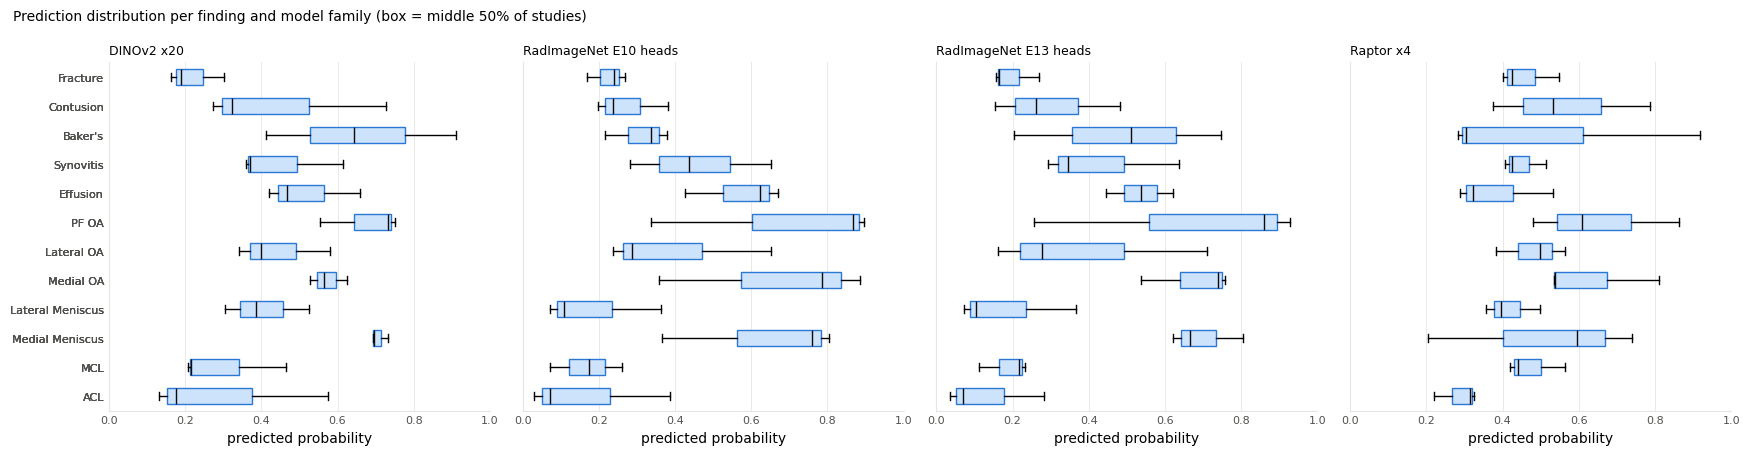

only 3 studies in this run: rank correlations between models need at least 8 studies. (The public test folder holds a 3-study sample; the hidden test set and validate mode have enough.)


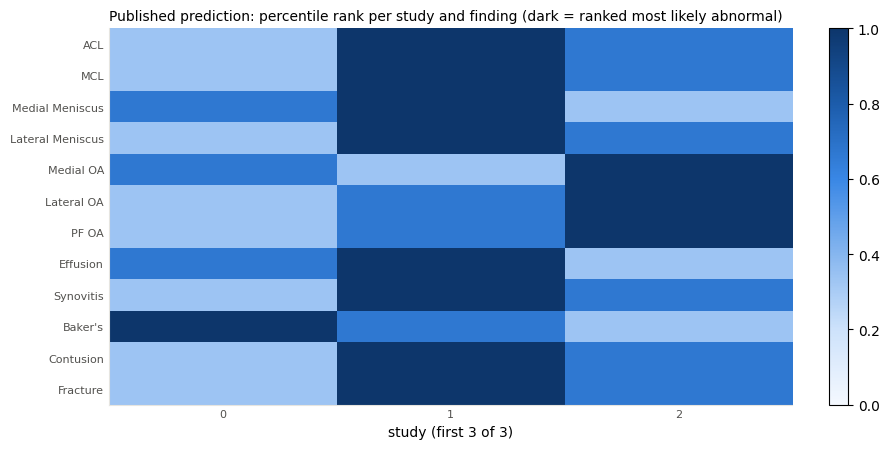

In [38]:
# ======================= Part E.2 - what each model family predicted, and how the blend evolved =======================
AX_components = {}      # display name -> DataFrame [study x 12 findings], rows in test order


def AX_load_components():
    """Collect every prediction the run saved. Nothing is recomputed: no model runs here."""
    diag = AX_OUT / "diagnostics"
    ids = AX_pd.read_csv(AX_final_file(), dtype={AX_UID: str})[AX_UID].tolist()
    out = {}

    def from_npz(path, reduce=None, key="values"):
        if not AX_Path(path).is_file():
            return None
        z = AX_np.load(path, allow_pickle=False)
        v = AX_np.asarray(z[key], dtype=float)
        v = reduce(v) if reduce else v
        return AX_pd.DataFrame(v, index=z["study_uids"].astype(str), columns=AX_LAB).reindex(ids)

    def from_csv(path):
        if not AX_Path(path).is_file():
            return None
        return AX_pd.read_csv(path, dtype={AX_UID: str}).set_index(AX_UID).reindex(ids)[AX_LAB]

    dino = [AX_np.load(f, allow_pickle=False) for f in sorted(diag.glob("dino_*.npz"))]
    if dino:
        out["DINOv2 x20: mean probability"] = AX_pd.DataFrame(
            AX_np.mean([d["values"] for d in dino], axis=0), index=dino[0]["study_uids"].astype(str), columns=AX_LAB).reindex(ids)
    out["BLEND after stage 1 (DINOv2)"] = from_csv(AX_STAGE_DIR / "1_dino.csv")
    a5 = from_npz(diag / "a5_rank_mean.npz")
    if a5 is not None and (diag / "a5_applicability.json").is_file():
        absent = set(json.loads((diag / "a5_applicability.json").read_text())["unavailable_uids"])
        a5.loc[[u for u in a5.index if u in absent]] = AX_np.nan       # 0.5 placeholders are not predictions
    out["A5 x5: mean fold rank"] = a5
    out["BLEND after stage 2 (+A5)"] = from_csv(AX_STAGE_DIR / "2_a5.csv")
    out["RadImageNet E10 heads: mean probability"] = from_npz(diag / "rad_e10_raw.npz", lambda v: v.mean(0))
    out["RadImageNet E13 heads: mean probability"] = from_npz(diag / "rad_e13_raw.npz", lambda v: v.mean(0))
    out["RadImageNet E13 heads on E11 layout"] = from_npz(diag / "rad_legacy_second_raw.npz", lambda v: v.mean(0))
    out["BLEND after stage 3 (+RadImageNet)"] = from_csv(AX_STAGE_DIR / "3_radimagenet.csv")
    if (AX_OUT / "raptor_raw.npz").is_file():
        z = AX_np.load(AX_OUT / "raptor_raw.npz", allow_pickle=False)
        w = AX_np.array([0.60, 0.10, 0.10, 0.20])                      # view weights of the Raptor stage
        out["Raptor x4: weighted mean probability"] = AX_pd.DataFrame(
            AX_np.tensordot(w / w.sum(), AX_np.asarray(z["raw_probabilities"], float), axes=(0, 0)),
            index=z["study_uids"].astype(str), columns=AX_LAB).reindex(ids)
    out["CoAtNet family x4: rank"] = from_csv(AX_OUT / "_coat_family_rank.csv")
    out["Raptor + CoAtNet (60/40)"] = from_csv(AX_OUT / "_raptor.csv")
    out["FINAL"] = from_csv(AX_final_file())
    AX_components.clear()
    AX_components.update({k: v for k, v in out.items() if v is not None})
    print(f"{len(AX_components)} saved prediction sets for {len(ids):,} studies:")
    for k, v in AX_components.items():
        print(f"  {k:<44s} range {AX_np.nanmin(v.to_numpy()):.3f} - {AX_np.nanmax(v.to_numpy()):.3f}"
              + (f"   ({int(v.isna().any(axis=1).sum())} studies without a prediction)" if v.isna().any().any() else ""))


def AX_spearman_by_finding(a, b):
    """Rank correlation between two prediction sets, separately for each finding."""
    ok = (a.notna().all(axis=1) & b.notna().all(axis=1)).to_numpy()
    if ok.sum() < 8:
        return AX_np.full(len(AX_LAB), AX_np.nan)
    ra, rb = AX_rankpct(a.to_numpy()[ok]), AX_rankpct(b.to_numpy()[ok])
    ra -= ra.mean(0); rb -= rb.mean(0)
    with AX_np.errstate(invalid="ignore", divide="ignore"):
        return (ra * rb).sum(0) / AX_np.sqrt((ra ** 2).sum(0) * (rb ** 2).sum(0))


def AX_prediction_distributions():
    """Raw probabilities per model family. (The published values are ranks, so THEIR distribution is flat by construction.)"""
    fams = [k for k in AX_components if k.endswith("probability")]
    if not fams:
        print("no probability outputs saved"); return
    fig, axes = AX_plt.subplots(1, len(fams), figsize=(4.4 * len(fams), 4.6), squeeze=False, sharey=True)
    for ax, k in zip(axes[0], fams):
        v = AX_components[k]
        bp = ax.boxplot([v[l].dropna() for l in AX_LAB], vert=False, tick_labels=AX_LAB, widths=0.55, patch_artist=True,
                        medianprops=dict(color=AX_C["ink"]), flierprops=dict(marker=".", ms=3, mec=AX_C["grey"]))
        for b in bp["boxes"]:
            b.set(facecolor="#cde2fb", edgecolor=AX_C["blue"])
        ax.set_xlim(0, 1); ax.set_title(k.split(":")[0], fontsize=9, loc="left"); ax.set_xlabel("predicted probability")
        AX_style(ax)
    fig.suptitle("Prediction distribution per finding and model family (box = middle 50% of studies)", fontsize=10, x=0.01, ha="left")
    AX_plt.tight_layout(); AX_plt.show()


def AX_ensemble_comparison():
    names = list(AX_components)
    n = len(next(iter(AX_components.values())))
    if n < 8:
        print(f"only {n} studies in this run: rank correlations between models need at least 8 studies. "
              "(The public test folder holds a 3-study sample; the hidden test set and validate mode have enough.)")
        return
    C = AX_np.full((len(names), len(names)), AX_np.nan)
    for i, a in enumerate(names):
        for j, b in enumerate(names):
            if j >= i:
                C[i, j] = C[j, i] = AX_np.nanmean(AX_spearman_by_finding(AX_components[a], AX_components[b]))
    fig, ax = AX_plt.subplots(1, 2, figsize=(19, 6.2), gridspec_kw={"width_ratios": [1.05, 1]})
    im = ax[0].imshow(C, cmap=AX_SEQ, vmin=min(0.3, float(AX_np.nanmin(C))), vmax=1)
    ax[0].set_xticks(range(len(names)), names, rotation=90, fontsize=7); ax[0].set_yticks(range(len(names)), names, fontsize=7)
    for i in range(len(names)):
        for j in range(len(names)):
            if AX_np.isfinite(C[i, j]):
                ax[0].text(j, i, f"{C[i, j]:.2f}", ha="center", va="center", fontsize=6, color="white" if C[i, j] > 0.75 else AX_C["ink"])
    ax[0].set_title("Agreement between prediction sets (Spearman rank correlation, averaged over the 12 findings)", fontsize=10, loc="left")
    AX_style(ax[0], None); fig.colorbar(im, ax=ax[0], fraction=.046)
    stages = [k for k in names if k.startswith("BLEND")] + ["FINAL"]
    moves = AX_np.stack([1 - AX_spearman_by_finding(AX_components[a], AX_components[b]) for a, b in zip(stages[:-1], stages[1:])])
    im = ax[1].imshow(moves, cmap=AX_SEQ, vmin=0, vmax=max(0.2, float(AX_np.nanmax(moves))), aspect="auto")
    ax[1].set_xticks(range(len(AX_LAB)), AX_LAB, rotation=90, fontsize=8)
    ax[1].set_yticks(range(len(moves)), [f"{a.replace('BLEND after ', '')}\n-> {b.replace('BLEND after ', '')}" for a, b in zip(stages[:-1], stages[1:])], fontsize=7)
    for i in range(moves.shape[0]):
        for j in range(moves.shape[1]):
            if AX_np.isfinite(moves[i, j]):
                ax[1].text(j, i, f"{moves[i, j]:.2f}", ha="center", va="center", fontsize=7,
                           color="white" if moves[i, j] > 0.6 * AX_np.nanmax(moves) else AX_C["ink"])
    ax[1].set_title("How much each blending step re-ordered the studies (1 - rank correlation; 0 = no change)", fontsize=10, loc="left")
    AX_style(ax[1], None); fig.colorbar(im, ax=ax[1], fraction=.046)
    AX_plt.tight_layout(); AX_plt.show()


def AX_final_heatmap(max_studies=60):
    P = AX_components["FINAL"]
    fig, ax = AX_plt.subplots(figsize=(min(16, max(9, 4 + 0.2 * min(len(P), max_studies))), 4.6))
    im = ax.imshow(P.iloc[:max_studies].T.to_numpy(), aspect="auto", cmap=AX_SEQ, vmin=0, vmax=1)
    ax.set_yticks(range(len(AX_LAB)), AX_LAB, fontsize=8); ax.set_xlabel(f"study (first {min(len(P), max_studies)} of {len(P):,})")
    ax.xaxis.get_major_locator().set_params(integer=True)
    ax.set_title("Published prediction: percentile rank per study and finding (dark = ranked most likely abnormal)", fontsize=10, loc="left")
    AX_style(ax, None); fig.colorbar(im, ax=ax, fraction=.03)
    AX_plt.tight_layout(); AX_plt.show()


with AX_cell("E.2 load saved predictions"):
    AX_load_components()
with AX_cell("E.2 prediction distributions"):
    AX_prediction_distributions()
with AX_cell("E.2 ensemble comparison"):
    AX_ensemble_comparison()
with AX_cell("E.2 final heatmap"):
    AX_final_heatmap()

## E.3 Replaying the blend with and without A5

**What.** All blending after stage 1 is arithmetic on saved arrays. This cell repeats that arithmetic twice: once as the pipeline did (with A5) and once the way the original notebook behaved (A5 absent, stage 2 passes stage 1 through).

**Why trust it.** The replay first has to reproduce this run's own stage files and published predictions to within 1e-9. Only then is the "without A5" result reported. If the self-test fails, the comparison is withheld rather than shown with a caveat.

**What it tells you.** How *different* the two sets of predictions are. Whether the difference is an *improvement* needs labels: Part F in validate mode, or the leaderboard.

In [39]:
# ======================= Part E.3 - A/B replay: the same run with and without the A5 stage =======================
AX_replay = None      # {"verified": bool, "with_a5": DataFrame, "without_a5": DataFrame}


def AX_replay_blend(use_a5):
    """Recompute every blending step after stage 1 from the predictions the run saved.

    use_a5=True  must reproduce the published file exactly (that is the self-test).
    use_a5=False is what the ORIGINAL notebook computed: A5 found no input, so stage 2 passed the
                 DINOv2 blend through unchanged.
    Only arithmetic on saved arrays: no model, no image, no label is touched.
    """
    import base64, zlib
    diag = AX_OUT / "diagnostics"
    rk = AX_rankpct
    g = globals()
    s1 = AX_pd.read_csv(AX_STAGE_DIR / "1_dino.csv", dtype={AX_UID: str})
    ids = s1[AX_UID].tolist()
    S1 = s1[AX_LAB].to_numpy(AX_np.float64)

    # ---- stage 2: A5 (mirror of _a5_blend_available) ----
    S2 = S1.copy()
    if use_a5:
        z = AX_np.load(diag / "a5_rank_mean.npz", allow_pickle=False)
        a5 = AX_pd.DataFrame(z["values"], index=z["study_uids"].astype(str)).reindex(ids).to_numpy(AX_np.float32)  # pipeline keeps float32
        absent = set(json.loads((diag / "a5_applicability.json").read_text())["unavailable_uids"])
        mask = AX_np.array([u not in absent for u in ids])
        w = float(g.get("A5_W", 0.52))
        if mask.any() and w > 0:
            S2 = rk(S1)
            S2[mask] = (1 - w) * S2[mask] + w * rk(a5[mask].astype(AX_np.float64))

    # ---- stage 3: RadImageNet heads + calibrator (mirror of _rad_main) ----
    def head_mean(tag):
        z = AX_np.load(diag / f"{tag}.npz", allow_pickle=False)
        if z["study_uids"].astype(str).tolist() != ids:
            raise RuntimeError(f"{tag}: study order differs from the stage file")
        return z["values"].mean(0)

    alpha, e13_w, second_alpha = float(g.get("_RAD_ALPHA", 0.55)), float(g.get("_RAD_E13_MEMBER_WEIGHT", 0.50)), float(g.get("_RAD_V48_SECOND_ALPHA", 0.20))
    exclude = tuple(g.get("_RAD_EXCLUDE", ("Baker's",)))
    ref = rk(head_mean("rad_e10_raw"))
    ref = rk((1 - e13_w) * ref + e13_w * rk(head_mean("rad_e13_raw")))
    base = rk(S2)
    cand = S2.copy()
    for j, label in enumerate(AX_LAB):
        if label not in exclude:
            cand[:, j] = (1 - alpha) * base[:, j] + alpha * ref[:, j]
    second = rk(head_mean("rad_legacy_second_raw"))
    values = rk((1 - second_alpha) * rk(cand) + second_alpha * second)
    cal = json.loads(zlib.decompress(base64.b64decode(g["_RAD_CAL_PAYLOAD"])).decode())
    tser = AX_pd.read_csv(AX_Path(os.environ.get("RSNA_COMP_ROOT", str(AX_COMP))) / "test_series.csv",
                          dtype={AX_UID: str, "SeriesInstanceUID": str})
    protocol = AX_pd.DataFrame(index=AX_pd.Index(ids, name=AX_UID))
    protocol["n_series"] = tser.groupby(AX_UID).size().reindex(ids).fillna(0)
    for pl in ("Sagittal", "Coronal", "Axial"):
        part = tser[tser.Anatomical_Plane.astype(str) == pl]
        protocol[f"n_{pl[:3]}"] = part.groupby(AX_UID).size().reindex(ids).fillna(0)
    for flag in ("Fat_Suppression", "Fluid_Sensitive"):
        marked = tser[AX_pd.to_numeric(tser[flag], errors="coerce").fillna(0) > 0]
        protocol[flag[:3]] = marked.groupby(AX_UID).size().reindex(ids).fillna(0)
        for pl in ("Sagittal", "Coronal", "Axial"):
            part = marked[marked.Anatomical_Plane.astype(str) == pl]
            protocol[f"{flag[:3]}_{pl[:3]}"] = part.groupby(AX_UID).size().reindex(ids).fillna(0)
    if list(protocol.columns) != list(cal["protocol_columns"]):
        raise RuntimeError("calibrator protocol columns differ")
    mean = (base + ref + second) / 3.0
    blocks = [base, ref, second, ref - base, second - base, mean]
    blocks += [mean[:, [AX_LAB.index(t) for t in grp]].mean(axis=1, keepdims=True) for grp in cal["groups"]]
    blocks.append(protocol.to_numpy(AX_np.float64))
    x = AX_np.concatenate(blocks, axis=1)
    adjusted = rk(((x - AX_np.asarray(cal["mean"])) / AX_np.asarray(cal["scale"])) @ AX_np.asarray(cal["coef"]).T + AX_np.asarray(cal["intercept"]))
    for j, label in enumerate(AX_LAB):
        if label in set(cal["gate"]):
            values[:, j] = 0.6 * values[:, j] + 0.4 * adjusted[:, j]
    S3 = rk(values)

    # ---- stages 4-5: Raptor + CoAtNet do not depend on A5; reuse their saved blend ----
    H = AX_pd.read_csv(AX_OUT / "_raptor.csv", dtype={AX_UID: str}).set_index(AX_UID).reindex(ids)[AX_LAB].to_numpy(AX_np.float64)
    weight = dict(g.get("_coatnet_weight") or {**{l: 0.60 for l in AX_LAB}, "ACL": 0.75, "Medial Meniscus": 0.80,
                                               "Lateral Meniscus": 1.00, "Lateral OA": 0.75, "Fracture": 0.75})
    wv = AX_np.array([float(weight[l]) for l in AX_LAB])
    final = rk((1 - wv) * rk(S3) + wv * H)
    frame = lambda v: AX_pd.DataFrame(v, index=ids, columns=AX_LAB)
    return {"stage2": frame(S2), "stage3": frame(S3), "final": frame(final)}


def AX_run_replay():
    global AX_replay
    AX_replay = None
    with_a5 = AX_replay_blend(True)
    read = lambda p: AX_pd.read_csv(p, dtype={AX_UID: str}).set_index(AX_UID)[AX_LAB]
    checks = {"after stage 2": (with_a5["stage2"], read(AX_STAGE_DIR / "2_a5.csv")),
              "after stage 3": (with_a5["stage3"], read(AX_STAGE_DIR / "3_radimagenet.csv")),
              "published file": (with_a5["final"], read(AX_final_file()))}
    worst = {k: float(AX_np.abs(a.to_numpy() - b.reindex(a.index).to_numpy()).max()) for k, (a, b) in checks.items()}
    verified = all(v < 1e-9 for v in worst.values())
    print("Replay self-test (recomputed blend vs what the pipeline wrote): " +
          ", ".join(f"{k}: max |difference| = {v:.1e}" for k, v in worst.items()))
    if not verified:
        print("The replay does NOT reproduce this run, so no with/without-A5 comparison is reported. "
              "(Expected if a stage fell back to a path the replay does not model - see the run health table.)")
        return
    without = AX_replay_blend(False)
    AX_replay = {"verified": True, "with_a5": with_a5["final"], "without_a5": without["final"]}
    print("Replay verified: the recomputation matches the published predictions exactly.")
    n = len(with_a5["final"])
    if n < 8:
        print(f"only {n} studies in this run - too few to describe how much A5 changes the ranking."); return
    rho = AX_spearman_by_finding(with_a5["final"], without["final"])
    shift = (with_a5["final"] - without["final"]).abs().mean().to_numpy()
    AX_show(AX_pd.DataFrame({"rank correlation, with vs without A5": rho, "mean |change| in percentile rank": shift},
                            index=AX_pd.Index(AX_LAB, name="finding")).round(3),
            "How much does restoring the A5 stage change the published predictions?")
    order = AX_np.argsort(shift)
    fig, ax = AX_plt.subplots(figsize=(8, 4.2))
    ax.barh([AX_LAB[i] for i in order], shift[order], color=AX_C["blue"], height=0.6)
    ax.set_xlabel("mean absolute change in a study's percentile rank (0 = identical predictions)")
    ax.set_title("Effect of the A5 fix on the final predictions, per finding", fontsize=10, loc="left")
    AX_style(ax); AX_plt.tight_layout(); AX_plt.show()
    print("This shows that the fix CHANGES the predictions, not that it improves them. "
          "Whether it improves them is a question only labels can answer: see Part F and the leaderboard.")


with AX_cell("E.3 A5 replay"):
    AX_run_replay()

Replay self-test (recomputed blend vs what the pipeline wrote): after stage 2: max |difference| = 0.0e+00, after stage 3: max |difference| = 0.0e+00, published file: max |difference| = 0.0e+00
Replay verified: the recomputation matches the published predictions exactly.
only 3 studies in this run - too few to describe how much A5 changes the ranking.


# Part F — Validation against official labels

Active only in validate mode. In submit mode the cell prints why it is skipped and computes nothing.

**What is scored.** Every saved prediction set (single model families, the blend after each stage, the final blend, and the final blend without A5 from the replay) against the official labels of the same studies, by macro ROC-AUC with a bootstrap interval. The baseline-versus-fixed difference uses the *same* resamples for both versions (a paired comparison), which removes most of the study-to-study noise from the difference.

**How to use it.**
- Look at the *difference* between versions, not at the level.
- If the interval of the difference includes zero, the labelled set cannot separate the versions. That is an honest and likely result with 58 studies.
- The LLM-pseudo-label row is a reference for label noise, not a competitor.

In [40]:
# ======================= Part F - validation against official labels (validate mode only) =======================
AX_val_scores = None


def AX_boot_macro(y, score_sets, n_boot=2000, seed=0):
    """Macro AUC (mean over findings) for several prediction sets on the SAME bootstrap resamples of studies.
    Using the same resamples for every set is what makes paired differences meaningful."""
    rng = AX_np.random.default_rng(seed)
    idx = rng.integers(0, len(y), (n_boot, len(y)))
    return {k: AX_np.array([AX_np.nanmean(AX_auc_matrix(y[i], s[i])) for i in idx]) for k, s in score_sets.items()}


def AX_validation_report(n_boot=2000):
    global AX_val_scores
    if AX_RUN_MODE != "validate" or AX_VAL is None:
        print("Validation report skipped: this is a submit-mode run, and the test studies have no labels.\n"
              "No accuracy number is shown or implied. To measure accuracy, set RUN_MODE = 'validate' in Part A and re-run.")
        return
    gold = AX_VAL["gold"]
    ids = [u for u in AX_components["FINAL"].index if u in gold.index]
    y = gold.loc[ids, AX_LAB].to_numpy(float)
    usable = [l for l, k in zip(AX_LAB, y.sum(0)) if 0 < k < len(y)]
    print(f"{len(ids)} officially labelled studies | findings with both classes present: {len(usable)} of 12 "
          f"| positives per finding: {dict(zip(AX_LAB, y.sum(0).astype(int)))}")
    sets = {}
    for name, frame in AX_components.items():
        v = frame.loc[ids].to_numpy(float)
        if AX_np.isnan(v).any():
            print(f"  {name}: {int(AX_np.isnan(v).any(axis=1).sum())} studies without a prediction -> scored with the neutral value 0.5")
            v = AX_np.where(AX_np.isnan(v), 0.5, v)
        sets[name] = v
    if AX_replay and AX_replay.get("verified"):
        sets["FINAL without A5 (= original notebook)"] = AX_replay["without_a5"].loc[ids].to_numpy(float)
    if AX_llm is not None and all(u in AX_llm.index for u in ids):
        sets["reference: LLM pseudo-labels (not a model)"] = AX_llm.loc[ids, AX_LAB].to_numpy(float)
    per = AX_pd.DataFrame({k: AX_auc_matrix(y, v) for k, v in sets.items()}, index=AX_LAB).T
    boot = AX_boot_macro(y, sets, n_boot)
    table = AX_pd.DataFrame({"macro AUC": per.mean(axis=1, skipna=True),
                             "95% low": {k: AX_np.nanpercentile(b, 2.5) for k, b in boot.items()},
                             "95% high": {k: AX_np.nanpercentile(b, 97.5) for k, b in boot.items()}}).loc[list(sets)]
    AX_val_scores = {"table": table, "per_finding": per}
    AX_show(table.round(4), f"Macro ROC-AUC on {len(ids)} officially labelled training studies (95% bootstrap interval)")

    fig, ax = AX_plt.subplots(1, 2, figsize=(19, 0.42 * len(sets) + 2.6), gridspec_kw={"width_ratios": [1, 1.25]})
    names = list(sets)[::-1]; yy = AX_np.arange(len(names))
    is_final = [n.startswith("FINAL") for n in names]
    ax[0].hlines(yy, table.loc[names, "95% low"], table.loc[names, "95% high"], color=AX_C["blue"], lw=2)
    ax[0].plot(table.loc[names, "macro AUC"], yy, "o", color=AX_C["blue"], ms=6, mec="white", mew=1.2)
    for i, f in enumerate(is_final):
        if f:
            ax[0].text(table.loc[names[i], "95% high"] + 0.005, i, f"{table.loc[names[i], 'macro AUC']:.3f}", va="center", fontsize=8, color=AX_C["ink"])
    ax[0].set_yticks(yy, names, fontsize=7); ax[0].axvline(0.5, color=AX_C["muted"], lw=1)
    ax[0].set_xlabel("macro ROC-AUC (dot) with 95% bootstrap interval (line)")
    ax[0].set_title("Every saved prediction set scored on the same labelled studies", fontsize=10, loc="left"); AX_style(ax[0])
    M = per.loc[list(sets)].to_numpy(float)
    im = ax[1].imshow(M, cmap=AX_SEQ, vmin=0.5, vmax=1, aspect="auto")
    ax[1].set_xticks(range(len(AX_LAB)), AX_LAB, rotation=90, fontsize=8); ax[1].set_yticks(range(len(sets)), list(sets), fontsize=7)
    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            if AX_np.isfinite(M[i, j]):
                ax[1].text(j, i, f"{M[i, j]:.2f}", ha="center", va="center", fontsize=6, color="white" if M[i, j] > 0.8 else AX_C["ink"])
    ax[1].set_title("ROC-AUC per finding (values below 0.5 are drawn at the lightest shade)", fontsize=10, loc="left")
    AX_style(ax[1], None); fig.colorbar(im, ax=ax[1], fraction=.03)
    AX_plt.tight_layout(); AX_plt.show()

    key = "FINAL without A5 (= original notebook)"
    if key in sets:
        diff = boot["FINAL"] - boot[key]
        lo, hi = AX_np.nanpercentile(diff, [2.5, 97.5])
        d0 = float(table.loc["FINAL", "macro AUC"] - table.loc[key, "macro AUC"])
        AX_val_scores["a5_fix"] = {"baseline": float(table.loc[key, "macro AUC"]), "fixed": float(table.loc["FINAL", "macro AUC"]),
                                   "difference": d0, "ci": (float(lo), float(hi))}
        print(f"\nBASELINE (original notebook, A5 lost): macro AUC {table.loc[key, 'macro AUC']:.4f}")
        print(f"FIXED    (this notebook, A5 restored): macro AUC {table.loc['FINAL', 'macro AUC']:.4f}")
        print(f"difference fixed - baseline: {d0:+.4f}  (95% paired bootstrap interval {lo:+.4f} to {hi:+.4f})")
        print("-> the interval " + ("excludes zero: the difference is larger than the resampling noise on these studies."
                                    if lo > 0 or hi < 0 else
                                    "includes zero: on this few studies the two versions cannot be told apart."))
    else:
        print("\nNo baseline-vs-fixed comparison: the replay in Part E.3 was not verified for this run.")
    print("\nREAD THIS BEFORE QUOTING ANY NUMBER ABOVE")
    print(" 1. These studies are part of the training data. Fold models saw four fifths of them during training, '_full'")
    print("    checkpoints by their name all of them, and the manifests record that checkpoints were selected by their AUC")
    print("    on these same studies. The absolute AUCs are therefore optimistic, not an estimate of test accuracy.")
    print(f" 2. {len(ids)} studies and a handful of positives per finding give wide intervals; differences of a few")
    print("    hundredths are noise.")
    print(" 3. The only leakage-free comparison is the competition leaderboard: submit this version (submit mode) and")
    print("    compare with the score of the original notebook.")


with AX_cell("F validation report"):
    AX_validation_report()


def AX_write_summary():
    summary = {
        "run_mode": AX_RUN_MODE,
        "n_studies_predicted": int(len(AX_components["FINAL"])) if "FINAL" in AX_components else None,
        "llm_label_studies": None if AX_llm is None else int(len(AX_llm)),
        "reports_processed": None if AX_reports is None else int(AX_reports["has_report"].sum()),
        "official_label_studies": None if AX_gold is None else int(len(AX_gold)),
        "llm_labels_vs_official_macro_auc": None if AX_gold_macro_ci is None else [round(float(v), 4) for v in AX_gold_macro_ci],
        "a5_replay_verified": bool(AX_replay and AX_replay.get("verified")),
        "validation_macro_auc_final": None if not AX_val_scores else round(float(AX_val_scores["table"].loc["FINAL", "macro AUC"]), 4),
        "validation_a5_fix": None if not AX_val_scores else AX_val_scores.get("a5_fix"),
        "note": "validation numbers come from training studies and are optimistic; see Part F",
    }
    (AX_OUT / "analysis_summary.json").write_text(json.dumps(summary, indent=2))
    print(json.dumps(summary, indent=2))


with AX_cell("F summary"):
    AX_write_summary()

Validation report skipped: this is a submit-mode run, and the test studies have no labels.
No accuracy number is shown or implied. To measure accuracy, set RUN_MODE = 'validate' in Part A and re-run.
{
  "run_mode": "submit",
  "n_studies_predicted": 3,
  "llm_label_studies": 4406,
  "reports_processed": 4407,
  "official_label_studies": 58,
  "llm_labels_vs_official_macro_auc": [
    0.87,
    0.8312,
    0.9002
  ],
  "a5_replay_verified": true,
  "validation_macro_auc_final": null,
  "validation_a5_fix": null,
  "note": "validation numbers come from training studies and are optimistic; see Part F"
}


# Appendix

## Cell-level change list

| Area | Change | Affects predictions? |
|---|---|---|
| Part A.1 | Competition path resolved for the current Kaggle layout; run mode; `AX_cell` guard; plotting style; fast AUC helper | No |
| Part A.2 | New: table overview, missing values, series statistics, slot coverage, slices per series | No |
| Part B | Functions kept; missing reports no longer become the text "nan"; invented before/after examples; language statistics restricted to existing reports | No |
| Part C | Loader kept; official labels searched only in training files; new audit table with bootstrap intervals, sensitivity, specificity, kappa and class-frequency comparison | No |
| D.5 | New: validate-mode input redirection | Only which studies are predicted |
| Stage 1 | New review cell (inputs, slice selection, member summary); stage snapshot | No |
| Stage 2 | **Plotting cell fixed** (it destroyed `studies`); **new input-contract gate**; **new coverage gate**; stage snapshot | **Yes: A5 contributes again** |
| Stages 3–5 | Stage snapshots only | No |
| After publication | In validate mode `submission.csv` is renamed to `validation_predictions.csv` | No |
| Part E | Replaces the two original plot cells: run health, submission validation, distributions, agreement, replay | No |
| Part F | New: validation report | No |

Every original model cell is byte-for-byte unchanged. Saved outputs were cleared, because they came from the run with the A5 bug and would not describe this version.

## Known limitations

- **Nothing in this notebook has been scored after the fix.** Run validate mode and submit to obtain numbers.
- Validation studies are training studies (see D.5): levels are optimistic.
- Blend weights and the calibrator are inherited as they are. Per-finding weights chosen on 58 studies carry a risk of overfitting that this notebook can show (Part F) but not remove.
- Each stage uses its own slice ordering and normalisation because its checkpoints were trained that way. Unifying them would require retraining.
- The four CoAtNet family readers run from external scripts whose code is not shown here.
- Checkpoints are loaded with `torch.load(..., weights_only=False)`, which can execute code stored in the file. They are pinned by hash or fingerprint; only attach datasets you trust.

## Ideas that would need training (not done here)

- Out-of-fold predictions for all training studies would allow blend weights to be fitted on thousands of studies instead of 58, and would make clean validation possible.
- Cleaning the pseudo-labels of the findings that Part C shows to be weakest, then retraining.
- Fitting the stage-3 calibrator with cross-validation and reporting its out-of-fold gain.

## Glossary

- **Study / series / slice**: one MRI visit / one image stack within it / one 2-D image of the stack.
- **Plane**: sagittal (side view), coronal (front view), axial (top-down).
- **Fat suppression**: a scan setting that darkens fat so fluid and oedema stand out.
- **Slot**: one fixed input position of a model, for example "sagittal fat-suppressed".
- **Mask**: a 0/1 flag telling the model a slot or slice is absent.
- **Pseudo-label**: a training label produced by a model (here a language model reading the report) instead of a human annotator.
- **Fold**: one of five parts of the training data; a fold model is trained on the other four.
- **Checkpoint**: a file holding trained network weights.
- **Logit / probability**: a network's raw score / the score squeezed into 0–1 by the sigmoid function.
- **Percentile rank**: the position of a study among all studies, between 0 and 1.
- **ROC-AUC**: the probability that a randomly chosen positive study is scored above a randomly chosen negative one.
- **Macro average**: the plain mean over the 12 findings.
- **Bootstrap**: re-computing a statistic on many random resamples of the studies to see how much it varies.
- **TTA (test-time augmentation)**: predicting several variants of an input and combining the answers.
- **MIL (multiple-instance learning)**: learning from a label for a whole bag (the study) when the evidence sits in a few of its items (slices).